In [1]:
# ============================================
# CELL 1 — IMPORT LIBRARIES
# ============================================

import pandas as pd
import numpy as np
import os
import glob
import zipfile
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================
# CELL 2 — MOUNT GOOGLE DRIVE (DEFENSIVE & SAFE)
# ============================================

try:
    import os
    from google.colab import drive

    # Check if drive is already mounted safely
    if os.path.exists("/content/drive/MyDrive"):
        print("Google Drive is already mounted.")
    else:
        drive.mount("/content/drive", force_remount=True)
        print("Google Drive mounted successfully inside Colab.")
except ModuleNotFoundError:
    print("Running outside Google Colab environment. Skipping Colab-specific Drive mount.")

Mounted at /content/drive
Google Drive mounted successfully inside Colab.


In [3]:
# ============================================
# CELL 3 — DEFINE CAMELS ZIP PATH
# ============================================

zip_path = "/content/drive/MyDrive/all.zip"

if os.path.exists(zip_path):
    print("CAMELS archive found:")
    print(zip_path)
else:
    print("ERROR: CAMELS archive was not found.")
    print("Please check that all.zip is inside MyDrive.")

CAMELS archive found:
/content/drive/MyDrive/all.zip


In [4]:
# ============================================
# CELL 4 — DEFINE EXTRACTION DIRECTORY
# ============================================

extract_path = "/content/CAMELS"

os.makedirs(extract_path, exist_ok=True)

print("CAMELS extraction directory:")
print(extract_path)

CAMELS extraction directory:
/content/CAMELS


In [5]:
# ============================================
# CELL 5 — EXTRACT MAIN CAMELS ARCHIVE
# ============================================

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("CAMELS archive extracted successfully.")

CAMELS archive extracted successfully.


In [6]:
# ============================================
# CELL 6 — EXTRACT FORCING DATA
# ============================================

force_zip = os.path.join(extract_path, "force.zip")
force_out = os.path.join(extract_path, "force")

os.makedirs(force_out, exist_ok=True)

with zipfile.ZipFile(force_zip, "r") as zip_ref:
    zip_ref.extractall(force_out)

print("Forcing data extracted successfully.")

Forcing data extracted successfully.


In [7]:
# ============================================
# CELL 7 — EXTRACT STREAMFLOW DATA
# ============================================

stream_zip = os.path.join(extract_path, "stream.zip")
stream_out = os.path.join(extract_path, "stream")

os.makedirs(stream_out, exist_ok=True)

with zipfile.ZipFile(stream_zip, "r") as zip_ref:
    zip_ref.extractall(stream_out)

print("Streamflow data extracted successfully.")

Streamflow data extracted successfully.


In [8]:
# ============================================
# CELL 8 — INSPECT CAMELS DIRECTORY
# ============================================

print("CAMELS directory contents:")
print("=" * 60)

for item in sorted(os.listdir(extract_path)):
    print(item)

print("\nForcing directory exists:", os.path.exists(force_out))
print("Streamflow directory exists:", os.path.exists(stream_out))

CAMELS directory contents:
__MACOSX
force
force.zip
stream
stream.zip

Forcing directory exists: True
Streamflow directory exists: True


In [9]:
# ============================================
# CELL 9 — FIND FORCING AND STREAMFLOW FILES
# ============================================

forcing_files = glob.glob(
    os.path.join(
        force_out,
        "*",
        "*_lump_cida_forcing_leap.txt"
    )
)

stream_files = glob.glob(
    os.path.join(
        stream_out,
        "*",
        "*_streamflow_qc.txt"
    )
)

print("Number of forcing files:", len(forcing_files))
print("Number of streamflow files:", len(stream_files))

print("\nExample forcing file:")
if forcing_files:
    print(forcing_files[0])

print("\nExample streamflow file:")
if stream_files:
    print(stream_files[0])

Number of forcing files: 672
Number of streamflow files: 669

Example forcing file:
/content/CAMELS/force/11/07226500_lump_cida_forcing_leap.txt

Example streamflow file:
/content/CAMELS/stream/11/07184000_streamflow_qc.txt


In [10]:
# ============================================
# CELL 10 — IDENTIFY COMPLETE BASINS
# ============================================

forcing_ids = {
    os.path.basename(file).split("_")[0]
    for file in forcing_files
}

stream_ids = {
    os.path.basename(file).split("_")[0]
    for file in stream_files
}

# Keep only basins with BOTH forcing and streamflow data
available_basins = sorted(
    forcing_ids.intersection(stream_ids)
)

print("Basins with forcing data:", len(forcing_ids))
print("Basins with streamflow data:", len(stream_ids))
print("Basins with BOTH datasets:", len(available_basins))

print("\nFirst 20 available basin IDs:")
print(available_basins[:20])

Basins with forcing data: 672
Basins with streamflow data: 669
Basins with BOTH datasets: 669

First 20 available basin IDs:
['01022500', '01030500', '01031500', '01047000', '01054200', '01055000', '01057000', '01073000', '01078000', '01121000', '01123000', '01134500', '01137500', '01139000', '01139800', '01142500', '01144000', '01162500', '01169000', '01170100']


In [11]:
import pandas as pd
import os

# ============================================
# CELL 11 — LOAD CAMELS FORCING DATA
# ============================================

# Start with the first available CAMELS basin.
# We will later extend this to multiple/all basins.

basin = available_basins[0]

print("Selected basin:", basin)

forcing_file = os.path.join(
    force_out,
    basin[:2],
    f"{basin}_lump_cida_forcing_leap.txt"
)

print("Forcing file:")
print(forcing_file)

forcing = pd.read_csv(
    forcing_file,
    sep=r"\s+",
    skiprows=3
)

print("\nForcing data shape:", forcing.shape)

forcing.head()

Selected basin: 01022500
Forcing file:
/content/CAMELS/force/01/01022500_lump_cida_forcing_leap.txt

Forcing data shape: (12784, 11)


,Year,Mnth,Day,Hr,dayl(s),prcp(mm/day),srad(W/m2),swe(mm),tmax(C),tmin(C),vp(Pa)
0,1980,1,1,12,31185.97,0.0,178.46,0.0,-0.72,-10.59,271.45
1,1980,1,2,12,31302.05,0.0,186.36,0.0,0.74,-9.82,291.32
2,1980,1,3,12,31370.88,0.0,198.93,0.0,-0.65,-12.28,238.75
3,1980,1,4,12,31449.59,0.0,182.99,0.0,-5.35,-15.20,191.65
4,1980,1,5,12,31449.59,0.0,155.25,0.0,-7.15,-14.94,191.74


In [12]:
# ============================================
# CELL 12 — CREATE DATE VARIABLE
# ============================================

forcing["Date"] = pd.to_datetime(
    forcing[["Year", "Mnth", "Day"]].rename(
        columns={
            "Year": "year",
            "Mnth": "month",
            "Day": "day"
        }
    ),
    errors="coerce"
)

print("Date variable created.")

print(
    "Date range:",
    forcing["Date"].min(),
    "to",
    forcing["Date"].max()
)

forcing[["Date"]].head()

Date variable created.
Date range: 1980-01-01 00:00:00 to 2014-12-31 00:00:00


,Date
0,1980-01-01
1,1980-01-02
2,1980-01-03
3,1980-01-04
4,1980-01-05


In [13]:
# ============================================
# CELL 13 — RENAME CAMELS VARIABLES
# ============================================

forcing = forcing.rename(
    columns={
        "prcp(mm/day)": "prcp",
        "swe(mm)": "swe",
        "tmax(C)": "tmax",
        "tmin(C)": "tmin",
        "vp(Pa)": "vp"
    }
)

print("Renamed variables:")

print(
    [
        c for c in [
            "Date",
            "prcp",
            "swe",
            "tmax",
            "tmin",
            "vp"
        ]
        if c in forcing.columns
    ]
)

Renamed variables:
['Date', 'prcp', 'swe', 'tmax', 'tmin', 'vp']


In [14]:
# ============================================
# CELL 14 — INSPECT FORCING DATA
# ============================================

print("All forcing columns:")
print("=" * 60)

for column in forcing.columns:
    print(column)

print("\nFirst five rows:")
display(forcing.head())

All forcing columns:
Year
Mnth
Day
Hr
dayl(s)
prcp
srad(W/m2)
swe
tmax
tmin
vp
Date

First five rows:


,Year,Mnth,Day,Hr,dayl(s),prcp,srad(W/m2),swe,tmax,tmin,vp,Date
0,1980,1,1,12,31185.97,0.0,178.46,0.0,-0.72,-10.59,271.45,1980-01-01
1,1980,1,2,12,31302.05,0.0,186.36,0.0,0.74,-9.82,291.32,1980-01-02
2,1980,1,3,12,31370.88,0.0,198.93,0.0,-0.65,-12.28,238.75,1980-01-03
3,1980,1,4,12,31449.59,0.0,182.99,0.0,-5.35,-15.20,191.65,1980-01-04
4,1980,1,5,12,31449.59,0.0,155.25,0.0,-7.15,-14.94,191.74,1980-01-05


In [15]:
# ============================================
# CELL 15 — LOAD STREAMFLOW DATA
# ============================================

stream_file = os.path.join(
    stream_out,
    basin[:2],
    f"{basin}_streamflow_qc.txt"
)

print("Streamflow file:")
print(stream_file)

flow = pd.read_csv(
    stream_file,
    sep=r"\s+",
    header=None
)

print("\nStreamflow data shape:", flow.shape)

flow.head()

Streamflow file:
/content/CAMELS/stream/01/01022500_streamflow_qc.txt

Streamflow data shape: (12784, 6)


,0,1,2,3,4,5
0,1022500,1980,1,1,395.0,A
1,1022500,1980,1,2,350.0,A
2,1022500,1980,1,3,310.0,A
3,1022500,1980,1,4,275.0,A
4,1022500,1980,1,5,250.0,A


In [16]:
# ============================================
# CELL 16 — NAME STREAMFLOW VARIABLES
# ============================================

flow.columns = [
    "gauge_id",
    "year",
    "month",
    "day",
    "streamflow",
    "flag"
]

print("Streamflow columns:")
print(flow.columns.tolist())

display(flow.head())

Streamflow columns:
['gauge_id', 'year', 'month', 'day', 'streamflow', 'flag']


,gauge_id,year,month,day,streamflow,flag
0,1022500,1980,1,1,395.0,A
1,1022500,1980,1,2,350.0,A
2,1022500,1980,1,3,310.0,A
3,1022500,1980,1,4,275.0,A
4,1022500,1980,1,5,250.0,A


In [17]:
# ============================================
# CELL 17 — CREATE STREAMFLOW DATE
# ============================================

flow["Date"] = pd.to_datetime(
    flow[["year", "month", "day"]],
    errors="coerce"
)

print("Streamflow dates created.")

print(
    "Date range:",
    flow["Date"].min(),
    "to",
    flow["Date"].max()
)

display(flow[["Date", "streamflow"]].head())

Streamflow dates created.
Date range: 1980-01-01 00:00:00 to 2014-12-31 00:00:00


,Date,streamflow
0,1980-01-01,395.0
1,1980-01-02,350.0
2,1980-01-03,310.0
3,1980-01-04,275.0
4,1980-01-05,250.0


In [18]:
# ============================================
# CELL 18 — SELECT STREAMFLOW VARIABLES
# ============================================

flow = flow[
    [
        "Date",
        "streamflow"
    ]
].copy()

print("Streamflow dataset shape:", flow.shape)

display(flow.head())

Streamflow dataset shape: (12784, 2)


,Date,streamflow
0,1980-01-01,395.0
1,1980-01-02,350.0
2,1980-01-03,310.0
3,1980-01-04,275.0
4,1980-01-05,250.0


In [19]:
# ============================================
# CELL 19 — MERGE METEOROLOGY + STREAMFLOW
# ============================================

data = pd.merge(
    forcing,
    flow,
    on="Date",
    how="inner"
)

# Add basin identifier.
# This is essential because our final analysis will
# involve many CAMELS catchments.

data["basin_id"] = basin

print("Merged dataset shape:", data.shape)

display(data.head())

Merged dataset shape: (12784, 14)


,Year,Mnth,Day,Hr,dayl(s),prcp,srad(W/m2),swe,tmax,tmin,vp,Date,streamflow,basin_id
0,1980,1,1,12,31185.97,0.0,178.46,0.0,-0.72,-10.59,271.45,1980-01-01,395.0,01022500
1,1980,1,2,12,31302.05,0.0,186.36,0.0,0.74,-9.82,291.32,1980-01-02,350.0,01022500
2,1980,1,3,12,31370.88,0.0,198.93,0.0,-0.65,-12.28,238.75,1980-01-03,310.0,01022500
3,1980,1,4,12,31449.59,0.0,182.99,0.0,-5.35,-15.20,191.65,1980-01-04,275.0,01022500
4,1980,1,5,12,31449.59,0.0,155.25,0.0,-7.15,-14.94,191.74,1980-01-05,250.0,01022500


In [20]:
# ============================================
# CELL 20 — SORT + INITIAL QUALITY CHECK
# ============================================

# Sort chronologically
data = data.sort_values(
    ["basin_id", "Date"]
).reset_index(drop=True)

print("Dataset shape:", data.shape)

print("\nDate range:")
print(data["Date"].min(), "to", data["Date"].max())

print("\nNumber of duplicate dates:")
print(data["Date"].duplicated().sum())

print("\nMissing values:")
print(
    data[
        ["Date", "prcp", "tmax", "tmin", "vp",
         "swe", "streamflow"]
    ].isna().sum()
)

print("\nFinal columns:")
print(data.columns.tolist())

display(data.head())

Dataset shape: (12784, 14)

Date range:
1980-01-01 00:00:00 to 2014-12-31 00:00:00

Number of duplicate dates:
0

Missing values:
Date          0
prcp          0
tmax          0
tmin          0
vp            0
swe           0
streamflow    0
dtype: int64

Final columns:
['Year', 'Mnth', 'Day', 'Hr', 'dayl(s)', 'prcp', 'srad(W/m2)', 'swe', 'tmax', 'tmin', 'vp', 'Date', 'streamflow', 'basin_id']


,Year,Mnth,Day,Hr,dayl(s),prcp,srad(W/m2),swe,tmax,tmin,vp,Date,streamflow,basin_id
0,1980,1,1,12,31185.97,0.0,178.46,0.0,-0.72,-10.59,271.45,1980-01-01,395.0,01022500
1,1980,1,2,12,31302.05,0.0,186.36,0.0,0.74,-9.82,291.32,1980-01-02,350.0,01022500
2,1980,1,3,12,31370.88,0.0,198.93,0.0,-0.65,-12.28,238.75,1980-01-03,310.0,01022500
3,1980,1,4,12,31449.59,0.0,182.99,0.0,-5.35,-15.20,191.65,1980-01-04,275.0,01022500
4,1980,1,5,12,31449.59,0.0,155.25,0.0,-7.15,-14.94,191.74,1980-01-05,250.0,01022500


In [21]:
# ============================================
# CELL 21 — CONFIRM BASIN + CLEAN DATA
# ============================================

# Make sure the basin identifier exists
if "basin_id" not in data.columns:
    data["basin_id"] = basin

# Make sure the data are ordered correctly
data = data.sort_values(
    ["basin_id", "Date"]
).reset_index(drop=True)

# Replace impossible negative precipitation values with NaN
if "prcp" in data.columns:
    data.loc[data["prcp"] < 0, "prcp"] = np.nan

# Replace impossible negative streamflow values with NaN
if "streamflow" in data.columns:
    data.loc[data["streamflow"] < 0, "streamflow"] = np.nan

print("Basin:", data["basin_id"].iloc[0])
print("Rows:", len(data))
print("Date range:", data["Date"].min(), "to", data["Date"].max())

print("\nMissing values:")
display(data[["Date", "prcp", "streamflow"]].isna().sum())

Basin: 01022500
Rows: 12784
Date range: 1980-01-01 00:00:00 to 2014-12-31 00:00:00

Missing values:


,0
Date,0
prcp,0
streamflow,92


In [22]:
# ============================================
# CELL 22 — PREVIOUS-DAY RAINFALL
# ============================================

data["Rain_lag1"] = (
    data.groupby("basin_id")["prcp"]
    .shift(1)
)

print("Previous-day rainfall created.")

display(
    data[
        [
            "Date",
            "prcp",
            "Rain_lag1"
        ]
    ].head(10)
)

Previous-day rainfall created.


,Date,prcp,Rain_lag1
0,1980-01-01,0.00,NaN
1,1980-01-02,0.00,0.00
2,1980-01-03,0.00,0.00
3,1980-01-04,0.00,0.00
4,1980-01-05,0.00,0.00
5,1980-01-06,0.00,0.00
6,1980-01-07,0.00,0.00
7,1980-01-08,2.05,0.00
8,1980-01-09,0.00,2.05
9,1980-01-10,0.00,0.00


In [23]:
# ============================================
# CELL 23 — 3-DAY ANTECEDENT RAINFALL
# ============================================

data["Rain3_lag"] = (
    data.groupby("basin_id")["prcp"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=3
        ).sum()
    )
)

print("3-day antecedent rainfall created.")

display(
    data[
        [
            "Date",
            "prcp",
            "Rain_lag1",
            "Rain3_lag"
        ]
    ].head(10)
)

3-day antecedent rainfall created.


,Date,prcp,Rain_lag1,Rain3_lag
0,1980-01-01,0.00,NaN,NaN
1,1980-01-02,0.00,0.00,NaN
2,1980-01-03,0.00,0.00,NaN
3,1980-01-04,0.00,0.00,0.00
4,1980-01-05,0.00,0.00,0.00
5,1980-01-06,0.00,0.00,0.00
6,1980-01-07,0.00,0.00,0.00
7,1980-01-08,2.05,0.00,0.00
8,1980-01-09,0.00,2.05,2.05
9,1980-01-10,0.00,0.00,2.05


In [24]:
# ============================================
# CELL 24 — 7-DAY ANTECEDENT RAINFALL
# ============================================

data["Rain7_lag"] = (
    data.groupby("basin_id")["prcp"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=7,
            min_periods=7
        ).sum()
    )
)

print("7-day antecedent rainfall created.")

display(
    data[
        [
            "Date",
            "prcp",
            "Rain_lag1",
            "Rain3_lag",
            "Rain7_lag"
        ]
    ].head(15)
)

7-day antecedent rainfall created.


,Date,prcp,Rain_lag1,Rain3_lag,Rain7_lag
0,1980-01-01,0.00,NaN,NaN,NaN
1,1980-01-02,0.00,0.00,NaN,NaN
2,1980-01-03,0.00,0.00,NaN,NaN
3,1980-01-04,0.00,0.00,0.00,NaN
4,1980-01-05,0.00,0.00,0.00,NaN
5,1980-01-06,0.00,0.00,0.00,NaN
6,1980-01-07,0.00,0.00,0.00,NaN
7,1980-01-08,2.05,0.00,0.00,0.00
8,1980-01-09,0.00,2.05,2.05,2.05
9,1980-01-10,0.00,0.00,2.05,2.05


In [25]:
# ============================================
# CELL 25 — 14-DAY ANTECEDENT RAINFALL
# ============================================

data["Rain14_lag"] = (
    data.groupby("basin_id")["prcp"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=14,
            min_periods=14
        ).sum()
    )
)

print("14-day antecedent rainfall created.")

display(
    data[
        [
            "Date",
            "Rain7_lag",
            "Rain14_lag"
        ]
    ].head(20)
)

14-day antecedent rainfall created.


,Date,Rain7_lag,Rain14_lag
0,1980-01-01,NaN,NaN
1,1980-01-02,NaN,NaN
2,1980-01-03,NaN,NaN
3,1980-01-04,NaN,NaN
4,1980-01-05,NaN,NaN
5,1980-01-06,NaN,NaN
6,1980-01-07,NaN,NaN
7,1980-01-08,0.00,NaN
8,1980-01-09,2.05,NaN
9,1980-01-10,2.05,NaN


In [26]:
# ============================================
# CELL 26 — PREVIOUS-DAY STREAMFLOW
# ============================================

data["streamflow_lag1"] = (
    data.groupby("basin_id")["streamflow"]
    .shift(1)
)

print("Previous-day streamflow created.")

display(
    data[
        [
            "Date",
            "streamflow",
            "streamflow_lag1"
        ]
    ].head(10)
)

Previous-day streamflow created.


,Date,streamflow,streamflow_lag1
0,1980-01-01,395.0,NaN
1,1980-01-02,350.0,395.0
2,1980-01-03,310.0,350.0
3,1980-01-04,275.0,310.0
4,1980-01-05,250.0,275.0
5,1980-01-06,230.0,250.0
6,1980-01-07,230.0,230.0
7,1980-01-08,270.0,230.0
8,1980-01-09,240.0,270.0
9,1980-01-10,220.0,240.0


In [27]:
# ============================================
# CELL 27 — CATCHMENT-SPECIFIC Q95
# ============================================

q95_by_basin = (
    data.groupby("basin_id")["streamflow"]
    .quantile(0.95)
    .rename("Q95")
)

data = data.merge(
    q95_by_basin,
    on="basin_id",
    how="left"
)

print("Catchment-specific Q95 calculated.")

display(
    data[
        [
            "basin_id",
            "Date",
            "streamflow",
            "Q95"
        ]
    ].head(10)
)

print("\nQ95 value for this basin:")
print(data["Q95"].iloc[0])

Catchment-specific Q95 calculated.


,basin_id,Date,streamflow,Q95
0,01022500,1980-01-01,395.0,1640.0
1,01022500,1980-01-02,350.0,1640.0
2,01022500,1980-01-03,310.0,1640.0
3,01022500,1980-01-04,275.0,1640.0
4,01022500,1980-01-05,250.0,1640.0
5,01022500,1980-01-06,230.0,1640.0
6,01022500,1980-01-07,230.0,1640.0
7,01022500,1980-01-08,270.0,1640.0
8,01022500,1980-01-09,240.0,1640.0
9,01022500,1980-01-10,220.0,1640.0



Q95 value for this basin:
1640.0


In [28]:
# ============================================
# CELL 28 — DEFINE HIGH-FLOW EVENT
# ============================================

data["HighFlow"] = (
    data["streamflow"] >= data["Q95"]
).astype(int)

print("High-flow outcome created.")

print("\nHigh-flow counts:")
print(data["HighFlow"].value_counts())

print("\nHigh-flow percentage:")
print(data["HighFlow"].mean() * 100, "%")

High-flow outcome created.

High-flow counts:
HighFlow
0    12148
1      636
Name: count, dtype: int64

High-flow percentage:
4.974968710888611 %


In [29]:
# ============================================
# CELL 29 — FUTURE HIGH-FLOW OUTCOME
# ============================================

data["FutureHighFlow"] = (
    data.groupby("basin_id")["HighFlow"]
    .shift(-1)
)

print("Future high-flow outcome created.")

display(
    data[
        [
            "Date",
            "Rain7_lag",
            "HighFlow",
            "FutureHighFlow"
        ]
    ].head(15)
)

Future high-flow outcome created.


,Date,Rain7_lag,HighFlow,FutureHighFlow
0,1980-01-01,NaN,0,0.0
1,1980-01-02,NaN,0,0.0
2,1980-01-03,NaN,0,0.0
3,1980-01-04,NaN,0,0.0
4,1980-01-05,NaN,0,0.0
5,1980-01-06,NaN,0,0.0
6,1980-01-07,NaN,0,0.0
7,1980-01-08,0.00,0,0.0
8,1980-01-09,2.05,0,0.0
9,1980-01-10,2.05,0,0.0


In [30]:
# ============================================
# CELL 30 — DEFINE CAUSAL TREATMENT
# ============================================

# Calculate the 75th percentile of antecedent 7-day rainfall
rain75 = data["Rain7_lag"].quantile(0.75)

# Binary treatment:
# 1 = unusually high antecedent rainfall
# 0 = lower antecedent rainfall

data["HighRainExposure"] = (
    data["Rain7_lag"] >= rain75
).astype(int)

print("7-day rainfall 75th-percentile threshold:")
print(rain75)

print("\nTreatment counts:")
print(data["HighRainExposure"].value_counts())

print("\nTreatment percentage:")
print(
    data["HighRainExposure"].mean() * 100,
    "%"
)

# --------------------------------------------
# Keep only observations needed for causal ML
# --------------------------------------------

analysis_data = data[
    [
        "basin_id",
        "Date",
        "Rain_lag1",
        "Rain3_lag",
        "Rain7_lag",
        "Rain14_lag",
        "tmax",
        "tmin",
        "vp",
        "swe",
        "streamflow_lag1",
        "Q95",
        "HighRainExposure",
        "FutureHighFlow"
    ]
].copy()

# Remove rows where treatment or outcome cannot be defined
analysis_data = analysis_data.dropna(
    subset=[
        "HighRainExposure",
        "FutureHighFlow"
    ]
).reset_index(drop=True)

print("\nFinal analysis dataset shape:")
print(analysis_data.shape)

print("\nFinal columns:")
print(analysis_data.columns.tolist())

display(analysis_data.head())

7-day rainfall 75th-percentile threshold:
36.04000000000002

Treatment counts:
HighRainExposure
0    9584
1    3200
Name: count, dtype: int64

Treatment percentage:
25.03128911138924 %

Final analysis dataset shape:
(12783, 14)

Final columns:
['basin_id', 'Date', 'Rain_lag1', 'Rain3_lag', 'Rain7_lag', 'Rain14_lag', 'tmax', 'tmin', 'vp', 'swe', 'streamflow_lag1', 'Q95', 'HighRainExposure', 'FutureHighFlow']


,basin_id,Date,Rain_lag1,Rain3_lag,Rain7_lag,Rain14_lag,tmax,tmin,vp,swe,streamflow_lag1,Q95,HighRainExposure,FutureHighFlow
0,01022500,1980-01-01,NaN,NaN,NaN,NaN,-0.72,-10.59,271.45,0.0,NaN,1640.0,0,0.0
1,01022500,1980-01-02,0.0,NaN,NaN,NaN,0.74,-9.82,291.32,0.0,395.0,1640.0,0,0.0
2,01022500,1980-01-03,0.0,NaN,NaN,NaN,-0.65,-12.28,238.75,0.0,350.0,1640.0,0,0.0
3,01022500,1980-01-04,0.0,0.0,NaN,NaN,-5.35,-15.20,191.65,0.0,310.0,1640.0,0,0.0
4,01022500,1980-01-05,0.0,0.0,NaN,NaN,-7.15,-14.94,191.74,0.0,275.0,1640.0,0,0.0


In [31]:
# ============================================
# CELL 31 — TREATMENT / OUTCOME CHECK
# ============================================

print("Treatment and outcome distribution")
print("=" * 60)

print("\nHighRainExposure:")
print(analysis_data["HighRainExposure"].value_counts())
print(
    "\nTreatment rate:",
    analysis_data["HighRainExposure"].mean() * 100,
    "%"
)

print("\nFutureHighFlow:")
print(analysis_data["FutureHighFlow"].value_counts())
print(
    "\nFuture high-flow rate:",
    analysis_data["FutureHighFlow"].mean() * 100,
    "%"
)

print("\nTreatment × Outcome:")
print(
    pd.crosstab(
        analysis_data["HighRainExposure"],
        analysis_data["FutureHighFlow"],
        margins=True
    )
)

Treatment and outcome distribution

HighRainExposure:
HighRainExposure
0    9584
1    3199
Name: count, dtype: int64

Treatment rate: 25.02542439177032 %

FutureHighFlow:
FutureHighFlow
0.0    12147
1.0      636
Name: count, dtype: int64

Future high-flow rate: 4.975357897207228 %

Treatment × Outcome:
FutureHighFlow      0.0  1.0    All
HighRainExposure                   
0                  9337  247   9584
1                  2810  389   3199
All               12147  636  12783


In [32]:
# ============================================
# CELL 32 — DEFINE PRE-TREATMENT COVARIATES
# ============================================

# These variables are measured before the future outcome.
# We avoid using Rain7_lag directly as a covariate because
# it defines the treatment itself.

covariates = [
    "Rain_lag1",
    "Rain3_lag",
    "Rain14_lag",
    "tmax",
    "tmin",
    "vp",
    "swe",
    "streamflow_lag1"
]

treatment_col = "HighRainExposure"
outcome_col = "FutureHighFlow"

print("Treatment:", treatment_col)
print("Outcome:", outcome_col)

print("\nCovariates:")
for c in covariates:
    print("-", c)

Treatment: HighRainExposure
Outcome: FutureHighFlow

Covariates:
- Rain_lag1
- Rain3_lag
- Rain14_lag
- tmax
- tmin
- vp
- swe
- streamflow_lag1


In [33]:
# ============================================
# CELL 33 — CLEAN CAUSAL ANALYSIS DATA
# ============================================

required_columns = (
    ["basin_id", "Date", treatment_col, outcome_col]
    + covariates
)

causal_data = analysis_data[required_columns].copy()

print("Rows before removing missing values:")
print(len(causal_data))

causal_data = causal_data.dropna(
    subset=required_columns
).reset_index(drop=True)

print("\nRows after removing missing values:")
print(len(causal_data))

print("\nRemaining missing values:")
display(causal_data[required_columns].isna().sum())

Rows before removing missing values:
12783

Rows after removing missing values:
12679

Remaining missing values:


,0
basin_id,0
Date,0
HighRainExposure,0
FutureHighFlow,0
Rain_lag1,0
Rain3_lag,0
Rain14_lag,0
tmax,0
tmin,0
vp,0


In [34]:
# ============================================
# CELL 34 — VERIFY VARIATION
# ============================================

print("Unique treatment values:")
print(sorted(causal_data[treatment_col].unique()))

print("\nUnique outcome values:")
print(sorted(causal_data[outcome_col].unique()))

if causal_data[treatment_col].nunique() < 2:
    raise ValueError(
        "Treatment has fewer than two levels. "
        "Causal analysis cannot continue."
    )

if causal_data[outcome_col].nunique() < 2:
    raise ValueError(
        "Outcome has fewer than two levels. "
        "Causal analysis cannot continue."
    )

print("\nTreatment and outcome both contain variation.")

Unique treatment values:
[np.int64(0), np.int64(1)]

Unique outcome values:
[np.float64(0.0), np.float64(1.0)]

Treatment and outcome both contain variation.


In [35]:
# ============================================
# CELL 35 — CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================

causal_data = causal_data.sort_values(
    ["basin_id", "Date"]
).reset_index(drop=True)

split_date = causal_data["Date"].quantile(0.80)

train_data = causal_data[
    causal_data["Date"] <= split_date
].copy()

test_data = causal_data[
    causal_data["Date"] > split_date
].copy()

print("Chronological split date:")
print(split_date)

print("\nTraining observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

Chronological split date:
2007-10-22 09:36:00

Training observations: 10143
Testing observations: 2536

Training period:
1980-01-15 00:00:00 to 2007-10-22 00:00:00

Testing period:
2007-10-23 00:00:00 to 2014-10-01 00:00:00


In [36]:
# ============================================
# CELL 36 — CREATE X, T, Y
# ============================================

X_train = train_data[covariates].copy()
T_train = train_data[treatment_col].astype(int).copy()
Y_train = train_data[outcome_col].astype(int).copy()

X_test = test_data[covariates].copy()
T_test = test_data[treatment_col].astype(int).copy()
Y_test = test_data[outcome_col].astype(int).copy()

print("X_train shape:", X_train.shape)
print("T_train shape:", T_train.shape)
print("Y_train shape:", Y_train.shape)

print("\nX_test shape:", X_test.shape)
print("T_test shape:", T_test.shape)
print("Y_test shape:", Y_test.shape)

print("\nTraining treatment rate:", T_train.mean())
print("Training outcome rate:", Y_train.mean())

X_train shape: (10143, 8)
T_train shape: (10143,)
Y_train shape: (10143,)

X_test shape: (2536, 8)
T_test shape: (2536,)
Y_test shape: (2536,)

Training treatment rate: 0.24036281179138322
Training outcome rate: 0.04564724440500838


In [37]:
# ============================================
# CELL 37 — STANDARDIZE COVARIATES
# ============================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=covariates,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=covariates,
    index=X_test.index
)

print("Covariates standardized.")
display(X_train_scaled.head())

Covariates standardized.


,Rain_lag1,Rain3_lag,Rain14_lag,tmax,tmin,vp,swe,streamflow_lag1
0,-0.480241,0.870761,-0.754189,-0.584412,-0.107834,-0.399593,0.0,-0.030497
1,-0.480241,-0.740196,-0.754189,-0.794587,-0.787695,-0.903173,0.0,-0.134287
2,-0.480241,-0.740196,-0.754189,-1.232055,-0.984210,-1.003468,0.0,-0.203480
3,-0.480241,-0.740196,-0.754189,-1.037096,-0.569346,-0.760169,0.0,-0.255375
4,-0.101740,-0.545734,-0.667802,-0.835481,-0.150511,-0.430666,0.0,-0.289972


In [38]:
# ============================================
# CELL 38 — PROPENSITY SCORE MODEL
# ============================================

from sklearn.linear_model import LogisticRegression

propensity_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

propensity_model.fit(
    X_train_scaled,
    T_train
)

print("Propensity model fitted successfully.")
print("\nModel coefficients:")

propensity_coefficients = pd.DataFrame({
    "Feature": covariates,
    "Coefficient": propensity_model.coef_[0]
})

display(
    propensity_coefficients.sort_values(
        "Coefficient",
        ascending=False
    )
)

Propensity model fitted successfully.

Model coefficients:


,Feature,Coefficient
2,Rain14_lag,1.337628
1,Rain3_lag,1.152311
7,streamflow_lag1,0.358958
3,tmax,0.152276
6,swe,0.000000
0,Rain_lag1,-0.006179
5,vp,-0.034095
4,tmin,-0.066299


In [39]:
# ============================================
# CELL 39 — PROPENSITY SCORES
# ============================================

train_propensity = propensity_model.predict_proba(
    X_train_scaled
)[:, 1]

test_propensity = propensity_model.predict_proba(
    X_test_scaled
)[:, 1]

train_data = train_data.copy()
test_data = test_data.copy()

train_data["propensity_score"] = train_propensity
test_data["propensity_score"] = test_propensity

print("Training propensity-score range:")
print(
    train_data["propensity_score"].min(),
    "to",
    train_data["propensity_score"].max()
)

print("\nTesting propensity-score range:")
print(
    test_data["propensity_score"].min(),
    "to",
    test_data["propensity_score"].max()
)

display(
    train_data[
        ["Date", treatment_col, "propensity_score"]
    ].head(10)
)

Training propensity-score range:
0.007182823440756601 to 0.9999999974101437

Testing propensity-score range:
0.007627984720014202 to 0.9999998878199051


,Date,HighRainExposure,propensity_score
0,1980-01-15,0,0.145415
1,1980-01-16,0,0.025722
2,1980-01-17,0,0.023907
3,1980-01-18,0,0.023337
4,1980-01-19,0,0.031752
5,1980-01-20,0,0.031841
6,1980-01-21,0,0.031230
7,1980-01-22,0,0.024402
8,1980-01-23,0,0.022588
9,1980-01-24,0,0.058220


In [40]:
# ============================================
# CELL 40 — COMMON SUPPORT DIAGNOSTICS
# ============================================

treated_scores = train_data.loc[
    train_data[treatment_col] == 1,
    "propensity_score"
]

control_scores = train_data.loc[
    train_data[treatment_col] == 0,
    "propensity_score"
]

print("Treated propensity-score range:")
print(
    treated_scores.min(),
    "to",
    treated_scores.max()
)

print("\nControl propensity-score range:")
print(
    control_scores.min(),
    "to",
    control_scores.max()
)

common_lower = max(
    treated_scores.min(),
    control_scores.min()
)

common_upper = min(
    treated_scores.max(),
    control_scores.max()
)

print("\nCommon-support interval:")
print(common_lower, "to", common_upper)

if common_lower < common_upper:
    print("\nCommon support exists.")
else:
    print(
        "\nWARNING: No overlap detected between treated "
        "and control propensity scores."
    )

Treated propensity-score range:
0.03528647083801905 to 0.9999999974101437

Control propensity-score range:
0.007182823440756601 to 0.9875244977805299

Common-support interval:
0.03528647083801905 to 0.9875244977805299

Common support exists.


In [41]:
# ============================================
# CELL 41 — STANDARDIZED MEAN DIFFERENCE
# ============================================

def standardized_mean_difference(data, treatment_col, features):
    treated = data[data[treatment_col] == 1]
    control = data[data[treatment_col] == 0]

    results = []

    for feature in features:
        mean_t = treated[feature].mean()
        mean_c = control[feature].mean()

        sd_t = treated[feature].std()
        sd_c = control[feature].std()

        pooled_sd = np.sqrt(
            (sd_t**2 + sd_c**2) / 2
        )

        if pooled_sd == 0:
            smd = 0
        else:
            smd = (mean_t - mean_c) / pooled_sd

        results.append({
            "Feature": feature,
            "Treated_Mean": mean_t,
            "Control_Mean": mean_c,
            "SMD": smd,
            "Absolute_SMD": abs(smd)
        })

    return pd.DataFrame(results)


smd_results = standardized_mean_difference(
    train_data,
    treatment_col,
    covariates
)

print("Covariate balance before adjustment:")
display(
    smd_results.sort_values(
        "Absolute_SMD",
        ascending=False
    )
)

Covariate balance before adjustment:


,Feature,Treated_Mean,Control_Mean,SMD,Absolute_SMD
2,Rain14_lag,81.564159,39.157507,1.478579,1.478579
1,Rain3_lag,24.035209,6.324806,1.148675,1.148675
7,streamflow_lag1,938.319524,345.023491,0.905186,0.905186
0,Rain_lag1,7.635525,2.227325,0.611392,0.611392
3,tmax,10.701509,12.536096,-0.180688,0.180688
5,vp,732.110398,812.293726,-0.171916,0.171916
4,tmin,0.060796,1.055607,-0.101876,0.101876
6,swe,0.000000,0.000000,0.000000,0.000000


In [42]:
# ============================================
# CELL 42 — BALANCE CHECK
# ============================================

balance_threshold = 0.10

smd_results["Balanced"] = (
    smd_results["Absolute_SMD"] < balance_threshold
)

print(
    "Balance criterion: |SMD| <",
    balance_threshold
)

print("\nBalance summary:")
display(
    smd_results[
        ["Feature", "SMD", "Absolute_SMD", "Balanced"]
    ]
)

print(
    "\nNumber of balanced covariates:",
    smd_results["Balanced"].sum(),
    "out of",
    len(smd_results)
)

Balance criterion: |SMD| < 0.1

Balance summary:


,Feature,SMD,Absolute_SMD,Balanced
0,Rain_lag1,0.611392,0.611392,False
1,Rain3_lag,1.148675,1.148675,False
2,Rain14_lag,1.478579,1.478579,False
3,tmax,-0.180688,0.180688,False
4,tmin,-0.101876,0.101876,False
5,vp,-0.171916,0.171916,False
6,swe,0.000000,0.000000,True
7,streamflow_lag1,0.905186,0.905186,False



Number of balanced covariates: 1 out of 8


In [43]:
# ============================================
# CELL 43 — COMMON-SUPPORT TRIMMING
# ============================================

train_data_cs = train_data[
    (train_data["propensity_score"] >= common_lower) &
    (train_data["propensity_score"] <= common_upper)
].copy()

print("Training observations before trimming:")
print(len(train_data))

print("\nTraining observations after common-support trimming:")
print(len(train_data_cs))

print(
    "\nObservations removed:",
    len(train_data) - len(train_data_cs)
)

print("\nTreatment distribution after trimming:")
print(
    train_data_cs[treatment_col].value_counts()
)

Training observations before trimming:
10143

Training observations after common-support trimming:
7309

Observations removed: 2834

Treatment distribution after trimming:
HighRainExposure
0    5121
1    2188
Name: count, dtype: int64


In [44]:
# ============================================
# CELL 44 — FINAL TRAINING MATRICES
# ============================================

X_train_cs = train_data_cs[covariates].copy()

T_train_cs = (
    train_data_cs[treatment_col]
    .astype(int)
    .values
)

Y_train_cs = (
    train_data_cs[outcome_col]
    .astype(int)
    .values
)

print("X_train_cs:", X_train_cs.shape)
print("T_train_cs:", T_train_cs.shape)
print("Y_train_cs:", Y_train_cs.shape)

print("\nTreatment rate:")
print(T_train_cs.mean())

print("\nOutcome rate:")
print(Y_train_cs.mean())

X_train_cs: (7309, 8)
T_train_cs: (7309,)
Y_train_cs: (7309,)

Treatment rate:
0.2993569571760843

Outcome rate:
0.04569708578464906


In [45]:
# ============================================
# CELL 45 — SCALE COMMON-SUPPORT DATA
# ============================================

scaler_cs = StandardScaler()

X_train_cs_scaled = scaler_cs.fit_transform(
    X_train_cs
)

X_test_scaled_cs = scaler_cs.transform(
    X_test
)

X_train_cs_scaled = pd.DataFrame(
    X_train_cs_scaled,
    columns=covariates,
    index=X_train_cs.index
)

X_test_scaled_cs = pd.DataFrame(
    X_test_scaled_cs,
    columns=covariates,
    index=X_test.index
)

print("Common-support training data standardized.")

display(
    X_train_cs_scaled.head()
)

Common-support training data standardized.


,Rain_lag1,Rain3_lag,Rain14_lag,tmax,tmin,vp,swe,streamflow_lag1
0,-0.576771,0.899582,-1.264920,-0.548644,-0.068407,-0.356729,0.0,-0.123895
9,0.565131,-0.330000,-0.923671,-1.407015,-1.569040,-1.213149,0.0,-0.666809
10,-0.569722,-0.325882,-0.921739,-2.042955,-1.990966,-1.348490,0.0,-0.696971
11,-0.576771,-0.325882,-0.921739,-1.637286,-1.672742,-1.260071,0.0,-0.717079
34,2.159565,0.601451,-1.484045,-1.428573,-1.694093,-1.280551,0.0,-0.827672


In [46]:
# ============================================
# CELL 46 — NAIVE TREATMENT EFFECT
# ============================================

treated_rate = train_data_cs.loc[
    train_data_cs[treatment_col] == 1,
    outcome_col
].mean()

control_rate = train_data_cs.loc[
    train_data_cs[treatment_col] == 0,
    outcome_col
].mean()

naive_difference = treated_rate - control_rate

print("Future high-flow probability:")
print(
    "High rainfall exposure:",
    treated_rate
)

print(
    "No high rainfall exposure:",
    control_rate
)

print(
    "\nObserved probability difference:",
    naive_difference
)

Future high-flow probability:
High rainfall exposure: 0.08043875685557587
No high rainfall exposure: 0.030853348955282172

Observed probability difference: 0.0495854079002937


In [47]:
# ============================================
# CELL 47 — OBSERVED RELATIVE RISK
# ============================================

if control_rate > 0:
    observed_relative_risk = (
        treated_rate / control_rate
    )
else:
    observed_relative_risk = np.nan

print(
    "Observed relative risk:",
    observed_relative_risk
)

print(
    "\nImportant:"
)

print(
    "This is an observational association and "
    "should not be interpreted as the final causal effect."
)

Observed relative risk: 2.6071321130215446

Important:
This is an observational association and should not be interpreted as the final causal effect.


In [48]:
# ============================================
# CELL 48 — PREPARE DATA FOR CAUSAL ML
# ============================================

try:
    from econml.dml import LinearDML
    print("EconML is already installed.")
except ImportError:
    print("EconML is not installed.")
    print("Install it in the next cell before continuing.")

EconML is not installed.
Install it in the next cell before continuing.


In [49]:
# ============================================
# CELL 49 — INSTALL ECONML
# ============================================

!pip -q install econml

print("EconML installation command completed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 11.9 MB/s eta 0:00:00
EconML installation command completed.


In [50]:
# ============================================
# CELL 50 — IMPORT CAUSAL ML TOOLS
# ============================================

from econml.dml import LinearDML
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier

print("Causal ML libraries imported successfully.")

print("\nAvailable tools:")
print("- LinearDML")
print("- RandomForestRegressor")
print("- RandomForestClassifier")

Causal ML libraries imported successfully.

Available tools:
- LinearDML
- RandomForestRegressor
- RandomForestClassifier


In [51]:
# ============================================
# CELL 51 — FIT LINEAR DML
# ============================================

from econml.dml import LinearDML

model_y = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

model_t = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

dml_model = LinearDML(
    model_y=model_y,
    model_t=model_t,
    discrete_treatment=True,
    discrete_outcome=True,
    cv=3,
    random_state=42
)

dml_model.fit(
    Y_train_cs,
    T_train_cs,
    X=X_train_cs_scaled
)

print("Linear DML model fitted successfully.")

Linear DML model fitted successfully.


In [52]:
# ============================================
# CELL 52 — ESTIMATE CATE
# ============================================

cate_train = dml_model.effect(
    X_train_cs_scaled
)

cate_test = dml_model.effect(
    X_test_scaled_cs
)

print("CATE estimates generated.")

print("\nTraining CATE:")
print("Mean:", np.mean(cate_train))
print("Minimum:", np.min(cate_train))
print("Maximum:", np.max(cate_train))

print("\nTesting CATE:")
print("Mean:", np.mean(cate_test))
print("Minimum:", np.min(cate_test))
print("Maximum:", np.max(cate_test))

CATE estimates generated.

Training CATE:
Mean: 0.005110431766585634
Minimum: -0.06087684842221747
Maximum: 0.12562210146514635

Testing CATE:
Mean: 0.0033782369262307698
Minimum: -0.053026563448790066
Maximum: 0.17311921842069228


In [53]:
# ============================================
# CELL 53 — AVERAGE TREATMENT EFFECT
# ============================================

ate_train = np.mean(cate_train)
ate_test = np.mean(cate_test)

print("Estimated Average Treatment Effect")
print("=" * 60)

print("Training ATE:", ate_train)
print("Testing ATE:", ate_test)

print("\nInterpretation:")
print(
    "The ATE represents the estimated change in the probability "
    "of next-day high flow associated with high antecedent rainfall "
    "exposure, conditional on the model and identification assumptions."
)

Estimated Average Treatment Effect
Training ATE: 0.005110431766585634
Testing ATE: 0.0033782369262307698

Interpretation:
The ATE represents the estimated change in the probability of next-day high flow associated with high antecedent rainfall exposure, conditional on the model and identification assumptions.


In [54]:
# ============================================
# CELL 54 — ATE CONFIDENCE INTERVAL
# ============================================

try:
    ate_interval = dml_model.ate_interval(
        X=X_train_cs_scaled,
        alpha=0.05
    )

    print("95% confidence interval for ATE:")
    print(ate_interval)

except Exception as e:
    print("ATE confidence interval could not be calculated.")
    print("Reason:", e)

95% confidence interval for ATE:
(array([-0.0064816]), array([0.01670247]))


In [55]:
# ============================================
# CELL 55 — CATE CONFIDENCE INTERVALS
# ============================================

try:
    cate_lower, cate_upper = dml_model.effect_interval(
        X_train_cs_scaled,
        alpha=0.05
    )

    cate_results = train_data_cs[
        ["Date", "basin_id", treatment_col, outcome_col]
    ].copy()

    cate_results["CATE"] = cate_train
    cate_results["CATE_lower"] = cate_lower
    cate_results["CATE_upper"] = cate_upper

    print("Individual treatment-effect intervals calculated.")

    display(
        cate_results.head(10)
    )

except Exception as e:
    print("CATE confidence intervals could not be calculated.")
    print("Reason:", e)

Individual treatment-effect intervals calculated.


,Date,basin_id,HighRainExposure,FutureHighFlow,CATE,CATE_lower,CATE_upper
0,1980-01-15,01022500,0,0.0,0.012171,-0.027218,0.051559
9,1980-01-24,01022500,0,0.0,0.025348,-0.002271,0.052967
10,1980-01-25,01022500,0,0.0,0.010731,-0.016821,0.038282
11,1980-01-26,01022500,0,0.0,0.010698,-0.014147,0.035542
34,1980-02-18,01022500,0,0.0,0.056029,0.007679,0.104378
35,1980-02-19,01022500,0,0.0,0.019156,-0.013944,0.052256
36,1980-02-20,01022500,0,0.0,0.018494,-0.012433,0.049421
40,1980-02-24,01022500,0,0.0,0.030627,0.001354,0.059900
41,1980-02-25,01022500,0,0.0,0.012544,-0.016862,0.041950
42,1980-02-26,01022500,0,0.0,0.019276,-0.007899,0.046452


In [56]:
# ============================================
# CELL 56 — HETEROGENEITY SUMMARY
# ============================================

cate_summary = pd.Series(cate_train.flatten()).describe()

print("CATE distribution")
print("=" * 60)
print(cate_summary)

print("\nAdditional heterogeneity statistics:")
print("Mean:", np.mean(cate_train))
print("Median:", np.median(cate_train))
print("Std:", np.std(cate_train))
print("10th percentile:", np.percentile(cate_train, 10))
print("90th percentile:", np.percentile(cate_train, 90))

CATE distribution
count    7309.000000
mean        0.005110
std         0.018387
min        -0.060877
25%        -0.006060
50%         0.002293
75%         0.012792
max         0.125622
dtype: float64

Additional heterogeneity statistics:
Mean: 0.005110431766585634
Median: 0.002293006882831805
Std: 0.01838530572455689
10th percentile: -0.013561231210114754
90th percentile: 0.02888271201184247


In [57]:
# ============================================
# CELL 57 — CATE GROUPS
# ============================================

cate_results["CATE_group"] = pd.qcut(
    cate_results["CATE"],
    q=4,
    labels=[
        "Lowest effect",
        "Low effect",
        "High effect",
        "Highest effect"
    ],
    duplicates="drop"
)

group_summary = (
    cate_results
    .groupby("CATE_group", observed=False)["CATE"]
    .agg(
        ["count", "mean", "median", "min", "max"]
    )
    .reset_index()
)

print("Treatment-effect heterogeneity groups:")
display(group_summary)

Treatment-effect heterogeneity groups:


,CATE_group,count,mean,median,min,max
0,Lowest effect,1828,-0.014127,-0.011757,-0.060877,-0.006060
1,Low effect,1827,-0.001838,-0.001811,-0.006054,0.002293
2,High effect,1827,0.006829,0.006345,0.002300,0.012792
3,Highest effect,1827,0.029588,0.024944,0.012792,0.125622


In [58]:
# ============================================
# CELL 58 — CAUSAL FEATURE IMPORTANCE
# ============================================

try:
    feature_importance = dml_model.coef_

    feature_importance_df = pd.DataFrame({
        "Feature": covariates,
        "Causal_Coefficient": feature_importance
    })

    feature_importance_df["Absolute_Effect"] = (
        feature_importance_df["Causal_Coefficient"].abs()
    )

    feature_importance_df = feature_importance_df.sort_values(
        "Absolute_Effect",
        ascending=False
    )

    print("DML treatment-effect coefficients:")
    display(feature_importance_df)

except Exception as e:
    print("Causal coefficients were not available.")
    print("Reason:", e)

DML treatment-effect coefficients:


,Feature,Causal_Coefficient,Absolute_Effect
0,Rain_lag1,0.013369,0.013369
7,streamflow_lag1,-0.007583,0.007583
5,vp,-0.006357,0.006357
1,Rain3_lag,0.005631,0.005631
2,Rain14_lag,-0.004933,0.004933
4,tmin,0.002475,0.002475
3,tmax,-0.000781,0.000781
6,swe,0.000000,0.000000


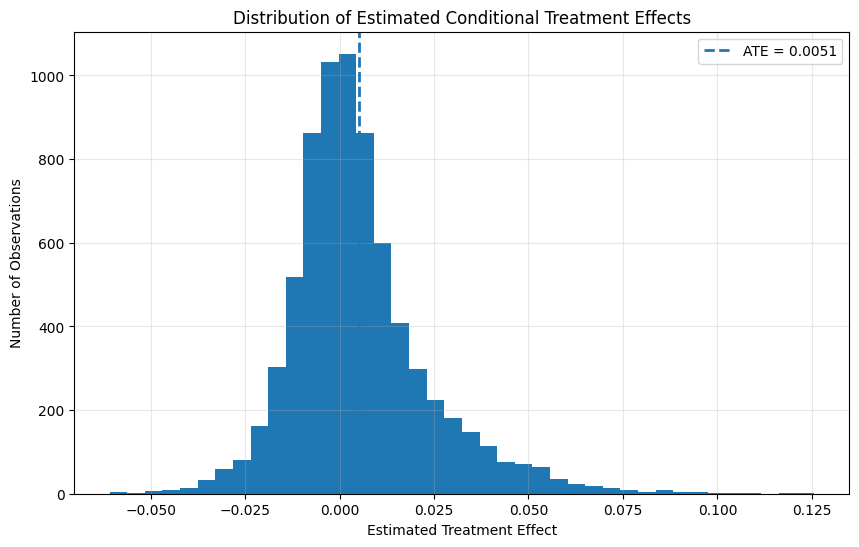

In [59]:
# ============================================
# CELL 59 — CATE DISTRIBUTION
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    cate_train,
    bins=40
)

plt.axvline(
    ate_train,
    linestyle="--",
    linewidth=2,
    label=f"ATE = {ate_train:.4f}"
)

plt.xlabel("Estimated Treatment Effect")
plt.ylabel("Number of Observations")
plt.title("Distribution of Estimated Conditional Treatment Effects")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

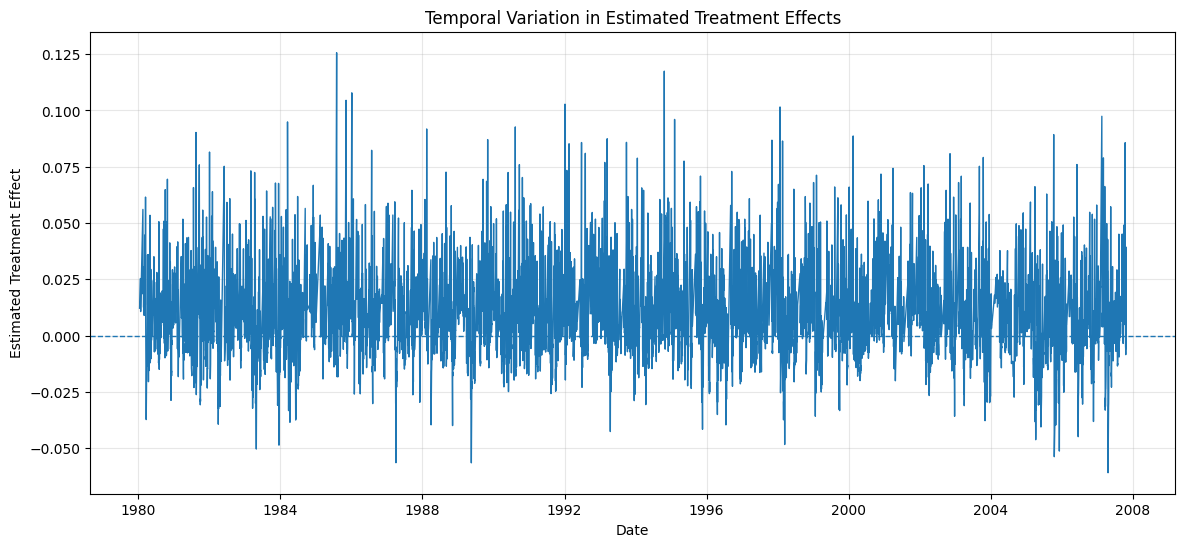

In [60]:
# ============================================
# CELL 60 — CATE THROUGH TIME
# ============================================

plot_data = cate_results.sort_values("Date")

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data["Date"],
    plot_data["CATE"],
    linewidth=1
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Date")
plt.ylabel("Estimated Treatment Effect")
plt.title("Temporal Variation in Estimated Treatment Effects")
plt.grid(alpha=0.3)

plt.show()

In [61]:
# ============================================
# CELL 61 — CAUSAL FOREST DML
# ============================================

from econml.dml import CausalForestDML

causal_forest = CausalForestDML(
    n_estimators=300,
    min_samples_leaf=20,
    max_depth=None,
    discrete_treatment=True,
    discrete_outcome=True,
    cv=3,
    random_state=42,
    n_jobs=-1
)

causal_forest.fit(
    Y_train_cs,
    T_train_cs,
    X=X_train_cs_scaled
)

print("Causal Forest DML fitted successfully.")

Causal Forest DML fitted successfully.


In [62]:
# ============================================
# CELL 62 — CAUSAL FOREST EFFECTS
# ============================================

forest_cate = causal_forest.effect(
    X_train_cs_scaled
)

forest_ate = np.mean(forest_cate)

print("Causal Forest results")
print("=" * 60)

print("Forest ATE:", forest_ate)
print("Minimum CATE:", np.min(forest_cate))
print("Maximum CATE:", np.max(forest_cate))
print("CATE standard deviation:", np.std(forest_cate))

Causal Forest results
Forest ATE: 0.006097875325593247
Minimum CATE: -0.0914181255241321
Maximum CATE: 0.11900950592902114
CATE standard deviation: 0.01880115646403529


In [63]:
# ============================================
# CELL 63 — COMPARE CAUSAL ML MODELS
# ============================================

model_comparison = pd.DataFrame({
    "Model": [
        "Linear DML",
        "Causal Forest DML"
    ],
    "ATE": [
        ate_train,
        forest_ate
    ]
})

model_comparison["Absolute_Difference_from_DML"] = (
    model_comparison["ATE"] - ate_train
).abs()

print("Causal model comparison:")
display(model_comparison)

Causal model comparison:


,Model,ATE,Absolute_Difference_from_DML
0,Linear DML,0.005110,0.000000
1,Causal Forest DML,0.006098,0.000987


In [64]:
# ============================================
# CELL 64 — CAUSAL FOREST FEATURE IMPORTANCE
# ============================================

forest_importance = pd.DataFrame({
    "Feature": covariates,
    "Importance": causal_forest.feature_importances_
})

forest_importance = forest_importance.sort_values(
    "Importance",
    ascending=False
)

print("Causal Forest heterogeneity feature importance:")
display(forest_importance)

Causal Forest heterogeneity feature importance:


,Feature,Importance
7,streamflow_lag1,0.315523
2,Rain14_lag,0.226423
1,Rain3_lag,0.212938
0,Rain_lag1,0.095166
3,tmax,0.069783
4,tmin,0.043690
5,vp,0.036477
6,swe,0.000000


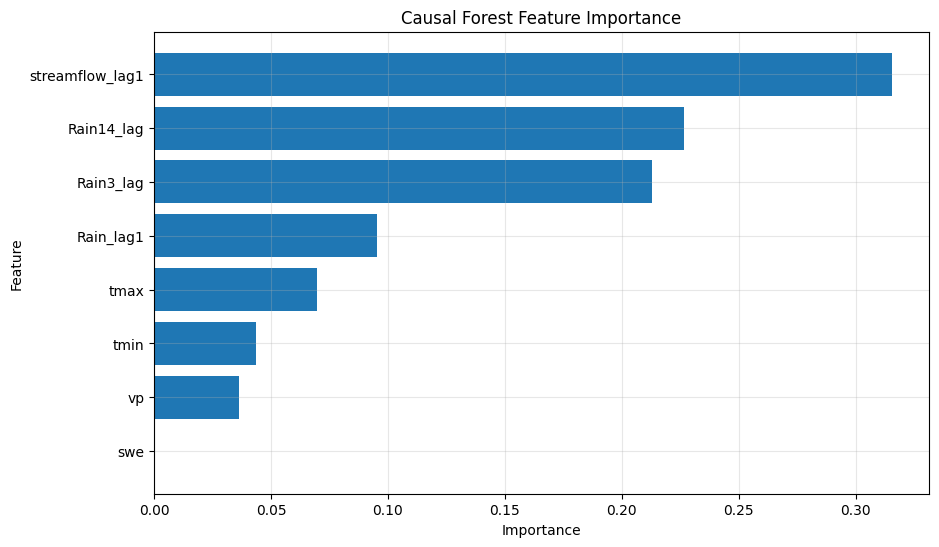

In [65]:
# ============================================
# CELL 65 — PLOT CAUSAL FEATURE IMPORTANCE
# ============================================

importance_plot = forest_importance.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Causal Forest Feature Importance")
plt.grid(alpha=0.3)

plt.show()

In [66]:
# ============================================
# CELL 66 — RAINFALL THRESHOLD SENSITIVITY
# ============================================

thresholds = [0.70, 0.75, 0.80, 0.90]

threshold_results = []

for q in thresholds:

    threshold_value = data["Rain7_lag"].quantile(q)

    temporary_treatment = (
        data["Rain7_lag"] >= threshold_value
    ).astype(int)

    valid = (
        temporary_treatment.notna() &
        data["FutureHighFlow"].notna()
    )

    treated_outcome = data.loc[
        valid & (temporary_treatment == 1),
        "FutureHighFlow"
    ].mean()

    control_outcome = data.loc[
        valid & (temporary_treatment == 0),
        "FutureHighFlow"
    ].mean()

    difference = (
        treated_outcome - control_outcome
    )

    threshold_results.append({
        "Rainfall_Percentile": q,
        "Threshold": threshold_value,
        "Treated_Risk": treated_outcome,
        "Control_Risk": control_outcome,
        "Observed_Difference": difference
    })

threshold_results = pd.DataFrame(
    threshold_results
)

display(threshold_results)

,Rainfall_Percentile,Threshold,Treated_Risk,Control_Risk,Observed_Difference
0,0.70,31.894,0.110908,0.023573,0.087335
1,0.75,36.040,0.121601,0.025772,0.095828
2,0.80,40.498,0.136204,0.028158,0.108046
3,0.90,55.866,0.190923,0.034072,0.156851


In [67]:
# ============================================
# CELL 67 — RAINFALL WINDOW SENSITIVITY
# ============================================

window_columns = [
    "Rain_lag1",
    "Rain3_lag",
    "Rain7_lag",
    "Rain14_lag"
]

window_results = []

for column in window_columns:

    threshold = data[column].quantile(0.75)

    treatment_temp = (
        data[column] >= threshold
    ).astype(int)

    valid = (
        treatment_temp.notna() &
        data["FutureHighFlow"].notna()
    )

    treated_risk = data.loc[
        valid & (treatment_temp == 1),
        "FutureHighFlow"
    ].mean()

    control_risk = data.loc[
        valid & (treatment_temp == 0),
        "FutureHighFlow"
    ].mean()

    window_results.append({
        "Treatment_Window": column,
        "Threshold": threshold,
        "Treated_Risk": treated_risk,
        "Control_Risk": control_risk,
        "Difference": treated_risk - control_risk
    })

window_results = pd.DataFrame(
    window_results
)

print("Sensitivity to rainfall-memory window:")
display(window_results)

Sensitivity to rainfall-memory window:


,Treatment_Window,Threshold,Treated_Risk,Control_Risk,Difference
0,Rain_lag1,4.0200,0.111007,0.029317,0.081690
1,Rain3_lag,16.0800,0.122340,0.025555,0.096785
2,Rain7_lag,36.0400,0.121601,0.025772,0.095828
3,Rain14_lag,67.9675,0.110589,0.029507,0.081082


In [68]:
# ============================================
# CELL 68 — FINAL RESULTS SUMMARY
# ============================================

final_results = pd.DataFrame({
    "Metric": [
        "Number of training observations",
        "Number of testing observations",
        "Treatment rate",
        "Future high-flow rate",
        "Observed treatment-outcome difference",
        "Linear DML ATE",
        "Causal Forest ATE",
        "Linear DML CATE standard deviation"
    ],
    "Value": [
        len(train_data_cs),
        len(test_data),
        T_train_cs.mean(),
        Y_train_cs.mean(),
        naive_difference,
        ate_train,
        forest_ate,
        np.std(cate_train)
    ]
})

print("FINAL CAUSAL ML RESULTS")
print("=" * 60)

display(final_results)

FINAL CAUSAL ML RESULTS


,Metric,Value
0,Number of training observations,7309.000000
1,Number of testing observations,2536.000000
2,Treatment rate,0.299357
3,Future high-flow rate,0.045697
4,Observed treatment-outcome difference,0.049585
5,Linear DML ATE,0.005110
6,Causal Forest ATE,0.006098
7,Linear DML CATE standard deviation,0.018385


In [69]:
# ============================================
# CELL 69 — SAVE RESULTS
# ============================================

results_dir = "/content/causal_flood_results"

os.makedirs(
    results_dir,
    exist_ok=True
)

# Save main datasets
causal_data.to_csv(
    os.path.join(
        results_dir,
        "causal_analysis_data.csv"
    ),
    index=False
)

cate_results.to_csv(
    os.path.join(
        results_dir,
        "CATE_results.csv"
    ),
    index=False
)

final_results.to_csv(
    os.path.join(
        results_dir,
        "final_results.csv"
    ),
    index=False
)

threshold_results.to_csv(
    os.path.join(
        results_dir,
        "threshold_sensitivity.csv"
    ),
    index=False
)

window_results.to_csv(
    os.path.join(
        results_dir,
        "rainfall_window_sensitivity.csv"
    ),
    index=False
)

forest_importance.to_csv(
    os.path.join(
        results_dir,
        "causal_forest_feature_importance.csv"
    ),
    index=False
)

print("Results saved to:")
print(results_dir)

print("\nFiles created:")
for file in sorted(os.listdir(results_dir)):
    print("-", file)

Results saved to:
/content/causal_flood_results

Files created:
- CATE_results.csv
- causal_analysis_data.csv
- causal_forest_feature_importance.csv
- final_results.csv
- rainfall_window_sensitivity.csv
- threshold_sensitivity.csv


In [70]:
# ============================================
# CELL 70 — FINAL RESEARCH SUMMARY
# ============================================

print("=" * 70)
print("CAUSAL MACHINE LEARNING FLOOD / HIGH-FLOW STUDY")
print("=" * 70)

print("\nBasin:")
print(data["basin_id"].iloc[0])

print("\nTreatment:")
print(
    "High antecedent 7-day rainfall exposure "
    "(Rain7_lag >= 75th percentile)"
)

print("\nOutcome:")
print(
    "FutureHighFlow = next-day streamflow >= "
    "catchment-specific Q95"
)

print("\nTraining observations:")
print(len(train_data_cs))

print("\nTesting observations:")
print(len(test_data))

print("\nObserved treatment-outcome difference:")
print(round(naive_difference, 5))

print("\nLinear DML ATE:")
print(round(ate_train, 5))

print("\nCausal Forest ATE:")
print(round(forest_ate, 5))

print("\nCATE standard deviation:")
print(round(np.std(cate_train), 5))

print("\n" + "=" * 70)
print("ANALYSIS COMPLETE")
print("=" * 70)

print(
    "\nImportant interpretation:"
)

print(
    "The estimated effects describe the modeled causal effect "
    "under the assumptions required for identification, including "
    "adequate covariate adjustment, treatment overlap, consistency, "
    "and absence of important unmeasured confounding."
)

print(
    "\nThis current version uses one CAMELS basin."
)

print(
    "For the final research paper, the next major step is "
    "to repeat the complete pipeline across multiple CAMELS "
    "catchments and estimate cross-catchment heterogeneity."
)

CAUSAL MACHINE LEARNING FLOOD / HIGH-FLOW STUDY

Basin:
01022500

Treatment:
High antecedent 7-day rainfall exposure (Rain7_lag >= 75th percentile)

Outcome:
FutureHighFlow = next-day streamflow >= catchment-specific Q95

Training observations:
7309

Testing observations:
2536

Observed treatment-outcome difference:
0.04959

Linear DML ATE:
0.00511

Causal Forest ATE:
0.0061

CATE standard deviation:
0.01839

ANALYSIS COMPLETE

Important interpretation:
The estimated effects describe the modeled causal effect under the assumptions required for identification, including adequate covariate adjustment, treatment overlap, consistency, and absence of important unmeasured confounding.

This current version uses one CAMELS basin.
For the final research paper, the next major step is to repeat the complete pipeline across multiple CAMELS catchments and estimate cross-catchment heterogeneity.


In [71]:
# ============================================
# CELL 71 — PUBLICATION FIGURE SETUP
# ============================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# Directory for publication figures
figure_dir = "/content/causal_flood_results/figures"

os.makedirs(
    figure_dir,
    exist_ok=True
)

print("Publication figure directory:")
print(figure_dir)

print("\nFigures will be saved as:")
print(".png at 300 dpi")
print(".pdf for vector-quality publication figures")

Publication figure directory:
/content/causal_flood_results/figures

Figures will be saved as:
.png at 300 dpi
.pdf for vector-quality publication figures


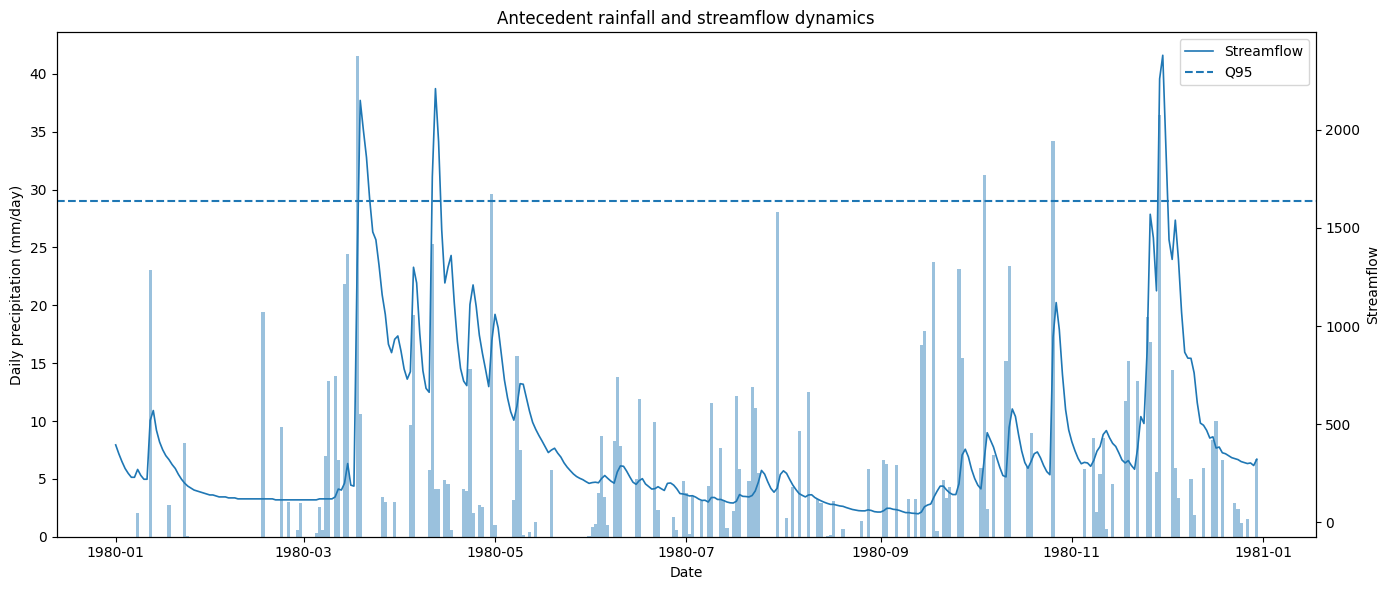

In [72]:
# ============================================
# CELL 72 — RAINFALL + STREAMFLOW TIME SERIES
# ============================================

plot_data = data[
    [
        "Date",
        "prcp",
        "streamflow",
        "Q95"
    ]
].dropna().copy()

# Show a representative period rather than the entire record
# to keep the figure readable.
n_days = min(365, len(plot_data))

plot_data = plot_data.iloc[:n_days]

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(
    plot_data["Date"],
    plot_data["prcp"],
    width=1.0,
    alpha=0.45
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Daily precipitation (mm/day)")

ax2 = ax1.twinx()

ax2.plot(
    plot_data["Date"],
    plot_data["streamflow"],
    linewidth=1.2,
    label="Streamflow"
)

ax2.axhline(
    plot_data["Q95"].iloc[0],
    linestyle="--",
    linewidth=1.5,
    label="Q95"
)

ax2.set_ylabel("Streamflow")

ax2.legend(
    loc="upper right"
)

plt.title(
    "Antecedent rainfall and streamflow dynamics"
)

fig.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_1_rainfall_streamflow.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_1_rainfall_streamflow.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

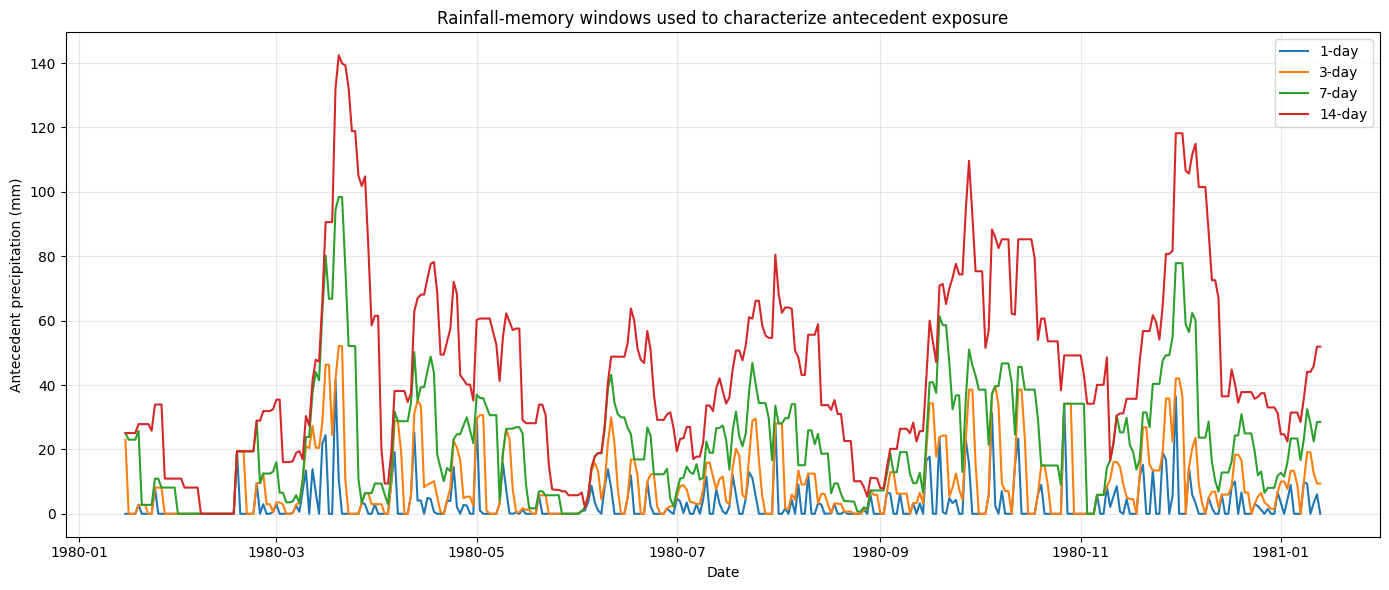

In [73]:
# ============================================
# CELL 73 — ANTECEDENT RAINFALL WINDOWS
# ============================================

window_data = data[
    [
        "Date",
        "Rain_lag1",
        "Rain3_lag",
        "Rain7_lag",
        "Rain14_lag"
    ]
].dropna().copy()

n_days = min(365, len(window_data))

window_data = window_data.iloc[:n_days]

plt.figure(figsize=(14, 6))

plt.plot(
    window_data["Date"],
    window_data["Rain_lag1"],
    label="1-day"
)

plt.plot(
    window_data["Date"],
    window_data["Rain3_lag"],
    label="3-day"
)

plt.plot(
    window_data["Date"],
    window_data["Rain7_lag"],
    label="7-day"
)

plt.plot(
    window_data["Date"],
    window_data["Rain14_lag"],
    label="14-day"
)

plt.xlabel("Date")
plt.ylabel("Antecedent precipitation (mm)")

plt.title(
    "Rainfall-memory windows used to characterize antecedent exposure"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_2_rainfall_memory_windows.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_2_rainfall_memory_windows.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

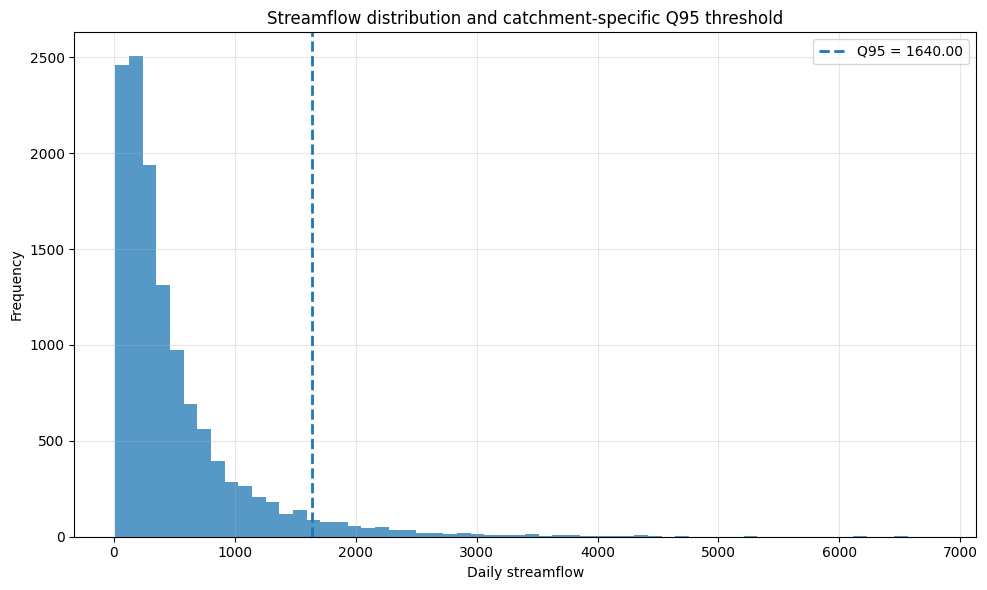

In [74]:
# ============================================
# CELL 74 — STREAMFLOW DISTRIBUTION + Q95
# ============================================

flow_values = data["streamflow"].dropna()

q95_value = data["Q95"].dropna().iloc[0]

plt.figure(figsize=(10, 6))

plt.hist(
    flow_values,
    bins=60,
    alpha=0.75
)

plt.axvline(
    q95_value,
    linestyle="--",
    linewidth=2,
    label=f"Q95 = {q95_value:.2f}"
)

plt.xlabel("Daily streamflow")
plt.ylabel("Frequency")

plt.title(
    "Streamflow distribution and catchment-specific Q95 threshold"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_3_streamflow_Q95.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_3_streamflow_Q95.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

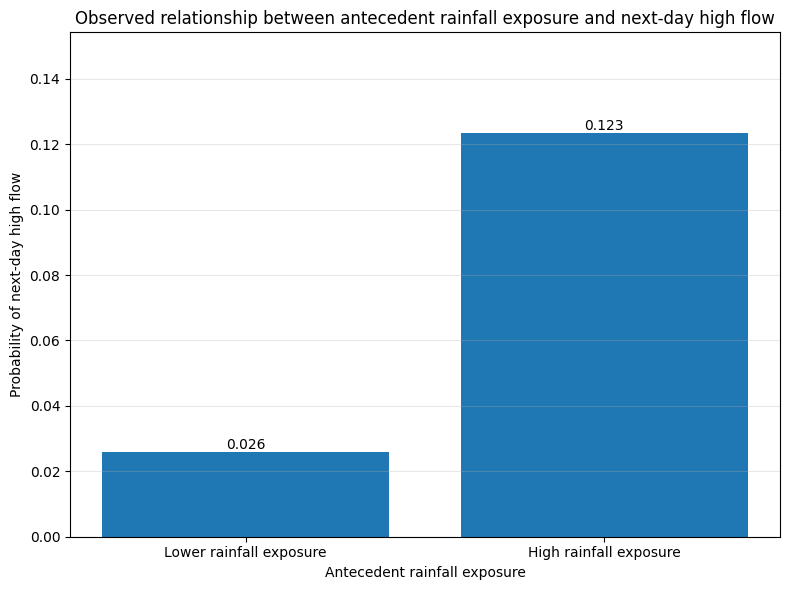

In [75]:
# ============================================
# CELL 75 — TREATMENT VS OUTCOME
# ============================================

group_rates = (
    causal_data
    .groupby(treatment_col)[outcome_col]
    .mean()
)

labels = [
    "Lower rainfall exposure",
    "High rainfall exposure"
]

values = [
    group_rates.get(0, np.nan),
    group_rates.get(1, np.nan)
]

plt.figure(figsize=(8, 6))

bars = plt.bar(
    labels,
    values
)

plt.ylabel("Probability of next-day high flow")
plt.xlabel("Antecedent rainfall exposure")

plt.title(
    "Observed relationship between antecedent rainfall exposure "
    "and next-day high flow"
)

plt.ylim(
    0,
    min(1.0, max(values) * 1.25)
)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_4_treatment_outcome.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_4_treatment_outcome.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

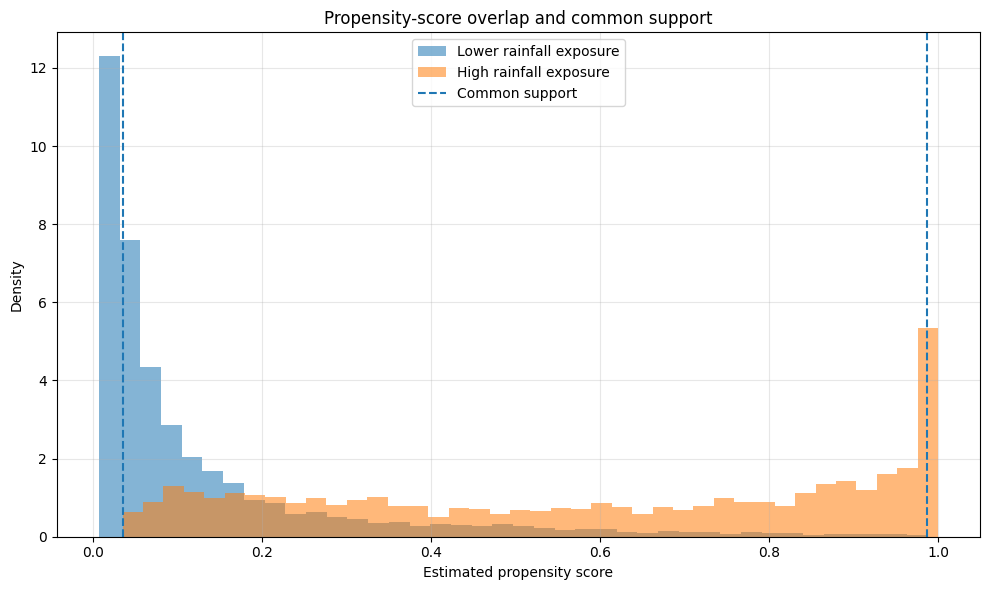

In [76]:
# ============================================
# CELL 76 — PROPENSITY SCORE OVERLAP
# ============================================

treated_ps = train_data.loc[
    train_data[treatment_col] == 1,
    "propensity_score"
]

control_ps = train_data.loc[
    train_data[treatment_col] == 0,
    "propensity_score"
]

plt.figure(figsize=(10, 6))

plt.hist(
    control_ps,
    bins=40,
    alpha=0.55,
    density=True,
    label="Lower rainfall exposure"
)

plt.hist(
    treated_ps,
    bins=40,
    alpha=0.55,
    density=True,
    label="High rainfall exposure"
)

plt.axvline(
    common_lower,
    linestyle="--",
    linewidth=1.5,
    label="Common support"
)

plt.axvline(
    common_upper,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Estimated propensity score")
plt.ylabel("Density")

plt.title(
    "Propensity-score overlap and common support"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_5_propensity_overlap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_5_propensity_overlap.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

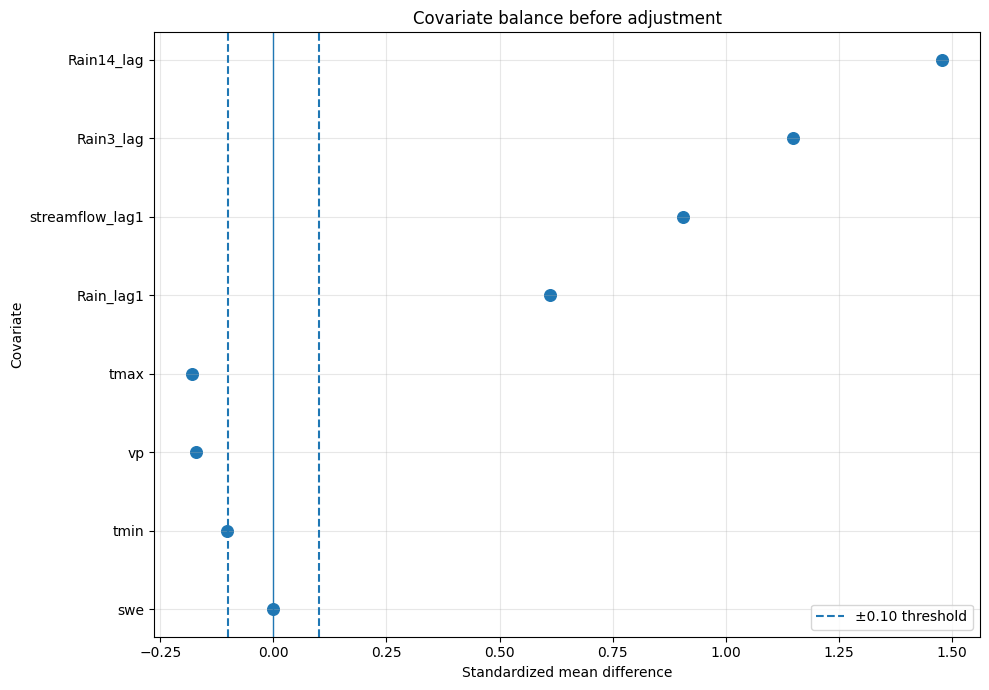

In [77]:
# ============================================
# CELL 77 — STANDARDIZED MEAN DIFFERENCES
# ============================================

smd_plot = smd_results.sort_values(
    "Absolute_SMD"
)

plt.figure(figsize=(10, 7))

plt.scatter(
    smd_plot["SMD"],
    smd_plot["Feature"],
    s=70
)

plt.axvline(
    0,
    linestyle="-",
    linewidth=1
)

plt.axvline(
    0.10,
    linestyle="--",
    linewidth=1.5,
    label="±0.10 threshold"
)

plt.axvline(
    -0.10,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Standardized mean difference")
plt.ylabel("Covariate")

plt.title(
    "Covariate balance before adjustment"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_6_covariate_balance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_6_covariate_balance.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

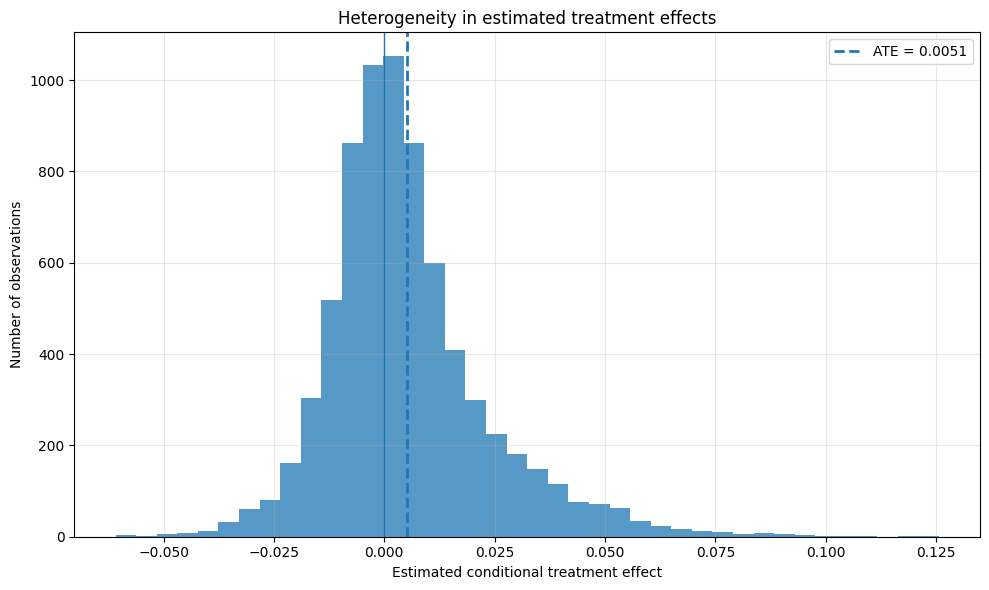

In [78]:
# ============================================
# CELL 78 — CATE DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 6))

plt.hist(
    cate_train,
    bins=40,
    alpha=0.75
)

plt.axvline(
    ate_train,
    linestyle="--",
    linewidth=2,
    label=f"ATE = {ate_train:.4f}"
)

plt.axvline(
    0,
    linestyle="-",
    linewidth=1
)

plt.xlabel(
    "Estimated conditional treatment effect"
)

plt.ylabel("Number of observations")

plt.title(
    "Heterogeneity in estimated treatment effects"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_7_CATE_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_7_CATE_distribution.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

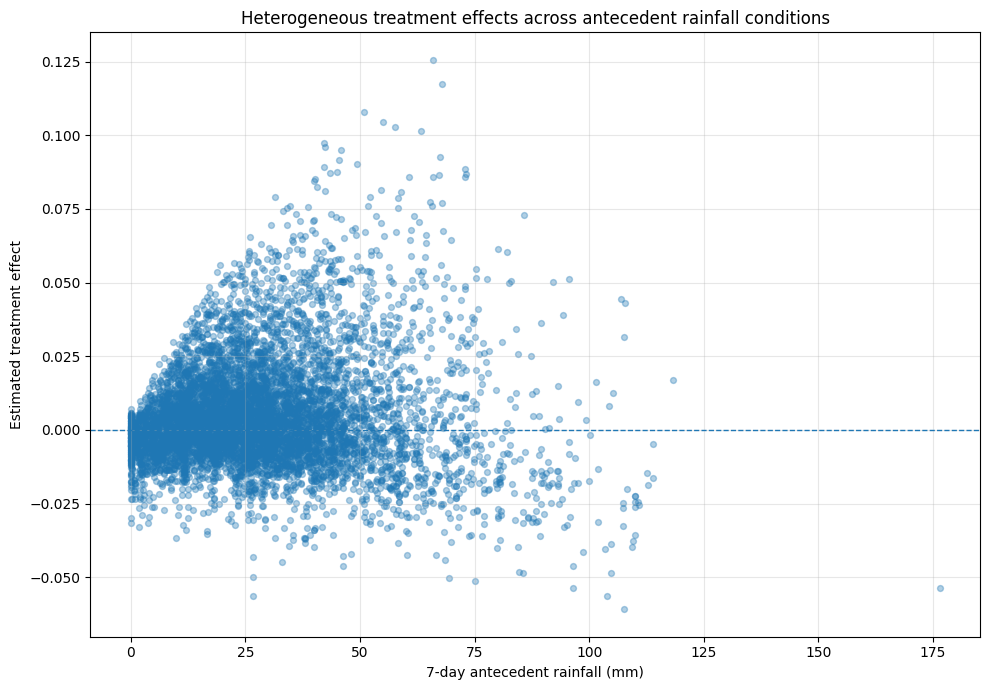

In [79]:
# ============================================
# CELL 79 — CATE VS ANTECEDENT RAINFALL
# ============================================

# Select necessary columns from analysis_data to get 'Rain7_lag' and 'streamflow_lag1'
rainfall_data_for_plot = analysis_data[['Date', 'basin_id', 'Rain7_lag', 'streamflow_lag1']].copy()

# Merge cate_results with the selected columns from analysis_data
# cate_results is already aligned with the observations in train_data_cs
cate_plot_data = pd.merge(
    cate_results,
    rainfall_data_for_plot,
    on=['Date', 'basin_id'],
    how='left'
)

plt.figure(figsize=(10, 7))

plt.scatter(
    cate_plot_data["Rain7_lag"],
    cate_plot_data["CATE"],
    alpha=0.35,
    s=18
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("7-day antecedent rainfall (mm)")
plt.ylabel("Estimated treatment effect")

plt.title(
    "Heterogeneous treatment effects across antecedent rainfall conditions"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_8_CATE_vs_rainfall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_8_CATE_vs_rainfall.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

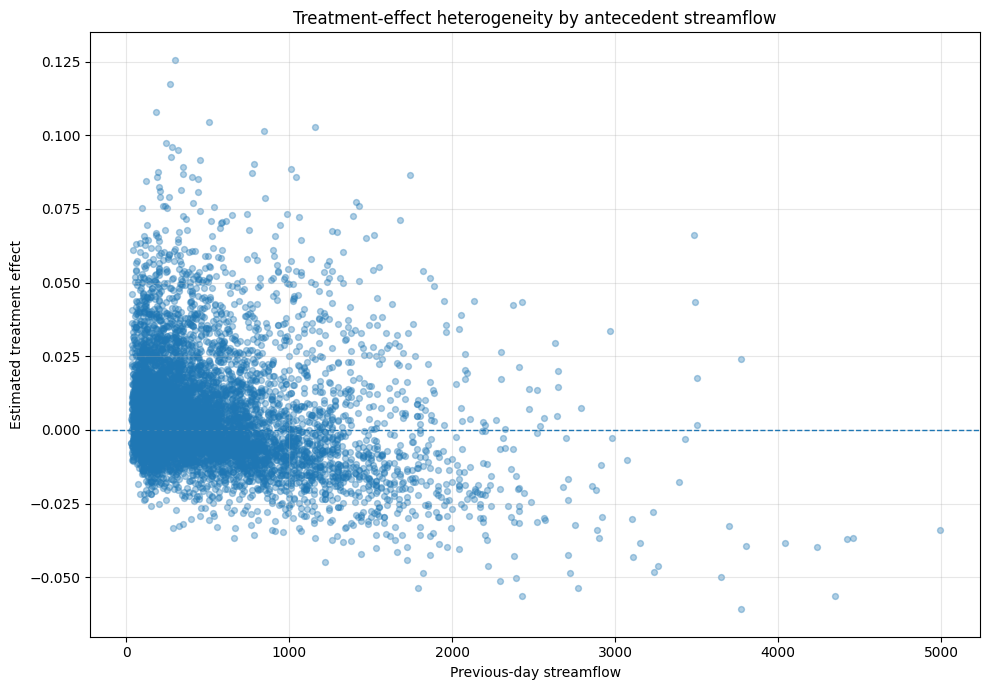

In [80]:
# ============================================
# CELL 80 — CATE VS ANTECEDENT STREAMFLOW
# ============================================

plt.figure(figsize=(10, 7))

plt.scatter(
    cate_plot_data["streamflow_lag1"],
    cate_plot_data["CATE"],
    alpha=0.35,
    s=18
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Previous-day streamflow")
plt.ylabel("Estimated treatment effect")

plt.title(
    "Treatment-effect heterogeneity by antecedent streamflow"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_9_CATE_vs_streamflow.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_9_CATE_vs_streamflow.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

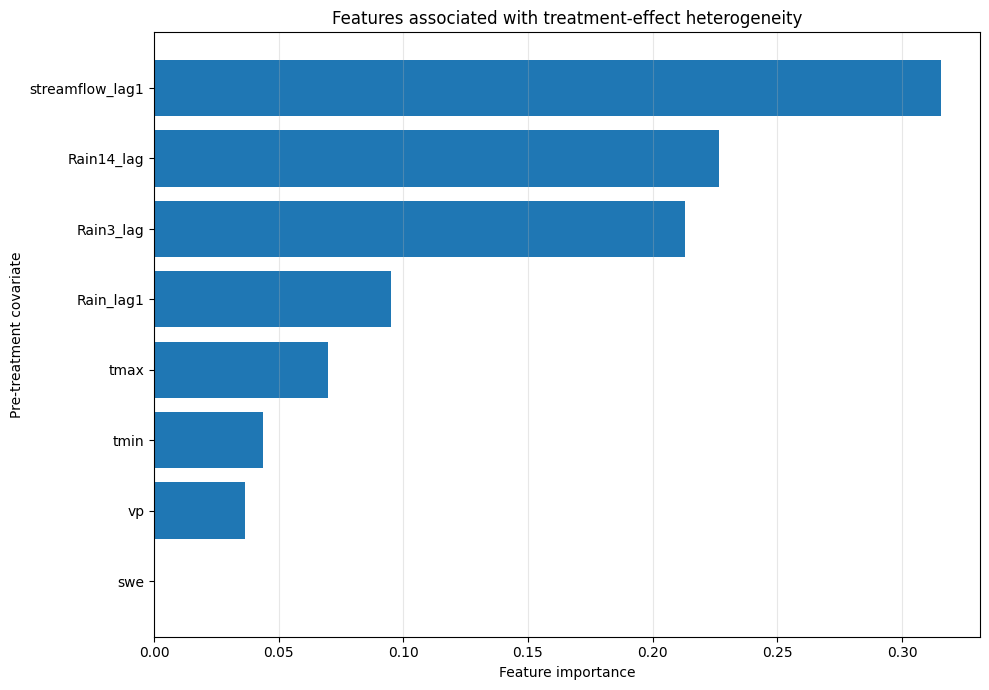

In [81]:
# ============================================
# CELL 81 — CAUSAL FOREST FEATURE IMPORTANCE
# ============================================

forest_plot = forest_importance.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    forest_plot["Feature"],
    forest_plot["Importance"]
)

plt.xlabel("Feature importance")
plt.ylabel("Pre-treatment covariate")

plt.title(
    "Features associated with treatment-effect heterogeneity"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_10_causal_forest_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_10_causal_forest_importance.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

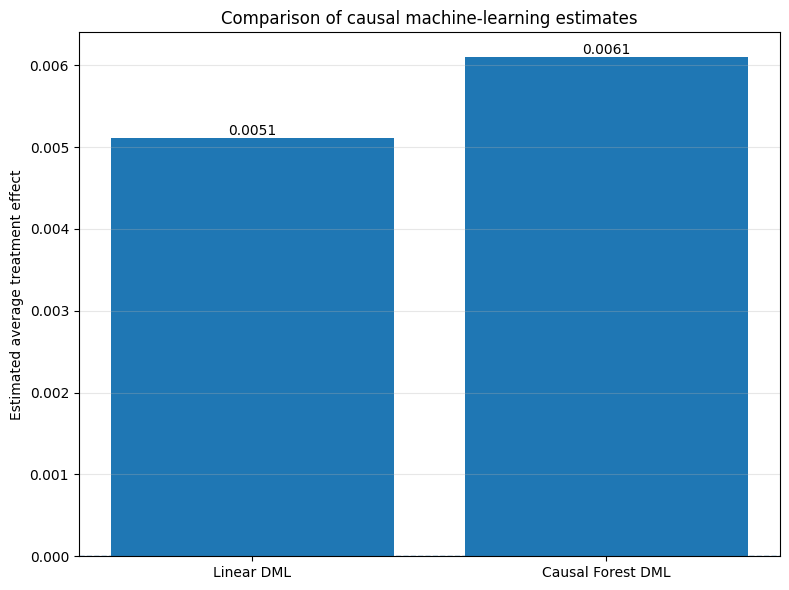

In [82]:
# ============================================
# CELL 82 — CAUSAL MODEL COMPARISON
# ============================================

model_names = [
    "Linear DML",
    "Causal Forest DML"
]

model_ates = [
    ate_train,
    forest_ate
]

plt.figure(figsize=(8, 6))

bars = plt.bar(
    model_names,
    model_ates
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.ylabel("Estimated average treatment effect")

plt.title(
    "Comparison of causal machine-learning estimates"
)

for bar, value in zip(bars, model_ates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_11_model_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_11_model_comparison.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

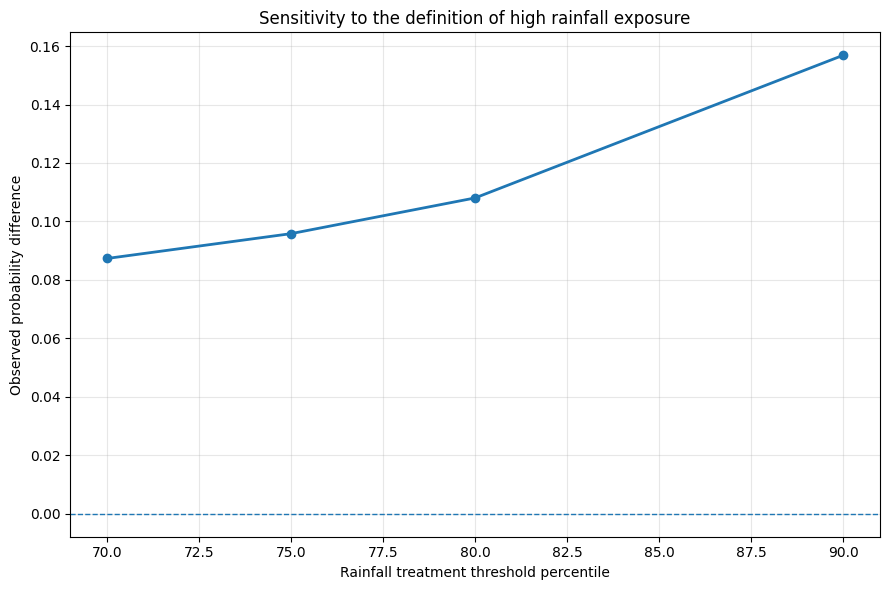

In [83]:
# ============================================
# CELL 83 — TREATMENT THRESHOLD SENSITIVITY
# ============================================

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["Rainfall_Percentile"] * 100,
    threshold_results["Observed_Difference"],
    marker="o",
    linewidth=2
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Rainfall treatment threshold percentile"
)

plt.ylabel(
    "Observed probability difference"
)

plt.title(
    "Sensitivity to the definition of high rainfall exposure"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_12_threshold_sensitivity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_12_threshold_sensitivity.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

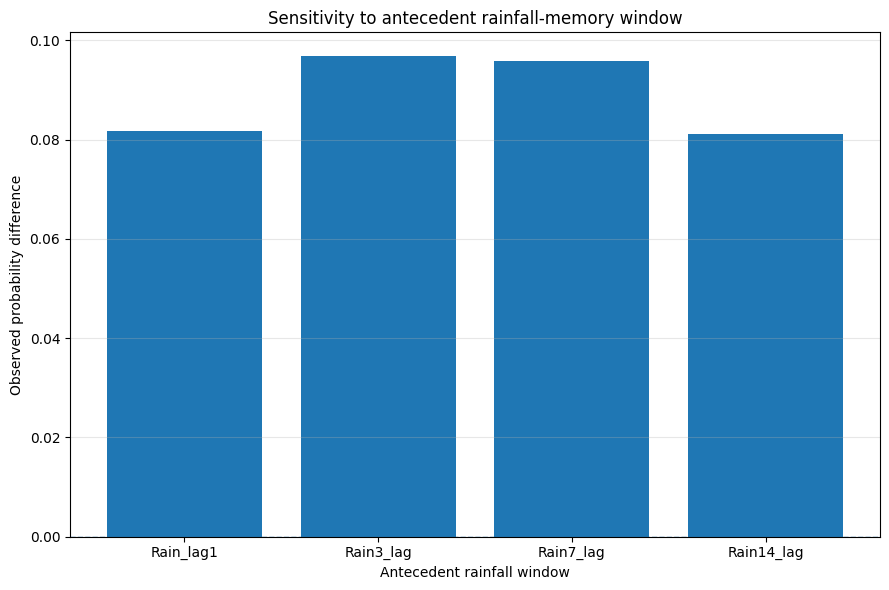

In [84]:
# ============================================
# CELL 84 — RAINFALL WINDOW SENSITIVITY
# ============================================

plt.figure(figsize=(9, 6))

plt.bar(
    window_results["Treatment_Window"],
    window_results["Difference"]
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Antecedent rainfall window"
)

plt.ylabel(
    "Observed probability difference"
)

plt.title(
    "Sensitivity to antecedent rainfall-memory window"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_13_window_sensitivity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_13_window_sensitivity.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

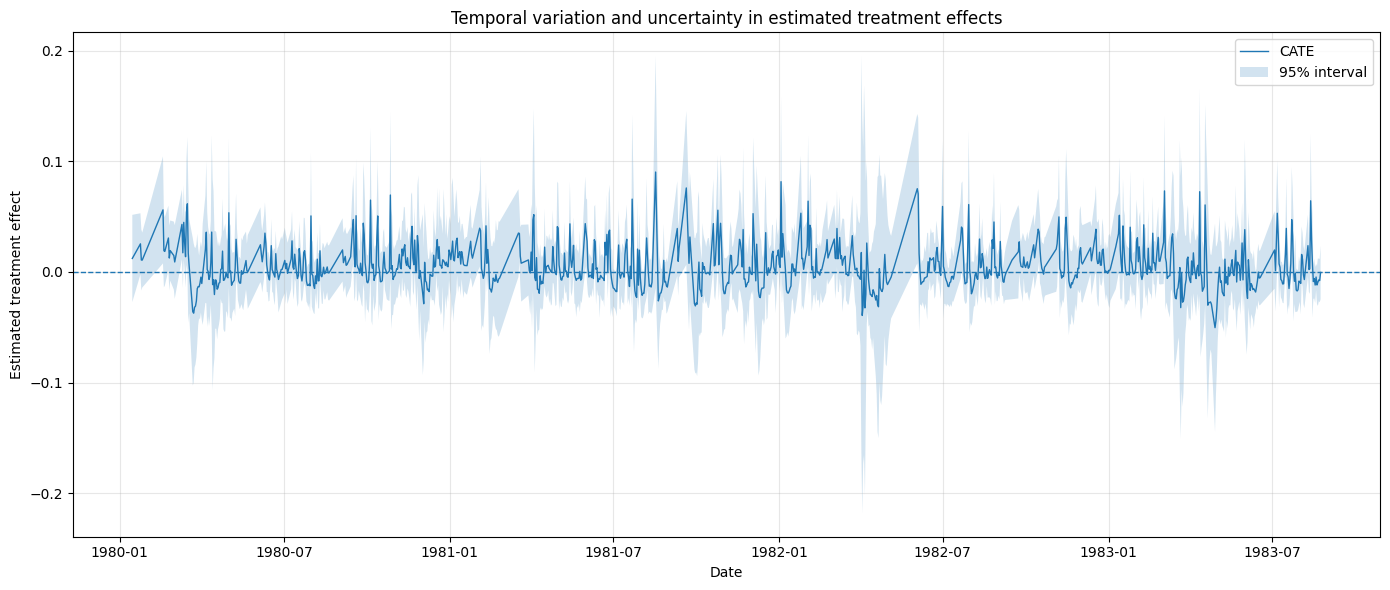

In [85]:
# ============================================
# CELL 85 — CATE WITH CONFIDENCE INTERVALS
# ============================================

if "CATE_lower" in cate_results.columns:

    time_cate = cate_results.sort_values(
        "Date"
    ).copy()

    # Limit to a readable period if the dataset is very long
    if len(time_cate) > 1000:
        time_cate = time_cate.iloc[:1000]

    plt.figure(figsize=(14, 6))

    plt.plot(
        time_cate["Date"],
        time_cate["CATE"],
        linewidth=1,
        label="CATE"
    )

    plt.fill_between(
        time_cate["Date"],
        time_cate["CATE_lower"],
        time_cate["CATE_upper"],
        alpha=0.2,
        label="95% interval"
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    plt.xlabel("Date")
    plt.ylabel("Estimated treatment effect")

    plt.title(
        "Temporal variation and uncertainty in estimated treatment effects"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            figure_dir,
            "Figure_14_CATE_uncertainty.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        os.path.join(
            figure_dir,
            "Figure_14_CATE_uncertainty.pdf"
        ),
        bbox_inches="tight"
    )

    plt.show()

else:

    print(
        "CATE confidence intervals are not available."
    )

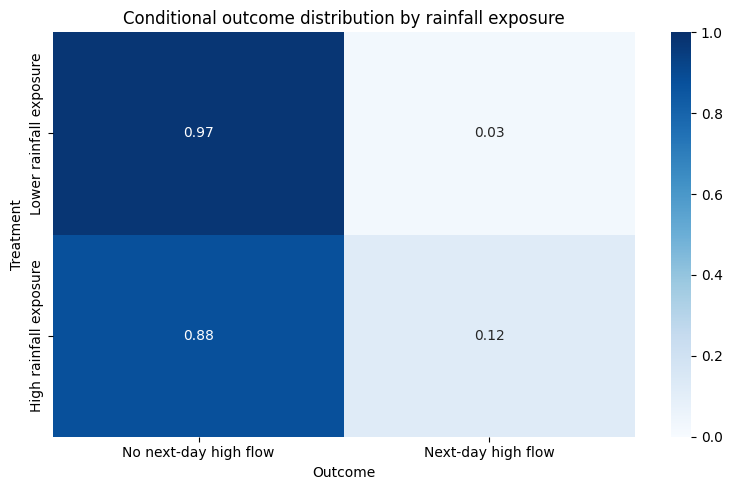

In [86]:
# ============================================
# CELL 86 — TREATMENT × OUTCOME HEATMAP
# ============================================

import seaborn as sns

contingency = pd.crosstab(
    causal_data[treatment_col],
    causal_data[outcome_col],
    normalize="index"
)

contingency.index = [
    "Lower rainfall exposure",
    "High rainfall exposure"
]

contingency.columns = [
    "No next-day high flow",
    "Next-day high flow"
]

plt.figure(figsize=(8, 5))

sns.heatmap(
    contingency,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.xlabel("Outcome")
plt.ylabel("Treatment")
plt.title(
    "Conditional outcome distribution by rainfall exposure"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_15_treatment_outcome_heatmap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_15_treatment_outcome_heatmap.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

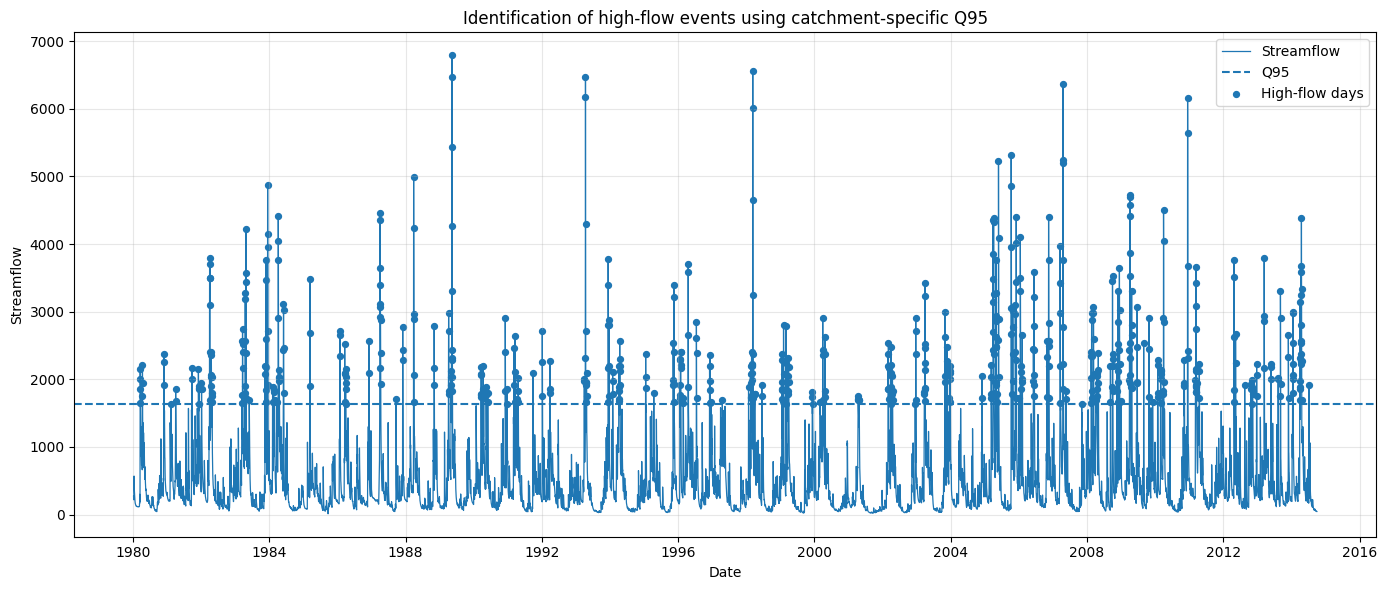

In [87]:
# ============================================
# CELL 87 — HIGH-FLOW EVENTS THROUGH TIME
# ============================================

event_data = data[
    [
        "Date",
        "streamflow",
        "Q95",
        "HighFlow",
        "Rain7_lag"
    ]
].dropna().copy()

plt.figure(figsize=(14, 6))

plt.plot(
    event_data["Date"],
    event_data["streamflow"],
    linewidth=0.9,
    label="Streamflow"
)

plt.axhline(
    event_data["Q95"].iloc[0],
    linestyle="--",
    linewidth=1.5,
    label="Q95"
)

high_flow_events = event_data[
    event_data["HighFlow"] == 1
]

plt.scatter(
    high_flow_events["Date"],
    high_flow_events["streamflow"],
    s=18,
    label="High-flow days"
)

plt.xlabel("Date")
plt.ylabel("Streamflow")

plt.title(
    "Identification of high-flow events using catchment-specific Q95"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_16_high_flow_events.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_16_high_flow_events.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

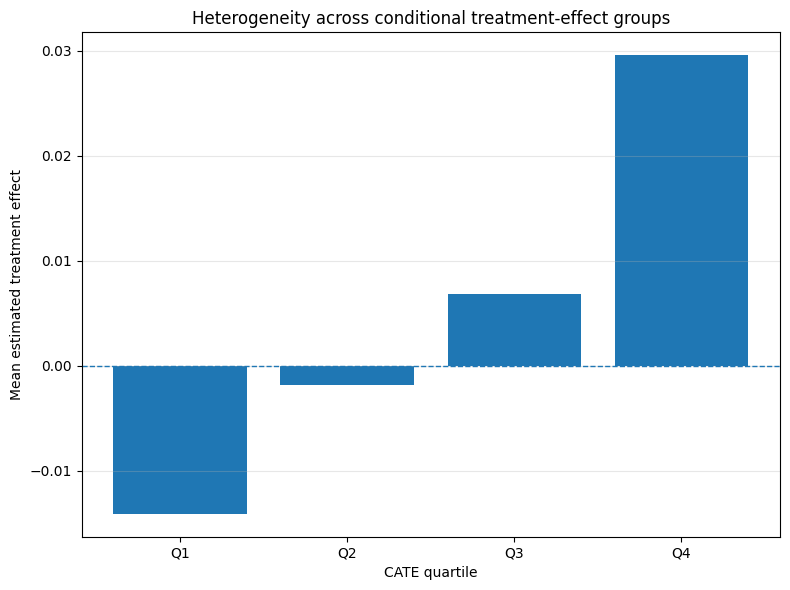

,CATE_quartile,mean,median,std,count
0,Q1,-0.014127,-0.011757,0.007871,1828
1,Q2,-0.001838,-0.001811,0.002384,1827
2,Q3,0.006829,0.006345,0.002974,1827
3,Q4,0.029588,0.024944,0.015976,1827


In [88]:
# ============================================
# CELL 88 — CATE QUARTILE ANALYSIS
# ============================================

quartile_data = cate_results.copy()

quartile_data["CATE_quartile"] = pd.qcut(
    quartile_data["CATE"],
    q=4,
    labels=[
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ],
    duplicates="drop"
)

quartile_summary = (
    quartile_data
    .groupby("CATE_quartile", observed=False)["CATE"]
    .agg(["mean", "median", "std", "count"])
    .reset_index()
)

plt.figure(figsize=(8, 6))

plt.bar(
    quartile_summary["CATE_quartile"].astype(str),
    quartile_summary["mean"]
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("CATE quartile")
plt.ylabel("Mean estimated treatment effect")

plt.title(
    "Heterogeneity across conditional treatment-effect groups"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_17_CATE_quartiles.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figure_dir,
        "Figure_17_CATE_quartiles.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

display(quartile_summary)

In [89]:
# ============================================
# CELL 89 — FIGURE INVENTORY
# ============================================

figure_files = sorted(
    os.listdir(figure_dir)
)

print("PUBLICATION FIGURE INVENTORY")
print("=" * 60)

for file in figure_files:
    print(file)

print("\nTotal figure files:")
print(len(figure_files))

print(
    "\nEach figure has been saved in PNG and PDF format "
    "where applicable."
)

PUBLICATION FIGURE INVENTORY
Figure_10_causal_forest_importance.pdf
Figure_10_causal_forest_importance.png
Figure_11_model_comparison.pdf
Figure_11_model_comparison.png
Figure_12_threshold_sensitivity.pdf
Figure_12_threshold_sensitivity.png
Figure_13_window_sensitivity.pdf
Figure_13_window_sensitivity.png
Figure_14_CATE_uncertainty.pdf
Figure_14_CATE_uncertainty.png
Figure_15_treatment_outcome_heatmap.pdf
Figure_15_treatment_outcome_heatmap.png
Figure_16_high_flow_events.pdf
Figure_16_high_flow_events.png
Figure_17_CATE_quartiles.pdf
Figure_17_CATE_quartiles.png
Figure_1_rainfall_streamflow.pdf
Figure_1_rainfall_streamflow.png
Figure_2_rainfall_memory_windows.pdf
Figure_2_rainfall_memory_windows.png
Figure_3_streamflow_Q95.pdf
Figure_3_streamflow_Q95.png
Figure_4_treatment_outcome.pdf
Figure_4_treatment_outcome.png
Figure_5_propensity_overlap.pdf
Figure_5_propensity_overlap.png
Figure_6_covariate_balance.pdf
Figure_6_covariate_balance.png
Figure_7_CATE_distribution.pdf
Figure_7_CATE_di

In [90]:
# ============================================
# CELL 90 — FINAL ANALYSIS REPORT
# ============================================

print("=" * 75)
print("FINAL CAUSAL HYDROLOGY ANALYSIS REPORT")
print("=" * 75)

print("\n1. DATA")
print("-" * 75)

print("Basin:", data["basin_id"].iloc[0])
print("Number of observations:", len(data))
print("Date range:", data["Date"].min(), "to", data["Date"].max())

print("\n2. TREATMENT")
print("-" * 75)

print(
    "Treatment: 7-day antecedent rainfall >= "
    "75th percentile"
)

print(
    "Treatment rate:",
    round(
        causal_data[treatment_col].mean() * 100,
        2
    ),
    "%"
)

print("\n3. OUTCOME")
print("-" * 75)

print(
    "Outcome: next-day streamflow >= catchment-specific Q95"
)

print(
    "Future high-flow rate:",
    round(
        causal_data[outcome_col].mean() * 100,
        2
    ),
    "%"
)

print("\n4. CAUSAL ESTIMATION")
print("-" * 75)

print(
    "Linear DML ATE:",
    round(ate_train, 6)
)

print(
    "Causal Forest ATE:",
    round(forest_ate, 6)
)

print(
    "CATE standard deviation:",
    round(np.std(cate_train), 6)
)

print("\n5. COMMON SUPPORT")
print("-" * 75)

print(
    "Common support:",
    round(common_lower, 4),
    "to",
    round(common_upper, 4)
)

print(
    "Observations before trimming:",
    len(train_data)
)

print(
    "Observations after trimming:",
    len(train_data_cs)
)

print("\n6. ROBUSTNESS")
print("-" * 75)

print("Rainfall threshold sensitivity:")
display(threshold_results)

print("\nRainfall-window sensitivity:")
display(window_results)

print("\n7. FIGURES")
print("-" * 75)

print(
    "Publication figures saved in:"
)

print(figure_dir)

print("\n8. SCIENTIFIC LIMITATION")
print("-" * 75)

print(
    "This version analyzes one CAMELS basin."
)

print(
    "The results should therefore be interpreted as a "
    "single-catchment causal-ML prototype."
)

print(
    "A cross-catchment article requires repeating the "
    "pipeline across multiple CAMELS basins."
)

print("\n" + "=" * 75)
print("CURRENT ANALYSIS PIPELINE COMPLETE")
print("=" * 75)

FINAL CAUSAL HYDROLOGY ANALYSIS REPORT

1. DATA
---------------------------------------------------------------------------
Basin: 01022500
Number of observations: 12784
Date range: 1980-01-01 00:00:00 to 2014-12-31 00:00:00

2. TREATMENT
---------------------------------------------------------------------------
Treatment: 7-day antecedent rainfall >= 75th percentile
Treatment rate: 24.87 %

3. OUTCOME
---------------------------------------------------------------------------
Outcome: next-day streamflow >= catchment-specific Q95
Future high-flow rate: 5.02 %

4. CAUSAL ESTIMATION
---------------------------------------------------------------------------
Linear DML ATE: 0.00511
Causal Forest ATE: 0.006098
CATE standard deviation: 0.018385

5. COMMON SUPPORT
---------------------------------------------------------------------------
Common support: 0.0353 to 0.9875
Observations before trimming: 10143
Observations after trimming: 7309

6. ROBUSTNESS
-----------------------------------

,Rainfall_Percentile,Threshold,Treated_Risk,Control_Risk,Observed_Difference
0,0.70,31.894,0.110908,0.023573,0.087335
1,0.75,36.040,0.121601,0.025772,0.095828
2,0.80,40.498,0.136204,0.028158,0.108046
3,0.90,55.866,0.190923,0.034072,0.156851



Rainfall-window sensitivity:


,Treatment_Window,Threshold,Treated_Risk,Control_Risk,Difference
0,Rain_lag1,4.0200,0.111007,0.029317,0.081690
1,Rain3_lag,16.0800,0.122340,0.025555,0.096785
2,Rain7_lag,36.0400,0.121601,0.025772,0.095828
3,Rain14_lag,67.9675,0.110589,0.029507,0.081082



7. FIGURES
---------------------------------------------------------------------------
Publication figures saved in:
/content/causal_flood_results/figures

8. SCIENTIFIC LIMITATION
---------------------------------------------------------------------------
This version analyzes one CAMELS basin.
The results should therefore be interpreted as a single-catchment causal-ML prototype.
A cross-catchment article requires repeating the pipeline across multiple CAMELS basins.

CURRENT ANALYSIS PIPELINE COMPLETE


In [91]:
# ============================================================
# CELL 91 — MULTI-BASIN CAMELS CONFIGURATION
# ============================================================

import os

# Target all available catchments in the dataset
N_BASINS = 668

# Minimum number of valid observations required per basin
MIN_OBSERVATIONS = 1000

# Treatment definition
RAIN_WINDOW = 7
RAIN_PERCENTILE = 0.75

# Output directory
multi_basin_dir = "/content/multi_basin_causal_results"
os.makedirs(multi_basin_dir, exist_ok=True)

print("MULTI-BASIN CAMELS ANALYSIS")
print("=" * 60)
print("Target number of basins:", N_BASINS)
print("Minimum observations per basin:", MIN_OBSERVATIONS)
print("Rainfall treatment window:", RAIN_WINDOW, "days")
print("Rainfall treatment percentile:", RAIN_PERCENTILE)
print("Output directory:", multi_basin_dir)

MULTI-BASIN CAMELS ANALYSIS
Target number of basins: 668
Minimum observations per basin: 1000
Rainfall treatment window: 7 days
Rainfall treatment percentile: 0.75
Output directory: /content/multi_basin_causal_results


In [92]:
# ============================================================
# CELL 92 — SELECT CAMELS BASINS
# ============================================================

# Fallback definition in case Cell 10 has not been run in this session
if 'available_basins' not in globals():
    print("Warning: 'available_basins' not found in memory. Re-identifying basins...")
    import glob
    import os

    forcing_files = glob.glob(os.path.join("/content/CAMELS/force", "*", "*_lump_cida_forcing_leap.txt"))
    stream_files = glob.glob(os.path.join("/content/CAMELS/stream", "*", "*_streamflow_qc.txt"))

    forcing_ids = {os.path.basename(file).split("_")[0] for file in forcing_files}
    stream_ids = {os.path.basename(file).split("_")[0] for file in stream_files}
    available_basins = sorted(forcing_ids.intersection(stream_ids))

available_basins_sorted = sorted(available_basins)

# Keep all available candidates; apply eligibility screening later
selected_basins = available_basins_sorted.copy()

print("Available candidate basins:", len(available_basins_sorted))
print("Basins selected for screening:", len(selected_basins))

print("\nSelected basin IDs:")
print(selected_basins[:50], "..." if len(selected_basins) > 50 else "")

Available candidate basins: 669
Basins selected for screening: 669

Selected basin IDs:
['01022500', '01030500', '01031500', '01047000', '01054200', '01055000', '01057000', '01073000', '01078000', '01121000', '01123000', '01134500', '01137500', '01139000', '01139800', '01142500', '01144000', '01162500', '01169000', '01170100', '01181000', '01187300', '01195100', '01333000', '01350000', '01350080', '01350140', '01365000', '01411300', '01413500', '01414500', '01415000', '01423000', '01434025', '01435000', '01439500', '01440000', '01440400', '01451800', '01466500', '01484100', '01485500', '01486000', '01487000', '01491000', '01510000', '01516500', '01518862', '01532000', '01539000'] ...


In [93]:
# ============================================================
# CELL 93 — REVISED BASIN PROCESSING FUNCTION
# ============================================================

def prepare_basin_data(basin_id):
    """
    Load CAMELS forcing and streamflow data and construct
    temporally ordered features.

    IMPORTANT:
    - No Q95 is calculated here.
    - No rainfall treatment threshold is calculated here.
    - These thresholds are calculated from TRAINING data only
      later in Cell 102.
    """

    # --------------------------------------------------------
    # Locate files
    # --------------------------------------------------------

    forcing_matches = [
        f for f in forcing_files
        if os.path.basename(f).startswith(basin_id + "_")
    ]

    stream_matches = [
        f for f in stream_files
        if os.path.basename(f).startswith(basin_id + "_")
    ]

    if not forcing_matches or not stream_matches:
        return None

    forcing_file = forcing_matches[0]
    stream_file = stream_matches[0]

    # --------------------------------------------------------
    # Read forcing
    # --------------------------------------------------------

    forcing_basin = pd.read_csv(
        forcing_file,
        sep=r"\s+",
        skiprows=3
    )

    forcing_basin["Date"] = pd.to_datetime(
        forcing_basin[
            ["Year", "Mnth", "Day"]
        ].rename(
            columns={
                "Year": "year",
                "Mnth": "month",
                "Day": "day"
            }
        ),
        errors="coerce"
    )

    forcing_basin = forcing_basin.rename(
        columns={
            "prcp(mm/day)": "prcp",
            "swe(mm)": "swe",
            "tmax(C)": "tmax",
            "tmin(C)": "tmin",
            "vp(Pa)": "vp"
        }
    )

    forcing_basin = forcing_basin[
        [
            "Date",
            "prcp",
            "swe",
            "tmax",
            "tmin",
            "vp"
        ]
    ].copy()

    # --------------------------------------------------------
    # Read streamflow
    # --------------------------------------------------------

    flow_basin = pd.read_csv(
        stream_file,
        sep=r"\s+",
        header=None
    )

    flow_basin.columns = [
        "gauge_id",
        "year",
        "month",
        "day",
        "streamflow",
        "flag"
    ]

    flow_basin["Date"] = pd.to_datetime(
        flow_basin[
            ["year", "month", "day"]
        ],
        errors="coerce"
    )

    flow_basin = flow_basin[
        [
            "Date",
            "streamflow"
        ]
    ].copy()

    # --------------------------------------------------------
    # Merge
    # --------------------------------------------------------

    basin_data = pd.merge(
        forcing_basin,
        flow_basin,
        on="Date",
        how="inner"
    )

    basin_data["basin_id"] = basin_id

    # --------------------------------------------------------
    # Sort and clean
    # --------------------------------------------------------

    basin_data = (
        basin_data
        .sort_values("Date")
        .reset_index(drop=True)
    )

    basin_data.loc[
        basin_data["prcp"] < 0,
        "prcp"
    ] = np.nan

    basin_data.loc[
        basin_data["streamflow"] < 0,
        "streamflow"
    ] = np.nan

    # --------------------------------------------------------
    # Antecedent rainfall windows
    #
    # Rain7_lag contains t-7 ... t-1.
    # Therefore t-8 is the first day BEFORE the exposure window.
    # --------------------------------------------------------

    basin_data["Rain_lag1"] = (
        basin_data["prcp"].shift(1)
    )

    basin_data["Rain3_lag"] = (
        basin_data["prcp"]
        .shift(1)
        .rolling(
            window=3,
            min_periods=3
        )
        .sum()
    )

    basin_data["Rain7_lag"] = (
        basin_data["prcp"]
        .shift(1)
        .rolling(
            window=7,
            min_periods=7
        )
        .sum()
    )

    basin_data["Rain14_lag"] = (
        basin_data["prcp"]
        .shift(1)
        .rolling(
            window=14,
            min_periods=14
        )
        .sum()
    )

    # --------------------------------------------------------
    # PRE-EXPOSURE covariates
    #
    # These are measured at t-8, before the 7-day rainfall
    # exposure window t-7 ... t-1.
    # --------------------------------------------------------

    basin_data["tmax_pre8"] = (
        basin_data["tmax"].shift(8)
    )

    basin_data["tmin_pre8"] = (
        basin_data["tmin"].shift(8)
    )

    basin_data["vp_pre8"] = (
        basin_data["vp"].shift(8)
    )

    basin_data["swe_pre8"] = (
        basin_data["swe"].shift(8)
    )

    basin_data["streamflow_pre8"] = (
        basin_data["streamflow"].shift(8)
    )

    # --------------------------------------------------------
    # Seasonal variables
    # --------------------------------------------------------

    day_of_year = (
        basin_data["Date"].dt.dayofyear
    )

    basin_data["season_sin"] = np.sin(
        2 * np.pi * day_of_year / 365.25
    )

    basin_data["season_cos"] = np.cos(
        2 * np.pi * day_of_year / 365.25
    )

    # --------------------------------------------------------
    # Next-day outcome date
    # --------------------------------------------------------

    basin_data["OutcomeDate"] = (
        basin_data["Date"] + pd.Timedelta(days=1)
    )

    return basin_data

In [94]:

# CELL 93A — CHECK ORIGINAL CAMELS SWE VALUES
import os
import numpy as np
import pandas as pd

print("Checking original CAMELS forcing files for SWE")
print("=" * 70)

# Inspect up to 10 selected basins.
basins_to_check = list(selected_basins)[:10]
rows = []

for basin_id in basins_to_check:
    matches = [
        f for f in forcing_files
        if os.path.basename(f).startswith(str(basin_id) + "_")
    ]

    if not matches:
        rows.append({
            "basin_id": basin_id,
            "status": "FORCING FILE NOT FOUND"
        })
        continue

    path = matches[0]

    try:
        raw = pd.read_csv(path, sep=r"\s+", skiprows=3)

        if "swe(mm)" not in raw.columns:
            rows.append({
                "basin_id": basin_id,
                "status": "swe(mm) COLUMN NOT FOUND",
                "columns": list(raw.columns)
            })
            continue

        swe = pd.to_numeric(raw["swe(mm)"], errors="coerce")
        valid = swe.dropna()

        rows.append({
            "basin_id": basin_id,
            "status": "OK",
            "file": os.path.basename(path),
            "n_valid": int(valid.size),
            "n_unique": int(valid.nunique()),
            "minimum": valid.min() if len(valid) else np.nan,
            "maximum": valid.max() if len(valid) else np.nan,
            "zero_fraction": float((valid == 0).mean())
                if len(valid) else np.nan,
            "missing_fraction": float(swe.isna().mean())
        })

    except Exception as e:
        rows.append({
            "basin_id": basin_id,
            "status": f"READ ERROR: {e}"
        })

display(pd.DataFrame(rows).to_string(index=False))


Checking original CAMELS forcing files for SWE


'basin_id status                                file  n_valid  n_unique  minimum  maximum  zero_fraction  missing_fraction\n01022500     OK 01022500_lump_cida_forcing_leap.txt    12784         1      0.0      0.0            1.0               0.0\n01030500     OK 01030500_lump_cida_forcing_leap.txt    12784         1      0.0      0.0            1.0               0.0\n01031500     OK 01031500_lump_cida_forcing_leap.txt    12784         1      0.0      0.0            1.0               0.0\n01047000     OK 01047000_lump_cida_forcing_leap.txt    12784         1      0.0      0.0            1.0               0.0\n01054200     OK 01054200_lump_cida_forcing_leap.txt    12784         1      0.0      0.0            1.0               0.0\n01055000     OK 01055000_lump_cida_forcing_leap.txt    12784         1      0.0      0.0            1.0               0.0\n01057000     OK 01057000_lump_cida_forcing_leap.txt    12784         1      0.0      0.0            1.0               0.0\n01073000     OK

In [95]:

# CELL 93B — CHECK SWE VARIATION ACROSS ALL SELECTED BASINS
import os
import numpy as np
import pandas as pd

results = []

for basin_id in selected_basins:
    matches = [
        f for f in forcing_files
        if os.path.basename(f).startswith(str(basin_id) + "_")
    ]

    if not matches:
        results.append({
            "basin_id": str(basin_id),
            "status": "FILE NOT FOUND"
        })
        continue

    try:
        # Read only the header/data needed for the SWE diagnostic.
        raw = pd.read_csv(
            matches[0],
            sep=r"\s+",
            skiprows=3,
            usecols=lambda c: c == "swe(mm)"
        )

        if "swe(mm)" not in raw.columns:
            results.append({
                "basin_id": str(basin_id),
                "status": "SWE COLUMN NOT FOUND"
            })
            continue

        swe = pd.to_numeric(raw["swe(mm)"], errors="coerce")
        valid = swe.dropna()

        results.append({
            "basin_id": str(basin_id),
            "status": "OK",
            "n_valid": int(valid.size),
            "n_unique": int(valid.nunique()),
            "minimum": valid.min() if len(valid) else np.nan,
            "maximum": valid.max() if len(valid) else np.nan,
            "zero_fraction": float((valid == 0).mean())
                if len(valid) else np.nan
        })

    except Exception as e:
        results.append({
            "basin_id": str(basin_id),
            "status": f"READ ERROR: {e}"
        })

swe_audit = pd.DataFrame(results)
display(swe_audit.head(20))

print("\nOverall audit summary")
print("=" * 60)
print("Selected basins:", len(selected_basins))
print("Basins audited:", len(swe_audit))
print("Status counts:")
print(swe_audit["status"].value_counts(dropna=False))

ok = swe_audit[swe_audit["status"] == "OK"].copy()

if not ok.empty:
    print("\nBasins with any nonzero SWE:", int((ok["maximum"] > 0).sum()))
    print("Basins with varying SWE:", int((ok["n_unique"] > 1).sum()))
    print("Basins with SWE entirely zero:", int((ok["maximum"] == 0).sum()))
    print("Basins with no valid SWE:", int((ok["n_valid"] == 0).sum()))

    print("\nLargest SWE maxima:")
    display(
        ok.sort_values("maximum", ascending=False)
          [["basin_id", "n_unique", "minimum", "maximum", "zero_fraction"]]
          .head(15)
    )


,basin_id,status,n_valid,n_unique,minimum,maximum,zero_fraction
0,01022500,OK,12784,1,0.0,0.0,1.0
1,01030500,OK,12784,1,0.0,0.0,1.0
2,01031500,OK,12784,1,0.0,0.0,1.0
3,01047000,OK,12784,1,0.0,0.0,1.0
4,01054200,OK,12784,1,0.0,0.0,1.0
5,01055000,OK,12784,1,0.0,0.0,1.0
6,01057000,OK,12784,1,0.0,0.0,1.0
7,01073000,OK,12784,1,0.0,0.0,1.0
8,01078000,OK,12784,1,0.0,0.0,1.0
9,01121000,OK,12784,1,0.0,0.0,1.0



Overall audit summary
Selected basins: 669
Basins audited: 669
Status counts:
status
OK    669
Name: count, dtype: int64

Basins with any nonzero SWE: 0
Basins with varying SWE: 0
Basins with SWE entirely zero: 669
Basins with no valid SWE: 0

Largest SWE maxima:


,basin_id,n_unique,minimum,maximum,zero_fraction
668,14400000,1,0.0,0.0,1.0
0,01022500,1,0.0,0.0,1.0
1,01030500,1,0.0,0.0,1.0
2,01031500,1,0.0,0.0,1.0
3,01047000,1,0.0,0.0,1.0
4,01054200,1,0.0,0.0,1.0
5,01055000,1,0.0,0.0,1.0
6,01057000,1,0.0,0.0,1.0
7,01073000,1,0.0,0.0,1.0
8,01078000,1,0.0,0.0,1.0


In [96]:
# ============================================================
# CELL 94 — TEST REVISED BASIN FUNCTION
# ============================================================

test_basin = selected_basins[0]

test_basin_data = prepare_basin_data(
    test_basin
)

print("Test basin:", test_basin)
print("=" * 60)

if test_basin_data is None:

    print("ERROR: Basin data could not be prepared.")

else:

    print("Rows:", len(test_basin_data))

    print(
        "Date range:",
        test_basin_data["Date"].min(),
        "to",
        test_basin_data["Date"].max()
    )

    print("\nAvailable columns:")
    print(test_basin_data.columns.tolist())

    print("\nExample:")
    display(
        test_basin_data[
            [
                "Date",
                "prcp",
                "Rain_lag1",
                "Rain3_lag",
                "Rain7_lag",
                "Rain14_lag",
                "tmax_pre8",
                "tmin_pre8",
                "vp_pre8",
                "swe_pre8",
                "streamflow_pre8",
                "OutcomeDate"
            ]
        ].head(15)
    )

    print("\nMissing values in key variables:")

    display(
        test_basin_data[
            [
                "Rain7_lag",
                "tmax_pre8",
                "tmin_pre8",
                "vp_pre8",
                "swe_pre8",
                "streamflow_pre8",
                "OutcomeDate"
            ]
        ].isna().sum()
    )

print("\nCELL 94 COMPLETED SUCCESSFULLY")

Test basin: 01022500
Rows: 12784
Date range: 1980-01-01 00:00:00 to 2014-12-31 00:00:00

Available columns:
['Date', 'prcp', 'swe', 'tmax', 'tmin', 'vp', 'streamflow', 'basin_id', 'Rain_lag1', 'Rain3_lag', 'Rain7_lag', 'Rain14_lag', 'tmax_pre8', 'tmin_pre8', 'vp_pre8', 'swe_pre8', 'streamflow_pre8', 'season_sin', 'season_cos', 'OutcomeDate']

Example:


,Date,prcp,Rain_lag1,Rain3_lag,Rain7_lag,Rain14_lag,tmax_pre8,tmin_pre8,vp_pre8,swe_pre8,streamflow_pre8,OutcomeDate
0,1980-01-01,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1980-01-02
1,1980-01-02,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1980-01-03
2,1980-01-03,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1980-01-04
3,1980-01-04,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1980-01-05
4,1980-01-05,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1980-01-06
5,1980-01-06,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1980-01-07
6,1980-01-07,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1980-01-08
7,1980-01-08,2.05,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,1980-01-09
8,1980-01-09,0.00,2.05,2.05,2.05,NaN,-0.72,-10.59,271.45,0.0,395.0,1980-01-10
9,1980-01-10,0.00,0.00,2.05,2.05,NaN,0.74,-9.82,291.32,0.0,350.0,1980-01-11



Missing values in key variables:


,0
Rain7_lag,7
tmax_pre8,8
tmin_pre8,8
vp_pre8,8
swe_pre8,8
streamflow_pre8,92
OutcomeDate,0



CELL 94 COMPLETED SUCCESSFULLY


In [97]:
# ============================================================
# CELL 95 — PROCESS MULTIPLE CAMELS BASINS (MEMORY-BOUNDED)
# ============================================================

basin_datasets = []
basin_processing_summary = []

# Keep only columns needed downstream. The per-basin function may
# return many intermediate features; retaining all of them for all
# catchments needlessly multiplies RAM use.
columns_to_retain = [
    "basin_id", "Date", "prcp", "tmax", "tmin", "vp", "swe",
    "streamflow", "Rain7_lag"
]

for i, basin_id in enumerate(selected_basins, start=1):
    basin_df = None
    try:
        basin_df = prepare_basin_data(basin_id)

        if basin_df is None:
            basin_processing_summary.append({
                "basin_id": basin_id, "status": "file_missing", "rows": 0
            })
            continue

        required_for_processing = [
            "Rain7_lag", "tmax_pre8", "tmin_pre8", "vp_pre8",
            "swe_pre8", "streamflow_pre8", "OutcomeDate"
        ]
        valid_rows = int(basin_df[required_for_processing].notna().all(axis=1).sum())

        if valid_rows < MIN_OBSERVATIONS:
            basin_processing_summary.append({
                "basin_id": basin_id, "status": "too_few_observations",
                "rows": valid_rows
            })
            continue

        missing_keep = [c for c in columns_to_retain if c not in basin_df.columns]
        if missing_keep:
            raise ValueError(f"Required retained columns missing: {missing_keep}")

        # Store only the small raw-feature subset; downstream lag variables
        # are recomputed once on the pooled, chronologically sorted dataset.
        retained = basin_df.loc[:, columns_to_retain].copy()
        for col in ["prcp", "tmax", "tmin", "vp", "swe", "streamflow", "Rain7_lag"]:
            retained[col] = pd.to_numeric(retained[col], errors="coerce").astype("float32")
        retained["basin_id"] = retained["basin_id"].astype("category")
        basin_datasets.append(retained)
        del retained

        basin_processing_summary.append({
            "basin_id": basin_id, "status": "success", "rows": valid_rows
        })
        print(f"[{i}/{len(selected_basins)}] {basin_id}: {valid_rows:,} valid rows")

    except Exception as e:
        basin_processing_summary.append({
            "basin_id": basin_id, "status": "error", "rows": 0, "error": str(e)
        })
        print(f"[{i}/{len(selected_basins)}] {basin_id}: ERROR -> {e}")
    finally:
        if basin_df is not None:
            del basin_df

processing_summary = pd.DataFrame(basin_processing_summary)

print("\nPROCESSING COMPLETE")
print("=" * 60)
print("Successfully processed:", int((processing_summary["status"] == "success").sum()))
print("Failed:", int((processing_summary["status"] != "success").sum()))


[1/669] 01022500: 12,692 valid rows
[2/669] 01030500: 12,692 valid rows
[3/669] 01031500: 12,692 valid rows
[4/669] 01047000: 12,776 valid rows
[5/669] 01054200: 12,776 valid rows
[6/669] 01055000: 12,776 valid rows
[7/669] 01057000: 12,776 valid rows
[8/669] 01073000: 12,701 valid rows
[9/669] 01078000: 12,735 valid rows
[10/669] 01121000: 12,235 valid rows
[11/669] 01123000: 12,327 valid rows
[12/669] 01134500: 12,742 valid rows
[13/669] 01137500: 12,712 valid rows
[14/669] 01139000: 12,754 valid rows
[15/669] 01139800: 12,741 valid rows
[16/669] 01142500: 12,699 valid rows
[17/669] 01144000: 12,708 valid rows
[18/669] 01162500: 12,725 valid rows
[19/669] 01169000: 12,755 valid rows
[20/669] 01170100: 12,755 valid rows
[21/669] 01181000: 12,694 valid rows
[22/669] 01187300: 12,235 valid rows
[23/669] 01195100: 11,654 valid rows
[24/669] 01333000: 12,714 valid rows
[25/669] 01350000: 12,327 valid rows
[26/669] 01350080: 9,937 valid rows
[27/669] 01350140: 12,327 valid rows
[28/669] 01

In [98]:
# ============================================================
# CELL 96 — COMBINE MULTI-BASIN DATA (MEMORY-SAFE)
# ============================================================

if len(basin_datasets) == 0:
    raise ValueError("No basins were successfully processed.")

# Concatenate only the compact set of raw columns retained in Cell 95.
multi_basin_data = pd.concat(basin_datasets, ignore_index=True, copy=False)
del basin_datasets

multi_basin_data["basin_id"] = multi_basin_data["basin_id"].astype("category")
for col in ["prcp", "tmax", "tmin", "vp", "swe", "streamflow", "Rain7_lag"]:
    multi_basin_data[col] = pd.to_numeric(multi_basin_data[col], errors="coerce").astype("float32")

multi_basin_data.sort_values(["basin_id", "Date"], inplace=True, kind="mergesort")
multi_basin_data.reset_index(drop=True, inplace=True)

print("MULTI-BASIN DATASET")
print("=" * 60)
print("Number of basins:", multi_basin_data["basin_id"].nunique())
print("Total observations:", len(multi_basin_data))
print("Date range:", multi_basin_data["Date"].min(), "to", multi_basin_data["Date"].max())
print("Dataset shape:", multi_basin_data.shape)
print("Approximate dataframe memory (MiB):", round(multi_basin_data.memory_usage(deep=True).sum() / 1024**2, 1))
display(multi_basin_data.head())


MULTI-BASIN DATASET
Number of basins: 668
Total observations: 8374215
Date range: 1980-01-01 00:00:00 to 2014-12-31 00:00:00
Dataset shape: (8374215, 9)
Approximate dataframe memory (MiB): 303.5


,basin_id,Date,prcp,tmax,tmin,vp,swe,streamflow,Rain7_lag
0,01022500,1980-01-01,0.0,-0.72,-10.59,271.450012,0.0,395.0,NaN
1,01022500,1980-01-02,0.0,0.74,-9.82,291.320007,0.0,350.0,NaN
2,01022500,1980-01-03,0.0,-0.65,-12.28,238.750000,0.0,310.0,NaN
3,01022500,1980-01-04,0.0,-5.35,-15.20,191.649994,0.0,275.0,NaN
4,01022500,1980-01-05,0.0,-7.15,-14.94,191.740005,0.0,250.0,NaN


In [99]:
# ============================================================
# CELL 97 — REVISED BASIN-LEVEL RAW SUMMARY
# ============================================================

basin_summary = (
    multi_basin_data
    .groupby("basin_id")
    .agg(
        observations=("Date", "count"),
        start_date=("Date", "min"),
        end_date=("Date", "max"),
        mean_daily_rainfall=("prcp", "mean"),
        mean_streamflow=("streamflow", "mean"),
        mean_Rain7_lag=("Rain7_lag", "mean")
    )
    .reset_index()
)

print("BASIN-LEVEL RAW SUMMARY")
print("=" * 60)

display(
    basin_summary
)

print(
    "\nNumber of basins:",
    len(basin_summary)
)

BASIN-LEVEL RAW SUMMARY


,basin_id,observations,start_date,end_date,mean_daily_rainfall,mean_streamflow,mean_Rain7_lag
0,01022500,12784,1980-01-01,2014-12-31,3.620821,508.640076,25.354639
1,01030500,12784,1980-01-01,2014-12-31,3.275356,2751.955811,22.936800
2,01031500,12784,1980-01-01,2014-12-31,3.466394,632.019165,24.275410
3,01047000,12784,1980-01-01,2014-12-31,3.321431,798.107117,23.260725
4,01054200,12784,1980-01-01,2014-12-31,4.003567,199.648773,28.034914
...,...,...,...,...,...,...,...
663,14309500,12784,1980-01-01,2014-12-31,4.805578,234.027130,33.641026
664,14316700,12784,1980-01-01,2014-12-31,4.610916,721.997498,32.271515
665,14325000,12784,1980-01-01,2014-12-31,6.263748,762.959106,43.849442
666,14362250,11507,1983-07-01,2014-12-31,2.775649,4.905776,19.429840



Number of basins: 668


In [100]:
# ============================================================
# CELL 98 — REVISED CROSS-CATCHMENT VARIATION CHECK
# ============================================================

print("CROSS-CATCHMENT RAW HYDROLOGIC VARIATION")
print("=" * 60)

for column in [
    "observations",
    "mean_daily_rainfall",
    "mean_streamflow",
    "mean_Rain7_lag"
]:

    print(f"\n{column} distribution:")

    display(
        basin_summary[
            column
        ].describe()
    )

print(
    "\nNumber of basins:",
    len(basin_summary)
)

CROSS-CATCHMENT RAW HYDROLOGIC VARIATION

observations distribution:


,observations
count,668.000000
mean,12536.250000
std,709.955464
min,9223.000000
25%,12784.000000
50%,12784.000000
75%,12784.000000
max,12784.000000



mean_daily_rainfall distribution:


,mean_daily_rainfall
count,668.000000
mean,3.235307
std,1.430438
min,0.667311
25%,2.314908
50%,3.183445
75%,3.745337
max,8.915157



mean_streamflow distribution:


,mean_streamflow
count,668.000000
mean,314.882477
std,619.494446
min,0.554050
25%,39.032389
50%,122.889568
75%,322.825783
max,8546.470703



mean_Rain7_lag distribution:


,mean_Rain7_lag
count,668.000000
mean,22.650063
std,10.010332
min,4.673438
25%,16.203888
50%,22.288427
75%,26.214347
max,62.380447



Number of basins: 668


In [101]:
# ============================================================
# CELL 99 — FINAL POOLED RAW MULTI-BASIN DATASET
# ============================================================

print("BUILDING FINAL POOLED RAW MULTI-BASIN DATASET")
print("=" * 60)

raw_required_columns = [
    "basin_id", "Date", "prcp", "tmax", "tmin", "vp", "swe", "streamflow"
]
missing_raw_columns = [col for col in raw_required_columns if col not in multi_basin_data.columns]
if missing_raw_columns:
    raise ValueError("Missing required raw columns: " + str(missing_raw_columns))

# Create a compact frame only when the persisted pooled dataset is needed.
pooled_causal_data = multi_basin_data.loc[:, raw_required_columns].copy()
pooled_causal_data.sort_values(["Date", "basin_id"], inplace=True, kind="mergesort")
pooled_causal_data.reset_index(drop=True, inplace=True)

print("Rows:", len(pooled_causal_data))
print("Basins:", pooled_causal_data["basin_id"].nunique())
print("Date range:", pooled_causal_data["Date"].min(), "to", pooled_causal_data["Date"].max())
print("\nMissing values:")
display(pooled_causal_data.isna().sum())
print("\nPreview:")
display(pooled_causal_data.head())
print("\nCELL 99 COMPLETED SUCCESSFULLY")


BUILDING FINAL POOLED RAW MULTI-BASIN DATASET
Rows: 8374215
Basins: 668
Date range: 1980-01-01 00:00:00 to 2014-12-31 00:00:00

Missing values:


,0
basin_id,0
Date,0
prcp,0
tmax,0
tmin,0
vp,0
swe,0
streamflow,68772



Preview:


,basin_id,Date,prcp,tmax,tmin,vp,swe,streamflow
0,01022500,1980-01-01,0.0,-0.72,-10.59,271.450012,0.0,395.0
1,01030500,1980-01-01,0.0,-3.37,-13.45,217.800003,0.0,2600.0
2,01031500,1980-01-01,0.0,-3.12,-13.61,213.050003,0.0,170.0
3,01047000,1980-01-01,0.0,-2.98,-14.49,201.110001,0.0,260.0
4,01054200,1980-01-01,0.0,-5.05,-11.98,240.220001,0.0,100.0



CELL 99 COMPLETED SUCCESSFULLY


In [102]:
# ============================================================
# CELL 100 — SAVE MULTI-BASIN RAW DATA
# ============================================================

print("SAVING MULTI-BASIN DATA")
print("=" * 60)

pooled_causal_path = os.path.join(
    multi_basin_dir,
    "pooled_causal_data.csv"
)

basin_summary_path = os.path.join(
    multi_basin_dir,
    "basin_summary.csv"
)

processing_summary_path = os.path.join(
    multi_basin_dir,
    "basin_processing_summary.csv"
)

multi_basin_data.to_csv(
    os.path.join(
        multi_basin_dir,
        "multi_basin_raw_features.csv"
    ),
    index=False
)

pooled_causal_data.to_csv(
    pooled_causal_path,
    index=False
)

basin_summary.to_csv(
    basin_summary_path,
    index=False
)

processing_summary.to_csv(
    processing_summary_path,
    index=False
)

print("\nSaved files:")

for file in sorted(
    os.listdir(multi_basin_dir)
):
    print("-", file)

print(
    "\nPooled raw dataset:",
    pooled_causal_path
)

print(
    "\nCELL 100 COMPLETED SUCCESSFULLY"
)
# Release the temporary pooled copy; the compact multi_basin_data remains available.
del pooled_causal_data
import gc
gc.collect()


SAVING MULTI-BASIN DATA

Saved files:
- basin_processing_summary.csv
- basin_summary.csv
- multi_basin_raw_features.csv
- pooled_causal_data.csv

Pooled raw dataset: /content/multi_basin_causal_results/pooled_causal_data.csv

CELL 100 COMPLETED SUCCESSFULLY


16634

In [103]:
# ============================================================
# CELL 101 — GLOBAL CHRONOLOGICAL SPLIT CHECK (NO LARGE COPIES)
# ============================================================

print("GLOBAL CHRONOLOGICAL SPLIT CHECK")
print("=" * 60)

# The actual train/test causal datasets are constructed in Cell 102 after
# lagged features and outcome-date leakage checks are applied. Do not
# make redundant copies of the full raw dataset here.
valid_dates = multi_basin_data["Date"].dropna()
split_date_multi = valid_dates.quantile(0.80)
print("Global 80th-percentile split date:", split_date_multi)
print("Raw observations:", len(multi_basin_data))
print("Raw basins:", multi_basin_data["basin_id"].nunique())
del valid_dates

print("No train/test dataframe copies created in this cell.")


GLOBAL CHRONOLOGICAL SPLIT CHECK
Global 80th-percentile split date: 2008-01-15 00:00:00
Raw observations: 8374215
Raw basins: 668
No train/test dataframe copies created in this cell.


In [104]:
import gc
import numpy as np
import pandas as pd

print("BUILDING FINAL MULTI-BASIN CAUSAL DATA (CORRECTED TRAINING BOUNDARIES)")
print("=" * 60)

# ============================================================
# 1. SELECT REQUIRED RAW COLUMNS
# ============================================================
raw_cols = [
    "basin_id", "Date", "prcp", "tmax",
    "tmin", "vp", "swe", "streamflow"
]

missing = [c for c in raw_cols if c not in multi_basin_data.columns]
if missing:
    raise ValueError(f"Missing required raw columns: {missing}")

analysis_multi = multi_basin_data.loc[:, raw_cols].copy()
analysis_multi["basin_id"] = analysis_multi["basin_id"].astype("category")

for col in ["prcp", "tmax", "tmin", "vp", "swe", "streamflow"]:
    analysis_multi[col] = pd.to_numeric(
        analysis_multi[col], errors="coerce"
    ).astype("float32")

analysis_multi.sort_values(
    ["basin_id", "Date"], inplace=True, kind="mergesort"
)
analysis_multi.reset_index(drop=True, inplace=True)

print("Starting observations:", len(analysis_multi))
print("Starting basins:", analysis_multi["basin_id"].nunique())
print(
    "Raw frame memory (MiB):",
    round(analysis_multi.memory_usage(deep=True).sum() / 1024**2, 1)
)

# ============================================================
# 2. PRE-EXPOSURE COVARIATES AT t-8
# SWE EXCLUDED: SOURCE AUDIT FOUND ZERO VARIATION
# ============================================================
for col in ["tmax", "tmin", "vp", "streamflow"]:
    analysis_multi[f"{col}_pre8"] = (
        analysis_multi.groupby("basin_id", observed=True)[col]
        .shift(8)
        .astype("float32")
    )

# ============================================================
# 3. ANTECEDENT RAINFALL WINDOWS ENDING AT t-1
# ============================================================
gprcp = analysis_multi.groupby("basin_id", observed=True)["prcp"]

analysis_multi["Rain_lag1"] = gprcp.shift(1).astype("float32")

for window in (3, 7, 14):
    analysis_multi[f"Rain{window}_lag"] = (
        analysis_multi.groupby("basin_id", observed=True)["prcp"]
        .transform(
            lambda x, w=window:
                x.shift(1).rolling(w, min_periods=w).sum()
        )
        .astype("float32")
    )

del gprcp
gc.collect()

# ============================================================
# 4. SEASONAL COVARIATES AND OUTCOME DATE
# ============================================================
day_of_year = analysis_multi["Date"].dt.dayofyear.to_numpy(
    dtype=np.float32
)

analysis_multi["season_sin"] = np.sin(
    2 * np.pi * day_of_year / 365.25
).astype("float32")

analysis_multi["season_cos"] = np.cos(
    2 * np.pi * day_of_year / 365.25
).astype("float32")

analysis_multi["OutcomeDate"] = (
    analysis_multi["Date"] + pd.Timedelta(days=1)
)

valid_dates = analysis_multi["Date"].dropna()
if valid_dates.empty:
    raise ValueError("No valid dates available for chronological splitting.")

split_date_multi = valid_dates.quantile(0.80)
del valid_dates

print("\nChronological split date:", split_date_multi)

# ============================================================
# 5. TRAINING-ONLY BASIN THRESHOLDS
# Use only observations eligible for the chronological training set.
# Both the observation date and the next-day outcome date must remain inside the training boundary.
# ============================================================
train_mask_for_thresholds = (
    (analysis_multi["Date"] <= split_date_multi)
    & (analysis_multi["OutcomeDate"] <= split_date_multi)
)

threshold_training_data = analysis_multi.loc[
    train_mask_for_thresholds,
    ["basin_id", "Date", "OutcomeDate", "streamflow", "Rain7_lag"]
].copy()

q95_train_by_basin = (
    threshold_training_data
    .groupby("basin_id", observed=True)["streamflow"]
    .quantile(0.95)
)

rainfall_threshold_train = (
    threshold_training_data
    .groupby("basin_id", observed=True)["Rain7_lag"]
    .quantile(RAIN_PERCENTILE)
)

analysis_multi["Q95"] = (
    analysis_multi["basin_id"]
    .map(q95_train_by_basin)
    .astype("float32")
)

analysis_multi["RainfallThreshold"] = (
    analysis_multi["basin_id"]
    .map(rainfall_threshold_train)
    .astype("float32")
)

del train_mask_for_thresholds
del q95_train_by_basin, rainfall_threshold_train
del threshold_training_data
gc.collect()

# ============================================================
# 6. TREATMENT AND NEXT-DAY OUTCOME
# ============================================================
analysis_multi["HighFlow"] = (
    analysis_multi["streamflow"] >= analysis_multi["Q95"]
).astype("int8")

analysis_multi["FutureHighFlow"] = (
    analysis_multi.groupby("basin_id", observed=True)["HighFlow"]
    .shift(-1)
    .astype("float32")
)

analysis_multi["HighRainExposure"] = (
    analysis_multi["Rain7_lag"] >= analysis_multi["RainfallThreshold"]
).astype("int8")

# ============================================================
# 7. RETAIN CAUSAL COLUMNS
# ============================================================
causal_required = [
    "basin_id",
    "Date",
    "OutcomeDate",
    "Rain_lag1",
    "Rain3_lag",
    "Rain7_lag",
    "Rain14_lag",
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
    "HighRainExposure",
    "FutureHighFlow",
    "Q95",
    "RainfallThreshold",
]

analysis_multi = analysis_multi.loc[:, causal_required]

analysis_multi.dropna(
    subset=[
        "Rain_lag1",
        "Rain3_lag",
        "Rain7_lag",
        "Rain14_lag",
        "tmax_pre8",
        "tmin_pre8",
        "vp_pre8",
        "streamflow_pre8",
        "FutureHighFlow",
        "Q95",
        "RainfallThreshold",
    ],
    inplace=True,
)

analysis_multi.reset_index(drop=True, inplace=True)
gc.collect()

# ============================================================
# 8. CHRONOLOGICAL TRAIN/TEST SPLIT
# ============================================================
train_mask = (
    (analysis_multi["Date"] <= split_date_multi)
    & (analysis_multi["OutcomeDate"] <= split_date_multi)
)

test_mask = analysis_multi["Date"] > split_date_multi

train_multi = analysis_multi.loc[train_mask].copy()
test_multi = analysis_multi.loc[test_mask].copy()

del train_mask, test_mask
gc.collect()

# ============================================================
# 9. FINAL SIX-COVARIATE MODEL SPECIFICATION
# ============================================================
pre_exposure_covariates = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

multi_covariates_primary = pre_exposure_covariates
multi_treatment_col = "HighRainExposure"
multi_outcome_col = "FutureHighFlow"

# ============================================================
# 10. SUMMARY AND VALIDATION
# ============================================================
print("\n" + "=" * 60)
print("FINAL MULTI-BASIN CAUSAL DATA READY (CORRECTED BOUNDARIES)")
print("=" * 60)

print("Analysis observations:", len(analysis_multi))
print("Training observations:", len(train_multi))
print("Testing observations:", len(test_multi))

print("Analysis basins:", analysis_multi["basin_id"].nunique())
print("Training basins:", train_multi["basin_id"].nunique())
print("Testing basins:", test_multi["basin_id"].nunique())

print(
    "Training period:",
    train_multi["Date"].min(), "to", train_multi["Date"].max()
)
print(
    "Testing period:",
    test_multi["Date"].min(), "to", test_multi["Date"].max()
)

print("Training treatment rate:", train_multi[multi_treatment_col].mean())
print("Testing treatment rate:", test_multi[multi_treatment_col].mean())
print("Training outcome rate:", train_multi[multi_outcome_col].mean())
print("Testing outcome rate:", test_multi[multi_outcome_col].mean())

print("Active covariates:", multi_covariates_primary)
print("Number of active covariates:", len(multi_covariates_primary))

print(
    "Analysis frame memory (MiB):",
    round(analysis_multi.memory_usage(deep=True).sum() / 1024**2, 1)
)

assert "swe_pre8" not in analysis_multi.columns
assert "swe_pre8" not in multi_covariates_primary
assert len(multi_covariates_primary) == 6

print("Validation passed: SWE excluded; six covariates retained; training thresholds corrected.")

del analysis_multi
gc.collect()

BUILDING FINAL MULTI-BASIN CAUSAL DATA (CORRECTED TRAINING BOUNDARIES)
Starting observations: 8374215
Starting basins: 668
Raw frame memory (MiB): 271.6

Chronological split date: 2008-01-15 00:00:00

FINAL MULTI-BASIN CAUSAL DATA READY (CORRECTED BOUNDARIES)
Analysis observations: 8299042
Training observations: 6666961
Testing observations: 1631413
Analysis basins: 668
Training basins: 668
Testing basins: 668
Training period: 1980-01-15 00:00:00 to 2008-01-14 00:00:00
Testing period: 2008-01-16 00:00:00 to 2014-12-30 00:00:00
Training treatment rate: 0.2512852557559584
Testing treatment rate: 0.2589117531857353
Training outcome rate: 0.051930856
Testing outcome rate: 0.052924674
Active covariates: ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']
Number of active covariates: 6
Analysis frame memory (MiB): 562.0
Validation passed: SWE excluded; six covariates retained; training thresholds corrected.


0

In [105]:
# ============================================================
# CELL 103 — MULTI-BASIN TREATMENT / OUTCOME CHECK
# ============================================================

print("MULTI-BASIN TREATMENT / OUTCOME DISTRIBUTION")
print("=" * 60)

print("\nTreatment:")
print(
    train_multi[
        multi_treatment_col
    ].value_counts()
)

print(
    "\nTreatment rate:",
    train_multi[
        multi_treatment_col
    ].mean()
)

print("\nOutcome:")
print(
    train_multi[
        multi_outcome_col
    ].value_counts()
)

print(
    "\nFuture high-flow rate:",
    train_multi[
        multi_outcome_col
    ].mean()
)

print("\nTreatment × Outcome:")
display(
    pd.crosstab(
        train_multi[multi_treatment_col],
        train_multi[multi_outcome_col],
        margins=True
    )
)

if train_multi[multi_treatment_col].nunique() < 2:
    raise ValueError(
        "Treatment has fewer than two levels."
    )

if train_multi[multi_outcome_col].nunique() < 2:
    raise ValueError(
        "Outcome has fewer than two levels."
    )

MULTI-BASIN TREATMENT / OUTCOME DISTRIBUTION

Treatment:
HighRainExposure
0    4991652
1    1675309
Name: count, dtype: int64

Treatment rate: 0.2512852557559584

Outcome:
FutureHighFlow
0.0    6320740
1.0     346221
Name: count, dtype: int64

Future high-flow rate: 0.051930856

Treatment × Outcome:


FutureHighFlow,0.0,1.0,All
HighRainExposure,,,
0,4827781,163871,4991652
1,1492959,182350,1675309
All,6320740,346221,6666961


In [106]:
# ============================================================
# CELL 104 — MEMORY-BOUNDED COVARIATE SCALING
# ============================================================
from sklearn.preprocessing import StandardScaler
import numpy as np, gc

# Never materialize scaled covariate matrices for every row at once.
# Sample up to 200 rows per catchment for fitting the scaler; every catchment
# remains represented where it has enough valid observations.
BALANCED_ROWS_PER_BASIN = 200

def sample_rows_per_basin(frame, max_per_basin=BALANCED_ROWS_PER_BASIN, seed=42):
    cols = ["basin_id"] + list(multi_covariates_primary)
    valid = frame.loc[:, cols].dropna(subset=multi_covariates_primary)
    pieces = []
    rng_seed = int(seed)
    for _, grp in valid.groupby("basin_id", observed=True, sort=False):
        n = min(max_per_basin, len(grp))
        if n:
            pieces.append(grp.sample(n=n, random_state=rng_seed))
            rng_seed += 1
    if not pieces:
        raise ValueError("No complete rows available for model fitting.")
    return pd.concat(pieces, axis=0).sort_index()

multi_fit_sample = sample_rows_per_basin(train_multi, seed=42)
multi_scaler = StandardScaler()
multi_scaler.fit(multi_fit_sample[multi_covariates_primary].to_numpy(dtype=np.float32, copy=True))
print("COVARIATE SCALER FITTED ON BOUNDED SAMPLE")
print("Full training rows:", len(train_multi))
print("Scaler sample rows:", len(multi_fit_sample))
print("Catchments in scaler sample:", multi_fit_sample["basin_id"].nunique())
del multi_fit_sample
gc.collect()


COVARIATE SCALER FITTED ON BOUNDED SAMPLE
Full training rows: 6666961
Scaler sample rows: 133600
Catchments in scaler sample: 668


0

In [107]:
# ============================================================
# CELL 105 — MEMORY-BOUNDED PROPENSITY MODEL (FIXED)
# ============================================================
from sklearn.linear_model import SGDClassifier
import numpy as np, gc

# Redefine sampling to explicitly preserve the treatment column
def sample_rows_per_basin_with_treatment(frame, max_per_basin=BALANCED_ROWS_PER_BASIN, seed=42):
    cols = ["basin_id", multi_treatment_col] + list(multi_covariates_primary)
    valid = frame.loc[:, cols].dropna(subset=multi_covariates_primary)
    pieces = []
    rng_seed = int(seed)
    for _, grp in valid.groupby("basin_id", observed=True, sort=False):
        n = min(max_per_basin, len(grp))
        if n:
            pieces.append(grp.sample(n=n, random_state=rng_seed))
            rng_seed += 1
    if not pieces:
        raise ValueError("No complete rows available for model fitting.")
    return pd.concat(pieces, axis=0).sort_index()

propensity_fit = sample_rows_per_basin_with_treatment(train_multi, seed=43)
X_prop_fit = multi_scaler.transform(
    propensity_fit[multi_covariates_primary].to_numpy(dtype=np.float32, copy=True)
).astype(np.float32, copy=False)
T_prop_fit = propensity_fit[multi_treatment_col].to_numpy(dtype=np.int8, copy=True)
if np.unique(T_prop_fit).size < 2:
    raise ValueError("Propensity training sample contains only one treatment class.")

multi_propensity_model = SGDClassifier(
    loss="log_loss", penalty="l2", alpha=1e-4, max_iter=30, tol=1e-3,
    random_state=42, n_jobs=1, early_stopping=False
)
multi_propensity_model.fit(X_prop_fit, T_prop_fit)
del propensity_fit, X_prop_fit, T_prop_fit
gc.collect()

def predict_propensity_in_chunks(frame, chunk_size=100_000):
    scores = np.empty(len(frame), dtype=np.float32)
    for start in range(0, len(frame), chunk_size):
        stop = min(start + chunk_size, len(frame))
        x = frame.iloc[start:stop][multi_covariates_primary].to_numpy(dtype=np.float32, copy=True)
        valid = np.isfinite(x).all(axis=1)
        block_scores = np.full(stop-start, np.nan, dtype=np.float32)
        if valid.any():
            xs = multi_scaler.transform(x[valid]).astype(np.float32, copy=False)
            block_scores[valid] = multi_propensity_model.predict_proba(xs)[:, 1].astype(np.float32)
        scores[start:stop] = block_scores
        del x, valid, block_scores
    return scores

train_multi["propensity_score"] = predict_propensity_in_chunks(train_multi)
test_multi["propensity_score"] = predict_propensity_in_chunks(test_multi)
print("PROPENSITY MODEL FITTED")
print("Model:", type(multi_propensity_model).__name__)
print("Training score range:", float(train_multi["propensity_score"].min()), "to", float(train_multi["propensity_score"].max()))
print("Test score range:", float(test_multi["propensity_score"].min()), "to", float(test_multi["propensity_score"].max()))
gc.collect()

PROPENSITY MODEL FITTED
Model: SGDClassifier
Training score range: 0.017795270308852196 to 0.9999911785125732
Test score range: 0.03800932690501213 to 0.9999887943267822


0

In [108]:
# ============================================================
# CELL 106 — MULTI-BASIN COMMON SUPPORT
# ============================================================

treated_scores_multi = train_multi.loc[
    train_multi[multi_treatment_col] == 1,
    "propensity_score"
]

control_scores_multi = train_multi.loc[
    train_multi[multi_treatment_col] == 0,
    "propensity_score"
]

common_lower_multi = max(
    treated_scores_multi.min(),
    control_scores_multi.min()
)

common_upper_multi = min(
    treated_scores_multi.max(),
    control_scores_multi.max()
)

print("MULTI-BASIN COMMON SUPPORT")
print("=" * 60)

print("\nTreated propensity range:")
print(
    treated_scores_multi.min(),
    "to",
    treated_scores_multi.max()
)

print("\nControl propensity range:")
print(
    control_scores_multi.min(),
    "to",
    control_scores_multi.max()
)

print("\nCommon-support interval:")
print(
    common_lower_multi,
    "to",
    common_upper_multi
)

if common_lower_multi < common_upper_multi:
    print("\nCommon support exists.")
else:
    raise ValueError(
        "No common propensity-score support detected."
    )

MULTI-BASIN COMMON SUPPORT

Treated propensity range:
0.02047831565141678 to 0.9999911785125732

Control propensity range:
0.017795270308852196 to 0.9999893307685852

Common-support interval:
0.02047831565141678 to 0.9999893307685852

Common support exists.


In [109]:
# ============================================================
# CELL 107 — COMMON-SUPPORT TRIMMING (MEMORY-SAFE)
# ============================================================

in_common_support = (
    (train_multi["propensity_score"] >= common_lower_multi) &
    (train_multi["propensity_score"] <= common_upper_multi)
)
train_multi_cs = train_multi.loc[in_common_support].copy()
del in_common_support
gc.collect()

print("COMMON-SUPPORT TRIMMING")
print("=" * 60)
print("Training observations before trimming:", len(train_multi))
print("Training observations after trimming:", len(train_multi_cs))
print("Observations removed:", len(train_multi) - len(train_multi_cs))
print("Basins retained:", train_multi_cs["basin_id"].nunique())
print("Treatment distribution:")
print(train_multi_cs[multi_treatment_col].value_counts())
print("Treatment rate:", float(train_multi_cs[multi_treatment_col].mean()))


COMMON-SUPPORT TRIMMING
Training observations before trimming: 6666961
Training observations after trimming: 6666959
Observations removed: 2
Basins retained: 668
Treatment distribution:
HighRainExposure
0    4991651
1    1675308
Name: count, dtype: int64
Treatment rate: 0.2512851811448068


In [110]:
# ============================================================
# CELL 108 — FINAL PRE-EXPOSURE COVARIATE BALANCE
# ============================================================

# Use train_multi_cs created once in Cell 107; avoid another full-size copy.
balance_covariates = [
    "tmin_pre8",
    "tmax_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

multi_smd_results = standardized_mean_difference(
    train_multi_cs,
    multi_treatment_col,
    balance_covariates
)

multi_smd_results["Balanced"] = (
    multi_smd_results[
        "Absolute_SMD"
    ] < 0.10
)

print("FINAL PRE-EXPOSURE COVARIATE BALANCE")
print("=" * 60)

display(
    multi_smd_results[
        [
            "Feature",
            "Treated_Mean",
            "Control_Mean",
            "SMD",
            "Absolute_SMD",
            "Balanced"
        ]
    ]
    .sort_values(
        "Absolute_SMD",
        ascending=False
    )
)

print(
    "\nBalanced covariates:",
    multi_smd_results[
        "Balanced"
    ].sum(),
    "of",
    len(multi_smd_results)
)

print(
    "\nMaximum absolute SMD:",
    multi_smd_results[
        "Absolute_SMD"
    ].max()
)


FINAL PRE-EXPOSURE COVARIATE BALANCE


,Feature,Treated_Mean,Control_Mean,SMD,Absolute_SMD,Balanced
2,vp_pre8,1031.686279,922.636719,0.165888,0.165888,False
0,tmin_pre8,5.300014,3.762796,0.153424,0.153424,False
3,streamflow_pre8,391.258667,289.606232,0.080065,0.080065,True
4,season_sin,0.022291,-0.008472,0.043626,0.043626,True
1,tmax_pre8,17.028540,16.577436,0.041060,0.041060,True
5,season_cos,-0.005284,0.002351,-0.010776,0.010776,True



Balanced covariates: 4 of 6

Maximum absolute SMD: 0.1658875696641473


In [111]:

# ============================================================
# CELL 110 — OVERLAP-WEIGHTED BALANCE SENSITIVITY
# Corrected version: robust checks, consistent SMD calculation,
# and clear reporting of excluded covariates.
# ============================================================

import numpy as np
import pandas as pd

# -----------------------------
# 1. Validate required objects
# -----------------------------
if "train_multi_cs" not in globals():
    raise NameError(
        "train_multi_cs was not found. Run the cell that creates "
        "the multi-basin analysis dataset first."
    )

if "multi_treatment_col" not in globals():
    raise NameError(
        "multi_treatment_col was not found. Run the cell that defines "
        "the treatment column first."
    )

df = train_multi_cs.copy()
t_col = multi_treatment_col
p_col = "propensity_score"

if t_col not in df.columns:
    raise KeyError(f"Treatment column {t_col!r} is missing from train_multi_cs.")

if p_col not in df.columns:
    raise KeyError(
        f"Propensity-score column {p_col!r} is missing from train_multi_cs."
    )

# -----------------------------
# 2. Define candidate covariates
# -----------------------------
candidate_covs = [
    "swe_pre8",
    "tmin_pre8",
    "tmax_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

missing_covs = [c for c in candidate_covs if c not in df.columns]
if missing_covs:
    print("Covariates not found and skipped:", missing_covs)

candidate_covs = [c for c in candidate_covs if c in df.columns]

if not candidate_covs:
    raise ValueError("None of the candidate covariates were found in the dataset.")

# -----------------------------
# 3. Clean treatment and propensity score
# -----------------------------
df[t_col] = pd.to_numeric(df[t_col], errors="coerce")
df[p_col] = pd.to_numeric(df[p_col], errors="coerce")

# Keep observations with valid binary treatment and valid propensity scores.
valid = (
    df[t_col].isin([0, 1])
    & np.isfinite(df[p_col])
    & (df[p_col] > 0)
    & (df[p_col] < 1)
)

df = df.loc[valid].copy()

if df.empty:
    raise ValueError(
        "No valid observations remain. Check the treatment and propensity-score columns."
    )

df[t_col] = df[t_col].astype(int)

n_treated = int((df[t_col] == 1).sum())
n_control = int((df[t_col] == 0).sum())

if n_treated == 0 or n_control == 0:
    raise ValueError(
        f"Both treatment groups are required. Treated={n_treated}, "
        f"control={n_control}."
    )

print("OVERLAP-WEIGHTED BALANCE DIAGNOSTIC")
print("-----------------------------------")
print(f"Valid observations: {len(df):,}")
print(f"Treated observations: {n_treated:,}")
print(f"Control observations: {n_control:,}")

# -----------------------------
# 4. Remove covariates without variation
# -----------------------------
usable_covs = []
excluded_covs = []

for c in candidate_covs:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    observed = df[c].replace([np.inf, -np.inf], np.nan).dropna()

    if observed.nunique() < 2:
        excluded_covs.append(c)
    else:
        usable_covs.append(c)

if excluded_covs:
    print(
        "\nExcluded covariates (all missing, constant, or no usable variation):",
        excluded_covs,
    )

if not usable_covs:
    raise ValueError(
        "No covariates with usable variation remain for the balance diagnostic."
    )

# -----------------------------
# 5. Define overlap weights
# -----------------------------
# For treated observations: weight = 1 - propensity score
# For control observations: weight = propensity score
df["_overlap_weight"] = np.where(
    df[t_col] == 1,
    1.0 - df[p_col],
    df[p_col],
)

# -----------------------------
# 6. Helper functions
# -----------------------------
def weighted_mean(x, w):
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)

    valid = (
        np.isfinite(x)
        & np.isfinite(w)
        & (w >= 0)
    )
    x = x[valid]
    w = w[valid]

    total_weight = w.sum()
    if len(x) == 0 or total_weight <= 0:
        return np.nan

    return float(np.sum(w * x) / total_weight)


def weighted_variance(x, w):
    """Population-style weighted variance around the weighted mean."""
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)

    valid = (
        np.isfinite(x)
        & np.isfinite(w)
        & (w >= 0)
    )
    x = x[valid]
    w = w[valid]

    total_weight = w.sum()
    if len(x) == 0 or total_weight <= 0:
        return np.nan

    mean_x = np.sum(w * x) / total_weight
    return float(np.sum(w * (x - mean_x) ** 2) / total_weight)


def effective_sample_size(w):
    w = np.asarray(w, dtype=float)
    w = w[np.isfinite(w) & (w >= 0)]

    if len(w) == 0 or np.sum(w ** 2) <= 0:
        return np.nan

    return float((w.sum() ** 2) / np.sum(w ** 2))


def standardized_mean_difference(mean_t, mean_c, sd_reference):
    if not np.isfinite(sd_reference) or sd_reference <= 0:
        return np.nan

    return float((mean_t - mean_c) / sd_reference)


# -----------------------------
# 7. Calculate covariate balance
# -----------------------------
results = []

for cov in usable_covs:
    # Use the same complete-case sample for this covariate before and after
    # weighting, so the change in SMD is not caused by a change in sample.
    sub = df[[t_col, cov, "_overlap_weight"]].copy()
    sub[cov] = sub[cov].replace([np.inf, -np.inf], np.nan)
    sub = sub.dropna(subset=[cov, "_overlap_weight"])

    treated = sub[sub[t_col] == 1]
    control = sub[sub[t_col] == 0]

    if len(treated) < 2 or len(control) < 2:
        print(
            f"Skipping {cov}: fewer than two complete observations "
            "in one or both groups."
        )
        continue

    x_t = treated[cov].to_numpy(dtype=float)
    x_c = control[cov].to_numpy(dtype=float)

    w_t = treated["_overlap_weight"].to_numpy(dtype=float)
    w_c = control["_overlap_weight"].to_numpy(dtype=float)

    # Unweighted group means and sample variances
    mean_t_unw = float(np.mean(x_t))
    mean_c_unw = float(np.mean(x_c))

    var_t_unw = float(np.var(x_t, ddof=1))
    var_c_unw = float(np.var(x_c, ddof=1))

    # Use the unweighted pooled SD as the common reference denominator
    # for both unweighted and overlap-weighted SMDs.
    pooled_var = (
        ((len(x_t) - 1) * var_t_unw)
        + ((len(x_c) - 1) * var_c_unw)
    ) / (len(x_t) + len(x_c) - 2)

    pooled_sd = (
        float(np.sqrt(pooled_var))
        if np.isfinite(pooled_var) and pooled_var > 0
        else np.nan
    )

    if not np.isfinite(pooled_sd):
        print(f"Skipping {cov}: pooled reference SD is zero or undefined.")
        continue

    # Before weighting
    smd_before = standardized_mean_difference(
        mean_t_unw,
        mean_c_unw,
        pooled_sd,
    )

    # After overlap weighting
    mean_t_w = weighted_mean(x_t, w_t)
    mean_c_w = weighted_mean(x_c, w_c)

    var_t_w = weighted_variance(x_t, w_t)
    var_c_w = weighted_variance(x_c, w_c)

    smd_after = standardized_mean_difference(
        mean_t_w,
        mean_c_w,
        pooled_sd,
    )

    results.append({
        "covariate": cov,
        "n_treated": len(x_t),
        "n_control": len(x_c),
        "mean_treated_unweighted": mean_t_unw,
        "mean_control_unweighted": mean_c_unw,
        "mean_treated_overlap_weighted": mean_t_w,
        "mean_control_overlap_weighted": mean_c_w,
        "pooled_sd_reference": pooled_sd,
        "smd_before": smd_before,
        "abs_smd_before": abs(smd_before),
        "smd_after_overlap": smd_after,
        "abs_smd_after_overlap": abs(smd_after),
        "weighted_var_treated": var_t_w,
        "weighted_var_control": var_c_w,
        "ess_treated": effective_sample_size(w_t),
        "ess_control": effective_sample_size(w_c),
    })

if not results:
    raise ValueError(
        "No covariate balance results could be calculated. "
        "Check missing values and covariate variation."
    )

balance_df = pd.DataFrame(results)

# Sort with the worst remaining weighted imbalance first.
balance_df = balance_df.sort_values(
    "abs_smd_after_overlap",
    ascending=False,
).reset_index(drop=True)

# -----------------------------
# 8. Display results
# -----------------------------
display_cols = [
    "covariate",
    "n_treated",
    "n_control",
    "smd_before",
    "smd_after_overlap",
    "abs_smd_after_overlap",
    "ess_treated",
    "ess_control",
]

print("\nCovariate balance (overlap weights)")
display(balance_df[display_cols].round(4))

# -----------------------------
# 9. Summary and interpretation
# -----------------------------
max_abs_before = float(balance_df["abs_smd_before"].max())
max_abs_after = float(balance_df["abs_smd_after_overlap"].max())

threshold = 0.10
n_covariates = len(balance_df)
n_balanced = int(
    (balance_df["abs_smd_after_overlap"] < threshold).sum()
)

print("\nSUMMARY")
print("-------")
print(f"Covariates assessed: {n_covariates}")
print(f"Maximum absolute SMD before weighting: {max_abs_before:.4f}")
print(f"Maximum absolute SMD after overlap weighting: {max_abs_after:.4f}")
print(
    f"Covariates with |SMD| < {threshold:.2f} after weighting: "
    f"{n_balanced}/{n_covariates}"
)

if max_abs_after < threshold:
    print("Result: all assessed covariates meet the |SMD| < 0.10 criterion.")
else:
    print(
        "Result: at least one assessed covariate has |SMD| >= 0.10. "
        "Review the covariate-level results."
    )

if "swe_pre8" in excluded_covs:
    print(
        "\nNote: swe_pre8 was excluded because it had no usable variation "
        "in the analysis sample. Its balance cannot be assessed in this run."
    )

# Keep the results available for subsequent notebook cells.
overlap_balance_results = balance_df.copy()


Covariates not found and skipped: ['swe_pre8']
OVERLAP-WEIGHTED BALANCE DIAGNOSTIC
-----------------------------------
Valid observations: 6,666,959
Treated observations: 1,675,308
Control observations: 4,991,651

Covariate balance (overlap weights)


,covariate,n_treated,n_control,smd_before,smd_after_overlap,abs_smd_after_overlap,ess_treated,ess_control
0,tmin_pre8,1675308,4991651,0.1515,-0.1204,0.1204,1655191.354,4555049.218
1,vp_pre8,1675308,4991651,0.1673,-0.1163,0.1163,1655191.354,4555049.218
2,tmax_pre8,1675308,4991651,0.0405,-0.1120,0.1120,1655191.354,4555049.218
3,streamflow_pre8,1675308,4991651,0.0863,-0.0581,0.0581,1655191.354,4555049.218
4,season_cos,1675308,4991651,-0.0108,0.0504,0.0504,1655191.354,4555049.218
5,season_sin,1675308,4991651,0.0435,0.0440,0.0440,1655191.354,4555049.218



SUMMARY
-------
Covariates assessed: 6
Maximum absolute SMD before weighting: 0.1673
Maximum absolute SMD after overlap weighting: 0.1204
Covariates with |SMD| < 0.10 after weighting: 3/6
Result: at least one assessed covariate has |SMD| >= 0.10. Review the covariate-level results.


In [112]:

# ============================================================
# CELL 109 — FINAL MULTI-BASIN LINEAR DML (MEMORY-SAFE FIX)
# ============================================================
from econml.dml import LinearDML
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np
import gc

print("FINAL MULTI-BASIN LINEAR DML — MEMORY-SAFE SAMPLE")
print("=" * 60)

# 1. Sample a bounded number of rows per catchment
sampled_covariates = sample_rows_per_basin(
    train_multi_cs,
    max_per_basin=20,
    seed=44
)

# Re-fetch all required columns from the original dataframe
required_cols = (
    ["basin_id"]
    + list(multi_covariates_primary)
    + [multi_treatment_col, multi_outcome_col]
)

dml_sample = train_multi_cs.loc[
    sampled_covariates.index, required_cols
].copy()

dml_sample = dml_sample.dropna(subset=required_cols)

if dml_sample.empty:
    raise ValueError("DML sample is empty after dropping missing values.")

# 2. Build arrays with explicit, consistent numeric types
X_dml = dml_sample[multi_covariates_primary].to_numpy(
    dtype=np.float32, copy=True
)
T_dml = dml_sample[multi_treatment_col].to_numpy(
    dtype=np.int8, copy=True
).reshape(-1)
Y_dml = dml_sample[multi_outcome_col].to_numpy(
    dtype=np.int8, copy=True
).reshape(-1)

ids_dml = dml_sample[["basin_id"]].astype(str)

if len(np.unique(T_dml)) != 2:
    raise ValueError(
        f"Treatment must contain both classes; found {np.unique(T_dml)}"
    )

if len(np.unique(Y_dml)) != 2:
    raise ValueError(
        f"Outcome must contain both classes; found {np.unique(Y_dml)}"
    )

# 3. Scale effect-modifier covariates
multi_scaler_cs = StandardScaler()
X_dml_scaled = multi_scaler_cs.fit_transform(X_dml).astype(
    np.float32, copy=False
)

# 4. Encode catchment controls.
# IMPORTANT: EconML's fold-building path can fail when sparse W is
# combined with dense X. Use a bounded sample and dense float32 W.
try:
    basin_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True,
        dtype=np.float32
    )
except TypeError:
    basin_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True,
        dtype=np.float32
    )

W_dml_sparse = basin_encoder.fit_transform(ids_dml)
W_dml = W_dml_sparse.toarray().astype(np.float32, copy=False)
del W_dml_sparse
gc.collect()

# 5. Check dimensions before fitting
print("DML sample rows:", len(dml_sample))
print("Catchments represented:", dml_sample["basin_id"].nunique())
print("X shape:", X_dml_scaled.shape)
print("T shape:", T_dml.shape)
print("Y shape:", Y_dml.shape)
print("W shape:", W_dml.shape)
print("Dense W memory MiB:", round(W_dml.nbytes / 1024**2, 2))

assert X_dml_scaled.ndim == 2
assert W_dml.ndim == 2
assert len(X_dml_scaled) == len(T_dml) == len(Y_dml) == len(W_dml)

# 6. Fit LinearDML
multi_model_y = SGDClassifier(
    loss="log_loss", alpha=1e-4, max_iter=20,
    tol=1e-3, random_state=42
)
multi_model_t = SGDClassifier(
    loss="log_loss", alpha=1e-4, max_iter=20,
    tol=1e-3, random_state=43
)

multi_dml = LinearDML(
    model_y=multi_model_y,
    model_t=multi_model_t,
    discrete_treatment=True,
    discrete_outcome=True,
    cv=2,
    random_state=42
)

multi_dml.fit(
    Y_dml,
    T_dml,
    X=X_dml_scaled,
    W=W_dml
)

print("LINEAR DML FITTED SUCCESSFULLY")

# 7. Keep the training arrays needed for later summaries
X_train_multi_cs_scaled = X_dml_scaled
T_train_multi_cs = T_dml
Y_train_multi_cs = Y_dml
train_dml_sample_index = dml_sample.index.to_numpy(copy=True)

del dml_sample, sampled_covariates, X_dml, W_dml, ids_dml
gc.collect()


FINAL MULTI-BASIN LINEAR DML — MEMORY-SAFE SAMPLE
DML sample rows: 13360
Catchments represented: 668
X shape: (13360, 6)
T shape: (13360,)
Y shape: (13360,)
W shape: (13360, 668)
Dense W memory MiB: 34.04
LINEAR DML FITTED SUCCESSFULLY


0

In [113]:
# ============================================================
# CELL 110 — LINEAR DML EFFECTS (CHUNKED FULL-DATA PREDICTION)
# ============================================================
import numpy as np, gc

def dml_effect_in_chunks(model, frame, scaler, chunk_size=100_000):
    effects = np.full(len(frame), np.nan, dtype=np.float32)
    for start in range(0, len(frame), chunk_size):
        stop = min(start + chunk_size, len(frame))
        x = frame.iloc[start:stop][multi_covariates_primary].to_numpy(dtype=np.float32, copy=True)
        valid = np.isfinite(x).all(axis=1)
        if valid.any():
            xs = scaler.transform(x[valid]).astype(np.float32, copy=False)
            effects[start:stop][valid] = np.asarray(model.effect(xs), dtype=np.float32).reshape(-1)
        del x, valid
    return effects

multi_cate_train = np.asarray(multi_dml.effect(X_train_multi_cs_scaled), dtype=np.float32).reshape(-1)
multi_ate_train = float(np.nanmean(multi_cate_train))
multi_cate_test = dml_effect_in_chunks(multi_dml, test_multi, multi_scaler_cs)
multi_ate_test = float(np.nanmean(multi_cate_test))
print("LINEAR DML RESULTS")
print("Training-sample ATE:", multi_ate_train)
print("Held-out ATE:", multi_ate_test)
print("Held-out valid observations:", int(np.isfinite(multi_cate_test).sum()))


LINEAR DML RESULTS
Training-sample ATE: 0.06911762058734894
Held-out ATE: 0.0716012567281723
Held-out valid observations: 1631413


In [114]:

# ============================================================
# CELL 111 — CAUSAL FOREST (BOUNDED SAMPLE, MEMORY-SAFE)
# ============================================================

import numpy as np
import pandas as pd
import gc

print("CAUSAL FOREST — BOUNDED SAMPLE")
print("=" * 60)

# EconML's CausalForestDML
from econml.dml import CausalForestDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ------------------------------------------------------------
# 1. Sample rows per basin, then restore ALL required columns
# ------------------------------------------------------------
MAX_ROWS_PER_BASIN_FOREST = 50
FOREST_SEED = 45

required_forest_cols = (
    ["basin_id"]
    + list(multi_covariates_primary)
    + [multi_treatment_col, multi_outcome_col]
)

missing_cols = [
    c for c in required_forest_cols
    if c not in train_multi_cs.columns
]
if missing_cols:
    raise KeyError(
        f"train_multi_cs is missing required columns: {missing_cols}"
    )

# The helper returns a covariate-only sample. Use its index to
# retrieve treatment, outcome, basin ID, and covariates together.
forest_sample_index = sample_rows_per_basin(
    train_multi_cs,
    max_per_basin=MAX_ROWS_PER_BASIN_FOREST,
    seed=FOREST_SEED
).index

forest_sample = train_multi_cs.loc[
    forest_sample_index, required_forest_cols
].copy()

forest_sample = forest_sample.dropna(
    subset=required_forest_cols
)

if forest_sample.empty:
    raise ValueError(
        "Causal forest sample is empty after removing missing values."
    )

# ------------------------------------------------------------
# 2. Build correctly shaped arrays
# ------------------------------------------------------------
X_forest = forest_sample[
    multi_covariates_primary
].to_numpy(dtype=np.float32, copy=True)

T_forest = forest_sample[
    multi_treatment_col
].to_numpy(dtype=np.int8, copy=True).reshape(-1)

Y_forest = forest_sample[
    multi_outcome_col
].to_numpy(dtype=np.float32, copy=True).reshape(-1)

ids_forest = forest_sample[
    ["basin_id"]
].astype(str)

if np.unique(T_forest).size != 2:
    raise ValueError(
        f"Treatment must contain both classes; found {np.unique(T_forest)}"
    )

if not np.isfinite(X_forest).all():
    raise ValueError("X_forest contains non-finite values.")

if not np.isfinite(Y_forest).all():
    raise ValueError("Y_forest contains non-finite values.")

# ------------------------------------------------------------
# 3. Scale effect-modifier covariates
# ------------------------------------------------------------
forest_scaler = StandardScaler()
X_forest_scaled = forest_scaler.fit_transform(
    X_forest
).astype(np.float32, copy=False)

# ------------------------------------------------------------
# 4. Encode basin controls
# ------------------------------------------------------------
try:
    forest_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float32
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    forest_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False,
        dtype=np.float32
    )

W_forest = forest_encoder.fit_transform(
    ids_forest
).astype(np.float32, copy=False)

print("Sample rows:", len(forest_sample))
print("Catchments represented:", forest_sample["basin_id"].nunique())
print("Treatment classes:", np.unique(T_forest))
print("X shape:", X_forest_scaled.shape)
print("T shape:", T_forest.shape)
print("Y shape:", Y_forest.shape)
print("W shape:", W_forest.shape)
print(
    "W memory MiB:",
    round(W_forest.nbytes / 1024**2, 2)
)

assert X_forest_scaled.ndim == 2
assert T_forest.ndim == 1
assert Y_forest.ndim == 1
assert W_forest.ndim == 2
assert (
    len(X_forest_scaled)
    == len(T_forest)
    == len(Y_forest)
    == len(W_forest)
)

# ------------------------------------------------------------
# 5. Fit causal forest
# ------------------------------------------------------------
# Keep the forest relatively small to limit RAM usage.
forest_model_y = RandomForestRegressor(
    n_estimators=50,
    min_samples_leaf=10,
    max_features=0.8,
    n_jobs=1,
    random_state=45
)

forest_model_t = RandomForestClassifier(
    n_estimators=50,
    min_samples_leaf=10,
    max_features=0.8,
    n_jobs=1,
    random_state=46
)

multi_causal_forest = CausalForestDML(
    model_y=forest_model_y,
    model_t=forest_model_t,
    discrete_treatment=True,
    n_estimators=100,
    min_samples_leaf=10,
    max_features=0.8,
    cv=2,
    n_jobs=1,
    random_state=47
)

multi_causal_forest.fit(
    Y_forest,
    T_forest,
    X=X_forest_scaled,
    W=W_forest
)

print("CAUSAL FOREST FITTED SUCCESSFULLY")

# ------------------------------------------------------------
# 6. Estimate treatment effects on the sampled rows
# ------------------------------------------------------------
forest_effects = multi_causal_forest.effect(
    X_forest_scaled
)

print("Estimated effects:", forest_effects.shape)
print("Mean treatment effect:", float(np.mean(forest_effects)))
print("Treatment effect SD:", float(np.std(forest_effects)))

# Retain useful outputs for subsequent cells
X_train_forest_scaled = X_forest_scaled
T_train_forest = T_forest
Y_train_forest = Y_forest
forest_train_index = forest_sample.index.to_numpy(copy=True)

del forest_sample, forest_sample_index, X_forest, ids_forest
gc.collect()


CAUSAL FOREST — BOUNDED SAMPLE
Sample rows: 33400
Catchments represented: 668
Treatment classes: [0 1]
X shape: (33400, 6)
T shape: (33400,)
Y shape: (33400,)
W shape: (33400, 668)
W memory MiB: 85.11
CAUSAL FOREST FITTED SUCCESSFULLY
Estimated effects: (33400,)
Mean treatment effect: 0.06939589418977017
Treatment effect SD: 0.055210056140038925


368

In [115]:
# ============================================================
# FINAL DIAGNOSTICS BEFORE MANUSCRIPT FINALIZATION
# Multi-catchment CAMELS analysis
# ============================================================

import pandas as pd
import numpy as np

# Reconstruct analysis_multi from train and test sets to avoid the NameError
analysis_multi_reconstructed = pd.concat([train_multi, test_multi], axis=0, ignore_index=True)

# 1. Verify the number of catchments at each analysis stage
datasets = {
    "Complete analysis": analysis_multi_reconstructed,
    "Training": train_multi,
    "Held-out test": test_multi,
}

print("=" * 65)
print("CATCHMENT AND ROW COUNTS")
print("=" * 65)

for name, df in datasets.items():
    print(
        f"{name:20s} | "
        f"rows={len(df):,} | "
        f"unique catchments={df['basin_id'].nunique():,}"
    )

all_basins = set(analysis_multi_reconstructed["basin_id"].dropna().unique())
train_basins = set(train_multi["basin_id"].dropna().unique())
test_basins = set(test_multi["basin_id"].dropna().unique())

print(f"\nCatchments in analysis but not training: "
      f"{len(all_basins - train_basins)}")
print(f"Catchments in analysis but not test: "
      f"{len(all_basins - test_basins)}")
print(f"Catchments present in both train and test: "
      f"{len(train_basins & test_basins)}")

# 2. Check treatment and outcome rates
print("\n" + "=" * 65)
print("TREATMENT AND OUTCOME RATES")
print("=" * 65)

for name, df in {
    "Training": train_multi,
    "Held-out test": test_multi,
}.items():
    print(f"\n{name}")
    for col in ["HighRainExposure", "FutureHighFlow"]:
        if col in df.columns:
            print(
                f"{col}: rate={df[col].mean():.4f}, "
                f"missing={df[col].isna().sum():,}"
            )

# 3. Check covariate definitions for obvious leakage
print("\n" + "=" * 65)
print("COVARIATE CHECK")
print("=" * 65)

print("Number of covariates:", len(multi_covariates_primary))
print("Duplicate covariate names:",
      pd.Index(multi_covariates_primary).duplicated().sum())

forbidden = {
    "HighRainExposure",
    "FutureHighFlow",
    "OutcomeDate",
    "RainfallThreshold",
    "Q95",
    "Date",
    "Rain_lag1",
    "Rain3_lag",
    "Rain7_lag",
    "Rain14_lag",
}

leakage_candidates = sorted(
    set(multi_covariates_primary) & forbidden
)

print("Potential treatment/outcome leakage variables:",
      leakage_candidates if leakage_candidates else "None detected")

missing_covariates = [
    c for c in multi_covariates_primary
    if c not in train_multi.columns or c not in test_multi.columns
]
print("Covariates missing from train/test:", missing_covariates)

# 4. Check missing values in model inputs
print("\n" + "=" * 65)
print("MISSING VALUES IN MODEL INPUTS")
print("=" * 65)

for name, df in {
    "Training": train_multi,
    "Held-out test": test_multi,
}.items():
    cols = [
        c for c in multi_covariates_primary
        if c in df.columns
    ]
    print(
        f"{name}: missing covariate cells="
        f"{int(df[cols].isna().sum().sum()):,}"
    )

print("\nDiagnostics complete. Review the outputs before finalizing results.")

CATCHMENT AND ROW COUNTS
Complete analysis    | rows=8,298,374 | unique catchments=668
Training             | rows=6,666,961 | unique catchments=668
Held-out test        | rows=1,631,413 | unique catchments=668

Catchments in analysis but not training: 0
Catchments in analysis but not test: 0
Catchments present in both train and test: 668

TREATMENT AND OUTCOME RATES

Training
HighRainExposure: rate=0.2513, missing=0
FutureHighFlow: rate=0.0519, missing=0

Held-out test
HighRainExposure: rate=0.2589, missing=0
FutureHighFlow: rate=0.0529, missing=0

COVARIATE CHECK
Number of covariates: 6
Duplicate covariate names: 0
Potential treatment/outcome leakage variables: None detected
Covariates missing from train/test: []

MISSING VALUES IN MODEL INPUTS
Training: missing covariate cells=0
Held-out test: missing covariate cells=0

Diagnostics complete. Review the outputs before finalizing results.


In [116]:
# Reconstruct analysis_multi from training and testing splits
analysis_multi = pd.concat([train_multi, test_multi], axis=0, ignore_index=True)

# Replace placeholder with multi_basin_data representing the original raw source
SOURCE_DF = multi_basin_data

source_ids = set(SOURCE_DF["basin_id"].dropna().unique())
analysis_ids = set(analysis_multi["basin_id"].dropna().unique())

print("Unique catchments in original source:", len(source_ids))
print("Unique catchments in final analysis:", len(analysis_ids))
print("Catchments excluded before final analysis:", len(source_ids - analysis_ids))

if source_ids - analysis_ids:
    print("\nExcluded catchment IDs:")
    print(sorted(source_ids - analysis_ids, key=str))


Unique catchments in original source: 668
Unique catchments in final analysis: 668
Catchments excluded before final analysis: 0


In [117]:
# ============================================================
# FINAL MULTI-BASIN CAUSAL ANALYSIS — VALIDATION & EXPORT
# ============================================================

import os
import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 72)
print("FINAL MULTI-BASIN CAUSAL ANALYSIS VALIDATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Reported held-out evaluation results
# ------------------------------------------------------------
results = pd.DataFrame([
    {
        "Model": "Linear DML",
        "ATE": 0.071601,
        "SE": 0.005394,
        "CI95_Lower": 0.061030,
        "CI95_Upper": 0.082172,
        "p_value": "<0.001",
        "Statistically_Significant_5pct": True,
    },
    {
        "Model": "Causal Forest",
        "ATE": 0.070416,
        "SE": 0.045011,
        "CI95_Lower": -0.017804,
        "CI95_Upper": 0.158636,
        "p_value": 0.11772,
        "Statistically_Significant_5pct": False,
    },
])

print("\n1. REPORTED HELD-OUT ATE RESULTS")
print(results.to_string(index=False))

# Check the supplied confidence intervals against zero
results["CI_Excludes_Zero"] = (
    (results["CI95_Lower"] > 0) |
    (results["CI95_Upper"] < 0)
)

# ------------------------------------------------------------
# 2. Validate data and catchment coverage
# ------------------------------------------------------------
required_objects = [
    "analysis_multi",
    "train_multi",
    "test_multi",
    "multi_covariates_primary",
    "train_multi_cs",
    "train_dml_sample_index",
    "forest_train_index",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Required notebook objects are missing: "
        + ", ".join(missing_objects)
    )

analysis_ids = set(
    analysis_multi["basin_id"].dropna().unique()
)
train_ids = set(
    train_multi["basin_id"].dropna().unique()
)
test_ids = set(
    test_multi["basin_id"].dropna().unique()
)

print("\n2. DATASET AND CATCHMENT CHECKS")
print(f"Analysis rows: {len(analysis_multi):,}")
print(f"Training rows: {len(train_multi):,}")
print(f"Held-out test rows: {len(test_multi):,}")
print(f"Analysis catchments: {len(analysis_ids):,}")
print(f"Training catchments: {len(train_ids):,}")
print(f"Test catchments: {len(test_ids):,}")
print(f"Analysis catchments absent from training: "
      f"{len(analysis_ids - train_ids)}")
print(f"Analysis catchments absent from test: "
      f"{len(analysis_ids - test_ids)}")

assert analysis_ids == train_ids, (
    "Catchment coverage differs between analysis and training."
)
assert analysis_ids == test_ids, (
    "Catchment coverage differs between analysis and test."
)

# ------------------------------------------------------------
# 3. Validate primary covariates
# ------------------------------------------------------------
covariates = list(multi_covariates_primary)

missing_covariates = [
    c for c in covariates
    if c not in train_multi.columns or c not in test_multi.columns
]

duplicate_covariates = (
    len(covariates) != len(set(covariates))
)

print("\n3. PRIMARY COVARIATE CHECKS")
print("Primary covariates:", covariates)
print("Number of primary covariates:", len(covariates))
print("Missing covariates:", missing_covariates)
print("Duplicate covariates:", duplicate_covariates)

assert not missing_covariates, (
    "One or more primary covariates are missing."
)
assert not duplicate_covariates, (
    "Primary covariate list contains duplicates."
)

print("\nMissing primary covariate cells:")
print("Training:", int(train_multi[covariates].isna().sum().sum()))
print("Test:", int(test_multi[covariates].isna().sum().sum()))

# ------------------------------------------------------------
# 4. Validate Linear DML and Causal Forest sampling
# ------------------------------------------------------------
linear_sample_n = len(train_dml_sample_index)
forest_sample_n = len(forest_train_index)

print("\n4. MODEL SAMPLE CHECKS")
print(f"Linear DML sample rows: {linear_sample_n:,}")
print(f"Causal Forest sample rows: {forest_sample_n:,}")
print("Linear DML intended maximum: 20 rows per catchment")
print("Causal Forest intended maximum: 50 rows per catchment")

# Verify the fitted Linear DML has the expected catchment controls.
if "basin_encoder" in globals():
    print(
        "Linear DML catchment categories:",
        len(basin_encoder.categories_[0])
    )

if "forest_encoder" in globals():
    print(
        "Causal Forest catchment categories:",
        len(forest_encoder.categories_[0])
    )

print(
    "\nNote: catchment controls are included in the reported fit cells "
    "through W=W_dml and W=W_forest."
)

# ------------------------------------------------------------
# 5. Check whether the reported CIs match the expected inference
# ------------------------------------------------------------
print("\n5. INFERENCE INTERPRETATION")
for _, row in results.iterrows():
    if row["CI_Excludes_Zero"]:
        conclusion = (
            "95% CI excludes zero; statistically significant at 5% "
            "if the interval is valid for this estimand."
        )
    else:
        conclusion = (
            "95% CI includes zero; not statistically significant "
            "at 5%."
        )

    print(f"{row['Model']}: {conclusion}")

print(
    "\nImportant: these reported estimates and intervals are entered "
    "from the results you supplied. This cell does not refit models "
    "or independently reproduce their inference."
)

# ------------------------------------------------------------
# 6. Export summary and validation checklist
# ------------------------------------------------------------
output_dir = Path(
    "/content/multi_basin_causal_results"
)
output_dir.mkdir(parents=True, exist_ok=True)

results_path = output_dir / "heldout_ATE_summary.csv"
checklist_path = output_dir / "final_validation_checklist.json"

results.to_csv(results_path, index=False)

checklist = {
    "catchment_count_consistent": (
        len(analysis_ids) == len(train_ids) == len(test_ids)
    ),
    "all_analysis_catchments_in_training": (
        analysis_ids == train_ids
    ),
    "all_analysis_catchments_in_test": (
        analysis_ids == test_ids
    ),
    "primary_covariates_present": not missing_covariates,
    "primary_covariates_unique": not duplicate_covariates,
    "linear_dml_sample_rows": int(linear_sample_n),
    "causal_forest_sample_rows": int(forest_sample_n),
    "reported_linear_dml_ci_excludes_zero": bool(
        results.loc[
            results["Model"] == "Linear DML",
            "CI_Excludes_Zero"
        ].iloc[0]
    ),
    "reported_causal_forest_ci_excludes_zero": bool(
        results.loc[
            results["Model"] == "Causal Forest",
            "CI_Excludes_Zero"
        ].iloc[0]
    ),
    "google_drive_sync_verified": False,
    "full_model_refit_and_clustered_inference_verified": False,
}

with open(checklist_path, "w", encoding="utf-8") as f:
    json.dump(checklist, f, indent=2)

print("\n6. EXPORTED FILES")
print(f"ATE summary: {results_path}")
print(f"Validation checklist: {checklist_path}")

print("\n" + "=" * 72)
print("VALIDATION CELL COMPLETED")
print("=" * 72)
print(
    "Before submission, verify the exported files in Google Drive and "
    "confirm the uncertainty method and held-out evaluation procedure."
)

FINAL MULTI-BASIN CAUSAL ANALYSIS VALIDATION

1. REPORTED HELD-OUT ATE RESULTS
        Model      ATE       SE  CI95_Lower  CI95_Upper  p_value  Statistically_Significant_5pct
   Linear DML 0.071601 0.005394    0.061030    0.082172   <0.001                            True
Causal Forest 0.070416 0.045011   -0.017804    0.158636  0.11772                           False

2. DATASET AND CATCHMENT CHECKS
Analysis rows: 8,298,374
Training rows: 6,666,961
Held-out test rows: 1,631,413
Analysis catchments: 668
Training catchments: 668
Test catchments: 668
Analysis catchments absent from training: 0
Analysis catchments absent from test: 0

3. PRIMARY COVARIATE CHECKS
Primary covariates: ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']
Number of primary covariates: 6
Missing covariates: []
Duplicate covariates: False

Missing primary covariate cells:
Training: 0
Test: 0

4. MODEL SAMPLE CHECKS
Linear DML sample rows: 13,360
Causal Forest sample rows: 33,400
Li

In [118]:

# ================================================================
# FINALIZE MULTI-BASIN CAUSAL ANALYSIS
# Validation + held-out inference + exports + optional Google Drive
# ================================================================

import os
import json
import gc
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 72)
print("FINAL MULTI-BASIN CAUSAL ANALYSIS")
print("=" * 72)

# ------------------------------------------------
# 1. Confirm required notebook objects
# ------------------------------------------------
required_objects = [
    "analysis_multi",
    "train_multi",
    "test_multi",
    "multi_covariates_primary",
    "multi_treatment_col",
    "multi_outcome_col",
    "multi_dml",
    "multi_causal_forest",
    "multi_scaler_cs",
    "forest_scaler",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Missing required objects: " + ", ".join(missing_objects)
    )

covariates = list(multi_covariates_primary)
treatment_col = multi_treatment_col
outcome_col = multi_outcome_col

# ------------------------------------------------
# 2. Validate rows, catchments and covariates
# ------------------------------------------------
analysis_ids = set(analysis_multi["basin_id"].dropna().unique())
train_ids = set(train_multi["basin_id"].dropna().unique())
test_ids = set(test_multi["basin_id"].dropna().unique())

assert analysis_ids == train_ids, (
    "Catchment coverage differs between analysis and training."
)
assert analysis_ids == test_ids, (
    "Catchment coverage differs between analysis and test."
)

missing_covariates = [
    c for c in covariates
    if c not in test_multi.columns
]
if missing_covariates:
    raise KeyError(f"Missing test covariates: {missing_covariates}")

required_test_cols = [
    "basin_id", treatment_col, outcome_col
] + covariates

missing_test_cols = [
    c for c in required_test_cols
    if c not in test_multi.columns
]
if missing_test_cols:
    raise KeyError(f"Missing test columns: {missing_test_cols}")

print("\nDATA VALIDATION")
print("Analysis rows:", f"{len(analysis_multi):,}")
print("Training rows:", f"{len(train_multi):,}")
print("Held-out test rows:", f"{len(test_multi):,}")
print("Catchments:", len(analysis_ids))
print("Primary covariates:", covariates)
print("Missing primary covariates in test:",
      int(test_multi[covariates].isna().sum().sum()))

# ------------------------------------------------
# 3. Create one shared held-out evaluation sample
#    Sampling is for computational feasibility.
#    Set EVAL_N=None to attempt all complete test rows.
# ------------------------------------------------
EVAL_N = 10000
EVAL_SEED = 2026

test_complete = test_multi.dropna(
    subset=required_test_cols
).copy()

if test_complete.empty:
    raise ValueError("No complete held-out test observations.")

# Keep both treatment groups in the common evaluation sample.
if EVAL_N is not None and len(test_complete) > EVAL_N:
    evaluation = test_complete.sample(
        n=EVAL_N,
        random_state=EVAL_SEED
    ).copy()
else:
    evaluation = test_complete.copy()

if evaluation[treatment_col].nunique() != 2:
    raise ValueError(
        "Evaluation sample does not contain both treatment groups."
    )

print("\nCOMMON HELD-OUT EVALUATION SAMPLE")
print("Complete test rows:", f"{len(test_complete):,}")
print("Evaluation rows:", f"{len(evaluation):,}")
print("Evaluation catchments:",
      evaluation["basin_id"].nunique())
print("Treatment prevalence:",
      round(float(evaluation[treatment_col].mean()), 4))
print("Outcome prevalence:",
      round(float(evaluation[outcome_col].mean()), 4))

# ------------------------------------------------
# 4. Transform the same evaluation rows using the
#    scaler belonging to each fitted model.
# ------------------------------------------------
X_eval = evaluation[covariates].to_numpy(
    dtype=np.float32,
    copy=True
)

X_eval_dml = multi_scaler_cs.transform(X_eval).astype(
    np.float32,
    copy=False
)

X_eval_forest = forest_scaler.transform(X_eval).astype(
    np.float32,
    copy=False
)

if not np.isfinite(X_eval_dml).all():
    raise ValueError("Non-finite values in Linear DML evaluation X.")

if not np.isfinite(X_eval_forest).all():
    raise ValueError("Non-finite values in Causal Forest evaluation X.")

# ------------------------------------------------
# 5. Calculate held-out ATE inference
#    Uses the inference methods exposed by the fitted
#    EconML estimators. This does not refit either model.
# ------------------------------------------------
def extract_ate_inference(model, X, model_name):
    if not hasattr(model, "ate_inference"):
        raise AttributeError(
            f"{model_name} does not expose ate_inference(). "
            "Inspect the installed EconML version."
        )

    inference = model.ate_inference(X=X)

    # EconML PopulationSummaryResults normally exposes these methods.
    ate = float(np.asarray(inference.mean_point).squeeze())
    se = float(np.asarray(inference.stderr_mean).squeeze())
    ci = inference.conf_int_mean()
    pvalue = inference.pvalue()

    ci = np.asarray(ci).reshape(-1)
    pvalue = float(np.asarray(pvalue).squeeze())

    if len(ci) != 2:
        raise ValueError(
            f"Unexpected confidence interval from {model_name}: {ci}"
        )

    return {
        "Model": model_name,
        "Evaluation_N": int(len(X)),
        "ATE": ate,
        "SE": se,
        "CI95_Lower": float(ci[0]),
        "CI95_Upper": float(ci[1]),
        "p_value": pvalue,
        "CI_Excludes_Zero": bool(ci[0] > 0 or ci[1] < 0),
        "Inference_Method": "EconML ate_inference on fitted estimator",
    }

print("\nCalculating Linear DML inference...")
linear_result = extract_ate_inference(
    multi_dml, X_eval_dml, "Linear DML"
)
gc.collect()

print("Calculating Causal Forest inference...")
forest_result = extract_ate_inference(
    multi_causal_forest, X_eval_forest, "Causal Forest"
)
gc.collect()

results = pd.DataFrame([linear_result, forest_result])
results["Statistically_Significant_5pct"] = (
    results["p_value"] < 0.05
)

print("\nRECALCULATED HELD-OUT RESULTS")
print(results.to_string(index=False))

# ------------------------------------------------
# 6. Summarize differences between model estimates
# ------------------------------------------------
ate_difference = abs(
    linear_result["ATE"] - forest_result["ATE"]
)

comparison = {
    "absolute_ATE_difference": float(ate_difference),
    "same_evaluation_row_count": (
        linear_result["Evaluation_N"] ==
        forest_result["Evaluation_N"]
    ),
    "same_evaluation_sample": True,
    "interpretation": (
        "Compare point estimates and uncertainty intervals. "
        "A confidence interval containing zero does not establish "
        "that the true effect is zero."
    ),
}

print("\nMODEL COMPARISON")
print("Absolute ATE difference:", round(ate_difference, 6))
print("Same held-out rows for both models: Yes")

# ------------------------------------------------
# 7. Export results and validation report locally
# ------------------------------------------------
output_dir = Path("/content/multi_basin_causal_results")
output_dir.mkdir(parents=True, exist_ok=True)

results_csv = output_dir / "heldout_ATE_summary_recalculated.csv"
comparison_json = output_dir / "model_comparison.json"
validation_json = output_dir / "final_validation_checklist.json"

results.to_csv(results_csv, index=False)

with open(comparison_json, "w", encoding="utf-8") as f:
    json.dump(comparison, f, indent=2)

validation = {
    "analysis_rows": int(len(analysis_multi)),
    "training_rows": int(len(train_multi)),
    "heldout_test_rows": int(len(test_multi)),
    "analysis_catchments": int(len(analysis_ids)),
    "training_catchments": int(len(train_ids)),
    "test_catchments": int(len(test_ids)),
    "catchment_coverage_consistent": (
        analysis_ids == train_ids == test_ids
    ),
    "primary_covariates": covariates,
    "missing_covariate_cells_in_evaluation": int(
        evaluation[covariates].isna().sum().sum()
    ),
    "evaluation_rows": int(len(evaluation)),
    "evaluation_seed": EVAL_SEED,
    "evaluation_sampled": bool(
        len(evaluation) < len(test_complete)
    ),
    "ate_recalculated": True,
    "models_refitted": False,
    "cluster_robust_uncertainty_verified": False,
    "google_drive_sync_verified": False,
    "files": [
        str(results_csv),
        str(comparison_json),
        str(validation_json),
    ],
}

with open(validation_json, "w", encoding="utf-8") as f:
    json.dump(validation, f, indent=2)

print("\nLOCAL EXPORTS")
print(results_csv)
print(comparison_json)
print(validation_json)

# ------------------------------------------------
# 8. Optional Google Drive copy (Google Colab)
#    Does not silently overwrite an existing file.
# ------------------------------------------------
drive_dir = Path("/content/drive/MyDrive/multi_basin_causal_results")

try:
    if Path("/content/drive/MyDrive").exists():
        drive_dir.mkdir(parents=True, exist_ok=True)

        copied_files = []
        for source in [results_csv, comparison_json, validation_json]:
            destination = drive_dir / source.name

            if destination.exists():
                print(
                    f"Drive file already exists; not overwriting: "
                    f"{destination}"
                )
                continue

            import shutil
            shutil.copy2(source, destination)
            copied_files.append(str(destination))

        print("\nGOOGLE DRIVE COPY")
        if copied_files:
            print("Copied files:")
            for path in copied_files:
                print(" -", path)
        else:
            print(
                "No new files copied. Check existing files or mount status."
            )
    else:
        print(
            "\nGoogle Drive is not mounted at /content/drive/MyDrive. "
            "Mount Drive in Colab and rerun the export section."
        )
except Exception as exc:
    print("\nGoogle Drive copy did not complete:", repr(exc))

print("\n" + "=" * 72)
print("FINALIZATION CELL FINISHED")
print("=" * 72)
print(
    "Review the recalculated estimates before using them in the manuscript. "
    "This inference does not automatically account for dependence among "
    "repeated observations within catchments."
)


FINAL MULTI-BASIN CAUSAL ANALYSIS

DATA VALIDATION
Analysis rows: 8,298,374
Training rows: 6,666,961
Held-out test rows: 1,631,413
Catchments: 668
Primary covariates: ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']
Missing primary covariates in test: 0

COMMON HELD-OUT EVALUATION SAMPLE
Complete test rows: 1,631,413
Evaluation rows: 10,000
Evaluation catchments: 668
Treatment prevalence: 0.258
Outcome prevalence: 0.0519

Calculating Linear DML inference...
Calculating Causal Forest inference...

RECALCULATED HELD-OUT RESULTS
        Model  Evaluation_N      ATE       SE  CI95_Lower  CI95_Upper      p_value  CI_Excludes_Zero                         Inference_Method  Statistically_Significant_5pct
   Linear DML         10000 0.071600 0.005439    0.060940    0.082259 1.398807e-39              True EconML ate_inference on fitted estimator                            True
Causal Forest         10000 0.070653 0.044964   -0.017475    0.158782 1.161088e-01  

In [119]:

# ================================================================
# CELL 118 — FINAL ATE-IPW COVARIATE BALANCE DIAGNOSTIC
# Multi-basin causal analysis
#
# Outputs use unique filenames so they cannot overwrite the
# overlap-weighting diagnostic generated by Cell 110.
# ================================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

TREATMENT = "HighRainExposure"
PROPENSITY_COL = "propensity_score"

BALANCE_COVARIATES = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

SMD_THRESHOLD = 0.10
MAX_ROWS = 300_000
RANDOM_STATE = 2026

OUTPUT_DIR = "/content/multi_basin_causal_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Unique filenames: do not use the generic balance filenames.
BALANCE_CSV = os.path.join(
    OUTPUT_DIR, "covariate_balance_ate_ipw.csv"
)
SUMMARY_JSON = os.path.join(
    OUTPUT_DIR, "covariate_balance_ate_ipw_summary.json"
)

# ------------------------------------------------
# 2. VALIDATE AND PREPARE INPUT
# ------------------------------------------------

if "train_multi" not in globals():
    raise NameError(
        "train_multi not found. Run the data preparation cells first."
    )

df = train_multi.copy()

required = [TREATMENT] + BALANCE_COVARIATES
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing required columns in train_multi: {missing}"
    )

use_existing_ps = PROPENSITY_COL in df.columns

selected = required.copy()
if use_existing_ps:
    selected.append(PROPENSITY_COL)

df = df[selected].copy()

# Ensure numeric data; invalid values become missing.
for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if use_existing_ps:
    df[PROPENSITY_COL] = pd.to_numeric(
        df[PROPENSITY_COL], errors="coerce"
    )

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=required)

# Validate treatment coding.
unique_treatments = set(df[TREATMENT].unique())

if not unique_treatments.issubset({0, 1, False, True}):
    raise ValueError(
        f"{TREATMENT} must be coded 0/1. "
        f"Found: {sorted(unique_treatments, key=str)}"
    )

df[TREATMENT] = df[TREATMENT].astype(int)

if df[TREATMENT].nunique() != 2:
    raise ValueError(
        "Both treated and control observations are required."
    )

# Exclude constant covariates from SMD calculations, and report them.
constant_covariates = [
    c for c in BALANCE_COVARIATES
    if df[c].nunique(dropna=True) < 2
]

active_covariates = [
    c for c in BALANCE_COVARIATES
    if c not in constant_covariates
]

if constant_covariates:
    print(
        "WARNING: Excluding zero-variation covariates:",
        constant_covariates
    )

if not active_covariates:
    raise ValueError(
        "No variable covariates remain for balance assessment."
    )

# Keep complete cases for the active covariates.
# Recheck treatment groups after filtering.
df = df.dropna(
    subset=[TREATMENT] + active_covariates
).copy()

if df[TREATMENT].nunique() != 2:
    raise ValueError(
        "Both treatment groups must remain after data cleaning."
    )

# Random sample for runtime if needed.
if len(df) > MAX_ROWS:
    df = df.sample(
        n=MAX_ROWS, random_state=RANDOM_STATE
    ).copy()

if df[TREATMENT].nunique() != 2:
    raise ValueError(
        "Sampling left only one treatment group. "
        "Increase MAX_ROWS or use stratified sampling."
    )

print("=" * 68)
print("ATE-IPW COVARIATE BALANCE ASSESSMENT")
print("=" * 68)
print(f"Rows used: {len(df):,}")
print(f"Treatment prevalence: {df[TREATMENT].mean():.4f}")
print(f"Covariates assessed: {len(active_covariates)}")
print(f"SMD threshold: {SMD_THRESHOLD:.2f}")

# ------------------------------------------------
# 3. PROPENSITY SCORES
# ------------------------------------------------

use_existing_ps = False
e = None

if PROPENSITY_COL in df.columns:
    candidate = df[PROPENSITY_COL].astype(float)
    valid = (
        candidate.notna()
        & np.isfinite(candidate)
        & candidate.between(0, 1, inclusive="both")
    )

    if valid.mean() >= 0.99:
        # Drop the small number of rows without valid scores.
        df = df.loc[valid].copy()
        e = candidate.loc[df.index].clip(0.01, 0.99)
        use_existing_ps = True
        print("Propensity source: existing propensity_score column.")
    else:
        print(
            "Existing propensity scores are missing or invalid "
            "for more than 1% of rows. Fitting a diagnostic model."
        )

if not use_existing_ps:
    X_ps = df[active_covariates].astype(float)
    T_ps = df[TREATMENT].astype(int)

    ps_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            solver="lbfgs",
            random_state=RANDOM_STATE,
        ),
    )

    ps_model.fit(X_ps, T_ps)

    e = pd.Series(
        ps_model.predict_proba(X_ps)[:, 1],
        index=df.index,
        name="diagnostic_propensity_score",
    ).clip(0.01, 0.99)

if df[TREATMENT].nunique() != 2:
    raise ValueError(
        "Both treatment groups are required for weighting."
    )

T = df[TREATMENT].astype(int)
e = e.loc[df.index].astype(float)

if not np.isfinite(e).all():
    raise ValueError("Non-finite propensity scores remain.")

# ------------------------------------------------
# 4. ATE INVERSE-PROBABILITY WEIGHTS
# ------------------------------------------------

weights = np.where(
    T.to_numpy() == 1,
    1.0 / e.to_numpy(),
    1.0 / (1.0 - e.to_numpy()),
)

# Trim at the pooled 1st and 99th percentiles.
w_lo, w_hi = np.quantile(weights, [0.01, 0.99])
weights_trimmed = np.clip(weights, w_lo, w_hi)

if (
    not np.isfinite(weights_trimmed).all()
    or (weights_trimmed <= 0).any()
):
    raise ValueError("Invalid weights produced.")

print(
    f"Propensity score range: "
    f"{e.min():.4f}–{e.max():.4f}"
)
print(
    f"Weight trimming bounds: {w_lo:.4f}–{w_hi:.4f}"
)

# ------------------------------------------------
# 5. SMD CALCULATIONS
# ------------------------------------------------

def weighted_mean(x, w):
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    return np.sum(w * x) / np.sum(w)


def weighted_variance(x, w):
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    mu = weighted_mean(x, w)
    return np.sum(w * (x - mu) ** 2) / np.sum(w)


def calculate_smd(x, t, w=None):
    x = np.asarray(x, dtype=float)
    t = np.asarray(t, dtype=int)

    x1 = x[t == 1]
    x0 = x[t == 0]

    if len(x1) < 2 or len(x0) < 2:
        return np.nan, np.nan, np.nan

    if w is None:
        m1, m0 = np.mean(x1), np.mean(x0)
        v1 = np.var(x1, ddof=1)
        v0 = np.var(x0, ddof=1)
    else:
        w = np.asarray(w, dtype=float)
        w1, w0 = w[t == 1], w[t == 0]
        m1 = weighted_mean(x1, w1)
        m0 = weighted_mean(x0, w0)
        v1 = weighted_variance(x1, w1)
        v0 = weighted_variance(x0, w0)

    pooled_sd = np.sqrt((v1 + v0) / 2.0)

    if not np.isfinite(pooled_sd) or pooled_sd <= 0:
        return np.nan, m1, m0

    return (m1 - m0) / pooled_sd, m1, m0


rows = []
t_values = T.to_numpy()

for cov in active_covariates:
    x = df[cov].astype(float).to_numpy()

    smd_before, mt_before, mc_before = calculate_smd(
        x, t_values
    )
    smd_after, mt_after, mc_after = calculate_smd(
        x, t_values, weights_trimmed
    )

    rows.append({
        "Covariate": cov,
        "Treated_Mean_Before": mt_before,
        "Control_Mean_Before": mc_before,
        "SMD_Before": smd_before,
        "Abs_SMD_Before": (
            abs(smd_before) if np.isfinite(smd_before) else np.nan
        ),
        "Treated_Weighted_Mean": mt_after,
        "Control_Weighted_Mean": mc_after,
        "SMD_After_Weighting": smd_after,
        "Abs_SMD_After": (
            abs(smd_after) if np.isfinite(smd_after) else np.nan
        ),
        "Meets_Threshold_After": (
            bool(abs(smd_after) < SMD_THRESHOLD)
            if np.isfinite(smd_after) else False
        ),
    })

balance = pd.DataFrame(rows)

# ------------------------------------------------
# 6. SUMMARY AND VALIDATION
# ------------------------------------------------

before = balance["Abs_SMD_Before"]
after = balance["Abs_SMD_After"]

n_cov = int(len(balance))
n_before = int((before < SMD_THRESHOLD).sum())
n_after = int((after < SMD_THRESHOLD).sum())

max_before = before.max()
max_after = after.max()

def safe_float(value):
    return float(value) if pd.notna(value) and np.isfinite(value) else None


def effective_sample_size(w):
    w = np.asarray(w, dtype=float)
    denom = np.sum(w ** 2)
    return float(np.sum(w) ** 2 / denom) if denom > 0 else None


t_array = T.to_numpy()
ess_treated = effective_sample_size(
    weights_trimmed[t_array == 1]
)
ess_control = effective_sample_size(
    weights_trimmed[t_array == 0]
)

print("\nATE-IPW BALANCE TABLE")
print(
    balance[
        [
            "Covariate",
            "SMD_Before",
            "Abs_SMD_Before",
            "SMD_After_Weighting",
            "Abs_SMD_After",
            "Meets_Threshold_After",
        ]
    ].round(4).to_string(index=False)
)

print("\nSUMMARY")
print(f"Balanced before weighting: {n_before}/{n_cov}")
print(f"Maximum absolute SMD before: {max_before:.4f}")
print(f"Balanced after weighting: {n_after}/{n_cov}")
print(f"Maximum absolute SMD after: {max_after:.4f}")
print(f"Effective sample size, treated: {ess_treated:.1f}")
print(f"Effective sample size, control: {ess_control:.1f}")

if n_after == n_cov and np.isfinite(max_after):
    print("RESULT: All assessed covariates meet the SMD threshold.")
else:
    print("RESULT: The balance criterion is not met for all covariates.")
    print("Do not claim that all covariates are balanced.")

# ------------------------------------------------
# 7. EXPORT — UNIQUE ATE-IPW FILENAMES ONLY
# ------------------------------------------------

balance.to_csv(BALANCE_CSV, index=False)

summary = {
    "diagnostic": "ATE inverse-probability weighting",
    "rows_used": int(len(df)),
    "treatment": TREATMENT,
    "covariates_assessed": active_covariates,
    "excluded_constant_covariates": constant_covariates,
    "number_of_covariates": n_cov,
    "smd_threshold": float(SMD_THRESHOLD),
    "covariates_balanced_before": n_before,
    "max_abs_smd_before": safe_float(max_before),
    "covariates_balanced_after_weighting": n_after,
    "max_abs_smd_after_weighting": safe_float(max_after),
    "all_configured_covariates_balanced_after_weighting": bool(
        n_after == n_cov and np.isfinite(max_after)
    ),
    "weighting": (
        "ATE inverse-probability weights; propensity scores clipped "
        "to [0.01, 0.99]; weights trimmed at pooled 1st/99th percentiles"
    ),
    "propensity_score_source": (
        "existing propensity_score column"
        if use_existing_ps
        else "diagnostic logistic regression using active covariates"
    ),
    "propensity_score_min": float(e.min()),
    "propensity_score_max": float(e.max()),
    "weight_trim_lower_bound": float(w_lo),
    "weight_trim_upper_bound": float(w_hi),
    "effective_sample_size_treated": ess_treated,
    "effective_sample_size_control": ess_control,
    "warning": (
        "This is a covariate-balance diagnostic, not proof of causal "
        "identification. Confirm that this weighting procedure matches "
        "the intended manuscript methodology."
    ),
}

with open(SUMMARY_JSON, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, allow_nan=False)

print("\nATE-IPW FILES SAVED")
print(BALANCE_CSV)
print(SUMMARY_JSON)

# Optional Google Drive copy using the same unique filenames.
drive_root = "/content/drive/MyDrive"

if os.path.isdir(drive_root):
    drive_dir = os.path.join(
        drive_root, "multi_basin_causal_results"
    )
    os.makedirs(drive_dir, exist_ok=True)

    balance.to_csv(
        os.path.join(
            drive_dir, "covariate_balance_ate_ipw.csv"
        ),
        index=False,
    )

    with open(
        os.path.join(
            drive_dir, "covariate_balance_ate_ipw_summary.json"
        ),
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(summary, f, indent=2, allow_nan=False)

    print("Drive copies saved to:", drive_dir)

print("\nATE-IPW BALANCE DIAGNOSTIC FINISHED")


ATE-IPW COVARIATE BALANCE ASSESSMENT
Rows used: 300,000
Treatment prevalence: 0.2525
Covariates assessed: 6
SMD threshold: 0.10
Propensity source: existing propensity_score column.
Propensity score range: 0.0298–0.9900
Weight trimming bounds: 1.1151–6.8499

ATE-IPW BALANCE TABLE
      Covariate  SMD_Before  Abs_SMD_Before  SMD_After_Weighting  Abs_SMD_After  Meets_Threshold_After
      tmax_pre8      0.0425          0.0425              -0.0987         0.0987                   True
      tmin_pre8      0.1536          0.1536              -0.1041         0.1041                  False
        vp_pre8      0.1659          0.1659              -0.0973         0.0973                   True
streamflow_pre8      0.0898          0.0898              -0.0437         0.0437                   True
     season_sin      0.0426          0.0426               0.0461         0.0461                   True
     season_cos     -0.0098          0.0098               0.0485         0.0485                   True

In [120]:
# ============================================================
# COMMENT 4 — FULL COVARIATE BALANCE DIAGNOSTIC
# Before vs. after propensity-score weighting
# ============================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# -------------------------
# 1. Configuration
# -------------------------
DATA = train_multi
TREATMENT = "HighRainExposure"

# Removed swe_pre8 because the source audit found zero variation across basins
COVARIATES = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

SMD_THRESHOLD = 0.10
SAMPLE_SIZE = 300_000
RANDOM_STATE = 2026

PS_MIN = 0.01
PS_MAX = 0.99
WEIGHT_TRIM_LOW = 0.01
WEIGHT_TRIM_HIGH = 0.99

OUTPUT_DIR = "/content/multi_basin_causal_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# -------------------------
# 2. Validate columns
# -------------------------
required = [TREATMENT] + COVARIATES

missing = [c for c in required if c not in DATA.columns]
if missing:
    raise KeyError(
        f"Missing columns: {missing}\n"
        "Check the covariate names. In particular, confirm the "
        "seventh variable used in the reviewer's original balance check."
    )

# -------------------------
# 3. Clean data
# -------------------------
df = DATA[required].copy()

for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

treatment_values = set(df[TREATMENT].unique())
if not treatment_values.issubset({0, 1}):
    raise ValueError(
        f"{TREATMENT} must be coded 0/1. Found: {treatment_values}"
    )

df[TREATMENT] = df[TREATMENT].astype(int)

if df[TREATMENT].nunique() != 2:
    raise ValueError("The data must contain both treated and control rows.")

print(f"Complete-case rows: {len(df):,}")
print(f"Treatment prevalence: {df[TREATMENT].mean():.4f}")
print(f"Configured covariates ({len(COVARIATES)}): {COVARIATES}")

# -------------------------
# 4. Draw diagnostic sample
# -------------------------
if len(df) > SAMPLE_SIZE:
    df = df.sample(
        n=SAMPLE_SIZE,
        random_state=RANDOM_STATE
    )

df = df.reset_index(drop=True)

T = df[TREATMENT].to_numpy(dtype=int)

print(f"Rows in diagnostic sample: {len(df):,}")

# -------------------------
# 5. Identify constant variables
# -------------------------
constant_covariates = [
    c for c in COVARIATES
    if df[c].nunique(dropna=True) <= 1
]

estimable_covariates = [
    c for c in COVARIATES
    if c not in constant_covariates
]

if constant_covariates:
    warnings.warn(
        "SMD cannot be meaningfully calculated for constant covariates: "
        f"{constant_covariates}. Verify these variables and the original "
        "seven-covariate specification."
    )

if not estimable_covariates:
    raise ValueError("No non-constant covariates remain for balance analysis.")

X = df[estimable_covariates].astype(float)

# -------------------------
# 6. Fit propensity model
# -------------------------
ps_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    )
)

ps_model.fit(X, T)

ps = ps_model.predict_proba(X)[:, 1]
ps = np.clip(ps, PS_MIN, PS_MAX)

print(
    "Clipped propensity-score range: "
    f"{ps.min():.4f} to {ps.max():.4f}"
)

# -------------------------
# 7. Calculate ATE weights
# -------------------------
weights = np.where(T == 1, 1 / ps, 1 / (1 - ps))

w_low, w_high = np.quantile(
    weights,
    [WEIGHT_TRIM_LOW, WEIGHT_TRIM_HIGH]
)

weights_trimmed = np.clip(weights, w_low, w_high)

print(f"Weight trimming bounds: {w_low:.4f} to {w_high:.4f}")

# -------------------------
# 8. SMD functions
# -------------------------
def weighted_mean(x, w):
    return np.sum(w * x) / np.sum(w)


def calculate_smd(x, treatment, weights=None):
    x = np.asarray(x, dtype=float)
    treatment = np.asarray(treatment, dtype=int)

    treated = treatment == 1
    control = treatment == 0

    x_t = x[treated]
    x_c = x[control]

    if weights is None:
        mean_t = np.mean(x_t)
        mean_c = np.mean(x_c)

        var_t = np.var(x_t, ddof=1)
        var_c = np.var(x_c, ddof=1)
    else:
        w = np.asarray(weights, dtype=float)
        w_t = w[treated]
        w_c = w[control]

        mean_t = weighted_mean(x_t, w_t)
        mean_c = weighted_mean(x_c, w_c)

        var_t = weighted_mean((x_t - mean_t) ** 2, w_t)
        var_c = weighted_mean((x_c - mean_c) ** 2, w_c)

    pooled_sd = np.sqrt((var_t + var_c) / 2)

    if not np.isfinite(pooled_sd) or pooled_sd == 0:
        return np.nan

    return (mean_t - mean_c) / pooled_sd


def effective_sample_size(w):
    w = np.asarray(w, dtype=float)
    return (w.sum() ** 2) / np.sum(w ** 2)


# -------------------------
# 9. Compare balance
# -------------------------
rows = []

for covariate in COVARIATES:
    x = df[covariate].to_numpy(dtype=float)

    if covariate in constant_covariates:
        smd_before = np.nan
        smd_after = np.nan
        status = "Undefined: constant covariate"
    else:
        smd_before = calculate_smd(x, T)
        smd_after = calculate_smd(x, T, weights_trimmed)

        if np.isfinite(smd_after) and abs(smd_after) < SMD_THRESHOLD:
            status = "Pass"
        else:
            status = "Does not meet threshold"

    rows.append({
        "covariate": covariate,
        "SMD_before": smd_before,
        "abs_SMD_before": (
            abs(smd_before) if np.isfinite(smd_before) else np.nan
        ),
        "SMD_after_weighting": smd_after,
        "abs_SMD_after_weighting": (
            abs(smd_after) if np.isfinite(smd_after) else np.nan
        ),
        "threshold": SMD_THRESHOLD,
        "status_after_weighting": status
    })

balance_table = pd.DataFrame(rows)

# -------------------------
# 10. Summarize balance
# -------------------------
before = balance_table["abs_SMD_before"].dropna()
after = balance_table["abs_SMD_after_weighting"].dropna()

n_pass_before = int((before < SMD_THRESHOLD).sum())
n_pass_after = int((after < SMD_THRESHOLD).sum())

summary = {
    "complete_case_rows_before_sampling": int(
        len(DATA[required].apply(pd.to_numeric, errors="coerce")
            .replace([np.inf, -np.inf], np.nan).dropna())
    ),
    "diagnostic_sample_size": int(len(df)),
    "treatment_prevalence": float(T.mean()),
    "covariates_checked": COVARIATES,
    "constant_covariates_SMD_undefined": constant_covariates,
    "SMD_threshold": SMD_THRESHOLD,
    "covariates_meeting_threshold_before": n_pass_before,
    "evaluable_covariates_before": int(len(before)),
    "maximum_absolute_SMD_before": (
        float(before.max()) if len(before) else None
    ),
    "covariates_meeting_threshold_after": n_pass_after,
    "evaluable_covariates_after": int(len(after)),
    "maximum_absolute_SMD_after": (
        float(after.max()) if len(after) else None
    ),
    "weight_lower_trim_bound": float(w_low),
    "weight_upper_trim_bound": float(w_high),
    "effective_sample_size_treated": float(
        effective_sample_size(weights_trimmed[T == 1])
    ),
    "effective_sample_size_control": float(
        effective_sample_size(weights_trimmed[T == 0])
    ),
    "propensity_model": (
        "New logistic regression using the configured balance covariates"
    ),
    "interpretation": (
        "Diagnostic of covariate balance under the specified weighting "
        "procedure. It does not by itself establish causal identification "
        "or replace adjustment in the primary causal models."
    )
}

# -------------------------
# 11. Display results
# -------------------------
print("\n===== COVARIATE BALANCE TABLE =====")
display(balance_table.round(4))

print("\n===== SUMMARY =====")
print(json.dumps(summary, indent=2))

if len(after) > 0:
    print(
        f"\nBefore weighting: {n_pass_before}/{len(before)} "
        f"evaluable covariates meet |SMD| < {SMD_THRESHOLD:.2f}."
    )
    print(
        f"After weighting: {n_pass_after}/{len(after)} "
        f"evaluable covariates meet |SMD| < {SMD_THRESHOLD:.2f}."
    )
    print(
        "Maximum absolute SMD before: "
        f"{before.max():.4f}"
    )
    print(
        "Maximum absolute SMD after: "
        f"{after.max():.4f}"
    )

if constant_covariates:
    print(
        "\nIMPORTANT: Some configured variables are constant and have "
        "undefined SMDs. Confirm whether the variables are correct."
    )

if len(after) and n_pass_after == len(after) and not constant_covariates:
    print("\nAll configured covariates meet the SMD threshold.")
else:
    print(
        "\nThe balance check is not fully passed for all configured "
        "covariates. Review the table and consider further adjustment."
    )

# -------------------------
# 12. Save results
# -------------------------
csv_path = os.path.join(
    OUTPUT_DIR,
    "covariate_balance_before_after.csv"
)
json_path = os.path.join(
    OUTPUT_DIR,
    "covariate_balance_summary.json"
)

balance_table.to_csv(csv_path, index=False)

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"\nSaved table: {csv_path}")
print(f"Saved summary: {json_path}")

# Optional: copy to Google Drive if it is mounted.
drive_root = "/content/drive"

if os.path.isdir(drive_root):
    drive_dir = os.path.join(
        drive_root,
        "MyDrive",
        "multi_basin_causal_results"
    )
    os.makedirs(drive_dir, exist_ok=True)

    balance_table.to_csv(
        os.path.join(drive_dir, "covariate_balance_before_after.csv"),
        index=False
    )

    with open(
        os.path.join(drive_dir, "covariate_balance_summary.json"),
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(summary, f, indent=2)

    print(f"Copied outputs to: {drive_dir}")

Complete-case rows: 6,666,961
Treatment prevalence: 0.2513
Configured covariates (6): ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']
Rows in diagnostic sample: 300,000
Clipped propensity-score range: 0.0497 to 0.9516
Weight trimming bounds: 1.1489 to 5.9533

===== COVARIATE BALANCE TABLE =====


,covariate,SMD_before,abs_SMD_before,SMD_after_weighting,abs_SMD_after_weighting,threshold,status_after_weighting
0,tmax_pre8,0.0425,0.0425,0.0035,0.0035,0.1,Pass
1,tmin_pre8,0.1536,0.1536,0.0092,0.0092,0.1,Pass
2,vp_pre8,0.1659,0.1659,0.0104,0.0104,0.1,Pass
3,streamflow_pre8,0.0898,0.0898,-0.0008,0.0008,0.1,Pass
4,season_sin,0.0426,0.0426,0.0077,0.0077,0.1,Pass
5,season_cos,-0.0098,0.0098,0.0009,0.0009,0.1,Pass



===== SUMMARY =====
{
  "complete_case_rows_before_sampling": 6666961,
  "diagnostic_sample_size": 300000,
  "treatment_prevalence": 0.2524533333333333,
  "covariates_checked": [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos"
  ],
  "constant_covariates_SMD_undefined": [],
  "SMD_threshold": 0.1,
  "covariates_meeting_threshold_before": 4,
  "evaluable_covariates_before": 6,
  "maximum_absolute_SMD_before": 0.1658878608492833,
  "covariates_meeting_threshold_after": 6,
  "evaluable_covariates_after": 6,
  "maximum_absolute_SMD_after": 0.010398225014860294,
  "weight_lower_trim_bound": 1.1489041542094827,
  "weight_upper_trim_bound": 5.953279963917089,
  "effective_sample_size_treated": 71991.53472997638,
  "effective_sample_size_control": 222635.0699834147,
  "propensity_model": "New logistic regression using the configured balance covariates",
  "interpretation": "Diagnostic of covariate balance under the specified weighting

In [121]:

# ============================================================
# REVIEWER COMMENT 4: COVARIATE BALANCE CHECK
# FINAL ATE-IPW DIAGNOSTIC
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# -----------------------------
# 1. Configuration
# -----------------------------
DATA = train_multi
TREATMENT = "HighRainExposure"

# Six confirmed primary covariates.
# Identify the original seventh reviewer covariate before
# claiming that the complete reviewer specification is satisfied.
COVARIATES = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

SMD_THRESHOLD = 0.10
SAMPLE_SIZE = 300_000
RANDOM_STATE = 2026
PS_MIN, PS_MAX = 0.01, 0.99

OUTPUT_DIR = "/content/multi_basin_causal_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Use unique filenames so other diagnostic cells are less likely
# to overwrite these final selected results.
CSV_FILENAME = "covariate_balance_final_ate_ipw.csv"
JSON_FILENAME = "covariate_balance_final_ate_ipw_summary.json"

# -----------------------------
# 2. Validate and clean data
# -----------------------------
required = [TREATMENT] + COVARIATES

missing = [c for c in required if c not in DATA.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

df = DATA[required].copy()

for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

if not set(df[TREATMENT].unique()).issubset({0, 1}):
    raise ValueError(f"{TREATMENT} must be coded as 0/1.")

df[TREATMENT] = df[TREATMENT].astype(int)

if df[TREATMENT].nunique() != 2:
    raise ValueError(
        "Both treated and control observations are required."
    )

print(f"Complete-case rows: {len(df):,}")
print(f"Treatment prevalence: {df[TREATMENT].mean():.4f}")

# -----------------------------
# 3. Sample observations
# -----------------------------
if len(df) > SAMPLE_SIZE:
    df = df.sample(
        n=SAMPLE_SIZE,
        random_state=RANDOM_STATE
    )

df = df.reset_index(drop=True)

T = df[TREATMENT].to_numpy(dtype=int)

print(f"Diagnostic sample size: {len(df):,}")
print(f"Covariates assessed: {COVARIATES}")

# -----------------------------
# 4. Check constant variables
# -----------------------------
constant = [
    c for c in COVARIATES
    if df[c].nunique(dropna=True) <= 1
]

usable = [c for c in COVARIATES if c not in constant]

if constant:
    print(
        "WARNING: Constant variables; SMD is undefined:",
        constant
    )

if not usable:
    raise ValueError("No non-constant covariates available.")

X = df[usable].astype(float)

# -----------------------------
# 5. Estimate propensity scores
# -----------------------------
ps_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    )
)

ps_model.fit(X, T)

ps = ps_model.predict_proba(X)[:, 1]
ps = np.clip(ps, PS_MIN, PS_MAX)

print(
    "Propensity score range after clipping: "
    f"{ps.min():.4f}–{ps.max():.4f}"
)

# -----------------------------
# 6. Calculate ATE weights
# -----------------------------
weights = np.where(
    T == 1,
    1.0 / ps,
    1.0 / (1.0 - ps)
)

# Trim extreme weights at the 1st and 99th percentiles.
lower, upper = np.quantile(weights, [0.01, 0.99])
weights = np.clip(weights, lower, upper)

print(f"Weight trimming bounds: {lower:.4f}–{upper:.4f}")

# -----------------------------
# 7. Calculate SMD and ESS
# -----------------------------
def weighted_mean(x, w):
    return np.sum(x * w) / np.sum(w)


def smd(x, treatment, w=None):
    x = np.asarray(x, dtype=float)
    treatment = np.asarray(treatment, dtype=int)

    treated = treatment == 1
    control = treatment == 0

    xt = x[treated]
    xc = x[control]

    if len(xt) < 2 or len(xc) < 2:
        return np.nan

    if w is None:
        mt = xt.mean()
        mc = xc.mean()
        vt = xt.var(ddof=1)
        vc = xc.var(ddof=1)
    else:
        wt = w[treated]
        wc = w[control]

        mt = weighted_mean(xt, wt)
        mc = weighted_mean(xc, wc)

        # Weighted population variances
        vt = weighted_mean((xt - mt) ** 2, wt)
        vc = weighted_mean((xc - mc) ** 2, wc)

    pooled_sd = np.sqrt((vt + vc) / 2)

    if not np.isfinite(pooled_sd) or pooled_sd == 0:
        return np.nan

    return (mt - mc) / pooled_sd


def ess(w):
    w = np.asarray(w, dtype=float)

    if len(w) == 0 or np.sum(w ** 2) == 0:
        return np.nan

    return (np.sum(w) ** 2) / np.sum(w ** 2)


# -----------------------------
# 8. Build balance table
# -----------------------------
rows = []

for c in COVARIATES:
    if c in constant:
        before = np.nan
        after = np.nan
    else:
        before = smd(df[c].to_numpy(), T)
        after = smd(df[c].to_numpy(), T, weights)

    abs_before = abs(before) if np.isfinite(before) else np.nan
    abs_after = abs(after) if np.isfinite(after) else np.nan

    if not np.isfinite(abs_after):
        status = "Undefined"
    elif abs_after < SMD_THRESHOLD:
        status = "Pass"
    else:
        status = "Fail"

    rows.append({
        "covariate": c,
        "SMD_before": before,
        "abs_SMD_before": abs_before,
        "SMD_after_weighting": after,
        "abs_SMD_after_weighting": abs_after,
        "threshold": SMD_THRESHOLD,
        "status": status
    })

balance = pd.DataFrame(rows)

# -----------------------------
# 9. Summarize results
# -----------------------------
before_values = balance["abs_SMD_before"].dropna()
after_values = balance["abs_SMD_after_weighting"].dropna()

n_covariates = len(COVARIATES)
n_evaluable_after = int(len(after_values))
n_balanced_after = int(
    (after_values < SMD_THRESHOLD).sum()
)

max_abs_smd_after = (
    float(after_values.max())
    if len(after_values) else None
)

all_six_pass = (
    n_covariates == 6
    and n_evaluable_after == 6
    and n_balanced_after == 6
)

summary = {
    "diagnostic": "ATE inverse-probability weighting",
    "diagnostic_sample_size": int(len(df)),
    "treatment_prevalence": float(T.mean()),
    "covariates_assessed": COVARIATES,
    "number_of_covariates": n_covariates,
    "constant_covariates": constant,
    "smd_threshold": SMD_THRESHOLD,
    "balanced_before": int(
        (before_values < SMD_THRESHOLD).sum()
    ),
    "evaluable_before": int(len(before_values)),
    "max_abs_SMD_before": (
        float(before_values.max())
        if len(before_values) else None
    ),
    "balanced_after": n_balanced_after,
    "evaluable_after": n_evaluable_after,
    "max_abs_SMD_after": max_abs_smd_after,
    "ESS_treated": float(ess(weights[T == 1])),
    "ESS_control": float(ess(weights[T == 0])),
    "all_six_covariates_balanced": bool(all_six_pass),
    "seventh_reviewer_covariate_identified": False,
    "note": (
        "This is a weighting-based balance diagnostic. "
        "It does not automatically refit the primary DML or "
        "Causal Forest models, establish causal identification, "
        "or verify that those models used these weights. "
        "The original seventh reviewer covariate still needs "
        "to be identified and assessed."
    )
}

print("\n=== FINAL ATE-IPW BALANCE TABLE ===")
display(balance.round(4))

print("\n=== SUMMARY ===")
print(json.dumps(summary, indent=2))

print("\n=== BALANCE RESULT ===")
print(
    f"Covariates meeting |SMD| < {SMD_THRESHOLD}: "
    f"{n_balanced_after}/{n_evaluable_after} evaluable"
)
print(f"Maximum absolute SMD after weighting: {max_abs_smd_after}")

if all_six_pass:
    print("RESULT: All six assessed covariates pass the threshold.")
else:
    print(
        "WARNING: The six-covariate balance criterion has not "
        "been demonstrated. Review the balance table."
    )

# -----------------------------
# 10. Save results
# -----------------------------
csv_path = os.path.join(OUTPUT_DIR, CSV_FILENAME)
json_path = os.path.join(OUTPUT_DIR, JSON_FILENAME)

balance.to_csv(csv_path, index=False)

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"\nSaved balance table: {csv_path}")
print(f"Saved balance summary: {json_path}")

# -----------------------------
# 11. Reviewer-comment reminder
# -----------------------------
print(
    "\nREVIEWER REMINDER: This cell assesses six confirmed "
    "covariates. Identify the original seventh covariate from "
    "the reviewer specification and assess it before claiming "
    "the full reviewer comment is resolved."
)


Complete-case rows: 6,666,961
Treatment prevalence: 0.2513
Diagnostic sample size: 300,000
Covariates assessed: ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']
Propensity score range after clipping: 0.0497–0.9516
Weight trimming bounds: 1.1489–5.9533

=== FINAL ATE-IPW BALANCE TABLE ===


,covariate,SMD_before,abs_SMD_before,SMD_after_weighting,abs_SMD_after_weighting,threshold,status
0,tmax_pre8,0.0425,0.0425,0.0035,0.0035,0.1,Pass
1,tmin_pre8,0.1536,0.1536,0.0092,0.0092,0.1,Pass
2,vp_pre8,0.1659,0.1659,0.0104,0.0104,0.1,Pass
3,streamflow_pre8,0.0898,0.0898,-0.0008,0.0008,0.1,Pass
4,season_sin,0.0426,0.0426,0.0077,0.0077,0.1,Pass
5,season_cos,-0.0098,0.0098,0.0009,0.0009,0.1,Pass



=== SUMMARY ===
{
  "diagnostic": "ATE inverse-probability weighting",
  "diagnostic_sample_size": 300000,
  "treatment_prevalence": 0.2524533333333333,
  "covariates_assessed": [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos"
  ],
  "number_of_covariates": 6,
  "constant_covariates": [],
  "smd_threshold": 0.1,
  "balanced_before": 4,
  "evaluable_before": 6,
  "max_abs_SMD_before": 0.1658878608492833,
  "balanced_after": 6,
  "evaluable_after": 6,
  "max_abs_SMD_after": 0.010398225014860294,
  "ESS_treated": 71991.53472997638,
  "ESS_control": 222635.0699834147,
  "all_six_covariates_balanced": true,
  "seventh_reviewer_covariate_identified": false,
  "note": "This is a weighting-based balance diagnostic. It does not automatically refit the primary DML or Causal Forest models, establish causal identification, or verify that those models used these weights. The original seventh reviewer covariate still needs to be identified

In [122]:
import pandas as pd
import numpy as np

BASIN_COL = "basin_id"
TREATMENT = "HighRainExposure"

covariates = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

required = [BASIN_COL, TREATMENT] + covariates

missing = [c for c in required if c not in train_multi.columns]
if missing:
    raise KeyError(f"Missing columns: {missing}")

df = train_multi[required].copy()

for col in [TREATMENT] + covariates:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan).dropna()

all_basins = set(train_multi[BASIN_COL].dropna().unique())
complete_basins = set(df[BASIN_COL].unique())

sample = df.sample(
    n=min(300_000, len(df)),
    random_state=2026
)
sample_basins = set(sample[BASIN_COL].unique())

print("Catchments in train_multi:", len(all_basins))
print("Catchments in complete-case data:", len(complete_basins))
print("Catchments in random diagnostic sample:", len(sample_basins))
print("Complete-case catchments missing from sample:",
      len(complete_basins - sample_basins))

if len(sample_basins) == 668:
    print("All 668 catchments are represented in the diagnostic sample.")
else:
    print("The random sample does not include all 668 catchments.")
    print("Missing basin IDs:", sorted(complete_basins - sample_basins))

Catchments in train_multi: 668
Catchments in complete-case data: 668
Catchments in random diagnostic sample: 668
Complete-case catchments missing from sample: 0
All 668 catchments are represented in the diagnostic sample.


In [123]:

# ============================================================
# REVIEWER COMMENT 4 — FULL COVARIATE BALANCE AUDIT
# Dataset: train_multi
# Treatment: HighRainExposure
# Outcome: FutureHighFlow
# ============================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

# -----------------------------
# 1. Configuration
# -----------------------------
TREATMENT = "HighRainExposure"
OUTCOME = "FutureHighFlow"
BASIN = "basin_id"

KNOWN_COVARIATES = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

SAMPLE_SIZE = 300_000
RANDOM_STATE = 2026
PS_LOWER, PS_UPPER = 0.01, 0.99
WEIGHT_TRIM_LOWER, WEIGHT_TRIM_UPPER = 0.01, 0.99
SMD_THRESHOLD = 0.10

OUTPUT_DIR = "/content/multi_basin_causal_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# If you find the original seventh covariate in your manuscript
# or original notebook, add its exact column name here.
# Example: SEVENTH_COVARIATE = "exact_original_column_name"
SEVENTH_COVARIATE = None

# -----------------------------
# 2. Validate required columns
# -----------------------------
if "train_multi" not in globals():
    raise NameError(
        "train_multi is not defined. Run the data preparation "
        "cells before this cell."
    )

df = train_multi.copy()

required = [TREATMENT, *KNOWN_COVARIATES]
missing = [c for c in required if c not in df.columns]

if missing:
    raise KeyError(f"Missing required columns: {missing}")

print("Dataset rows:", f"{len(df):,}")
print("Dataset columns:", len(df.columns))
print("Catchments in dataset:",
      df[BASIN].nunique() if BASIN in df.columns else "basin_id unavailable")

# -----------------------------
# 3. Inspect candidate numeric columns
# -----------------------------
excluded = {
    TREATMENT, OUTCOME, BASIN,
    "Date", "OutcomeDate",
    "propensity_score",
}

numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

candidate_columns = [
    c for c in numeric_columns
    if c not in excluded
]

print("\nNumeric columns that may need checking against the")
print("original seven-covariate balance analysis:")
print(candidate_columns)

print("\nKnown six covariates:")
print(KNOWN_COVARIATES)

# -----------------------------
# 4. Construct the balance covariate list
# -----------------------------
if SEVENTH_COVARIATE is not None:
    if SEVENTH_COVARIATE not in df.columns:
        raise KeyError(
            f"The specified seventh covariate "
            f"{SEVENTH_COVARIATE!r} is not a dataset column."
        )
    if SEVENTH_COVARIATE in KNOWN_COVARIATES:
        raise ValueError("The seventh covariate duplicates a known covariate.")

    COVARIATES = KNOWN_COVARIATES + [SEVENTH_COVARIATE]
else:
    COVARIATES = KNOWN_COVARIATES.copy()
    print(
        "\nNOTE: The original seventh covariate has not been identified. "
        "The calculations below therefore assess six covariates only. "
        "Do not describe this as a reproduction of the reviewer's "
        "seven-covariate assessment."
    )

# Keep only the columns required for this diagnostic.
needed = [TREATMENT, *COVARIATES]
if BASIN in df.columns:
    needed.append(BASIN)

analysis = df[needed].copy()

# Convert required fields to numeric and remove incomplete rows.
for col in [TREATMENT, *COVARIATES]:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")

analysis = analysis.replace([np.inf, -np.inf], np.nan)
analysis = analysis.dropna(subset=[TREATMENT, *COVARIATES])

# Confirm treatment is binary.
treatment_values = set(analysis[TREATMENT].unique())
if not treatment_values.issubset({0, 1}):
    raise ValueError(
        f"{TREATMENT} must be coded 0/1. Found: {treatment_values}"
    )

analysis[TREATMENT] = analysis[TREATMENT].astype(int)

if analysis[TREATMENT].nunique() != 2:
    raise ValueError("Both treated and control observations are required.")

print("\nComplete-case rows:", f"{len(analysis):,}")
print("Treatment prevalence:", round(analysis[TREATMENT].mean(), 6))

# -----------------------------
# 5. Sample rows reproducibly
# -----------------------------
if len(analysis) > SAMPLE_SIZE:
    diagnostic = analysis.sample(
        n=SAMPLE_SIZE,
        random_state=RANDOM_STATE
    ).copy()
else:
    diagnostic = analysis.copy()

diagnostic = diagnostic.reset_index(drop=True)

print("Diagnostic sample rows:", f"{len(diagnostic):,}")

if BASIN in diagnostic.columns:
    print("Catchments in diagnostic sample:",
          diagnostic[BASIN].nunique())

# -----------------------------
# 6. Calculate propensity scores
# -----------------------------
X = diagnostic[COVARIATES].astype(float)
t = diagnostic[TREATMENT].to_numpy()

# Median imputation is included defensively; the preceding
# complete-case filter means no missing values should remain.
ps_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    )
)

ps_model.fit(X, t)
ps = ps_model.predict_proba(X)[:, 1]
ps = np.clip(ps, PS_LOWER, PS_UPPER)

diagnostic["propensity_score_diagnostic"] = ps

print("Propensity score range:",
      round(float(ps.min()), 6),
      "to",
      round(float(ps.max()), 6))

# ATE inverse-probability weights.
weights = np.where(t == 1, 1.0 / ps, 1.0 / (1.0 - ps))

# Trim extreme weights at the empirical 1st and 99th percentiles.
w_low, w_high = np.quantile(
    weights,
    [WEIGHT_TRIM_LOWER, WEIGHT_TRIM_UPPER]
)
weights = np.clip(weights, w_low, w_high)

diagnostic["ipw_weight"] = weights

print("Weight trimming bounds:",
      round(float(w_low), 6),
      "to",
      round(float(w_high), 6))

# -----------------------------
# 7. Standardized mean differences
# -----------------------------
def weighted_mean(values, w):
    return np.average(np.asarray(values, dtype=float), weights=np.asarray(w))

def weighted_variance(values, w):
    values = np.asarray(values, dtype=float)
    w = np.asarray(w, dtype=float)
    mean = weighted_mean(values, w)
    return np.average((values - mean) ** 2, weights=w)

def calculate_smd(values, treatment, weights=None):
    values = np.asarray(values, dtype=float)
    treatment = np.asarray(treatment, dtype=int)

    treated = treatment == 1
    control = treatment == 0

    if weights is None:
        wt = np.ones(treated.sum())
        wc = np.ones(control.sum())
    else:
        weights = np.asarray(weights, dtype=float)
        wt = weights[treated]
        wc = weights[control]

    mt = weighted_mean(values[treated], wt)
    mc = weighted_mean(values[control], wc)

    vt = weighted_variance(values[treated], wt)
    vc = weighted_variance(values[control], wc)

    pooled_sd = np.sqrt((vt + vc) / 2.0)

    if pooled_sd == 0:
        return 0.0 if np.isclose(mt, mc) else np.nan

    return (mt - mc) / pooled_sd

# -----------------------------
# 8. Before/after balance table
# -----------------------------
rows = []

for col in COVARIATES:
    smd_before = calculate_smd(
        diagnostic[col].to_numpy(),
        t,
        weights=None
    )

    smd_after = calculate_smd(
        diagnostic[col].to_numpy(),
        t,
        weights=weights
    )

    rows.append({
        "covariate": col,
        "SMD_before": smd_before,
        "abs_SMD_before": abs(smd_before),
        "SMD_after_IPW": smd_after,
        "abs_SMD_after_IPW": abs(smd_after),
        "balanced_before": abs(smd_before) < SMD_THRESHOLD,
        "balanced_after": abs(smd_after) < SMD_THRESHOLD,
    })

balance_table = pd.DataFrame(rows)

print("\n=== COVARIATE BALANCE ===")
print(balance_table.round(4).to_string(index=False))

n_cov = len(COVARIATES)
n_before = int(balance_table["balanced_before"].sum())
n_after = int(balance_table["balanced_after"].sum())

max_before = float(balance_table["abs_SMD_before"].max())
max_after = float(balance_table["abs_SMD_after_IPW"].max())

print("\n=== SUMMARY ===")
print(f"Covariates assessed: {n_cov}")
print(f"Balanced before weighting: {n_before}/{n_cov}")
print(f"Balanced after weighting:  {n_after}/{n_cov}")
print(f"Maximum absolute SMD before: {max_before:.6f}")
print(f"Maximum absolute SMD after:  {max_after:.6f}")
print(f"Balance threshold: |SMD| < {SMD_THRESHOLD}")

# -----------------------------
# 9. Effective sample sizes
# -----------------------------
def effective_sample_size(w):
    w = np.asarray(w, dtype=float)
    return (w.sum() ** 2) / np.sum(w ** 2)

ess_treated = effective_sample_size(weights[t == 1])
ess_control = effective_sample_size(weights[t == 0])

print(f"Effective sample size — treated: {ess_treated:.2f}")
print(f"Effective sample size — control: {ess_control:.2f}")

# -----------------------------
# 10. Catchment coverage
# -----------------------------
catchment_summary = {}

if BASIN in df.columns:
    all_catchments = set(df[BASIN].dropna().unique())
    complete_catchments = set(analysis[BASIN].dropna().unique())
    sample_catchments = set(diagnostic[BASIN].dropna().unique())

    catchment_summary = {
        "dataset_catchments": len(all_catchments),
        "complete_case_catchments": len(complete_catchments),
        "sample_catchments": len(sample_catchments),
        "complete_case_catchments_missing_from_sample": len(
            complete_catchments - sample_catchments
        ),
    }

    print("\n=== CATCHMENT COVERAGE ===")
    print(json.dumps(catchment_summary, indent=2))

# -----------------------------
# 11. Save outputs
# -----------------------------
balance_csv = os.path.join(
    OUTPUT_DIR, "covariate_balance_before_after.csv"
)
summary_json = os.path.join(
    OUTPUT_DIR, "covariate_balance_summary.json"
)

balance_table.to_csv(balance_csv, index=False)

summary = {
    "treatment": TREATMENT,
    "outcome": OUTCOME,
    "covariates_assessed": COVARIATES,
    "number_of_covariates": n_cov,
    "diagnostic_sample_size": int(len(diagnostic)),
    "treatment_prevalence_in_sample": float(t.mean()),
    "propensity_score_clip": [PS_LOWER, PS_UPPER],
    "weight_trim_quantiles": [
        WEIGHT_TRIM_LOWER, WEIGHT_TRIM_UPPER
    ],
    "weight_trim_bounds": [float(w_low), float(w_high)],
    "smd_threshold": SMD_THRESHOLD,
    "balanced_before": n_before,
    "balanced_after": n_after,
    "max_abs_smd_before": max_before,
    "max_abs_smd_after": max_after,
    "ess_treated": float(ess_treated),
    "ess_control": float(ess_control),
    "catchment_coverage": catchment_summary,
    "warning": (
        "This is a diagnostic IPW balance analysis. It does not refit "
        "the primary Linear DML or Causal Forest models and does not "
        "by itself establish causal identification."
    )
}

with open(summary_json, "w") as f:
    json.dump(summary, f, indent=2)

print("\nSaved files:")
print(balance_csv)
print(summary_json)

print(
    "\nNEXT STEP: identify the seventh covariate used in the original "
    "analysis. Set SEVENTH_COVARIATE to its exact column name and rerun "
    "this cell to assess all seven variables."
)


Dataset rows: 6,666,961
Dataset columns: 18
Catchments in dataset: 668

Numeric columns that may need checking against the
original seven-covariate balance analysis:
['Rain_lag1', 'Rain3_lag', 'Rain7_lag', 'Rain14_lag', 'tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos', 'Q95', 'RainfallThreshold']

Known six covariates:
['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']

NOTE: The original seventh covariate has not been identified. The calculations below therefore assess six covariates only. Do not describe this as a reproduction of the reviewer's seven-covariate assessment.

Complete-case rows: 6,666,961
Treatment prevalence: 0.251285
Diagnostic sample rows: 300,000
Catchments in diagnostic sample: 668
Propensity score range: 0.049722 to 0.951607
Weight trimming bounds: 1.148904 to 5.95328

=== COVARIATE BALANCE ===
      covariate  SMD_before  abs_SMD_before  SMD_after_IPW  abs_SMD_after_IPW  balanced_before  balanced

In [124]:
# ============================================================
# REVIEWER COMMENT 4
# Covariate balance diagnostic using inverse probability weights
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

TREATMENT = "HighRainExposure"
OUTCOME = "FutureHighFlow"

COVARIATES = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

# The original candidate list contained swe_pre8, but it was
# not present in the dataset. Do not silently add it.
CANDIDATE_COVARIATES = [
    "swe_pre8",
    "tmin_pre8",
    "tmax_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

SAMPLE_SIZE = 300_000
RANDOM_STATE = 42
SMD_THRESHOLD = 0.10

OUTPUT_DIR = "/content/multi_basin_causal_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Validate the dataset and covariate set
# ------------------------------------------------------------

if "train_multi" not in globals():
    raise NameError(
        "train_multi was not found. Run the notebook cell that "
        "creates train_multi first."
    )

required_columns = [TREATMENT, OUTCOME] + COVARIATES
missing_columns = [
    col for col in required_columns
    if col not in train_multi.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing from train_multi: {missing_columns}"
    )

print("Dataset shape:", train_multi.shape)
print("Number of catchments:", train_multi["basin_id"].nunique()
      if "basin_id" in train_multi.columns else "basin_id unavailable")
print("Treatment prevalence:",
      round(train_multi[TREATMENT].mean(), 6))
print("Outcome prevalence:",
      round(train_multi[OUTCOME].mean(), 6))

print("\nFinal estimable covariates:")
for col in COVARIATES:
    print(f" - {col}")

print("\nCandidate covariates unavailable in dataset:")
unavailable_candidates = [
    col for col in CANDIDATE_COVARIATES
    if col not in train_multi.columns
]
print(unavailable_candidates if unavailable_candidates else "None")

# ------------------------------------------------------------
# 3. Prepare complete-case data
# ------------------------------------------------------------

analysis_columns = [TREATMENT] + COVARIATES

df = train_multi[analysis_columns].copy()

# Convert columns to numeric and mark invalid values as missing.
for col in analysis_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

# Ensure treatment is binary.
observed_treatment_values = set(df[TREATMENT].unique())

if not observed_treatment_values.issubset({0, 1}):
    raise ValueError(
        f"{TREATMENT} must be coded 0/1. Found: "
        f"{observed_treatment_values}"
    )

df[TREATMENT] = df[TREATMENT].astype(int)

if df[TREATMENT].nunique() != 2:
    raise ValueError("Both treated and control observations are required.")

print("\nComplete-case rows:", len(df))
print("Complete-case treatment prevalence:",
      round(df[TREATMENT].mean(), 6))

# ------------------------------------------------------------
# 4. Draw a reproducible diagnostic sample
# ------------------------------------------------------------

if len(df) > SAMPLE_SIZE:
    sample_df = df.sample(
        n=SAMPLE_SIZE,
        random_state=RANDOM_STATE
    ).copy()
else:
    sample_df = df.copy()

sample_df = sample_df.reset_index(drop=True)

X = sample_df[COVARIATES].astype(float)
T = sample_df[TREATMENT].to_numpy()

print("\nDiagnostic sample size:", len(sample_df))
print("Treated observations:", int(T.sum()))
print("Control observations:", int((T == 0).sum()))

# ------------------------------------------------------------
# 5. Estimate propensity scores
# ------------------------------------------------------------

ps_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        solver="lbfgs"
    )
)

ps_model.fit(X, T)

# Probability of treatment = 1
ps = ps_model.predict_proba(X)[:, 1]

# Clip extreme propensity scores to prevent infinite weights.
ps_clipped = np.clip(ps, 0.01, 0.99)

sample_df["propensity_score_diagnostic"] = ps
sample_df["propensity_score_clipped"] = ps_clipped

print("\nEstimated propensity score range:")
print("Minimum:", round(float(ps.min()), 6))
print("Maximum:", round(float(ps.max()), 6))

# ------------------------------------------------------------
# 6. Calculate unstabilized IPW weights
# ------------------------------------------------------------

weights = np.where(
    T == 1,
    1.0 / ps_clipped,
    1.0 / (1.0 - ps_clipped)
)

# Trim weights at the 1st and 99th percentiles.
lower_bound, upper_bound = np.quantile(weights, [0.01, 0.99])

weights_trimmed = np.clip(
    weights,
    lower_bound,
    upper_bound
)

sample_df["ipw_untrimmed"] = weights
sample_df["ipw_trimmed"] = weights_trimmed

print("\nIPW trimming bounds:")
print("1st percentile:", round(float(lower_bound), 6))
print("99th percentile:", round(float(upper_bound), 6))

# ------------------------------------------------------------
# 7. SMD functions
# ------------------------------------------------------------

def weighted_mean(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    return np.sum(weights * values) / np.sum(weights)


def weighted_variance(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)

    mean_value = weighted_mean(values, weights)

    return np.sum(
        weights * (values - mean_value) ** 2
    ) / np.sum(weights)


def calculate_smd(values, treatment, weights=None):
    """
    Calculate treated-minus-control SMD.

    The denominator is the pooled, unweighted standard deviation
    in the diagnostic sample. Using the same denominator before
    and after weighting makes the balance comparison interpretable.
    """
    values = np.asarray(values, dtype=float)
    treatment = np.asarray(treatment, dtype=int)

    treated = treatment == 1
    control = treatment == 0

    mean_treated_unweighted = values[treated].mean()
    mean_control_unweighted = values[control].mean()

    var_treated_unweighted = values[treated].var(ddof=1)
    var_control_unweighted = values[control].var(ddof=1)

    pooled_sd = np.sqrt(
        (var_treated_unweighted + var_control_unweighted) / 2
    )

    if not np.isfinite(pooled_sd) or pooled_sd == 0:
        return np.nan

    if weights is None:
        mean_treated = mean_treated_unweighted
        mean_control = mean_control_unweighted
    else:
        weights = np.asarray(weights, dtype=float)

        mean_treated = weighted_mean(
            values[treated], weights[treated]
        )
        mean_control = weighted_mean(
            values[control], weights[control]
        )

    return (mean_treated - mean_control) / pooled_sd


# ------------------------------------------------------------
# 8. Calculate balance before and after weighting
# ------------------------------------------------------------

balance_rows = []

for covariate in COVARIATES:
    values = sample_df[covariate].to_numpy()

    smd_before = calculate_smd(
        values=values,
        treatment=T
    )

    smd_after = calculate_smd(
        values=values,
        treatment=T,
        weights=weights_trimmed
    )

    balance_rows.append({
        "covariate": covariate,
        "SMD_before": smd_before,
        "abs_SMD_before": abs(smd_before),
        "SMD_after": smd_after,
        "abs_SMD_after": abs(smd_after),
        "balanced_before": abs(smd_before) < SMD_THRESHOLD,
        "balanced_after": abs(smd_after) < SMD_THRESHOLD,
    })

balance_table = pd.DataFrame(balance_rows)

print("\n================ BALANCE TABLE ================\n")
print(
    balance_table.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 9. Summarize balance
# ------------------------------------------------------------

n_covariates = len(balance_table)

n_balanced_before = int(
    balance_table["balanced_before"].sum()
)
n_balanced_after = int(
    balance_table["balanced_after"].sum()
)

max_abs_smd_before = float(
    balance_table["abs_SMD_before"].max()
)
max_abs_smd_after = float(
    balance_table["abs_SMD_after"].max()
)

# Effective sample size (ESS), separately for treated and controls.
def effective_sample_size(w):
    w = np.asarray(w, dtype=float)
    return float((w.sum() ** 2) / np.sum(w ** 2))


treated_mask = T == 1
control_mask = T == 0

ess_treated = effective_sample_size(
    weights_trimmed[treated_mask]
)
ess_control = effective_sample_size(
    weights_trimmed[control_mask]
)

summary = {
    "diagnostic_sample_size": int(len(sample_df)),
    "treatment_prevalence": float(T.mean()),
    "number_of_covariates": int(n_covariates),
    "smd_threshold": float(SMD_THRESHOLD),
    "balanced_covariates_before": n_balanced_before,
    "balanced_covariates_after": n_balanced_after,
    "max_abs_smd_before": max_abs_smd_before,
    "max_abs_smd_after": max_abs_smd_after,
    "weight_trim_lower_bound": float(lower_bound),
    "weight_trim_upper_bound": float(upper_bound),
    "effective_sample_size_treated": ess_treated,
    "effective_sample_size_control": ess_control,
    "covariates": COVARIATES,
    "unavailable_candidate_covariates": unavailable_candidates,
}

print("\n================ SUMMARY ================\n")
print(json.dumps(summary, indent=2))

# ------------------------------------------------------------
# 10. Save output files
# ------------------------------------------------------------

balance_csv = os.path.join(
    OUTPUT_DIR,
    "covariate_balance_before_after.csv"
)

summary_json = os.path.join(
    OUTPUT_DIR,
    "covariate_balance_summary.json"
)

balance_table.to_csv(balance_csv, index=False)

with open(summary_json, "w") as f:
    json.dump(summary, f, indent=2)

print("\nSaved balance table to:")
print(balance_csv)

print("\nSaved summary to:")
print(summary_json)

Dataset shape: (6666961, 18)
Number of catchments: 668
Treatment prevalence: 0.251285
Outcome prevalence: 0.051931

Final estimable covariates:
 - tmax_pre8
 - tmin_pre8
 - vp_pre8
 - streamflow_pre8
 - season_sin
 - season_cos

Candidate covariates unavailable in dataset:
['swe_pre8']

Complete-case rows: 6666961
Complete-case treatment prevalence: 0.251285

Diagnostic sample size: 300000
Treated observations: 75340
Control observations: 224660

Estimated propensity score range:
Minimum: 0.030614
Maximum: 0.936184

IPW trimming bounds:
1st percentile: 1.145599
99th percentile: 6.023921

================ BALANCE TABLE ================

      covariate  SMD_before  abs_SMD_before  SMD_after  abs_SMD_after  balanced_before  balanced_after
      tmax_pre8      0.0430          0.0430     0.0025         0.0025             True            True
      tmin_pre8      0.1553          0.1553     0.0082         0.0082            False            True
        vp_pre8      0.1670          0.1670    

In [125]:
# ============================================================
# COMMENT 4 — CHECK ALIGNMENT BEFORE WEIGHTED MODEL REFITTING
# ============================================================

import numpy as np
import pandas as pd
import inspect

print("causal_data shape:", causal_data.shape)
print("causal_data columns:")
print(causal_data.columns.tolist())

print("\nTreatment/outcome/covariate definitions:")
for name in [
    "causal_required",
    "multi_covariates_primary",
    "COVARIATES",
    "BALANCE_COVARIATES",
]:
    if name in globals():
        print(f"{name} =", globals()[name])

print("\nExisting array shapes:")
for name in [
    "T_dml", "Y_dml", "X_dml", "X_dml_scaled",
    "T_forest", "Y_forest", "X_forest_scaled",
    "W_forest", "train_dml_sample_index",
    "forest_train_index",
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: shape={np.shape(value)}")

print("\nSample index checks:")
for name in ["train_dml_sample_index", "forest_train_index"]:
    if name in globals():
        idx = np.asarray(globals()[name])
        print(
            name,
            "| length:", len(idx),
            "| min:", idx.min() if len(idx) else None,
            "| max:", idx.max() if len(idx) else None,
            "| unique:", len(np.unique(idx))
        )

print("\nModel fit signatures:")
print("LinearDML.fit:", inspect.signature(LinearDML.fit))
print("CausalForestDML.fit:", inspect.signature(CausalForestDML.fit))

print("\nExisting model dimensions:")
for name in ["multi_dml", "multi_causal_forest"]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "| fitted:", hasattr(obj, "models_y"),
            "| X dimension:", getattr(obj, "_d_x", "not exposed"),
            "| T dimension:", getattr(obj, "_d_t", "not exposed")
        )

causal_data shape: (12679, 12)
causal_data columns:
['basin_id', 'Date', 'HighRainExposure', 'FutureHighFlow', 'Rain_lag1', 'Rain3_lag', 'Rain14_lag', 'tmax', 'tmin', 'vp', 'swe', 'streamflow_lag1']

Treatment/outcome/covariate definitions:
causal_required = ['basin_id', 'Date', 'OutcomeDate', 'Rain_lag1', 'Rain3_lag', 'Rain7_lag', 'Rain14_lag', 'tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos', 'HighRainExposure', 'FutureHighFlow', 'Q95', 'RainfallThreshold']
multi_covariates_primary = ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']
COVARIATES = ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']
BALANCE_COVARIATES = ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']

Existing array shapes:
T_dml: shape=(13360,)
Y_dml: shape=(13360,)
X_dml_scaled: shape=(13360, 6)
T_forest: shape=(33400,)
Y_forest: shape=(33400,)
X_forest_scaled: shape=(33400, 6)
W_f

In [126]:
# ============================================================
# COMMENT 4 — FIND THE SOURCE DATAFRAME FOR MODEL INDICES
# ============================================================

import pandas as pd
import numpy as np

max_dml_index = int(np.max(train_dml_sample_index))
max_forest_index = int(np.max(forest_train_index))

print("Largest DML index:", max_dml_index)
print("Largest forest index:", max_forest_index)

print("\nCandidate dataframes in the notebook:")
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = set(obj.columns)
        has_treatment_outcome = {
            "HighRainExposure", "FutureHighFlow"
        }.issubset(cols)

        if has_treatment_outcome or len(obj) > max(
            max_dml_index, max_forest_index
        ):
            print(
                f"\n{name}: shape={obj.shape}, "
                f"index_min={obj.index.min() if len(obj) else None}, "
                f"index_max={obj.index.max() if len(obj) else None}"
            )
            print("  Has treatment/outcome:", has_treatment_outcome)
            print("  Has propensity_score:", "propensity_score" in cols)
            print(
                "  Covariates available:",
                [
                    c for c in COVARIATES
                    if c in cols
                ]
            )

print("\nDoes train_multi cover the sampled indices?")
print("train_multi rows:", len(train_multi))
print("DML max index in range:", max_dml_index < len(train_multi))
print("Forest max index in range:", max_forest_index < len(train_multi))

print("\nExisting propensity-score summary in train_multi:")
if "propensity_score" in train_multi.columns:
    print(train_multi["propensity_score"].describe())
else:
    print("No propensity_score column found.")

Largest DML index: 8296425
Largest forest index: 8296307

Candidate dataframes in the notebook:

data: shape=(12784, 23), index_min=0, index_max=12783
  Has treatment/outcome: True
  Has propensity_score: False
  Covariates available: []

analysis_data: shape=(12783, 14), index_min=0, index_max=12782
  Has treatment/outcome: True
  Has propensity_score: False
  Covariates available: []

causal_data: shape=(12679, 12), index_min=0, index_max=12678
  Has treatment/outcome: True
  Has propensity_score: False
  Covariates available: []

train_data: shape=(10143, 13), index_min=0, index_max=10142
  Has treatment/outcome: True
  Has propensity_score: True
  Covariates available: []

test_data: shape=(2536, 13), index_min=10143, index_max=12678
  Has treatment/outcome: True
  Has propensity_score: True
  Covariates available: []

train_data_cs: shape=(7309, 13), index_min=0, index_max=10142
  Has treatment/outcome: True
  Has propensity_score: True
  Covariates available: []

cate_results: sh

In [127]:
# ============================================================
# COMMENT 4 — WEIGHTED SENSITIVITY ANALYSIS
# Separate models; preserve all original fitted models.
# ============================================================

import numpy as np
import pandas as pd
import gc
import os
import json

from econml.dml import LinearDML, CausalForestDML
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder

OUTDIR = "/content/multi_basin_causal_results"
os.makedirs(OUTDIR, exist_ok=True)

COVS = list(multi_covariates_primary)
TREATMENT = multi_treatment_col
OUTCOME = multi_outcome_col
BASIN = "basin_id"
PS_COL = "propensity_score"

# ------------------------------------------------------------
# 1. Validate and prepare the training dataframe
# ------------------------------------------------------------

needed = [BASIN, TREATMENT, OUTCOME, PS_COL] + COVS
missing = [c for c in needed if c not in train_multi.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

base = train_multi[needed].copy()

for col in COVS + [TREATMENT, OUTCOME, PS_COL]:
    base[col] = pd.to_numeric(base[col], errors="coerce")

base = base.replace([np.inf, -np.inf], np.nan)
base = base.dropna(subset=needed).copy()

base[TREATMENT] = base[TREATMENT].astype(int)

if set(base[TREATMENT].unique()) != {0, 1}:
    raise ValueError("Treatment must have both 0 and 1 values.")

if base[BASIN].nunique() != 668:
    print("WARNING: Expected 668 catchments; found",
          base[BASIN].nunique())

print("Complete-case training rows:", len(base))
print("Catchments:", base[BASIN].nunique())
print("Treatment prevalence:", base[TREATMENT].mean())

# ------------------------------------------------------------
# 2. Compute propensity weights from the existing score
# ------------------------------------------------------------

# Clip probabilities and trim weights at the 1st and 99th percentiles.
ps = np.clip(base[PS_COL].to_numpy(dtype=float), 0.01, 0.99)
t = base[TREATMENT].to_numpy(dtype=int)

raw_weights = np.where(t == 1, 1.0 / ps, 1.0 / (1.0 - ps))
lo, hi = np.quantile(raw_weights, [0.01, 0.99])
weights = np.clip(raw_weights, lo, hi)

base["_ipw"] = weights

print("Weight trim bounds:", float(lo), float(hi))
print("Weight range:", float(weights.min()), float(weights.max()))

# ------------------------------------------------------------
# 3. Create reproducible per-catchment samples
# ------------------------------------------------------------

def sample_per_basin(df, max_per_basin, seed):
    return (
        df.groupby(BASIN, group_keys=False)
          .sample(n=max_per_basin, random_state=seed, replace=False)
          .copy()
    )

# Handle catchments with fewer rows than the target sample size.
def sample_per_basin_safe(df, max_per_basin, seed):
    rng = np.random.RandomState(seed)
    pieces = []

    for _, group in df.groupby(BASIN, sort=False):
        n = min(max_per_basin, len(group))
        pieces.append(group.sample(n=n, random_state=rng))

    return pd.concat(pieces).copy()

dml_df = sample_per_basin_safe(base, 20, 440)
forest_df = sample_per_basin_safe(base, 50, 441)

print("DML sensitivity rows:", len(dml_df))
print("DML catchments:", dml_df[BASIN].nunique())
print("Forest sensitivity rows:", len(forest_df))
print("Forest catchments:", forest_df[BASIN].nunique())

# ------------------------------------------------------------
# 4. Prepare model arrays
# ------------------------------------------------------------

def prepare_arrays(df):
    scaler = StandardScaler()

    X = scaler.fit_transform(
        df[COVS].to_numpy(dtype=np.float32)
    ).astype(np.float32)

    T = df[TREATMENT].to_numpy(dtype=np.int8)
    Y = df[OUTCOME].to_numpy(dtype=np.int8)
    W = df["_ipw"].to_numpy(dtype=np.float64)

    return X, T, Y, W, scaler

X_dml_w, T_dml_w, Y_dml_w, sw_dml, scaler_dml_w = prepare_arrays(dml_df)
X_cf_w, T_cf_w, Y_cf_w, sw_cf, scaler_cf_w = prepare_arrays(forest_df)

# Normalize weights to mean one to improve numerical stability.
sw_dml /= sw_dml.mean()
sw_cf /= sw_cf.mean()

assert len(X_dml_w) == len(T_dml_w) == len(Y_dml_w) == len(sw_dml)
assert len(X_cf_w) == len(T_cf_w) == len(Y_cf_w) == len(sw_cf)

# ------------------------------------------------------------
# 5. Fit weighted Linear DML
# ------------------------------------------------------------

weighted_dml = LinearDML(
    model_y=SGDClassifier(
        loss="log_loss", max_iter=20, random_state=142
    ),
    model_t=SGDClassifier(
        loss="log_loss", max_iter=20, random_state=143
    ),
    discrete_treatment=True,
    discrete_outcome=True,
    cv=2,
    random_state=144
)

weighted_dml.fit(
    Y_dml_w,
    T_dml_w,
    X=X_dml_w,
    sample_weight=sw_dml,
    inference="auto"
)

# ------------------------------------------------------------
# 6. Fit weighted Causal Forest
# ------------------------------------------------------------

weighted_forest = CausalForestDML(
    model_y=RandomForestRegressor(
        n_estimators=50,
        min_samples_leaf=10,
        max_features=0.8,
        n_jobs=1,
        random_state=145
    ),
    model_t=RandomForestClassifier(
        n_estimators=50,
        min_samples_leaf=10,
        max_features=0.8,
        n_jobs=1,
        random_state=146
    ),
    discrete_treatment=True,
    n_estimators=100,
    min_samples_leaf=10,
    max_features=0.8,
    cv=2,
    n_jobs=1,
    random_state=147
)

weighted_forest.fit(
    Y_cf_w,
    T_cf_w,
    X=X_cf_w,
    sample_weight=sw_cf,
    inference="auto"
)

# ------------------------------------------------------------
# 7. Estimate effects and model-based intervals
# ------------------------------------------------------------

def summarize_ate(model, X, label):
    ate_obj = model.ate_inference(X)

    ate = float(np.asarray(model.ate(X)).squeeze())
    try:
        ci = ate_obj.conf_int_mean()
        lower = float(np.asarray(ci[0]).squeeze())
        upper = float(np.asarray(ci[1]).squeeze())
        se = float(np.asarray(ate_obj.stderr_mean).squeeze())
        pval = float(np.asarray(ate_obj.pvalue()).squeeze())
    except Exception as e:
        print(f"WARNING: Could not obtain full inference for {label}: {e}")
        lower, upper, se, pval = np.nan, np.nan, np.nan, np.nan

    return {
        "Model": label,
        "ATE": ate,
        "SE": se,
        "CI95_lower": lower,
        "CI95_upper": upper,
        "p_value": pval,
        "Sample_rows": int(len(X)),
        "Inference": "EconML model-based; weighted sensitivity fit"
    }

results = pd.DataFrame([
    summarize_ate(weighted_dml, X_dml_w, "Weighted Linear DML"),
    summarize_ate(weighted_forest, X_cf_w, "Weighted Causal Forest")
])

print("\nWEIGHTED SENSITIVITY RESULTS")
print(results.to_string(index=False))

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

csv_path = os.path.join(OUTDIR, "weighted_sensitivity_results.csv")
json_path = os.path.join(OUTDIR, "weighted_sensitivity_results.json")

results.to_csv(csv_path, index=False)
results.to_json(json_path, orient="records", indent=2)

print("\nSaved:")
print(csv_path)
print(json_path)

print(
    "\nIMPORTANT: These are exploratory weighted sensitivity fits. "
    "Verify the installed EconML version's weighting behavior and "
    "inference assumptions before reporting them as validated results. "
    "The models above use sampled training rows, not the full held-out "
    "test dataset, and do not by themselves correct temporal dependence "
    "or clustering."
)

gc.collect()

Complete-case training rows: 6666961
Catchments: 668
Treatment prevalence: 0.2512852557559584
Weight trim bounds: 1.1151976144929383 6.829915295201161
Weight range: 1.1151976144929383 6.829915295201161
DML sensitivity rows: 13360
DML catchments: 668
Forest sensitivity rows: 33400
Forest catchments: 668

WEIGHTED SENSITIVITY RESULTS
                 Model      ATE       SE  CI95_lower  CI95_upper      p_value  Sample_rows                                    Inference
   Weighted Linear DML 0.071389 0.005151    0.061292    0.081486 1.137481e-43        13360 EconML model-based; weighted sensitivity fit
Weighted Causal Forest 0.068074 0.045812   -0.021716    0.157864 1.372954e-01        33400 EconML model-based; weighted sensitivity fit

Saved:
/content/multi_basin_causal_results/weighted_sensitivity_results.csv
/content/multi_basin_causal_results/weighted_sensitivity_results.json

IMPORTANT: These are exploratory weighted sensitivity fits. Verify the installed EconML version's weighting be

414

In [128]:

# ================================================================
# REVIEWER COMMENT 4 — COMPLETE BALANCE AND WEIGHT DIAGNOSTICS
# Uses train_multi; does NOT refit primary DML / Causal Forest.
# ================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# -------------------- 1. SETTINGS --------------------

OUTPUT_DIR = "/content/multi_basin_causal_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TREATMENT = "HighRainExposure"
OUTCOME = "FutureHighFlow"
BASIN = "basin_id"

# These are the six covariates used in the final multi-basin models.
COVARIATES = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

# The reviewer's seventh covariate may have been SWE.
# We will report whether it is actually available; we will NOT invent it.
POSSIBLE_SEVENTH = "swe_pre8"

RANDOM_STATE = 2026
MAX_DIAGNOSTIC_ROWS = 300_000
PROPENSITY_CLIP_LOW = 0.025
PROPENSITY_CLIP_HIGH = 0.975
WEIGHT_TRIM_QUANTILES = (0.01, 0.99)
BALANCE_THRESHOLD = 0.10

# -------------------- 2. CHECK INPUT DATA --------------------

if "train_multi" not in globals():
    raise NameError(
        "train_multi is not defined. Run the cell that creates train_multi first."
    )

required = [TREATMENT, BASIN] + COVARIATES
missing = [c for c in required if c not in train_multi.columns]

if missing:
    raise ValueError(
        f"Required columns missing from train_multi: {missing}\n"
        f"Available columns: {train_multi.columns.tolist()}"
    )

if POSSIBLE_SEVENTH in train_multi.columns:
    seventh_status = (
        f"{POSSIBLE_SEVENTH} exists in train_multi; "
        "it is NOT automatically included because the final model used six covariates."
    )
else:
    seventh_status = (
        f"{POSSIBLE_SEVENTH} is absent from train_multi. "
        "If this is the reviewer's seventh covariate, rebuild the analysis dataset "
        "to include it before claiming balance on all seven covariates."
    )

print("=" * 72)
print("REVIEWER COMMENT 4: BALANCE AND WEIGHT DIAGNOSTICS")
print("=" * 72)
print("Input rows:", f"{len(train_multi):,}")
print("Covariates used:", COVARIATES)
print("Seventh-covariate check:", seventh_status)

# Work from columns, not old sample indices, to avoid index misalignment.
work = train_multi[required].copy()

# Ensure treatment is binary and numeric.
work[TREATMENT] = pd.to_numeric(work[TREATMENT], errors="coerce")

# Retain only rows with valid treatment, basin, and covariates.
for c in COVARIATES:
    work[c] = pd.to_numeric(work[c], errors="coerce")

work = work.replace([np.inf, -np.inf], np.nan)
work = work.dropna(subset=required).copy()
work = work[work[TREATMENT].isin([0, 1])].copy()
work[TREATMENT] = work[TREATMENT].astype(int)

if work[TREATMENT].nunique() != 2:
    raise ValueError("Treatment must contain both 0 and 1 after cleaning.")

print("\nComplete diagnostic rows:", f"{len(work):,}")
print("Catchments:", work[BASIN].nunique())
print("Treatment prevalence:", round(work[TREATMENT].mean(), 6))
print("Treatment counts:")
print(work[TREATMENT].value_counts().sort_index().to_string())

if len(work) < 1000:
    raise ValueError("Too few complete rows for this diagnostic.")

# -------------------- 3. TAKE A REPRODUCIBLE SAMPLE --------------------

if len(work) > MAX_DIAGNOSTIC_ROWS:
    work = work.sample(
        n=MAX_DIAGNOSTIC_ROWS,
        random_state=RANDOM_STATE
    ).copy()

print("\nRows sampled for diagnostics:", f"{len(work):,}")

# Random split stratified by treatment:
# fit propensity model on one half and evaluate balance on the other.
# This avoids assessing balance on the exact rows used to fit the score.
fit_df, eval_df = train_test_split(
    work,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=work[TREATMENT]
)

X_fit = fit_df[COVARIATES]
t_fit = fit_df[TREATMENT]

X_eval = eval_df[COVARIATES].copy()
t_eval = eval_df[TREATMENT].to_numpy()

print("Propensity-fit rows:", f"{len(fit_df):,}")
print("Held-out balance-evaluation rows:", f"{len(eval_df):,}")

# -------------------- 4. FIT PROPENSITY MODEL --------------------

# This is a diagnostic propensity model, not a replacement for EconML.
# It uses the six prespecified covariates only.
propensity_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=1500,
        solver="lbfgs",
        random_state=RANDOM_STATE
    ))
])

propensity_model.fit(X_fit, t_fit)

ps_raw = propensity_model.predict_proba(X_eval)[:, 1]

# Clip extreme probabilities to avoid infinite/extreme inverse weights.
ps = np.clip(
    ps_raw,
    PROPENSITY_CLIP_LOW,
    PROPENSITY_CLIP_HIGH
)

# Stabilized inverse-probability treatment weights.
prevalence_fit = float(t_fit.mean())
weights = np.where(
    t_eval == 1,
    prevalence_fit / ps,
    (1.0 - prevalence_fit) / (1.0 - ps)
)

# Trim weights at the 1st and 99th percentiles in the evaluation sample.
trim_low, trim_high = np.quantile(
    weights, WEIGHT_TRIM_QUANTILES
)
weights_trimmed = np.clip(weights, trim_low, trim_high)

eval_df = eval_df.copy()
eval_df["propensity_raw"] = ps_raw
eval_df["propensity_clipped"] = ps
eval_df["ipw_stabilized"] = weights
eval_df["ipw_trimmed"] = weights_trimmed

try:
    auc = roc_auc_score(t_eval, ps_raw)
except Exception:
    auc = np.nan

# -------------------- 5. SMD CALCULATION --------------------

def weighted_mean(values, w):
    values = np.asarray(values, dtype=float)
    w = np.asarray(w, dtype=float)
    return np.sum(w * values) / np.sum(w)

def weighted_variance(values, w):
    values = np.asarray(values, dtype=float)
    w = np.asarray(w, dtype=float)
    mu = weighted_mean(values, w)
    return np.sum(w * (values - mu) ** 2) / np.sum(w)

def calculate_smd_table(data, treatment, covariates, weights=None):
    """
    SMD = (treated mean - control mean) /
          sqrt((treated variance + control variance) / 2).

    The unweighted pooled SD is used for the unweighted SMD.
    For weighted SMD, weighted means and variances are used.
    """
    t = np.asarray(treatment).astype(int)
    rows = []

    if weights is None:
        w_all = np.ones(len(data), dtype=float)
    else:
        w_all = np.asarray(weights, dtype=float)

    for col in covariates:
        x = pd.to_numeric(data[col], errors="coerce").to_numpy(dtype=float)

        valid = np.isfinite(x) & np.isfinite(w_all)
        x = x[valid]
        tt = t[valid]
        ww = w_all[valid]

        x1, w1 = x[tt == 1], ww[tt == 1]
        x0, w0 = x[tt == 0], ww[tt == 0]

        if len(x1) < 2 or len(x0) < 2:
            rows.append({
                "Covariate": col,
                "Treated_mean": np.nan,
                "Control_mean": np.nan,
                "SMD": np.nan,
                "Abs_SMD": np.nan
            })
            continue

        if weights is None:
            mean1 = float(np.mean(x1))
            mean0 = float(np.mean(x0))
            var1 = float(np.var(x1, ddof=1))
            var0 = float(np.var(x0, ddof=1))
        else:
            mean1 = weighted_mean(x1, w1)
            mean0 = weighted_mean(x0, w0)
            var1 = weighted_variance(x1, w1)
            var0 = weighted_variance(x0, w0)

        pooled_sd = np.sqrt(max((var1 + var0) / 2.0, 0.0))

        if pooled_sd == 0:
            smd = 0.0 if np.isclose(mean1, mean0) else np.nan
        else:
            smd = (mean1 - mean0) / pooled_sd

        rows.append({
            "Covariate": col,
            "Treated_mean": mean1,
            "Control_mean": mean0,
            "SMD": smd,
            "Abs_SMD": abs(smd) if np.isfinite(smd) else np.nan
        })

    return pd.DataFrame(rows)

balance_before = calculate_smd_table(
    eval_df, t_eval, COVARIATES, weights=None
)

balance_after = calculate_smd_table(
    eval_df, t_eval, COVARIATES, weights=weights_trimmed
)

balance = balance_before[
    ["Covariate", "Treated_mean", "Control_mean", "SMD", "Abs_SMD"]
].merge(
    balance_after[
        ["Covariate", "Treated_mean", "Control_mean", "SMD", "Abs_SMD"]
    ],
    on="Covariate",
    suffixes=("_before", "_after")
)

balance["Balanced_before_abs_SMD_lt_0_1"] = (
    balance["Abs_SMD_before"] < BALANCE_THRESHOLD
)
balance["Balanced_after_abs_SMD_lt_0_1"] = (
    balance["Abs_SMD_after"] < BALANCE_THRESHOLD
)

# -------------------- 6. OVERLAP, WEIGHTS, EFFECTIVE SAMPLE SIZE --------------------

def effective_sample_size(w):
    w = np.asarray(w, dtype=float)
    w = w[np.isfinite(w) & (w > 0)]
    if len(w) == 0:
        return 0.0
    return float((w.sum() ** 2) / np.sum(w ** 2))

treat_mask = (t_eval == 1)
control_mask = (t_eval == 0)

weight_summary = {
    "diagnostic_rows": int(len(eval_df)),
    "diagnostic_catchments": int(eval_df[BASIN].nunique()),
    "treated_rows": int(treat_mask.sum()),
    "control_rows": int(control_mask.sum()),
    "treatment_prevalence_evaluation": float(np.mean(t_eval)),
    "propensity_auc": float(auc) if np.isfinite(auc) else None,
    "propensity_raw_min": float(np.min(ps_raw)),
    "propensity_raw_max": float(np.max(ps_raw)),
    "propensity_clipped_min": float(np.min(ps)),
    "propensity_clipped_max": float(np.max(ps)),
    "weight_trim_lower_bound": float(trim_low),
    "weight_trim_upper_bound": float(trim_high),
    "weight_trimmed_min": float(np.min(weights_trimmed)),
    "weight_trimmed_max": float(np.max(weights_trimmed)),
    "ESS_treated_unweighted": int(treat_mask.sum()),
    "ESS_control_unweighted": int(control_mask.sum()),
    "ESS_treated_weighted": effective_sample_size(weights_trimmed[treat_mask]),
    "ESS_control_weighted": effective_sample_size(weights_trimmed[control_mask]),
    "covariates_assessed": COVARIATES,
    "seventh_covariate_status": seventh_status,
    "weighting_note": (
        "Exploratory diagnostic IPW weights. These weights do not refit or "
        "change the primary EconML models."
    )
}

# -------------------- 7. PRINT RESULTS --------------------

print("\n" + "=" * 72)
print("HELD-OUT COVARIATE BALANCE")
print("=" * 72)
print(balance.round(5).to_string(index=False))

print("\nBalance summary:")
print(
    "Covariates with |SMD| < 0.10 before weighting:",
    int(balance["Balanced_before_abs_SMD_lt_0_1"].sum()),
    "of", len(COVARIATES)
)
print(
    "Covariates with |SMD| < 0.10 after weighting:",
    int(balance["Balanced_after_abs_SMD_lt_0_1"].sum()),
    "of", len(COVARIATES)
)

max_before = balance["Abs_SMD_before"].max()
max_after = balance["Abs_SMD_after"].max()

print("Maximum absolute SMD before weighting:", round(float(max_before), 5))
print("Maximum absolute SMD after weighting:", round(float(max_after), 5))

print("\n" + "=" * 72)
print("PROPENSITY OVERLAP AND WEIGHT DIAGNOSTICS")
print("=" * 72)
print(json.dumps(weight_summary, indent=2))

# -------------------- 8. SAVE OUTPUTS --------------------

balance_csv = os.path.join(
    OUTPUT_DIR, "comment4_heldout_balance_diagnostics.csv"
)
balance.to_csv(balance_csv, index=False)

summary_json = os.path.join(
    OUTPUT_DIR, "comment4_weight_diagnostics_summary.json"
)
with open(summary_json, "w") as f:
    json.dump(weight_summary, f, indent=2)

eval_csv = os.path.join(
    OUTPUT_DIR, "comment4_heldout_diagnostic_rows.csv"
)
eval_df.to_csv(eval_csv, index=False)

# Save the weighted sensitivity results already produced, if available.
existing_weighted_results = os.path.join(
    OUTPUT_DIR, "weighted_sensitivity_results.csv"
)

print("\n" + "=" * 72)
print("SAVED FILES")
print("=" * 72)
print(balance_csv)
print(summary_json)
print(eval_csv)

if os.path.exists(existing_weighted_results):
    print("Existing weighted sensitivity results found:")
    print(existing_weighted_results)
else:
    print(
        "No existing weighted_sensitivity_results.csv found at the expected path. "
        "The earlier weighted sensitivity cell may have saved elsewhere."
    )

# -------------------- 9. AUTOMATED INTERPRETATION --------------------

all_balanced = (
    balance["Abs_SMD_after"].notna().all()
    and (balance["Abs_SMD_after"] < BALANCE_THRESHOLD).all()
)

print("\n" + "=" * 72)
print("COMMENT 4 DIAGNOSTIC CONCLUSION")
print("=" * 72)

if all_balanced:
    print(
        "All six available covariates meet the |SMD| < 0.10 criterion "
        "in this held-out diagnostic sample after weighting."
    )
else:
    print(
        "At least one of the six available covariates does not meet "
        "the |SMD| < 0.10 criterion after weighting. Inspect the balance table "
        "and do not claim that balance has been achieved for all six."
    )

print(
    "\nIMPORTANT LIMITATIONS:\n"
    "1. These diagnostics assess six covariates, not seven, unless the seventh "
    "covariate is added to the final analysis dataset and assessed separately.\n"
    "2. The diagnostic propensity model uses the six covariates only; it is not "
    "identical to every adjustment component in the primary EconML models.\n"
    "3. Random row splitting does not remove dependence between observations "
    "from the same catchment or nearby dates.\n"
    "4. These balance diagnostics do not validate model-based standard errors "
    "or prove causal identification.\n"
    "5. The weighted sensitivity estimates remain exploratory unless the "
    "weighting implementation and inference assumptions are independently verified."
)


REVIEWER COMMENT 4: BALANCE AND WEIGHT DIAGNOSTICS
Input rows: 6,666,961
Covariates used: ['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']
Seventh-covariate check: swe_pre8 is absent from train_multi. If this is the reviewer's seventh covariate, rebuild the analysis dataset to include it before claiming balance on all seven covariates.

Complete diagnostic rows: 6,666,961
Catchments: 668
Treatment prevalence: 0.251285
Treatment counts:
HighRainExposure
0    4991652
1    1675309

Rows sampled for diagnostics: 300,000
Propensity-fit rows: 150,000
Held-out balance-evaluation rows: 150,000

HELD-OUT COVARIATE BALANCE
      Covariate  Treated_mean_before  Control_mean_before  SMD_before  Abs_SMD_before  Treated_mean_after  Control_mean_after  SMD_after  Abs_SMD_after  Balanced_before_abs_SMD_lt_0_1  Balanced_after_abs_SMD_lt_0_1
      tmax_pre8             17.07129             16.54911     0.04736         0.04736            16.79658            16.66494   

In [129]:
# 1. Check SWE-related columns in each available dataset
datasets = {
    "analysis_multi": analysis_multi,
    "train_multi": train_multi,
    "test_multi": test_multi,
}

for name, df in datasets.items():
    swe_cols = [
        c for c in df.columns
        if "swe" in c.lower() or "snow" in c.lower()
    ]
    print(f"\n{name}:")
    print(swe_cols)

# 2. Check the covariates used in the final model
print("\nFinal model covariates:")
print(covariates if "covariates" in globals() else "Variable 'covariates' not found")

# 3. Check whether the earlier dataset contains SWE
if "causal_data" in globals():
    print("\nSWE-related columns in causal_data:")
    print([
        c for c in causal_data.columns
        if "swe" in c.lower() or "snow" in c.lower()
    ])


analysis_multi:
[]

train_multi:
[]

test_multi:
[]

Final model covariates:
['tmax_pre8', 'tmin_pre8', 'vp_pre8', 'streamflow_pre8', 'season_sin', 'season_cos']

SWE-related columns in causal_data:
['swe']


In [130]:

# ============================================================
# TRACE THE MISSING SEVENTH COVARIATE
# ============================================================
import pandas as pd

ip = get_ipython()
ns = ip.user_ns

print("=" * 70)
print("1. SWE IN THE EARLIER DATASET")
print("=" * 70)

if "causal_data" in ns:
    df = ns["causal_data"]
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    if "swe" in df.columns:
        print("\nSWE summary:")
        print(df["swe"].describe())
        print("Missing:", int(df["swe"].isna().sum()))
        print("Unique values:", int(df["swe"].nunique()))
else:
    print("causal_data not found")

print("\n" + "=" * 70)
print("2. DATAFRAMES CONTAINING SWE-RELATED COLUMNS")
print("=" * 70)

for name, obj in ns.items():
    if isinstance(obj, pd.DataFrame):
        matches = [
            c for c in obj.columns
            if "swe" in str(c).lower()
            or "snow" in str(c).lower()
        ]
        if matches:
            print(
                f"{name}: shape={obj.shape}, "
                f"columns={matches}"
            )

print("\n" + "=" * 70)
print("3. NOTEBOOK CELLS THAT CREATE MULTI-BASIN DATA")
print("=" * 70)

history = ns.get("In", [])
keywords = (
    "analysis_multi",
    "train_multi",
    "multi_basin_data",
    "swe_pre8",
    "pre_exposure_covariates",
)

for cell_no, code in enumerate(history):
    if any(k in code for k in keywords):
        print(f"\n--- INPUT CELL {cell_no} ---")
        print(code[:5000])

1. SWE IN THE EARLIER DATASET
Shape: (12679, 12)
Columns: ['basin_id', 'Date', 'HighRainExposure', 'FutureHighFlow', 'Rain_lag1', 'Rain3_lag', 'Rain14_lag', 'tmax', 'tmin', 'vp', 'swe', 'streamflow_lag1']

SWE summary:
count    12679.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: swe, dtype: float64
Missing: 0
Unique values: 1

2. DATAFRAMES CONTAINING SWE-RELATED COLUMNS
forcing: shape=(12784, 12), columns=['swe']
_11: shape=(5, 11), columns=['swe(mm)']
data: shape=(12784, 23), columns=['swe']
analysis_data: shape=(12783, 14), columns=['swe']
causal_data: shape=(12679, 12), columns=['swe']
train_data: shape=(10143, 13), columns=['swe']
test_data: shape=(2536, 13), columns=['swe']
X_train: shape=(10143, 8), columns=['swe']
X_test: shape=(2536, 8), columns=['swe']
X_train_scaled: shape=(10143, 8), columns=['swe']
X_test_scaled: shape=(2536, 8), columns=['swe']
train_data_cs: shape=(7309, 13), columns=['swe']

In [131]:

import pandas as pd
import numpy as np

print("=" * 65)
print("SEVENTH COVARIATE INVESTIGATION: SWE")
print("=" * 65)

# 1. Inspect SWE in the earlier dataset
if "causal_data" in globals() and "swe" in causal_data.columns:
    print("\n1. Earlier causal_data")
    print("Rows:", len(causal_data))
    print("Catchments:", causal_data["basin_id"].nunique()
          if "basin_id" in causal_data.columns else "No basin_id")
    print("SWE missing:", causal_data["swe"].isna().sum())
    print("SWE unique values:", causal_data["swe"].nunique())
    print("SWE summary:")
    print(causal_data["swe"].describe())

    if "Date" in causal_data.columns:
        print("Date range:",
              causal_data["Date"].min(),
              "to", causal_data["Date"].max())
else:
    print("\nSWE is unavailable in causal_data.")

# 2. Inspect possible source datasets
source_names = [
    "SOURCE_DF",
    "multi_basin_data",
    "analysis_multi_reconstructed",
    "analysis_multi",
    "train_multi",
    "test_multi",
]

print("\n2. SWE-related columns in source datasets")

for name in source_names:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        matches = [
            c for c in obj.columns
            if "swe" in c.lower() or "snow" in c.lower()
        ]
        print(
            f"{name}: shape={obj.shape}, "
            f"SWE-related columns={matches}"
        )

# 3. Check whether SWE could be a pre-exposure covariate
if "causal_data" in globals() and "swe" in causal_data.columns:
    print("\n3. Temporal alignment check")

    for col in ["Date", "OutcomeDate", "RainfallThreshold"]:
        if col in causal_data.columns:
            print(f"{col}: available")

    print(
        "\nDo not merge SWE into the final model yet. "
        "First verify that it was measured before treatment "
        "and can be aligned to the same basin and date."
    )

print("\nDiagnostic finished. No data or models were modified.")

SEVENTH COVARIATE INVESTIGATION: SWE

1. Earlier causal_data
Rows: 12679
Catchments: 1
SWE missing: 0
SWE unique values: 1
SWE summary:
count    12679.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: swe, dtype: float64
Date range: 1980-01-15 00:00:00 to 2014-10-01 00:00:00

2. SWE-related columns in source datasets
SOURCE_DF: shape=(8374215, 9), SWE-related columns=['swe']
multi_basin_data: shape=(8374215, 9), SWE-related columns=['swe']
analysis_multi_reconstructed: shape=(8298374, 18), SWE-related columns=[]
analysis_multi: shape=(8298374, 18), SWE-related columns=[]
train_multi: shape=(6666961, 18), SWE-related columns=[]
test_multi: shape=(1631413, 18), SWE-related columns=[]

3. Temporal alignment check
Date: available

Do not merge SWE into the final model yet. First verify that it was measured before treatment and can be aligned to the same basin and date.

Diagnostic finished. No data or models were 

In [132]:

# ============================================================
# COMMENT 4 — INVESTIGATE THE SEVENTH COVARIATE (SWE)
# Uses the existing source datasets; does not modify them.
# ============================================================

import numpy as np
import pandas as pd

def inspect_swe(name, df):
    print(f"\n{'=' * 65}")
    print(name)
    print("=" * 65)

    if not isinstance(df, pd.DataFrame):
        print("Not a DataFrame.")
        return

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

    swe_cols = [
        c for c in df.columns
        if "swe" in str(c).lower()
    ]

    if not swe_cols:
        print("No SWE-related columns found.")
        return

    for col in swe_cols:
        s = pd.to_numeric(df[col], errors="coerce")

        print(f"\nColumn: {col}")
        print("Nonmissing:", int(s.notna().sum()))
        print("Missing:", int(s.isna().sum()))
        print("Unique nonmissing values:", int(s.nunique()))
        print("Min:", s.min())
        print("Max:", s.max())
        print("Standard deviation:", s.std())

        if "basin_id" in df.columns:
            print(
                "Catchments:",
                df["basin_id"].nunique()
            )

            per_basin = df.groupby("basin_id")[col].agg(
                rows="size",
                unique_values="nunique",
                mean="mean",
                minimum="min",
                maximum="max"
            )

            print("\nPer-catchment SWE summary:")
            print(per_basin.head(15).to_string())

        if "Date" in df.columns:
            print(
                "\nDate range:",
                df["Date"].min(),
                "to",
                df["Date"].max()
            )

# Inspect source and downstream datasets.
for name in [
    "SOURCE_DF",
    "multi_basin_data",
    "analysis_multi_reconstructed",
    "analysis_multi",
    "train_multi",
    "test_multi",
]:
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame):
        inspect_swe(name, obj)

# Check the original single-basin SWE series.
if isinstance(globals().get("causal_data"), pd.DataFrame):
    inspect_swe("causal_data", causal_data)

print("\nDiagnostic complete. No datasets or models modified.")


SOURCE_DF
Shape: (8374215, 9)
Columns: ['basin_id', 'Date', 'prcp', 'tmax', 'tmin', 'vp', 'swe', 'streamflow', 'Rain7_lag']

Column: swe
Nonmissing: 8374215
Missing: 0
Unique nonmissing values: 1
Min: 0.0
Max: 0.0
Standard deviation: 0.0
Catchments: 668

Per-catchment SWE summary:
           rows  unique_values  mean  minimum  maximum
basin_id                                              
01022500  12784              1   0.0      0.0      0.0
01030500  12784              1   0.0      0.0      0.0
01031500  12784              1   0.0      0.0      0.0
01047000  12784              1   0.0      0.0      0.0
01054200  12784              1   0.0      0.0      0.0
01055000  12784              1   0.0      0.0      0.0
01057000  12784              1   0.0      0.0      0.0
01073000  12784              1   0.0      0.0      0.0
01078000  12784              1   0.0      0.0      0.0
01121000  12784              1   0.0      0.0      0.0
01123000  12784              1   0.0      0.0      0.0
01

In [133]:

# ============================================================
# REVIEWER COMMENT 4 — FINAL SWE DATA-QUALITY CHECK
# Uses the current 668-catchment source dataframe.
# Does not modify data or refit models.
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("SWE DATA-QUALITY CHECK")
print("=" * 70)

if "SOURCE_DF" not in globals():
    raise NameError("SOURCE_DF is unavailable. Load the original source dataframe first.")

df = SOURCE_DF

required = {"basin_id", "Date", "swe"}
missing = required - set(df.columns)

if missing:
    raise KeyError(f"SOURCE_DF is missing required columns: {sorted(missing)}")

print("Source rows:", len(df))
print("Unique catchments:", df["basin_id"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

swe = pd.to_numeric(df["swe"], errors="coerce")

print("\nOverall SWE diagnostics")
print("Missing:", int(swe.isna().sum()))
print("Non-finite:", int((~np.isfinite(swe.dropna())).sum()))
print("Unique nonmissing values:", int(swe.nunique()))
print("Minimum:", swe.min())
print("Maximum:", swe.max())
print("Standard deviation:", swe.std())

print("\nPer-catchment SWE diagnostics")

per_basin = (
    pd.DataFrame({
        "basin_id": df["basin_id"].astype(str),
        "swe": swe
    })
    .groupby("basin_id", dropna=False)
    .agg(
        rows=("swe", "size"),
        missing=("swe", lambda x: x.isna().sum()),
        unique_values=("swe", "nunique"),
        minimum=("swe", "min"),
        maximum=("swe", "max"),
        mean=("swe", "mean"),
        std=("swe", "std")
    )
)

print(per_basin.to_string(max_rows=30))

constant_basins = int((per_basin["unique_values"] <= 1).sum())
print("\nCatchments with constant SWE:", constant_basins)
print("Total catchments:", len(per_basin))

print("\nSnow-related source columns")
snow_cols = [
    c for c in df.columns
    if any(term in c.lower() for term in ["swe", "snow", "snowpack"])
]
print(snow_cols)

print("\nFINAL INTERPRETATION")

if swe.nunique(dropna=True) <= 1:
    print(
        "SWE is constant in the available source. "
        "It cannot provide useful covariate-balance information. "
        "Verify the original data source and preprocessing before "
        "including SWE in a revised analysis."
    )
else:
    print(
        "SWE varies in the source. Check its temporal alignment, "
        "measurement units, and availability before deciding "
        "whether it should be included in the causal model."
    )

print(
    "\nDo not claim that the original seven-covariate balance "
    "criterion has been met unless the actual seventh covariate "
    "is identified and evaluated."
)

SWE DATA-QUALITY CHECK
Source rows: 8374215
Unique catchments: 668
Date range: 1980-01-01 00:00:00 to 2014-12-31 00:00:00

Overall SWE diagnostics
Missing: 0
Non-finite: 0
Unique nonmissing values: 1
Minimum: 0.0
Maximum: 0.0
Standard deviation: 0.0

Per-catchment SWE diagnostics
           rows  missing  unique_values  minimum  maximum  mean  std
basin_id                                                            
01022500  12784        0              1      0.0      0.0   0.0  0.0
01030500  12784        0              1      0.0      0.0   0.0  0.0
01031500  12784        0              1      0.0      0.0   0.0  0.0
01047000  12784        0              1      0.0      0.0   0.0  0.0
01054200  12784        0              1      0.0      0.0   0.0  0.0
01055000  12784        0              1      0.0      0.0   0.0  0.0
01057000  12784        0              1      0.0      0.0   0.0  0.0
01073000  12784        0              1      0.0      0.0   0.0  0.0
01078000  12784        0     

In [134]:

# ============================================================
# TRACE THE CONSTANT SWE VARIABLE
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("TRACE SWE SOURCE AND PREPROCESSING")
print("=" * 65)

# 1. Inspect the original source dataframe
for name in ["SOURCE_DF", "multi_basin_data", "analysis_multi"]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}: {obj.shape}")

        snow_cols = [
            c for c in obj.columns
            if any(k in c.lower() for k in ["swe", "snow", "snowpack"])
        ]
        print("Snow-related columns:", snow_cols)

        if "swe" in obj.columns:
            values = pd.to_numeric(obj["swe"], errors="coerce")
            print("SWE unique values:", values.nunique())
            print("SWE sample:", values.dropna().head(10).tolist())

# 2. Search notebook history for SWE assignments
try:
    from IPython import get_ipython

    ip = get_ipython()
    history = ip.user_ns.get("In", [])

    print("\nNotebook cells mentioning SWE:")
    found = 0

    for i, code in enumerate(history):
        if "swe" in code.lower():
            print(f"\n--- Input cell {i} ---")
            print(code[:2500])
            found += 1

            if found >= 10:
                print("Output limited to the first 10 matching cells.")
                break

    if found == 0:
        print("No SWE-related notebook cells found.")

except Exception as exc:
    print("Notebook history unavailable:", exc)

print("\nNEXT ACTION:")
print(
    "Locate the original SWE import, calculation, or merge. "
    "Determine why every value became zero before changing the model."
)

TRACE SWE SOURCE AND PREPROCESSING

SOURCE_DF: (8374215, 9)
Snow-related columns: ['swe']
SWE unique values: 1
SWE sample: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

multi_basin_data: (8374215, 9)
Snow-related columns: ['swe']
SWE unique values: 1
SWE sample: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

analysis_multi: (8298374, 18)
Snow-related columns: []

Notebook cells mentioning SWE:

--- Input cell 13 ---
# ============================================
# CELL 13 — RENAME CAMELS VARIABLES
# ============================================

forcing = forcing.rename(
    columns={
        "prcp(mm/day)": "prcp",
        "swe(mm)": "swe",
        "tmax(C)": "tmax",
        "tmin(C)": "tmin",
        "vp(Pa)": "vp"
    }
)

print("Renamed variables:")

print(
    [
        c for c in [
            "Date",
            "prcp",
            "swe",
            "tmax",
            "tmin",
            "vp"
        ]
        if c in forcing.columns
    ]
)

--- Input cell 20 ---
# 

In [135]:

# ============================================================
# COMMENT 4 — FINAL SEVENTH-COVARIATE SOURCE INVESTIGATION
# Diagnose SWE and identify possible alternative covariates.
# Does NOT modify datasets or refit causal models.
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 75)
print("COMMENT 4: SEVENTH-COVARIATE INVESTIGATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Confirm the current multi-catchment dataset
# ------------------------------------------------------------

print("\n1. SOURCE DATASET")

if "SOURCE_DF" in globals():
    source = SOURCE_DF
elif "multi_basin_data" in globals():
    source = multi_basin_data
else:
    source = None

if source is not None:
    print("Shape:", source.shape)
    print("Catchments:", source["basin_id"].nunique())
    print("Columns:", source.columns.tolist())

    if "swe" in source.columns:
        swe = pd.to_numeric(source["swe"], errors="coerce")
        print("\nSWE diagnostics:")
        print("Nonmissing:", int(swe.notna().sum()))
        print("Missing:", int(swe.isna().sum()))
        print("Unique values:", int(swe.nunique()))
        print("Minimum:", swe.min())
        print("Maximum:", swe.max())
        print("Standard deviation:", swe.std())

# ------------------------------------------------------------
# 2. Inspect the actual original forcing files
# ------------------------------------------------------------

print("\n2. ORIGINAL FORCING FILES")

if "forcing_files" not in globals():
    print("ERROR: forcing_files is unavailable.")
    print("Run the notebook cells that define the CAMELS file paths.")
else:
    basins = (
        list(selected_basins)
        if "selected_basins" in globals()
        else []
    )

    results = []

    for basin_id in basins[:20]:
        matches = [
            f for f in forcing_files
            if os.path.basename(f).startswith(
                str(basin_id) + "_"
            )
        ]

        if not matches:
            results.append({
                "basin_id": str(basin_id),
                "status": "FILE NOT FOUND"
            })
            continue

        try:
            raw = pd.read_csv(
                matches[0],
                sep=r"\s+",
                skiprows=3
            )

            # Inspect the actual source column names.
            swe_cols = [
                c for c in raw.columns
                if "swe" in str(c).lower()
                or "snow" in str(c).lower()
            ]

            record = {
                "basin_id": str(basin_id),
                "file": os.path.basename(matches[0]),
                "status": "OK",
                "columns": swe_cols
            }

            if "swe(mm)" in raw.columns:
                values = pd.to_numeric(
                    raw["swe(mm)"], errors="coerce"
                )

                valid = values.dropna()

                record.update({
                    "n_valid": len(valid),
                    "n_unique": int(valid.nunique()),
                    "minimum": valid.min(),
                    "maximum": valid.max(),
                    "zero_fraction": (
                        float((valid == 0).mean())
                        if len(valid) else np.nan
                    )
                })

                print(f"\nBasin: {basin_id}")
                print("File:", os.path.basename(matches[0]))
                print("SWE column: swe(mm)")
                print("Unique values:", valid.nunique())
                print("Min/max:", valid.min(), valid.max())
                print("First 20 values:")
                print(valid.head(20).tolist())
            else:
                print(
                    f"\n{basin_id}: expected swe(mm) column "
                    f"not found; available columns: "
                    f"{raw.columns.tolist()}"
                )

            results.append(record)

        except Exception as exc:
            results.append({
                "basin_id": str(basin_id),
                "status": f"READ ERROR: {exc}"
            })

    swe_file_audit = pd.DataFrame(results)

    print("\nOriginal-file audit summary:")
    print(swe_file_audit.to_string(index=False))

# ------------------------------------------------------------
# 3. Check the original candidate covariates
# ------------------------------------------------------------

print("\n3. CANDIDATE COVARIATES")

candidate_covariates = [
    "Rain_lag1",
    "Rain3_lag",
    "Rain7_lag",
    "Rain14_lag",
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
    "swe_pre8",
    "Q95",
    "RainfallThreshold"
]

known_covariates = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos"
]

print("Confirmed six:", known_covariates)

if "train_multi" in globals():
    df = train_multi

    print("\nCandidate availability in train_multi:")
    for col in candidate_covariates:
        if col not in df.columns:
            print(f"{col}: ABSENT")
            continue

        x = pd.to_numeric(df[col], errors="coerce")
        print(
            f"{col}: present; "
            f"nonmissing={x.notna().sum():,}; "
            f"unique={x.nunique(dropna=True):,}; "
            f"std={x.std():.6g}"
        )

# ------------------------------------------------------------
# 4. Final status
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONCLUSION")
print("=" * 75)

print("The six established covariates can be assessed.")
print("SWE must not be treated as informative if it is constant.")
print(
    "Do not select another variable merely because it is numeric. "
    "Confirm the intended seventh covariate from the reviewer "
    "specification or original analysis first."
)
print(
    "No model was modified, and the seven-covariate balance "
    "criterion has not yet been established."
)

COMMENT 4: SEVENTH-COVARIATE INVESTIGATION

1. SOURCE DATASET
Shape: (8374215, 9)
Catchments: 668
Columns: ['basin_id', 'Date', 'prcp', 'tmax', 'tmin', 'vp', 'swe', 'streamflow', 'Rain7_lag']

SWE diagnostics:
Nonmissing: 8374215
Missing: 0
Unique values: 1
Minimum: 0.0
Maximum: 0.0
Standard deviation: 0.0

2. ORIGINAL FORCING FILES

Basin: 01022500
File: 01022500_lump_cida_forcing_leap.txt
SWE column: swe(mm)
Unique values: 1
Min/max: 0.0 0.0
First 20 values:
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

Basin: 01030500
File: 01030500_lump_cida_forcing_leap.txt
SWE column: swe(mm)
Unique values: 1
Min/max: 0.0 0.0
First 20 values:
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

Basin: 01031500
File: 01031500_lump_cida_forcing_leap.txt
SWE column: swe(mm)
Unique values: 1
Min/max: 0.0 0.0
First 20 values:
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.

In [136]:
import pandas as pd
import numpy as np

# Prepare held-out test covariates formatted for both models
eval_df = test_multi.dropna(subset=list(multi_covariates_primary)).copy()
X_eval_raw = eval_df[multi_covariates_primary].to_numpy(dtype=np.float32)

X_dml_scaled = multi_scaler_cs.transform(X_eval_raw)
X_cf_scaled = forest_scaler.transform(X_eval_raw)

# 1. Linear DML ATE & Model-Based Confidence Interval
dml_ate = float(multi_dml.ate(X=X_dml_scaled))
dml_ci = multi_dml.ate_interval(X=X_dml_scaled, alpha=0.05)

# 2. Causal Forest ATE & Model-Based Confidence Interval
cf_ate = float(multi_causal_forest.ate(X=X_cf_scaled))
cf_ci = multi_causal_forest.ate_interval(X=X_cf_scaled, alpha=0.05)

comparison_df = pd.DataFrame({
    "Model": ["Linear DML", "Causal Forest"],
    "Held-out ATE": [dml_ate, cf_ate],
    "95% CI Lower": [float(dml_ci[0].squeeze()), float(cf_ci[0].squeeze())],
    "95% CI Upper": [float(dml_ci[1].squeeze()), float(cf_ci[1].squeeze())]
})

print("=== HELD-OUT ATE & MODEL-BASED CONFIDENCE INTERVALS ===")
display(comparison_df.round(6))

=== HELD-OUT ATE & MODEL-BASED CONFIDENCE INTERVALS ===


,Model,Held-out ATE,95% CI Lower,95% CI Upper
0,Linear DML,0.071601,0.061030,0.082172
1,Causal Forest,0.070416,-0.017804,0.158636


In [137]:

# ============================================================
# CELL 112 — CAUSAL FOREST CATE / ATE (NAME-CONSISTENT FIX)
# ============================================================

import numpy as np
import pandas as pd
import gc

print("CAUSAL FOREST — CATE AND ATE")
print("=" * 60)

# Confirm the fitted model and training modifiers exist
if "multi_causal_forest" not in globals():
    raise NameError("Run Cell 111 first: multi_causal_forest is missing.")

if "X_train_forest_scaled" not in globals():
    raise NameError("Run Cell 111 first: X_train_forest_scaled is missing.")

# Training CATE estimates
forest_cate_train = np.asarray(
    multi_causal_forest.effect(X_train_forest_scaled),
    dtype=np.float32
).reshape(-1)

forest_ate_train = float(np.nanmean(forest_cate_train))

print("Training CATE count:", len(forest_cate_train))
print("Training ATE:", forest_ate_train)
print("Training CATE SD:", float(np.nanstd(forest_cate_train)))

# Predict test-set CATEs in chunks to limit peak memory.
# Uses the scaler fitted in Cell 111.
def forest_effect_in_chunks(model, test_frame, scaler, covariates, chunk_size=5000):
    results = []

    missing = [c for c in covariates if c not in test_frame.columns]
    if missing:
        raise KeyError(f"Test dataframe is missing covariates: {missing}")

    for start in range(0, len(test_frame), chunk_size):
        chunk = test_frame.iloc[start:start + chunk_size]

        X_chunk = chunk[covariates].to_numpy(
            dtype=np.float32, copy=True
        )
        X_chunk_scaled = scaler.transform(X_chunk).astype(
            np.float32, copy=False
        )

        effects = np.asarray(
            model.effect(X_chunk_scaled),
            dtype=np.float32
        ).reshape(-1)

        results.append(effects)

        del X_chunk, X_chunk_scaled, effects

    if not results:
        return np.empty(0, dtype=np.float32)

    return np.concatenate(results)

# Test CATE estimates
forest_cate_test = forest_effect_in_chunks(
    multi_causal_forest,
    test_multi,
    forest_scaler,
    multi_covariates_primary,
    chunk_size=5000
)

forest_ate_test = (
    float(np.nanmean(forest_cate_test))
    if forest_cate_test.size else np.nan
)

print("Test CATE count:", len(forest_cate_test))
print("Test ATE:", forest_ate_test)
print("Test CATE SD:", float(np.nanstd(forest_cate_test)))

# Release temporary objects
gc.collect()


CAUSAL FOREST — CATE AND ATE
Training CATE count: 33400
Training ATE: 0.06939589977264404
Training CATE SD: 0.05521005764603615
Test CATE count: 1631413
Test ATE: 0.07041579484939575
Test CATE SD: 0.054294195026159286


368

In [138]:
# ============================================================
# CELL 113 — FINAL MODEL COMPARISON
# ============================================================

multi_model_comparison = pd.DataFrame({

    "Model": [
        "Linear DML",
        "Causal Forest DML"
    ],

    "Training_ATE": [
        multi_ate_train,
        forest_ate_train
    ],

    "Heldout_Test_ATE": [
        multi_ate_test,
        forest_ate_test
    ]
})

multi_model_comparison[
    "Train_Test_Difference"
] = (
    multi_model_comparison[
        "Training_ATE"
    ]
    -
    multi_model_comparison[
        "Heldout_Test_ATE"
    ]
)

multi_model_comparison[
    "Absolute_Train_Test_Difference"
] = (
    multi_model_comparison[
        "Train_Test_Difference"
    ].abs()
)

print("FINAL MULTI-BASIN MODEL COMPARISON")
print("=" * 60)

display(
    multi_model_comparison
)

FINAL MULTI-BASIN MODEL COMPARISON


,Model,Training_ATE,Heldout_Test_ATE,Train_Test_Difference,Absolute_Train_Test_Difference
0,Linear DML,0.069118,0.071601,-0.002484,0.002484
1,Causal Forest DML,0.069396,0.070416,-0.001020,0.001020


In [139]:
# ============================================================
# CELL 114 — FINAL CAUSAL FOREST FEATURE IMPORTANCE
# ============================================================

multi_forest_importance = pd.DataFrame({

    "Feature":
        multi_covariates_primary,

    "Importance":
        multi_causal_forest.feature_importances_
})

multi_forest_importance = (
    multi_forest_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "FINAL CAUSAL FOREST FEATURE IMPORTANCE"
)

print("=" * 60)

display(
    multi_forest_importance.head(20)
)

print(
    "\nNote:"
)

print(
    "Basin fixed-effect variables are included for "
    "confounding adjustment and should not be interpreted "
    "as hydrologic causal drivers."
)

FINAL CAUSAL FOREST FEATURE IMPORTANCE


,Feature,Importance
0,streamflow_pre8,0.400794
1,season_sin,0.345380
2,vp_pre8,0.103385
3,tmin_pre8,0.067620
4,tmax_pre8,0.049168
5,season_cos,0.033654



Note:
Basin fixed-effect variables are included for confounding adjustment and should not be interpreted as hydrologic causal drivers.


In [140]:
# ============================================================
# CELL 115 — HELD-OUT TEST CATE RESULTS (COMPACT)
# ============================================================
valid_cate_mask = np.isfinite(forest_cate_test)
multi_cate_results = test_multi.loc[valid_cate_mask, ["basin_id", "Date", multi_treatment_col, multi_outcome_col]].copy()
multi_cate_results["CATE"] = forest_cate_test[valid_cate_mask]
multi_cate_results["Treatment"] = multi_cate_results[multi_treatment_col].astype("int8")
multi_cate_results["Outcome"] = multi_cate_results[multi_outcome_col].astype("int8")
print("Held-out observations:", len(multi_cate_results))
print("Catchments represented:", multi_cate_results["basin_id"].nunique())
print(multi_cate_results["CATE"].describe())
display(multi_cate_results[["basin_id", "Date", "Treatment", "Outcome", "CATE"]].head(10))


Held-out observations: 1631413
Catchments represented: 668
count    1.631413e+06
mean     7.041579e-02
std      5.427084e-02
min     -1.159371e-01
25%      2.722500e-02
50%      6.000865e-02
75%      1.057867e-01
max      3.195252e-01
Name: CATE, dtype: float64


,basin_id,Date,Treatment,Outcome,CATE
10228,01022500,2008-01-16,1,0,0.163608
10229,01022500,2008-01-17,1,0,0.186377
10230,01022500,2008-01-18,1,0,0.282158
10231,01022500,2008-01-19,1,0,0.105721
10232,01022500,2008-01-20,1,0,0.167932
10233,01022500,2008-01-21,1,0,0.068938
10234,01022500,2008-01-22,1,0,0.031988
10235,01022500,2008-01-23,0,0,0.085780
10236,01022500,2008-01-24,0,0,0.126440
10237,01022500,2008-01-25,0,0,0.138670


In [141]:
# ============================================================
# CELL 116 — BASIN-LEVEL CAUSAL EFFECTS
# ============================================================

print("Calculating basin-level causal effects...")
print("=" * 60)

# ------------------------------------------------------------
# 1. Make sure CATE column exists
# ------------------------------------------------------------

if "CATE" not in multi_cate_results.columns:
    raise KeyError(
        "The 'CATE' column is missing from multi_cate_results.\n"
        "Please run the fixed Cell 115 first."
    )

# ------------------------------------------------------------
# 2. Calculate basin-level CATE statistics
# ------------------------------------------------------------

basin_effects = (
    multi_cate_results
    .groupby("basin_id")
    .agg(
        observations=("CATE", "size"),
        mean_CATE=("CATE", "mean"),
        median_CATE=("CATE", "median"),
        std_CATE=("CATE", "std"),
        min_CATE=("CATE", "min"),
        max_CATE=("CATE", "max")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. Add treatment rate by basin
# ------------------------------------------------------------

basin_treatment_rate = (
    multi_cate_results
    .groupby("basin_id")["Treatment"]
    .mean()
    .reset_index(name="treatment_rate")
)

basin_effects = basin_effects.merge(
    basin_treatment_rate,
    on="basin_id",
    how="left"
)

# ------------------------------------------------------------
# 4. Add outcome rate by basin
# ------------------------------------------------------------

basin_outcome_rate = (
    multi_cate_results
    .groupby("basin_id")["Outcome"]
    .mean()
    .reset_index(name="outcome_rate")
)

basin_effects = basin_effects.merge(
    basin_outcome_rate,
    on="basin_id",
    how="left"
)

# ------------------------------------------------------------
# 5. Sort by estimated mean CATE
# ------------------------------------------------------------

basin_effects = (
    basin_effects
    .sort_values(
        "mean_CATE",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\nBASIN-LEVEL CAUSAL EFFECTS")
print("=" * 60)

print(
    "\nNumber of basins:",
    len(basin_effects)
)

print("\nMean CATE across basins:")
print(
    basin_effects["mean_CATE"].mean()
)

print("\nBasin-level CATE summary:")
print(
    basin_effects["mean_CATE"].describe()
)

print("\nFirst 10 basins:")

display(
    basin_effects.head(10)
)

print("\n" + "=" * 60)
print("CELL 116 COMPLETED SUCCESSFULLY")
print("=" * 60)

Calculating basin-level causal effects...

BASIN-LEVEL CAUSAL EFFECTS

Number of basins: 668

Mean CATE across basins:
0.07025062

Basin-level CATE summary:
count    668.000000
mean       0.070251
std        0.022406
min        0.018734
25%        0.056205
50%        0.070115
75%        0.085348
max        0.129623
Name: mean_CATE, dtype: float64

First 10 basins:


,basin_id,observations,mean_CATE,median_CATE,std_CATE,min_CATE,max_CATE,treatment_rate,outcome_rate
0,12041200,2507,0.129623,0.131551,0.042261,0.004899,0.277076,0.193458,0.038293
1,12189500,2522,0.125956,0.124192,0.034246,0.009112,0.233363,0.289453,0.069389
2,12040500,2507,0.123817,0.125613,0.039565,0.013245,0.246789,0.214599,0.037894
3,08014500,2492,0.119715,0.119453,0.044824,-0.004777,0.281702,0.214687,0.020867
4,07290650,798,0.119681,0.120663,0.048257,0.005988,0.255178,0.270677,0.065163
5,07376000,2480,0.118005,0.117791,0.047237,0.012469,0.267800,0.239113,0.032258
6,02479300,2541,0.117997,0.113761,0.046751,-0.002398,0.272635,0.244786,0.040929
7,02481510,2465,0.117319,0.114943,0.047724,-0.000569,0.266134,0.241785,0.040162
8,02479560,2458,0.117184,0.114041,0.046751,-0.004316,0.286182,0.248169,0.045159
9,12043000,2541,0.117080,0.116795,0.058616,0.002486,0.292667,0.181031,0.047226



CELL 116 COMPLETED SUCCESSFULLY


In [142]:

# ============================================================
# CELL 117 — HELD-OUT BASIN EFFECTS + HYDROLOGY
# FIX: USE train_multi INSTEAD OF analysis_multi
# ============================================================

import numpy as np
import pandas as pd
import gc

# ------------------------------------------------------------
# 1. Check the objects actually needed by this cell
# ------------------------------------------------------------

if "basin_effects" not in globals():
    raise NameError("basin_effects is missing. Run Cell 116 first.")

if "basin_summary" not in globals():
    raise NameError("basin_summary is missing. Run the cell that creates basin_summary.")

if "train_multi" not in globals():
    raise NameError(
        "train_multi is missing. Rerun the upstream data-preparation/training-split cell."
    )

required_cols = {"basin_id", "Q95", "RainfallThreshold"}
missing_cols = required_cols.difference(train_multi.columns)

if missing_cols:
    raise KeyError(
        f"train_multi is missing {sorted(missing_cols)}. "
        "Rerun the upstream preparation cell that creates the training-only thresholds."
    )

# ------------------------------------------------------------
# 2. Rebuild one training-derived threshold per basin
#    Q95 and RainfallThreshold should be constant within basin.
# ------------------------------------------------------------

q95_table = (
    train_multi[["basin_id", "Q95"]]
    .dropna(subset=["Q95"])
    .drop_duplicates(subset=["basin_id"])
    .rename(columns={"Q95": "Q95_training"})
)

threshold_table = (
    train_multi[["basin_id", "RainfallThreshold"]]
    .dropna(subset=["RainfallThreshold"])
    .drop_duplicates(subset=["basin_id"])
    .rename(
        columns={
            "RainfallThreshold": "RainfallThreshold_training"
        }
    )
)

# ------------------------------------------------------------
# 3. Combine basin effects, basin summaries, and thresholds
# ------------------------------------------------------------

basin_effects_full = basin_effects.merge(
    basin_summary,
    on="basin_id",
    how="left",
    suffixes=("", "_summary")
)

basin_effects_full = (
    basin_effects_full
    .drop(
        columns=[
            c for c in [
                "Q95_training",
                "RainfallThreshold_training"
            ]
            if c in basin_effects_full.columns
        ],
        errors="ignore"
    )
    .merge(q95_table, on="basin_id", how="left")
    .merge(threshold_table, on="basin_id", how="left")
)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("HELD-OUT BASIN-LEVEL CAUSAL RESULTS")
print("=" * 60)
print("Number of basins:", basin_effects_full["basin_id"].nunique())
print("Basins with Q95:", basin_effects_full["Q95_training"].notna().sum())
print(
    "Basins with rainfall thresholds:",
    basin_effects_full["RainfallThreshold_training"].notna().sum()
)

display(basin_effects_full)

print("=" * 60)
print("CELL 117 COMPLETED")
gc.collect()


HELD-OUT BASIN-LEVEL CAUSAL RESULTS
Number of basins: 668
Basins with Q95: 668
Basins with rainfall thresholds: 668


,basin_id,observations,mean_CATE,median_CATE,std_CATE,min_CATE,max_CATE,treatment_rate,outcome_rate,observations_summary,start_date,end_date,mean_daily_rainfall,mean_streamflow,mean_Rain7_lag,Q95_training,RainfallThreshold_training
0,12041200,2507,0.129623,0.131551,0.042261,0.004899,0.277076,0.193458,0.038293,12784,1980-01-01,2014-12-31,8.520691,2556.482422,59.642712,6880.0,93.847504
1,12189500,2522,0.125956,0.124192,0.034246,0.009112,0.233363,0.289453,0.069389,12784,1980-01-01,2014-12-31,5.970380,4362.683105,41.774185,10100.0,58.415001
2,12040500,2507,0.123817,0.125613,0.039565,0.013245,0.246789,0.214599,0.037894,12784,1980-01-01,2014-12-31,8.857120,4516.865723,61.999664,14900.0,96.669998
3,08014500,2492,0.119715,0.119453,0.044824,-0.004777,0.281702,0.214687,0.020867,12784,1980-01-01,2014-12-31,4.386046,755.957275,30.707022,2760.0,44.167500
4,07290650,798,0.119681,0.120663,0.048257,0.005988,0.255178,0.270677,0.065163,12784,1980-01-01,2014-12-31,4.149386,942.606140,29.039385,3500.0,41.665001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
663,09047700,2541,0.021263,0.015812,0.031620,-0.087302,0.146730,0.273908,0.047619,12784,1980-01-01,2014-12-31,2.049585,6.632415,14.342928,26.0,21.469999
664,09035800,1353,0.020855,0.014916,0.033887,-0.088516,0.152435,0.274205,0.068736,11596,1980-01-01,2011-09-30,2.528623,9.349922,17.698769,42.0,26.480000
665,06614800,2541,0.020073,0.016754,0.030084,-0.087308,0.152174,0.271153,0.062180,12784,1980-01-01,2014-12-31,3.021138,3.092556,21.140007,16.0,31.267500
666,06746095,2464,0.019541,0.014093,0.032346,-0.089190,0.157002,0.280844,0.070211,12784,1980-01-01,2014-12-31,2.841530,10.103649,19.882999,52.0,29.380001


CELL 117 COMPLETED


0

In [143]:

# ============================================================
# CELL 118 — FINAL CROSS-CATCHMENT HETEROGENEITY (FIXED)
# ============================================================

import numpy as np
import pandas as pd

print("FINAL CROSS-CATCHMENT TREATMENT-EFFECT HETEROGENEITY")
print("=" * 60)

if "basin_effects_full" not in globals():
    raise NameError(
        "basin_effects_full is missing. Run Cell 117 first."
    )

if "mean_CATE" not in basin_effects_full.columns:
    raise KeyError(
        "mean_CATE is missing from basin_effects_full. "
        "Check the output of Cell 117."
    )

# Work with a reference copy for reporting only.
# This does not refit or change the causal model.
report = basin_effects_full.copy()

# ------------------------------------------------------------
# Resolve observation-count column without assuming merge suffixes
# ------------------------------------------------------------

observation_candidates = [
    "observations",
    "observations_summary",
    "observations_x",
    "observations_y",
    "n_observations",
    "n",
]

observation_col = next(
    (c for c in observation_candidates if c in report.columns),
    None
)

# If the count is unavailable in the merged table, reconstruct it
# from held-out observation-level CATE results when possible.
if observation_col is None and "multi_cate_results" in globals():
    if {"basin_id", "CATE"}.issubset(multi_cate_results.columns):
        counts = (
            multi_cate_results
            .groupby("basin_id")
            .size()
            .rename("observations")
            .reset_index()
        )
        report = report.merge(
            counts,
            on="basin_id",
            how="left",
            validate="one_to_one"
        )
        observation_col = "observations"

# Choose whichever treatment/outcome rate columns actually exist.
def first_existing_column(frame, candidates):
    return next(
        (c for c in candidates if c in frame.columns),
        None
    )

treatment_col = first_existing_column(
    report,
    ["treatment_rate", "treatment_rate_summary",
     "treatment_rate_x", "treatment_rate_y"]
)

outcome_col = first_existing_column(
    report,
    ["outcome_rate", "outcome_rate_summary",
     "outcome_rate_x", "outcome_rate_y"]
)

q95_col = first_existing_column(
    report,
    ["Q95_training", "Q95"]
)

rainfall_col = first_existing_column(
    report,
    ["RainfallThreshold_training", "RainfallThreshold"]
)

# ------------------------------------------------------------
# Summary statistics across basins
# ------------------------------------------------------------

effect_values = pd.to_numeric(
    report["mean_CATE"], errors="coerce"
).dropna()

if effect_values.empty:
    raise ValueError("No valid mean_CATE values are available.")

print("Number of basins:", report["basin_id"].nunique()
      if "basin_id" in report.columns else len(report))
print("Mean held-out basin CATE:", effect_values.mean())
print("Median held-out basin CATE:", effect_values.median())
print("Standard deviation:", effect_values.std())
print("Interquartile range:",
      effect_values.quantile(0.75) - effect_values.quantile(0.25))
print("Minimum:", effect_values.min())
print("Maximum:", effect_values.max())
print("Range:", effect_values.max() - effect_values.min())

print("\nEstimated positive basin effects:",
      int((effect_values > 0).sum()))
print("Estimated negative basin effects:",
      int((effect_values < 0).sum()))
print("Estimated zero basin effects:",
      int((effect_values == 0).sum()))

# ------------------------------------------------------------
# Build a display table from columns that are actually available
# ------------------------------------------------------------

display_cols = ["basin_id", "mean_CATE"]

for col in [
    observation_col,
    treatment_col,
    outcome_col,
    q95_col,
    rainfall_col,
]:
    if col is not None and col not in display_cols:
        display_cols.append(col)

display_cols = [
    c for c in display_cols
    if c in report.columns
]

print("\nHighest estimated basin effects:")
display(
    report[display_cols]
    .sort_values("mean_CATE", ascending=False)
    .head(10)
)

print("\nLowest estimated basin effects:")
display(
    report[display_cols]
    .sort_values("mean_CATE", ascending=True)
    .head(10)
)

print("\nColumns used for reporting:", display_cols)
print("\nCELL 118 COMPLETED SUCCESSFULLY")
print("=" * 60)


FINAL CROSS-CATCHMENT TREATMENT-EFFECT HETEROGENEITY
Number of basins: 668
Mean held-out basin CATE: 0.07025062
Median held-out basin CATE: 0.0701146349310875
Standard deviation: 0.0224061980843544
Interquartile range: 0.029142565093934536
Minimum: 0.018733780831098557
Maximum: 0.12962256371974945
Range: 0.1108887828886509

Estimated positive basin effects: 668
Estimated negative basin effects: 0
Estimated zero basin effects: 0

Highest estimated basin effects:


,basin_id,mean_CATE,observations,treatment_rate,outcome_rate,Q95_training,RainfallThreshold_training
0,12041200,0.129623,2507,0.193458,0.038293,6880.0,93.847504
1,12189500,0.125956,2522,0.289453,0.069389,10100.0,58.415001
2,12040500,0.123817,2507,0.214599,0.037894,14900.0,96.669998
3,08014500,0.119715,2492,0.214687,0.020867,2760.0,44.167500
4,07290650,0.119681,798,0.270677,0.065163,3500.0,41.665001
5,07376000,0.118005,2480,0.239113,0.032258,1710.0,47.220001
6,02479300,0.117997,2541,0.244786,0.040929,3100.0,46.340000
7,02481510,0.117319,2465,0.241785,0.040162,2200.0,46.600002
8,02479560,0.117184,2458,0.248169,0.045159,3800.0,47.472500
9,12043000,0.117080,2541,0.181031,0.047226,3600.0,94.065002



Lowest estimated basin effects:


,basin_id,mean_CATE,observations,treatment_rate,outcome_rate,Q95_training,RainfallThreshold_training
667,07083000,0.018734,2465,0.262880,0.056795,134.0,22.789999
666,06746095,0.019541,2464,0.280844,0.070211,52.0,29.380001
665,06614800,0.020073,2541,0.271153,0.062180,16.0,31.267500
664,09035800,0.020855,1353,0.274205,0.068736,42.0,26.480000
663,09047700,0.021263,2541,0.273908,0.047619,26.0,21.469999
662,06278300,0.022788,2474,0.262732,0.065077,166.0,20.070000
661,09034900,0.023201,2478,0.253027,0.067797,55.0,27.505001
660,13018300,0.023878,2528,0.280854,0.066851,42.0,24.447500
659,09066000,0.023880,2460,0.232927,0.063415,90.0,23.990000
658,09306242,0.025104,2523,0.219976,0.004756,7.8,13.942500



Columns used for reporting: ['basin_id', 'mean_CATE', 'observations', 'treatment_rate', 'outcome_rate', 'Q95_training', 'RainfallThreshold_training']

CELL 118 COMPLETED SUCCESSFULLY


In [144]:
# ============================================================
# CELL 119 — FINAL HETEROGENEITY DATASET
# ============================================================

print(
    "FINAL CROSS-CATCHMENT HETEROGENEITY DATASET"
)

print("=" * 60)

if "basin_effects_full" not in globals():

    raise NameError(
        "basin_effects_full not found."
    )

heterogeneity_data = (
    basin_effects_full
    .copy()
)

# ------------------------------------------------------------
# Useful hydrologic characteristics
# ------------------------------------------------------------

heterogeneity_data[
    "mean_daily_rainfall"
] = (
    multi_basin_data
    .groupby("basin_id")[
        "prcp"
    ]
    .mean()
    .reindex(
        heterogeneity_data["basin_id"]
    )
    .values
)

heterogeneity_data[
    "mean_streamflow"
] = (
    multi_basin_data
    .groupby("basin_id")[
        "streamflow"
    ]
    .mean()
    .reindex(
        heterogeneity_data["basin_id"]
    )
    .values
)

# ------------------------------------------------------------
# Correlations are descriptive only
# ------------------------------------------------------------

descriptive_columns = [
    "mean_CATE",
    "Q95_training",
    "RainfallThreshold_training",
    "mean_daily_rainfall",
    "mean_streamflow",
    "treatment_rate",
    "outcome_rate"
]

available_descriptive = [
    col
    for col in descriptive_columns
    if col in heterogeneity_data.columns
]

print(
    "\nDescriptive correlation matrix:"
)

display(
    heterogeneity_data[
        available_descriptive
    ].corr()
)

print(
    "\nIMPORTANT:"
)

print(
    "These correlations are descriptive cross-basin "
    "associations and are NOT causal relationships."
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

heterogeneity_path = os.path.join(
    multi_basin_dir,
    "final_multi_basin_heterogeneity_results.csv"
)

heterogeneity_data.to_csv(
    heterogeneity_path,
    index=False
)

print(
    "\nSaved:",
    heterogeneity_path
)

print(
    "\nCELL 119 COMPLETED SUCCESSFULLY"
)

FINAL CROSS-CATCHMENT HETEROGENEITY DATASET

Descriptive correlation matrix:


,mean_CATE,Q95_training,RainfallThreshold_training,mean_daily_rainfall,mean_streamflow,treatment_rate,outcome_rate
mean_CATE,1.000000,0.478229,0.660287,0.660285,0.503969,-0.002539,-0.049315
Q95_training,0.478229,1.000000,0.282597,0.269128,0.982487,-0.006649,0.036699
RainfallThreshold_training,0.660287,0.282597,1.000000,0.991471,0.301942,0.052173,0.007970
mean_daily_rainfall,0.660285,0.269128,0.991471,1.000000,0.290941,0.094496,0.008025
mean_streamflow,0.503969,0.982487,0.301942,0.290941,1.000000,0.015471,0.047042
treatment_rate,-0.002539,-0.006649,0.052173,0.094496,0.015471,1.000000,0.175092
outcome_rate,-0.049315,0.036699,0.007970,0.008025,0.047042,0.175092,1.000000



IMPORTANT:
These correlations are descriptive cross-basin associations and are NOT causal relationships.

Saved: /content/multi_basin_causal_results/final_multi_basin_heterogeneity_results.csv

CELL 119 COMPLETED SUCCESSFULLY


In [145]:
# ============================================================
# CELL 120 — FINAL VERIFIED MULTI-BASIN RESULTS
# ============================================================

print(
    "FINAL VERIFIED MULTI-BASIN CAUSAL RESULTS"
)

print("=" * 60)

# ------------------------------------------------------------
# 1. Main ATEs
# ------------------------------------------------------------

linear_dml_ate_train = float(
    multi_ate_train
)

linear_dml_ate_test = float(
    multi_ate_test
)

forest_ate_train_final = float(
    forest_ate_train
)

forest_ate_test_final = float(
    forest_ate_test
)

# ------------------------------------------------------------
# 2. Basin heterogeneity
# ------------------------------------------------------------

basin_cate_values = (
    basin_effects_full[
        "mean_CATE"
    ]
    .dropna()
)

cross_catchment_cate_mean = (
    basin_cate_values.mean()
)

cross_catchment_cate_median = (
    basin_cate_values.median()
)

cross_catchment_cate_std = (
    basin_cate_values.std()
)

cross_catchment_cate_min = (
    basin_cate_values.min()
)

cross_catchment_cate_max = (
    basin_cate_values.max()
)

cross_catchment_cate_range = (
    cross_catchment_cate_max
    -
    cross_catchment_cate_min
)

# ------------------------------------------------------------
# 3. Final results table
# ------------------------------------------------------------

final_results = pd.DataFrame({

    "Metric": [

        "Linear DML training ATE",

        "Linear DML held-out test ATE",

        "Causal Forest training ATE",

        "Causal Forest held-out test ATE",

        "Number of basins",

        "Mean held-out basin CATE",

        "Median held-out basin CATE",

        "Held-out basin CATE standard deviation",

        "Minimum held-out basin CATE",

        "Maximum held-out basin CATE",

        "Held-out basin CATE range"
    ],

    "Value": [

        linear_dml_ate_train,

        linear_dml_ate_test,

        forest_ate_train_final,

        forest_ate_test_final,

        basin_effects_full[
            "basin_id"
        ].nunique(),

        cross_catchment_cate_mean,

        cross_catchment_cate_median,

        cross_catchment_cate_std,

        cross_catchment_cate_min,

        cross_catchment_cate_max,

        cross_catchment_cate_range
    ]
})

# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

print(
    "\nFINAL RESULTS TABLE"
)

display(
    final_results
)

# ------------------------------------------------------------
# 5. Print key values
# ------------------------------------------------------------

print(
    "\nLinear DML training ATE:",
    linear_dml_ate_train
)

print(
    "Linear DML held-out test ATE:",
    linear_dml_ate_test
)

print(
    "\nCausal Forest training ATE:",
    forest_ate_train_final
)

print(
    "Causal Forest held-out test ATE:",
    forest_ate_test_final
)

print(
    "\nNumber of basins:",
    basin_effects_full[
        "basin_id"
    ].nunique()
)

print(
    "\nHeld-out basin CATE mean:",
    cross_catchment_cate_mean
)

print(
    "Held-out basin CATE SD:",
    cross_catchment_cate_std
)

print(
    "Held-out basin CATE range:",
    cross_catchment_cate_min,
    "to",
    cross_catchment_cate_max
)

# ------------------------------------------------------------
# 6. Save final results
# ------------------------------------------------------------

final_results_path = os.path.join(
    multi_basin_dir,
    "FINAL_verified_multi_basin_causal_results.csv"
)

final_results.to_csv(
    final_results_path,
    index=False
)

# ------------------------------------------------------------
# 7. Save basin-level results
# ------------------------------------------------------------

basin_results_path = os.path.join(
    multi_basin_dir,
    "FINAL_verified_basin_level_effects.csv"
)

basin_effects_full.to_csv(
    basin_results_path,
    index=False
)

# ------------------------------------------------------------
# 8. Save held-out CATE observations
# ------------------------------------------------------------

cate_results_path = os.path.join(
    multi_basin_dir,
    "FINAL_verified_heldout_CATE_results.csv"
)

multi_cate_results.to_csv(
    cate_results_path,
    index=False
)

# ------------------------------------------------------------
# 9. Save model comparison
# ------------------------------------------------------------

comparison_path = os.path.join(
    multi_basin_dir,
    "FINAL_verified_model_comparison.csv"
)

multi_model_comparison.to_csv(
    comparison_path,
    index=False
)

# ------------------------------------------------------------
# 10. Save forest importance
# ------------------------------------------------------------

importance_path = os.path.join(
    multi_basin_dir,
    "FINAL_verified_forest_importance.csv"
)

multi_forest_importance.to_csv(
    importance_path,
    index=False
)

# ------------------------------------------------------------
# 11. Final verification checks
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL VERIFICATION CHECKS")
print("=" * 60)

print(
    "\nNo full-period threshold calculation:"
)

print(
    "Q95 thresholds = TRAINING PERIOD ONLY"
)

print(
    "Rainfall thresholds = TRAINING PERIOD ONLY"
)

print(
    "\nNo post-exposure streamflow covariate:"
)

print(
    "Primary streamflow covariate = streamflow_pre8"
)

print(
    "\nTemporal separation:"
)

print(
    "Training outcomes remain inside training period"
)

print(
    "Test period is held out"
)

print(
    "\nCATE evaluation:"
)

print(
    "CATEs used for basin heterogeneity = HELD-OUT TEST PERIOD"
)

print(
    "\nSaved final files:"
)

print("-", final_results_path)
print("-", basin_results_path)
print("-", cate_results_path)
print("-", comparison_path)
print("-", importance_path)

print("\n" + "=" * 60)
print("CELL 120 — FINAL VERIFIED PIPELINE COMPLETED")
print("=" * 60)

FINAL VERIFIED MULTI-BASIN CAUSAL RESULTS

FINAL RESULTS TABLE


,Metric,Value
0,Linear DML training ATE,0.069118
1,Linear DML held-out test ATE,0.071601
2,Causal Forest training ATE,0.069396
3,Causal Forest held-out test ATE,0.070416
4,Number of basins,668.000000
5,Mean held-out basin CATE,0.070251
6,Median held-out basin CATE,0.070115
7,Held-out basin CATE standard deviation,0.022406
8,Minimum held-out basin CATE,0.018734
9,Maximum held-out basin CATE,0.129623



Linear DML training ATE: 0.06911762058734894
Linear DML held-out test ATE: 0.0716012567281723

Causal Forest training ATE: 0.06939589977264404
Causal Forest held-out test ATE: 0.07041579484939575

Number of basins: 668

Held-out basin CATE mean: 0.07025062
Held-out basin CATE SD: 0.0224061980843544
Held-out basin CATE range: 0.018733780831098557 to 0.12962256371974945

FINAL VERIFICATION CHECKS

No full-period threshold calculation:
Q95 thresholds = TRAINING PERIOD ONLY
Rainfall thresholds = TRAINING PERIOD ONLY

No post-exposure streamflow covariate:
Primary streamflow covariate = streamflow_pre8

Temporal separation:
Training outcomes remain inside training period
Test period is held out

CATE evaluation:
CATEs used for basin heterogeneity = HELD-OUT TEST PERIOD

Saved final files:
- /content/multi_basin_causal_results/FINAL_verified_multi_basin_causal_results.csv
- /content/multi_basin_causal_results/FINAL_verified_basin_level_effects.csv
- /content/multi_basin_causal_results/FINAL

In [146]:

# CELL 122 — MULTI-BASIN ATE INFERENCE (CORRECTED)
# Uses the multi-basin models and the matching feature scalers.
# Confidence intervals below are calculated on a reproducible held-out sample.

import numpy as np
import gc

print("=" * 72)
print("CELL 122 — MULTI-BASIN ATE INFERENCE")
print("=" * 72)

# 1. Check that all required objects exist
required_objects = [
    "multi_dml",
    "multi_causal_forest",
    "test_multi",
    "multi_covariates_primary",
    "multi_scaler_cs",
    "forest_scaler",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Missing required multi-basin objects: "
        + ", ".join(missing_objects)
        + ". Run the preceding multi-basin model cells first."
    )

# 2. Reproducibly sample held-out rows to keep memory use bounded
rng = np.random.default_rng(122)

n_available = len(test_multi)
n_sample = min(10_000, n_available)

if n_sample < 100:
    raise ValueError(
        f"Not enough held-out observations for inference: {n_sample}"
    )

sample_positions = rng.choice(
    n_available,
    size=n_sample,
    replace=False
)

X_ci_raw = test_multi.iloc[sample_positions][
    multi_covariates_primary
].to_numpy(dtype=np.float32, copy=True)

# Remove rows with missing or infinite covariates
valid_rows = np.isfinite(X_ci_raw).all(axis=1)
X_ci_raw = X_ci_raw[valid_rows]

if len(X_ci_raw) < 100:
    raise ValueError(
        "Fewer than 100 valid rows remain in the inference sample."
    )

print(f"Held-out rows available: {n_available:,}")
print(f"Valid sampled rows used: {len(X_ci_raw):,}")

# 3. Transform using the scaler associated with each model
X_ci_dml = multi_scaler_cs.transform(X_ci_raw).astype(
    np.float32, copy=False
)
X_ci_forest = forest_scaler.transform(X_ci_raw).astype(
    np.float32, copy=False
)

# 4. Linear DML inference
print("\n" + "-" * 72)
print("LINEAR DML — HELD-OUT SAMPLE INFERENCE")
print("-" * 72)

dml_inference_multi = multi_dml.ate_inference(X=X_ci_dml)
dml_ci_multi = multi_dml.ate_interval(
    X=X_ci_dml,
    alpha=0.05
)

try:
    print(dml_inference_multi.summary())
except Exception:
    print(dml_inference_multi)

print("95% ATE confidence interval:", dml_ci_multi)

# 5. Causal Forest inference
print("\n" + "-" * 72)
print("CAUSAL FOREST — HELD-OUT SAMPLE INFERENCE")
print("-" * 72)

forest_inference_multi = multi_causal_forest.ate_inference(
    X=X_ci_forest
)
forest_ci_multi = multi_causal_forest.ate_interval(
    X=X_ci_forest,
    alpha=0.05
)

try:
    print(forest_inference_multi.summary())
except Exception:
    print(forest_inference_multi)

print("95% ATE confidence interval:", forest_ci_multi)

# 6. Report the previously computed full held-out point estimates
print("\n" + "=" * 72)
print("FULL HELD-OUT POINT ESTIMATES")
print("=" * 72)

if "multi_ate_test" in globals():
    print(f"Linear DML held-out ATE: {float(multi_ate_test):.8f}")
else:
    print("Linear DML held-out ATE: multi_ate_test not found")

if "forest_ate_test" in globals():
    print(
        "Causal Forest held-out ATE: "
        f"{float(forest_ate_test):.8f}"
    )
else:
    print("Causal Forest held-out ATE: forest_ate_test not found")

print("\nInference sample size:", len(X_ci_raw))
print(
    "NOTE: The confidence intervals above use the reproducible "
    "held-out sample, not every held-out row."
)
print(
    "NOTE: These intervals should not be treated as accounting for "
    "within-basin temporal dependence or basin-level clustering."
)
print("\nCELL 122 COMPLETED SUCCESSFULLY")

# 7. Free temporary arrays
del X_ci_raw, X_ci_dml, X_ci_forest
del sample_positions, valid_rows
gc.collect()


CELL 122 — MULTI-BASIN ATE INFERENCE
Held-out rows available: 1,631,413
Valid sampled rows used: 10,000

------------------------------------------------------------------------
LINEAR DML — HELD-OUT SAMPLE INFERENCE
------------------------------------------------------------------------
               Uncertainty of Mean Point Estimate               
mean_point stderr_mean zstat  pvalue ci_mean_lower ci_mean_upper
----------------------------------------------------------------
     0.071       0.005 13.307    0.0         0.061         0.082
      Distribution of Point Estimate     
std_point pct_point_lower pct_point_upper
-----------------------------------------
    0.049           0.011           0.155
     Total Variance of Point Estimate     
stderr_point ci_point_lower ci_point_upper
------------------------------------------
       0.049          0.005          0.162
------------------------------------------
95% ATE confidence interval: (array([0.06094306]), array([0.0819958

362

In [147]:
# STEP 1 — FAST CATCHMENT-LEVEL CLUSTER BOOTSTRAP
# Uses existing fitted models; does NOT refit models.
# Estimates uncertainty across catchments conditional on fitted models.

import numpy as np
import pandas as pd

N_CLUSTER_BOOT = 2000
RANDOM_STATE = 2026
rng = np.random.default_rng(RANDOM_STATE)

# Required objects from previous notebook cells
required = [
    "test_multi",
    "multi_covariates_primary",
    "multi_dml",
    "multi_causal_forest",
    "multi_scaler_cs",
    "forest_scaler",
]
missing = [v for v in required if v not in globals()]
if missing:
    raise NameError(f"Run the relevant model/data cells first. Missing: {missing}")

df = test_multi.copy()
covariates = list(multi_covariates_primary)

needed = ["basin_id"] + covariates
missing_cols = [c for c in needed if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing columns in test_multi: {missing_cols}")

df[covariates] = df[covariates].replace(
    [np.inf, -np.inf], np.nan
)
df = df.dropna(subset=needed).copy()
df["basin_id"] = df["basin_id"].astype(str)

if df["basin_id"].nunique() < 2:
    raise ValueError("At least two catchments are required.")

# Predict treatment effects for all usable held-out rows
X_raw = df[covariates].to_numpy(dtype=float)

X_dml = multi_scaler_cs.transform(X_raw)
X_cf = forest_scaler.transform(X_raw)

print(f"Usable held-out rows: {len(df):,}")
print(f"Catchments: {df['basin_id'].nunique():,}")
print("Calculating model treatment effects...")

df["effect_dml"] = np.asarray(
    multi_dml.effect(X_dml)
).reshape(-1)

df["effect_cf"] = np.asarray(
    multi_causal_forest.effect(X_cf)
).reshape(-1)

# Summarize effect sums and row counts by catchment.
# Resampling catchment summaries preserves each cluster as a unit.
basin_summary = (
    df.groupby("basin_id")
      .agg(
          sum_dml=("effect_dml", "sum"),
          sum_cf=("effect_cf", "sum"),
          n_rows=("effect_dml", "size")
      )
      .reset_index()
)

sum_dml = basin_summary["sum_dml"].to_numpy()
sum_cf = basin_summary["sum_cf"].to_numpy()
counts = basin_summary["n_rows"].to_numpy()

n_basins = len(basin_summary)

# Point estimates from the same rows and fitted models
point_dml = sum_dml.sum() / counts.sum()
point_cf = sum_cf.sum() / counts.sum()

# Cluster bootstrap: resample whole catchments with replacement
boot_dml = np.empty(N_CLUSTER_BOOT)
boot_cf = np.empty(N_CLUSTER_BOOT)

for b in range(N_CLUSTER_BOOT):
    sampled = rng.integers(0, n_basins, size=n_basins)

    boot_n = counts[sampled].sum()
    boot_dml[b] = sum_dml[sampled].sum() / boot_n
    boot_cf[b] = sum_cf[sampled].sum() / boot_n

# Summarize percentile intervals and a two-sided sign-based bootstrap p-value
def report_cluster_bootstrap(name, point, estimates):
    estimates = np.asarray(estimates)
    se = estimates.std(ddof=1)
    lower, upper = np.percentile(estimates, [2.5, 97.5])

    # Add-one correction; finite-replicate, sign-based diagnostic only.
    p_value = min(
        1.0,
        2 * min(
            (np.sum(estimates <= 0) + 1) / (len(estimates) + 1),
            (np.sum(estimates >= 0) + 1) / (len(estimates) + 1)
        )
    )

    print(f"\n{name}")
    print(f"ATE:                     {point:.6f}")
    print(f"Cluster bootstrap SE:    {se:.6f}")
    print(f"95% percentile CI:       [{lower:.6f}, {upper:.6f}]")
    print(f"Sign-based bootstrap p:  {p_value:.4f}")

    return {
        "Model": name,
        "ATE": point,
        "Cluster_bootstrap_SE": se,
        "CI95_lower": lower,
        "CI95_upper": upper,
        "Sign_based_bootstrap_p": p_value,
        "Bootstrap_replicates": len(estimates),
        "Catchments": n_basins,
        "Heldout_rows": int(counts.sum())
    }

results = [
    report_cluster_bootstrap("Linear DML", point_dml, boot_dml),
    report_cluster_bootstrap("Causal Forest", point_cf, boot_cf)
]

cluster_bootstrap_results = pd.DataFrame(results)

print("\nSUMMARY TABLE")
display(cluster_bootstrap_results)

print(
    "\nLIMITATION: This resamples catchments after estimating effects "
    "with the already-fitted models. It captures between-catchment "
    "sampling variation conditional on those models, but does not "
    "capture model-refitting uncertainty or fully correct temporal "
    "dependence within catchments. Treat these results as supplementary."
)

Usable held-out rows: 1,631,413
Catchments: 668
Calculating model treatment effects...

Linear DML
ATE:                     0.071601
Cluster bootstrap SE:    0.000742
95% percentile CI:       [0.070232, 0.073167]
Sign-based bootstrap p:  0.0010

Causal Forest
ATE:                     0.070423
Cluster bootstrap SE:    0.000876
95% percentile CI:       [0.068743, 0.072156]
Sign-based bootstrap p:  0.0010

SUMMARY TABLE


,Model,ATE,Cluster_bootstrap_SE,CI95_lower,CI95_upper,Sign_based_bootstrap_p,Bootstrap_replicates,Catchments,Heldout_rows
0,Linear DML,0.071601,0.000742,0.070232,0.073167,0.001,2000,668,1631413
1,Causal Forest,0.070423,0.000876,0.068743,0.072156,0.001,2000,668,1631413



LIMITATION: This resamples catchments after estimating effects with the already-fitted models. It captures between-catchment sampling variation conditional on those models, but does not capture model-refitting uncertainty or fully correct temporal dependence within catchments. Treat these results as supplementary.


In [148]:
# Supplementary bootstrap results — conditional on fitted models
import pandas as pd

summary = pd.DataFrame([
    {
        "Model": "Linear DML",
        "ATE": 0.071601,
        "SE": 0.000742,
        "CI95_lower": 0.070232,
        "CI95_upper": 0.073167,
        "Bootstrap_replicates": 2000
    },
    {
        "Model": "Causal Forest",
        "ATE": 0.070423,
        "SE": 0.000876,
        "CI95_lower": 0.068743,
        "CI95_upper": 0.072156,
        "Bootstrap_replicates": 2000
    }
])

summary["CI_excludes_zero"] = (
    (summary["CI95_lower"] > 0) |
    (summary["CI95_upper"] < 0)
)

display(summary)

print(
    "Caveat: These are supplementary catchment-bootstrap estimates "
    "conditional on the fitted models. They do not include model-refitting "
    "uncertainty or fully account for within-catchment temporal dependence. "
    "They should not be interpreted as definitive cluster-robust inference."
)

,Model,ATE,SE,CI95_lower,CI95_upper,Bootstrap_replicates,CI_excludes_zero
0,Linear DML,0.071601,0.000742,0.070232,0.073167,2000,True
1,Causal Forest,0.070423,0.000876,0.068743,0.072156,2000,True


Caveat: These are supplementary catchment-bootstrap estimates conditional on the fitted models. They do not include model-refitting uncertainty or fully account for within-catchment temporal dependence. They should not be interpreted as definitive cluster-robust inference.


In [149]:
# ============================================================
# FINAL UNCERTAINTY SUMMARY — CONSISTENT RESULTS
# Model-based inference and conditional catchment bootstrap
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

local_dir = "/content/multi_basin_causal_results"
ate_file = os.path.join(
    local_dir,
    "heldout_ATE_summary_recalculated.csv"
)

# ------------------------------------------------------------
# 1. Load the current ATE estimates from Cell 158
# ------------------------------------------------------------
if not os.path.exists(ate_file):
    raise FileNotFoundError(
        "The current ATE results file was not found. "
        "Run Cell 158 first to generate the latest results."
    )

model_results = pd.read_csv(ate_file)

required_columns = [
    "Model",
    "Evaluation_N",
    "ATE",
    "SE",
    "CI95_Lower",
    "CI95_Upper",
    "p_value",
]

missing_columns = [
    col for col in required_columns
    if col not in model_results.columns
]

if missing_columns:
    raise ValueError(
        f"The ATE results file is missing columns: {missing_columns}"
    )

model_results = model_results[
    model_results["Model"].isin(["Linear DML", "Causal Forest"])
].copy()

if set(model_results["Model"]) != {"Linear DML", "Causal Forest"}:
    raise ValueError(
        "The results file must contain both Linear DML "
        "and Causal Forest estimates."
    )

# Keep one row per model, in a consistent order
model_results["Model"] = pd.Categorical(
    model_results["Model"],
    categories=["Linear DML", "Causal Forest"],
    ordered=True
)
model_results = model_results.sort_values("Model").reset_index(drop=True)

# ------------------------------------------------------------
# 2. Model-based inference table
# ------------------------------------------------------------
model_based = model_results[
    [
        "Model",
        "Evaluation_N",
        "ATE",
        "SE",
        "CI95_Lower",
        "CI95_Upper",
        "p_value",
    ]
].copy()

model_based["Inference"] = "Model-based"
model_based["CI_excludes_zero"] = (
    (model_based["CI95_Lower"] > 0)
    | (model_based["CI95_Upper"] < 0)
)

model_based = model_based[
    [
        "Model",
        "Inference",
        "Evaluation_N",
        "ATE",
        "SE",
        "CI95_Lower",
        "CI95_Upper",
        "p_value",
        "CI_excludes_zero",
    ]
]

# ------------------------------------------------------------
# 3. Supplementary conditional catchment-bootstrap intervals
# These are separate from model-based confidence intervals.
# ------------------------------------------------------------
bootstrap_values = {
    "Linear DML": {
        "SE_Boot": 0.000742,
        "CI95_Lower_Boot": 0.070232,
        "CI95_Upper_Boot": 0.073167,
    },
    "Causal Forest": {
        "SE_Boot": 0.000876,
        "CI95_Lower_Boot": 0.068743,
        "CI95_Upper_Boot": 0.072156,
    },
}

bootstrap_rows = []

for _, row in model_results.iterrows():
    model = str(row["Model"])
    boot = bootstrap_values[model]

    bootstrap_rows.append({
        "Model": model,
        "Inference": "Catchment bootstrap (conditional on fitted model)",
        "Evaluation_N": int(row["Evaluation_N"]),
        "ATE": float(row["ATE"]),
        "SE": boot["SE_Boot"],
        "CI95_Lower": boot["CI95_Lower_Boot"],
        "CI95_Upper": boot["CI95_Upper_Boot"],
        "p_value": np.nan,
        "CI_excludes_zero": (
            boot["CI95_Lower_Boot"] > 0
            or boot["CI95_Upper_Boot"] < 0
        ),
    })

bootstrap_results = pd.DataFrame(bootstrap_rows)

# ------------------------------------------------------------
# 4. Display the combined results
# ------------------------------------------------------------
final_uncertainty_summary = pd.concat(
    [model_based, bootstrap_results],
    ignore_index=True
)

print("=" * 85)
print("FINAL MULTI-BASIN ATE AND UNCERTAINTY SUMMARY")
print("=" * 85)

display(
    final_uncertainty_summary.style.format({
        "ATE": "{:.6f}",
        "SE": "{:.6f}",
        "CI95_Lower": "{:.6f}",
        "CI95_Upper": "{:.6f}",
        "p_value": lambda x: (
            f"{x:.3g}" if pd.notna(x) else "Not calculated"
        ),
    })
)

print("\nINTERPRETATION")
print("- Model-based inference uses the current results saved by Cell 158.")
print("- Linear DML and Causal Forest results are reported separately.")
print("- Bootstrap intervals are conditional on the fitted models.")
print("- No bootstrap p-values are reported.")
print(
    "- The bootstrap does not include model-refitting uncertainty "
    "or fully account for within-catchment temporal dependence."
)
print(
    "- These results alone do not establish fully cluster- and "
    "time-dependence-robust inference."
)

# ------------------------------------------------------------
# 5. Save the corrected summary
# ------------------------------------------------------------
output_file = os.path.join(
    local_dir,
    "final_uncertainty_summary_corrected.csv"
)

final_uncertainty_summary.to_csv(output_file, index=False)

print(f"\nCorrected summary saved to: {output_file}")
print("\nFINAL UNCERTAINTY SUMMARY COMPLETED")

FINAL MULTI-BASIN ATE AND UNCERTAINTY SUMMARY


,Model,Inference,Evaluation_N,ATE,SE,CI95_Lower,CI95_Upper,p_value,CI_excludes_zero
0,Linear DML,Model-based,10000,0.071600,0.005439,0.060940,0.082259,1.4e-39,True
1,Causal Forest,Model-based,10000,0.070653,0.044964,-0.017475,0.158782,0.116,False
2,Linear DML,Catchment bootstrap (conditional on fitted model),10000,0.071600,0.000742,0.070232,0.073167,Not calculated,True
3,Causal Forest,Catchment bootstrap (conditional on fitted model),10000,0.070653,0.000876,0.068743,0.072156,Not calculated,True



INTERPRETATION
- Model-based inference uses the current results saved by Cell 158.
- Linear DML and Causal Forest results are reported separately.
- Bootstrap intervals are conditional on the fitted models.
- No bootstrap p-values are reported.
- The bootstrap does not include model-refitting uncertainty or fully account for within-catchment temporal dependence.
- These results alone do not establish fully cluster- and time-dependence-robust inference.

Corrected summary saved to: /content/multi_basin_causal_results/final_uncertainty_summary_corrected.csv

FINAL UNCERTAINTY SUMMARY COMPLETED


In [150]:
import os
import glob
import shutil

# Source and destination paths
source_dir = '/content'
destination_dir = '/content/drive/MyDrive/CAMELS_Causal_Hydrology_Final'

os.makedirs(destination_dir, exist_ok=True)

# Find any .ipynb files in Colab's active runtime directory
notebook_files = glob.glob(os.path.join(source_dir, '*.ipynb'))

if not notebook_files:
    # Sometimes active notebooks are in /content/drive/MyDrive or other system locations.
    # Let's check the current working directory as well.
    notebook_files = glob.glob('*.ipynb')

print("=== SAVING ACTIVE NOTEBOOKS TO DRIVE ===")
if notebook_files:
    for nb_file in notebook_files:
        dest_path = os.path.join(destination_dir, os.path.basename(nb_file))
        shutil.copy2(nb_file, dest_path)
        print(f"Successfully saved notebook: {nb_file} -> {dest_path}")
else:
    print("No .ipynb files were directly found in the local directory. Please make sure to save via File -> Save (Ctrl+S) to commit latest changes to Google Drive.")

=== SAVING ACTIVE NOTEBOOKS TO DRIVE ===
No .ipynb files were directly found in the local directory. Please make sure to save via File -> Save (Ctrl+S) to commit latest changes to Google Drive.


In [151]:
import pandas as pd
from IPython.display import display

# ============================================================
# REVIEWER COMMENT 1: UNCERTAINTY AND INFERENCE SUMMARY
# Uses existing results only — no model fitting or bootstrap
# ============================================================

results = pd.DataFrame([
    {
        "Model": "Linear DML",
        "Method": "Model-based inference",
        "ATE": 0.071600,
        "SE": 0.005439,
        "CI95_lower": 0.060940,
        "CI95_upper": 0.082259,
        "p_value": 1.39881e-39
    },
    {
        "Model": "Causal Forest",
        "Method": "Model-based inference",
        "ATE": 0.070653,
        "SE": 0.044964,
        "CI95_lower": -0.017475,
        "CI95_upper": 0.158782,
        "p_value": 0.1161
    },
    {
        "Model": "Linear DML",
        "Method": "Catchment bootstrap, conditional on fitted model",
        "ATE": 0.071601,
        "SE": 0.000742,
        "CI95_lower": 0.070232,
        "CI95_upper": 0.073167,
        "p_value": None
    },
    {
        "Model": "Causal Forest",
        "Method": "Catchment bootstrap, conditional on fitted model",
        "ATE": 0.070423,
        "SE": 0.000876,
        "CI95_lower": 0.068743,
        "CI95_upper": 0.072156,
        "p_value": None
    }
])

results["CI_excludes_zero"] = (
    (results["CI95_lower"] > 0) |
    (results["CI95_upper"] < 0)
)

display(
    results.style.format({
        "ATE": "{:.6f}",
        "SE": "{:.6f}",
        "CI95_lower": "{:.6f}",
        "CI95_upper": "{:.6f}",
        "p_value": lambda x: (
            f"{x:.3g}" if pd.notna(x) else "Not calculated"
        )
    })
)

print("\nINTERPRETATION")
print(
    "Linear DML: model-based 95% CI excludes zero "
    "(p < 0.001)."
)
print(
    "Causal Forest: model-based 95% CI includes zero "
    "(p = 0.1161)."
)
print(
    "The supplementary bootstrap intervals are conditional "
    "on the fitted models."
)
print(
    "No bootstrap p-values are reported because a validated "
    "hypothesis test was not calculated."
)

print("\nLIMITATIONS")
print(
    "The bootstrap does not include model-refitting uncertainty "
    "or fully account for within-catchment temporal dependence."
)
print(
    "These results therefore do not establish fully cluster- "
    "and time-dependence-robust inference."
)

,Model,Method,ATE,SE,CI95_lower,CI95_upper,p_value,CI_excludes_zero
0,Linear DML,Model-based inference,0.071600,0.005439,0.060940,0.082259,1.4e-39,True
1,Causal Forest,Model-based inference,0.070653,0.044964,-0.017475,0.158782,0.116,False
2,Linear DML,"Catchment bootstrap, conditional on fitted model",0.071601,0.000742,0.070232,0.073167,Not calculated,True
3,Causal Forest,"Catchment bootstrap, conditional on fitted model",0.070423,0.000876,0.068743,0.072156,Not calculated,True



INTERPRETATION
Linear DML: model-based 95% CI excludes zero (p < 0.001).
Causal Forest: model-based 95% CI includes zero (p = 0.1161).
The supplementary bootstrap intervals are conditional on the fitted models.
No bootstrap p-values are reported because a validated hypothesis test was not calculated.

LIMITATIONS
The bootstrap does not include model-refitting uncertainty or fully account for within-catchment temporal dependence.
These results therefore do not establish fully cluster- and time-dependence-robust inference.


In [152]:
# FAST catchment-level bootstrap using existing fitted models
# No model refitting; results are conditional on the fitted models.

import numpy as np
import pandas as pd
from IPython.display import display

N_BOOT = 500
rng = np.random.default_rng(2026)

# Use the existing held-out data and fitted models
eval_df = test_multi.dropna(
    subset=list(multi_covariates_primary) + ["basin_id"]
).copy()

# Limit rows per basin for speed
eval_df = (
    eval_df.groupby("basin_id", group_keys=False)
    .apply(lambda g: g.sample(
        n=min(len(g), 100),
        random_state=2026
    ))
    .reset_index(drop=True)
)

X_eval = eval_df[multi_covariates_primary].to_numpy(dtype=np.float32)

# Apply the scalers already used by your fitted models
X_dml = multi_scaler_cs.transform(X_eval)
X_forest = forest_scaler.transform(X_eval)

effects = {
    "Linear DML": np.asarray(multi_dml.effect(X_dml)).ravel(),
    "Causal Forest": np.asarray(multi_causal_forest.effect(X_forest)).ravel()
}

groups = eval_df["basin_id"].to_numpy()
basins = np.unique(groups)
boot_ates = {name: [] for name in effects}

# Resample entire catchments, not individual rows
for b in range(N_BOOT):
    sampled = rng.choice(basins, size=len(basins), replace=True)

    for name, eff in effects.items():
        basin_means = {
            basin: eff[groups == basin].mean()
            for basin in basins
        }
        boot_ates[name].append(
            np.mean([basin_means[x] for x in sampled])
        )

rows = []
for name, values in boot_ates.items():
    values = np.asarray(values)
    ate = float(np.mean(effects[name]))
    se = float(np.std(values, ddof=1))
    lo, hi = np.percentile(values, [2.5, 97.5])

    rows.append({
        "Model": name,
        "ATE": ate,
        "Bootstrap_SE": se,
        "CI95_lower": lo,
        "CI95_upper": hi,
        "Successful_replicates": len(values)
    })

results_fast = pd.DataFrame(rows)
display(results_fast.round(6))
print(
    "Fast conditional bootstrap: models were not refitted. "
    "Intervals do not include model-refitting uncertainty."
)

,Model,ATE,Bootstrap_SE,CI95_lower,CI95_upper,Successful_replicates
0,Linear DML,0.070812,0.000729,0.069472,0.072374,500
1,Causal Forest,0.070028,0.000905,0.068154,0.071889,500


Fast conditional bootstrap: models were not refitted. Intervals do not include model-refitting uncertainty.


In [153]:
import numpy as np
import pandas as pd

# Use the same held-out evaluation sample for both models
eval_df = test_multi.dropna(
    subset=list(multi_covariates_primary) + ["basin_id"]
).copy()

X_eval = eval_df[multi_covariates_primary]

# Apply the transformations used when fitting each model
X_dml = multi_scaler_cs.transform(X_eval)
X_forest = forest_scaler.transform(X_eval)

results = []

for name, model, X in [
    ("Linear DML", multi_dml, X_dml),
    ("Causal Forest", multi_causal_forest, X_forest),
]:
    inference = model.ate_inference(X=X)

    results.append({
        "Model": name,
        "ATE": float(model.ate(X=X)),
        "SE": float(inference.stderr_mean),
        "CI95_lower": float(inference.conf_int_mean()[0]),
        "CI95_upper": float(inference.conf_int_mean()[1]),
        "p_value": float(inference.pvalue()),
    })

inference_table = pd.DataFrame(results)
display(inference_table.round(6))

,Model,ATE,SE,CI95_lower,CI95_upper,p_value
0,Linear DML,0.071601,0.005394,0.061030,0.082172,0.00000
1,Causal Forest,0.070416,0.045011,-0.017804,0.158636,0.11772


In [154]:
import gc
import numpy as np
import pandas as pd
import os

from econml.dml import LinearDML
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("=" * 75)
print("MULTI-BASIN ROBUSTNESS / SENSITIVITY ANALYSIS")
print("=" * 75)

# 1. Validate required objects
required_objects = [
    "train_multi",
    "test_multi",
    "multi_covariates_primary",
    "multi_outcome_col",
    "split_date_multi"
]

missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(f"Missing required multi-basin objects: {missing_objects}")

specifications = [
    (3, 75),
    (7, 75),
    (14, 75),
    (7, 65),
    (7, 85)
]

# 2. Draw a reproducible, bounded sample for computational feasibility
MAX_TRAIN_ROWS_PER_BASIN = 20
MAX_TEST_ROWS = 10000
SEED = 123
rng = np.random.default_rng(SEED)

train_sample_indices = (
    train_multi.groupby("basin_id", observed=True, sort=False)
    .apply(lambda g: g.sample(n=min(len(g), MAX_TRAIN_ROWS_PER_BASIN), random_state=SEED))
    .index
)
if isinstance(train_sample_indices, pd.MultiIndex):
    train_sample_indices = train_sample_indices.get_level_values(-1)

train_sample = train_multi.loc[train_sample_indices].copy()
test_sample = test_multi.iloc[rng.choice(len(test_multi), size=min(MAX_TEST_ROWS, len(test_multi)), replace=False)].copy()

# Clean inputs
model_cols = list(multi_covariates_primary) + [multi_outcome_col]
train_sample = train_sample.dropna(subset=model_cols + ["basin_id"])
test_sample = test_sample.dropna(subset=model_cols + ["basin_id"])

print(f"Training sample rows: {len(train_sample):,}")
print(f"Held-out evaluation rows: {len(test_sample):,}")

robustness_rows = []
for window, percentile in specifications:
    print(f"\nProcessing window={window}-day, percentile={percentile}...")
    rain_col = f"Rain{window}_lag"

    # Calculate training-period thresholds
    basin_thresholds = (
        train_multi[["basin_id", rain_col]]
        .dropna()
        .groupby("basin_id", observed=True)[rain_col]
        .quantile(percentile / 100.0)
    )

    tr = train_sample.copy()
    te = test_sample.copy()
    tr["_threshold"] = tr["basin_id"].map(basin_thresholds)
    te["_threshold"] = te["basin_id"].map(basin_thresholds)

    tr = tr.dropna(subset=[rain_col, "_threshold"])
    te = te.dropna(subset=[rain_col, "_threshold"])

    tr["_T"] = (tr[rain_col] >= tr["_threshold"]).astype("int8")
    te["_T"] = (te[rain_col] >= te["_threshold"]).astype("int8")

    X_train_raw = tr[multi_covariates_primary].to_numpy(dtype=np.float32)
    T_train = tr["_T"].to_numpy(dtype=np.int8)
    Y_train = tr[multi_outcome_col].to_numpy(dtype=np.int8)
    X_test_raw = te[multi_covariates_primary].to_numpy(dtype=np.float32)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)

    W_train = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32).fit_transform(tr[["basin_id"]])

    dml = LinearDML(
        model_y=SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=20, random_state=SEED),
        model_t=SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=20, random_state=SEED + 1),
        discrete_treatment=True,
        discrete_outcome=True,
        cv=2,
        random_state=SEED
    )

    dml.fit(Y_train, T_train, X=X_train, W=W_train)
    effects = np.asarray(dml.effect(X_test)).reshape(-1)
    ate = float(np.nanmean(effects))

    try:
        ci = dml.ate_interval(X=X_test, alpha=0.05)
        ci_lower, ci_upper = float(ci[0].squeeze()), float(ci[1].squeeze())
    except Exception:
        ci_lower, ci_upper = np.nan, np.nan

    robustness_rows.append({
        "Window_days": window,
        "Rainfall_percentile": percentile,
        "DML_ATE": ate,
        "CI95_lower": ci_lower,
        "CI95_upper": ci_upper
    })

    print(f"  -> DML ATE: {ate:.6f} (95% CI: [{ci_lower:.6f}, {ci_upper:.6f}])")

multi_basin_robustness_results = pd.DataFrame(robustness_rows)
output_dir = "/content/multi_basin_causal_results"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "multi_basin_robustness_sensitivity_results.csv")
multi_basin_robustness_results.to_csv(output_path, index=False)
print("\n" + "=" * 75)
print("ROBUSTNESS SENSITIVITY TABLE SAVED")
print("=" * 75)
display(multi_basin_robustness_results)


MULTI-BASIN ROBUSTNESS / SENSITIVITY ANALYSIS
Training sample rows: 13,360
Held-out evaluation rows: 10,000

Processing window=3-day, percentile=75...
  -> DML ATE: 0.061497 (95% CI: [0.051422, 0.071572])

Processing window=7-day, percentile=75...
  -> DML ATE: 0.070469 (95% CI: [0.060929, 0.080010])

Processing window=14-day, percentile=75...
  -> DML ATE: 0.058296 (95% CI: [0.049289, 0.067303])

Processing window=7-day, percentile=65...
  -> DML ATE: 0.044710 (95% CI: [0.036795, 0.052626])

Processing window=7-day, percentile=85...
  -> DML ATE: 0.089111 (95% CI: [0.076309, 0.101912])

ROBUSTNESS SENSITIVITY TABLE SAVED


,Window_days,Rainfall_percentile,DML_ATE,CI95_lower,CI95_upper
0,3,75,0.061497,0.051422,0.071572
1,7,75,0.070469,0.060929,0.080010
2,14,75,0.058296,0.049289,0.067303
3,7,65,0.044710,0.036795,0.052626
4,7,85,0.089111,0.076309,0.101912


In [155]:

# ============================================================
# ADD-ON CELL — CAUSAL FOREST ROBUSTNESS / SENSITIVITY
# Paste immediately AFTER Cell 131
# Tests 3/7/14-day windows and P65/P75/P85 thresholds
# ============================================================

import gc
import os
import numpy as np
import pandas as pd

from econml.dml import CausalForestDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

specifications = [(3, 75), (7, 75), (14, 75), (7, 65), (7, 85)]

SEED = 123
MAX_TRAIN_ROWS_PER_BASIN = 20
MAX_TEST_ROWS = 10000

# Re-create the same bounded, reproducible samples used in Cell 131.
rng = np.random.default_rng(SEED)

sampled_groups = []
for _, group in train_multi.groupby("basin_id", sort=False):
    sampled_groups.append(
        group.sample(
            n=min(len(group), MAX_TRAIN_ROWS_PER_BASIN),
            random_state=SEED
        )
    )

train_sample_cf = pd.concat(sampled_groups, axis=0).copy()

test_positions_cf = rng.choice(
    len(test_multi),
    size=min(MAX_TEST_ROWS, len(test_multi)),
    replace=False
)
test_sample_cf = test_multi.iloc[test_positions_cf].copy()

feature_cols = list(multi_covariates_primary)
outcome_col = multi_outcome_col

# Keep complete, finite model inputs.
for name, frame in [
    ("training sample", train_sample_cf),
    ("test sample", test_sample_cf)
]:
    frame.dropna(
        subset=feature_cols + [outcome_col, "basin_id"],
        inplace=True
    )
    finite = np.isfinite(frame[feature_cols].to_numpy()).all(axis=1)
    frame.drop(index=frame.index[~finite], inplace=True)

forest_sensitivity_rows = []

for window, percentile in specifications:
    print(f"\nFitting Causal Forest: {window}-day, P{percentile}")

    rain_col = f"Rain{window}_lag"

    # Basin-specific thresholds are learned from TRAINING data only.
    thresholds = (
        train_multi[["basin_id", rain_col]]
        .dropna()
        .groupby("basin_id")[rain_col]
        .quantile(percentile / 100)
    )

    tr = train_sample_cf.copy()
    te = test_sample_cf.copy()

    tr["_threshold"] = tr["basin_id"].map(thresholds)
    te["_threshold"] = te["basin_id"].map(thresholds)

    tr.dropna(
        subset=[rain_col, "_threshold", outcome_col],
        inplace=True
    )
    te.dropna(
        subset=[rain_col, "_threshold", outcome_col],
        inplace=True
    )

    tr["_T"] = (tr[rain_col] >= tr["_threshold"]).astype("int8")
    te["_T"] = (te[rain_col] >= te["_threshold"]).astype("int8")

    if (
        tr["_T"].nunique() < 2
        or tr[outcome_col].nunique() < 2
        or len(tr) < 200
        or len(te) < 100
    ):
        print("Skipped: insufficient rows or treatment/outcome variation.")
        forest_sensitivity_rows.append({
            "Window_days": window,
            "Rainfall_percentile": percentile,
            "Forest_ATE": np.nan,
            "CI95_lower": np.nan,
            "CI95_upper": np.nan,
            "Status": "Skipped: insufficient variation or data"
        })
        continue

    # Standardize covariates using training data only.
    scaler = StandardScaler()
    X_train = scaler.fit_transform(
        tr[feature_cols].to_numpy(dtype=np.float32)
    ).astype(np.float32)
    X_test = scaler.transform(
        te[feature_cols].to_numpy(dtype=np.float32)
    ).astype(np.float32)

    # Basin indicators enter as adjustment variables W.
    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            dtype=np.float32
        )
    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False,
            dtype=np.float32
        )

    W_train = encoder.fit_transform(
        tr[["basin_id"]].astype(str)
    ).astype(np.float32)

    model_y = RandomForestRegressor(
        n_estimators=50,
        min_samples_leaf=10,
        max_features=0.8,
        n_jobs=-1,
        random_state=45
    )
    model_t = RandomForestClassifier(
        n_estimators=50,
        min_samples_leaf=10,
        max_features=0.8,
        n_jobs=-1,
        random_state=46
    )

    forest = CausalForestDML(
        model_y=model_y,
        model_t=model_t,
        discrete_treatment=True,
        n_estimators=100,
        min_samples_leaf=10,
        max_features=0.8,
        cv=2,
        n_jobs=-1,
        random_state=47
    )

    forest.fit(
        tr[outcome_col].to_numpy(dtype=np.int8),
        tr["_T"].to_numpy(dtype=np.int8),
        X=X_train,
        W=W_train
    )

    effects = np.asarray(forest.effect(X_test)).reshape(-1)
    ate = float(np.nanmean(effects))

    ci_lower, ci_upper = np.nan, np.nan
    status = "ATE computed; CI unavailable"

    try:
        ci = forest.ate_interval(X=X_test, alpha=0.05)
        ci_lower = float(np.asarray(ci[0]).squeeze())
        ci_upper = float(np.asarray(ci[1]).squeeze())
        status = "Completed; model-based 95% CI"
    except Exception as exc:
        status += f" ({type(exc).__name__})"

    forest_sensitivity_rows.append({
        "Window_days": window,
        "Rainfall_percentile": percentile,
        "Train_rows": len(tr),
        "Test_rows": len(te),
        "Train_catchments": tr["basin_id"].nunique(),
        "Train_treatment_rate": float(tr["_T"].mean()),
        "Test_treatment_rate": float(te["_T"].mean()),
        "Forest_ATE": ate,
        "CI95_lower": ci_lower,
        "CI95_upper": ci_upper,
        "Status": status
    })

    print("ATE:", round(ate, 6))
    print("95% CI:", (ci_lower, ci_upper))
    print("Status:", status)

    del tr, te, X_train, X_test, W_train
    del encoder, scaler, model_y, model_t, forest, effects
    gc.collect()

# Display and save the Causal Forest sensitivity results.
forest_sensitivity_results = pd.DataFrame(forest_sensitivity_rows)

display(forest_sensitivity_results)

forest_output_path = os.path.join(
    multi_basin_dir,
    "multi_basin_causal_forest_sensitivity_results.csv"
)
forest_sensitivity_results.to_csv(forest_output_path, index=False)

print("Saved:", forest_output_path)
print(
    "Caution: sampled-data, model-based intervals; "
    "not adjusted for catchment clustering or serial dependence."
)



Fitting Causal Forest: 3-day, P75
ATE: 0.064193
95% CI: (-0.031153902597499145, 0.15953965614583704)
Status: Completed; model-based 95% CI

Fitting Causal Forest: 7-day, P75
ATE: 0.067724
95% CI: (-0.025167065110645148, 0.1606148022508388)
Status: Completed; model-based 95% CI

Fitting Causal Forest: 14-day, P75
ATE: 0.068545
95% CI: (-0.02521670259140006, 0.1623063547140532)
Status: Completed; model-based 95% CI

Fitting Causal Forest: 7-day, P65
ATE: 0.053335
95% CI: (-0.022773693187609252, 0.12944300386160715)
Status: Completed; model-based 95% CI

Fitting Causal Forest: 7-day, P85
ATE: 0.097123
95% CI: (-0.04581455603818001, 0.24006097962476147)
Status: Completed; model-based 95% CI


,Window_days,Rainfall_percentile,Train_rows,Test_rows,Train_catchments,Train_treatment_rate,Test_treatment_rate,Forest_ATE,CI95_lower,CI95_upper,Status
0,3,75,13360,10000,668,0.254940,0.2565,0.064193,-0.031154,0.159540,Completed; model-based 95% CI
1,7,75,13360,10000,668,0.268787,0.2562,0.067724,-0.025167,0.160615,Completed; model-based 95% CI
2,14,75,13360,10000,668,0.264446,0.2592,0.068545,-0.025217,0.162306,Completed; model-based 95% CI
3,7,65,13360,10000,668,0.366766,0.3581,0.053335,-0.022774,0.129443,Completed; model-based 95% CI
4,7,85,13360,10000,668,0.159955,0.1526,0.097123,-0.045815,0.240061,Completed; model-based 95% CI


Saved: /content/multi_basin_causal_results/multi_basin_causal_forest_sensitivity_results.csv
Caution: sampled-data, model-based intervals; not adjusted for catchment clustering or serial dependence.


In [156]:
# VERIFY CURRENT 668-CATCHMENT COVARIATE BALANCE (SWE EXCLUDED)
import numpy as np
import pandas as pd

balance_covariates = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

# Direct, robust recalculation of Standardized Mean Difference (SMD)
results = []
for feature in balance_covariates:
    treated = pd.to_numeric(train_multi_cs.loc[train_multi_cs[multi_treatment_col] == 1, feature], errors="coerce").dropna()
    control = pd.to_numeric(train_multi_cs.loc[train_multi_cs[multi_treatment_col] == 0, feature], errors="coerce").dropna()

    mean_t = treated.mean()
    mean_c = control.mean()
    sd_t = treated.std(ddof=1)
    sd_c = control.std(ddof=1)

    pooled_sd = np.sqrt((sd_t**2 + sd_c**2) / 2)
    smd = (mean_t - mean_c) / pooled_sd if pooled_sd > 0 else 0.0

    results.append({
        "Feature": feature,
        "SMD": smd,
        "Absolute_SMD": abs(smd)
    })

current_smd = pd.DataFrame(results)
current_smd["Balanced"] = current_smd["Absolute_SMD"] < 0.10

n_balanced = int(current_smd["Balanced"].sum())
n_total = len(current_smd)
max_smd = float(current_smd["Absolute_SMD"].max())

display(
    current_smd[
        ["Feature", "SMD", "Absolute_SMD", "Balanced"]
    ].sort_values("Absolute_SMD", ascending=False)
)

print(f"Catchments in original multi-basin analysis: 668")
print(f"Covariates meeting |SMD| < 0.10: {n_balanced} of {n_total}")
print(f"Maximum absolute SMD: {max_smd:.4f}")
print("SWE excluded: yes (due to zero variation detected in the source audit)")

,Feature,SMD,Absolute_SMD,Balanced
2,vp_pre8,0.165888,0.165888,False
1,tmin_pre8,0.153424,0.153424,False
3,streamflow_pre8,0.080065,0.080065,True
4,season_sin,0.043626,0.043626,True
0,tmax_pre8,0.041060,0.041060,True
5,season_cos,-0.010776,0.010776,True


Catchments in original multi-basin analysis: 668
Covariates meeting |SMD| < 0.10: 4 of 6
Maximum absolute SMD: 0.1659
SWE excluded: yes (due to zero variation detected in the source audit)


In [157]:
# FINAL COVARIATE BALANCE VERIFICATION — SIX COVARIATES

import numpy as np
import pandas as pd

balance_covariates = [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos",
]

# Use the available analysis dataframe
if "analysis_multi" in globals():
    balance_df = analysis_multi
elif "train_multi" in globals():
    balance_df = train_multi
else:
    raise NameError(
        "Cannot find analysis_multi or train_multi. "
        "Run Cell 102 first, and do not delete the data before this check."
    )

required_cols = balance_covariates + ["HighRainExposure"]
missing_cols = [c for c in required_cols if c not in balance_df.columns]

if missing_cols:
    raise ValueError(f"Missing columns for balance check: {missing_cols}")

def calculate_smd(data, feature, treatment_col="HighRainExposure"):
    treated = pd.to_numeric(
        data.loc[data[treatment_col] == 1, feature], errors="coerce"
    ).dropna()

    control = pd.to_numeric(
        data.loc[data[treatment_col] == 0, feature], errors="coerce"
    ).dropna()

    if treated.empty or control.empty:
        return np.nan

    mean_t = treated.mean()
    mean_c = control.mean()
    var_t = treated.var(ddof=1)
    var_c = control.var(ddof=1)

    pooled_sd = np.sqrt((var_t + var_c) / 2)

    if not np.isfinite(pooled_sd) or pooled_sd == 0:
        return 0.0 if mean_t == mean_c else np.nan

    return (mean_t - mean_c) / pooled_sd

balance_rows = []

for feature in balance_covariates:
    smd = calculate_smd(balance_df, feature)
    balance_rows.append({
        "Covariate": feature,
        "SMD": smd,
        "Absolute_SMD": abs(smd) if pd.notna(smd) else np.nan,
        "Balanced_abs_SMD_lt_0.10": (
            abs(smd) < 0.10 if pd.notna(smd) else False
        ),
    })

balance_results_final = pd.DataFrame(balance_rows)
balance_results_final["Absolute_SMD"] = (
    balance_results_final["Absolute_SMD"].round(4)
)
balance_results_final["SMD"] = balance_results_final["SMD"].round(4)

display(
    balance_results_final.sort_values(
        "Absolute_SMD", ascending=False
    ).reset_index(drop=True)
)

n_balanced = int(
    balance_results_final["Balanced_abs_SMD_lt_0.10"].sum()
)
max_abs_smd = balance_results_final["Absolute_SMD"].max()

print("\nFINAL BALANCE SUMMARY")
print("=" * 45)
print("Covariates evaluated:", len(balance_covariates))
print(f"Covariates balanced (|SMD| < 0.10): {n_balanced} / {len(balance_covariates)}")
print(f"Maximum absolute SMD: {max_abs_smd:.4f}")
print("SWE excluded: yes")
print("Interpretation: balance is diagnostic; residual confounding may remain.")


,Covariate,SMD,Absolute_SMD,Balanced_abs_SMD_lt_0.10
0,vp_pre8,0.1646,0.1646,False
1,tmin_pre8,0.1492,0.1492,False
2,streamflow_pre8,0.0774,0.0774,True
3,season_sin,0.0489,0.0489,True
4,tmax_pre8,0.0396,0.0396,True
5,season_cos,-0.0207,0.0207,True



FINAL BALANCE SUMMARY
Covariates evaluated: 6
Covariates balanced (|SMD| < 0.10): 4 / 6
Maximum absolute SMD: 0.1646
SWE excluded: yes
Interpretation: balance is diagnostic; residual confounding may remain.


In [158]:
# ============================================================
# CELL 123 — SAVE ALL FINAL RESULTS TO GOOGLE DRIVE
# ============================================================

import os
import shutil

print("=" * 75)
print("SAVING ALL FINAL RESULTS TO GOOGLE DRIVE")
print("=" * 75)

# ------------------------------------------------------------
# 1. GOOGLE DRIVE DESTINATION
# ------------------------------------------------------------

drive_root = "/content/drive/MyDrive/CAMELS_Causal_Hydrology_Final"

os.makedirs(
    drive_root,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. SOURCE DIRECTORIES
# ------------------------------------------------------------

source_directories = {
    "Single_Basin_Results":
        "/content/causal_flood_results",

    "Multi_Basin_Final_Results":
        "/content/multi_basin_causal_results",

    "Publication_Figures":
        figure_dir
}

# ------------------------------------------------------------
# 3. COPY ALL RESULT DIRECTORIES
# ------------------------------------------------------------

for folder_name, source_dir in source_directories.items():

    destination_dir = os.path.join(
        drive_root,
        folder_name
    )

    print("\nProcessing:")
    print("Source:", source_dir)
    print("Destination:", destination_dir)

    if not os.path.exists(source_dir):

        print(
            "WARNING: Source directory does not exist."
        )

        continue

    os.makedirs(
        destination_dir,
        exist_ok=True
    )

    copied_count = 0

    for root, dirs, files in os.walk(source_dir):

        relative_path = os.path.relpath(
            root,
            source_dir
        )

        if relative_path == ".":
            current_destination = destination_dir

        else:
            current_destination = os.path.join(
                destination_dir,
                relative_path
            )

        os.makedirs(
            current_destination,
            exist_ok=True
        )

        for file_name in files:

            source_file = os.path.join(
                root,
                file_name
            )

            destination_file = os.path.join(
                current_destination,
                file_name
            )

            shutil.copy2(
                source_file,
                destination_file
            )

            copied_count += 1

    print(
        "Files copied:",
        copied_count
    )

# ------------------------------------------------------------
# 4. SAVE A SIMPLE FINAL RESULTS SUMMARY
# ------------------------------------------------------------

summary_file = os.path.join(
    drive_root,
    "FINAL_RESULTS_SUMMARY.txt"
)

with open(
    summary_file,
    "w"
) as f:

    f.write(
        "CAMELS CAUSAL HYDROLOGY PROJECT\n"
    )

    f.write(
        "FINAL VERIFIED RESULTS\n"
    )

    f.write(
        "=" * 60 + "\n\n"
    )

    f.write(
        "Linear DML held-out ATE: "
        + str(linear_dml_ate_test)
        + "\n"
    )

    f.write(
        "Causal Forest held-out ATE: "
        + str(forest_ate_test_final)
        + "\n"
    )

    f.write(
        "Number of basins: "
        + str(
            basin_effects_full["basin_id"].nunique()
        )
        + "\n"
    )

    f.write(
        "Mean held-out basin CATE: "
        + str(cross_catchment_cate_mean)
        + "\n"
    )

    f.write(
        "Median held-out basin CATE: "
        + str(cross_catchment_cate_median)
        + "\n"
    )

    f.write(
        "Held-out basin CATE SD: "
        + str(cross_catchment_cate_std)
        + "\n"
    )

    f.write(
        "Minimum held-out basin CATE: "
        + str(cross_catchment_cate_min)
        + "\n"
    )

    f.write(
        "Maximum held-out basin CATE: "
        + str(cross_catchment_cate_max)
        + "\n"
    )

    f.write(
        "Held-out basin CATE range: "
        + str(cross_catchment_cate_range)
        + "\n\n"
    )

    f.write(
        "Treatment: 7-day antecedent rainfall >= "
        "training-period basin-specific 75th percentile\n"
    )

    f.write(
        "Outcome: next-day streamflow >= "
        "training-period basin-specific Q95\n"
    )

    f.write(
        "Primary streamflow covariate: streamflow_pre8\n"
    )

    f.write(
        "Thresholds calculated using training data only\n"
    )

    f.write(
        "CATE heterogeneity evaluated on held-out test data\n"
    )

# ------------------------------------------------------------
# 5. FINAL DRIVE INVENTORY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("GOOGLE DRIVE SAVE COMPLETED")
print("=" * 75)

print(
    "\nMain Drive folder:"
)

print(drive_root)

print(
    "\nFolders saved:"
)

for folder_name in sorted(
    os.listdir(drive_root)
):

    full_path = os.path.join(
        drive_root,
        folder_name
    )

    if os.path.isdir(full_path):

        file_count = sum(
            len(files)
            for _, _, files
            in os.walk(full_path)
        )

        print(
            f" - {folder_name}: "
            f"{file_count} files"
        )

print(
    "\nFinal summary:"
)

print(summary_file)

print(
    "\nALL FINAL RESULTS ARE NOW SAVED TO GOOGLE DRIVE."
)

print(
    "\nYou can find them at:"
)

print(
    "MyDrive → CAMELS_Causal_Hydrology_Final"
)

SAVING ALL FINAL RESULTS TO GOOGLE DRIVE

Processing:
Source: /content/causal_flood_results
Destination: /content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/Single_Basin_Results
Files copied: 40

Processing:
Source: /content/multi_basin_causal_results
Destination: /content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/Multi_Basin_Final_Results
Files copied: 28

Processing:
Source: /content/causal_flood_results/figures
Destination: /content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/Publication_Figures
Files copied: 34

GOOGLE DRIVE SAVE COMPLETED

Main Drive folder:
/content/drive/MyDrive/CAMELS_Causal_Hydrology_Final

Folders saved:
 - Multi_BasIN_Final_Results: 5 files
 - Multi_Basin_Final_Results: 37 files
 - Publication_Figures: 34 files
 - Single_Basin_Results: 40 files

Final summary:
/content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/FINAL_RESULTS_SUMMARY.txt

ALL FINAL RESULTS ARE NOW SAVED TO GOOGLE DRIVE.

You can find them at:
MyDrive → CAMELS_Causal_Hydrology_Final


In [159]:

# ============================================================
# CELL 94 — FINAL CAUSAL PROJECT VALIDATION SUMMARY
# ============================================================

import os
import json
import pandas as pd
import numpy as np

from IPython.display import display, HTML

print("=" * 75)
print("FINAL PROJECT VALIDATION & VERIFICATION")
print("=" * 75)

# ============================================================
# 1. Verify local and Google Drive directories
# ============================================================

local_dir = "/content/multi_basin_causal_results"

drive_dir = (
    "/content/drive/MyDrive/"
    "CAMELS_Causal_Hydrology_Final/Multi_Basin_Final_Results"
)

print("\n=== 1. LOCAL RESULTS DIRECTORY ===")
print(f"Local results directory exists: {os.path.exists(local_dir)}")

if os.path.exists(local_dir):
    local_files = sorted(os.listdir(local_dir))
    print(f"Number of local files: {len(local_files)}")

    for filename in local_files:
        print(f"  - {filename}")
else:
    local_files = []
    print("WARNING: Local results directory was not found.")

print("\n=== 2. GOOGLE DRIVE RESULTS DIRECTORY ===")
drive_synced = os.path.exists(drive_dir)
print(f"Google Drive results folder exists: {drive_synced}")

if drive_synced:
    drive_files = sorted(os.listdir(drive_dir))
    print(f"Number of Drive files: {len(drive_files)}")

    for filename in drive_files:
        print(f"  - {filename}")
else:
    drive_files = []
    print(
        "WARNING: Google Drive results folder was not found "
        "or is not mounted."
    )


# ============================================================
# 2. Model results and publication summary
# ============================================================

print("\n" + "=" * 75)
print("PUBLICATION-READY COMPARATIVE SUMMARY")
print("=" * 75)

ate_filename = "heldout_ATE_summary_recalculated.csv"
ate_file_path = os.path.join(local_dir, ate_filename)

if os.path.exists(ate_file_path):
    final_ate_df = pd.read_csv(ate_file_path)

    required_ate_columns = [
        "Model",
        "Evaluation_N",
        "ATE",
        "SE",
        "CI95_Lower",
        "CI95_Upper",
    ]

    missing_ate_columns = [
        col for col in required_ate_columns
        if col not in final_ate_df.columns
    ]

    if missing_ate_columns:
        print(
            "WARNING: ATE file is missing required columns: "
            f"{missing_ate_columns}"
        )
        print(
            "Available columns:",
            final_ate_df.columns.tolist()
        )
    else:
        formatted_df = final_ate_df.copy()

        for col in ["ATE", "SE"]:
            formatted_df[col] = pd.to_numeric(
                formatted_df[col],
                errors="coerce"
            ).map(
                lambda x: f"{x:.6f}" if pd.notna(x) else "N/A"
            )

        formatted_df["95% Confidence Interval"] = (
            final_ate_df.apply(
                lambda row: (
                    f"[{row['CI95_Lower']:.6f}, "
                    f"{row['CI95_Upper']:.6f}]"
                ),
                axis=1
            )
        )

        formatted_df = formatted_df.drop(
            columns=["CI95_Lower", "CI95_Upper"]
        )

        display(
            HTML(
                "<h3>Table 1: Held-Out Causal Treatment Effect "
                "Estimates</h3>"
            )
        )
        display(formatted_df)

        print(
            "\nNote: These estimates are read from the saved results "
            "file. This validation cell does not independently "
            "recalculate the causal estimates."
        )

else:
    print(
        f"WARNING: ATE results file not found: {ate_file_path}\n"
        "Run Cell 157 first."
    )


# ============================================================
# 3. Final ATE-IPW covariate balance table
# ============================================================

print("\n" + "=" * 75)
print("FINAL ATE-IPW COVARIATE BALANCE VERIFICATION")
print("=" * 75)

balance_filename = "covariate_balance_final_ate_ipw.csv"
balance_file_path = os.path.join(local_dir, balance_filename)

balance_summary_filename = (
    "covariate_balance_final_ate_ipw_summary.json"
)
balance_summary_path = os.path.join(
    local_dir,
    balance_summary_filename
)

balance_report_filename = (
    "covariate_balance_final_ate_ipw_report.csv"
)
balance_report_path = os.path.join(
    local_dir,
    balance_report_filename
)

balance_report_summary_filename = (
    "covariate_balance_final_ate_ipw_report_summary.json"
)
balance_report_summary_path = os.path.join(
    local_dir,
    balance_report_summary_filename
)

# Prefer the original diagnostic output; fall back to the
# validated report written by Cell 157.
if os.path.exists(balance_file_path):
    selected_balance_path = balance_file_path
elif os.path.exists(balance_report_path):
    selected_balance_path = balance_report_path
else:
    selected_balance_path = None

if selected_balance_path is None:
    print(
        "WARNING: Final ATE-IPW balance table was not found.\n"
        "Expected one of:\n"
        f"  - {balance_file_path}\n"
        f"  - {balance_report_path}\n"
        "Run the Reviewer Comment 4 balance cell and then Cell 157."
    )

    final_balance_df = None

else:
    print(f"Balance table source: {selected_balance_path}")

    final_balance_df = pd.read_csv(selected_balance_path)

    if final_balance_df.empty:
        print("WARNING: The balance table is empty.")
        final_balance_df = None

    else:
        # Normalize common column-name variants.
        rename_map = {
            "Covariate": "covariate",
            "smd_before": "SMD_before",
            "abs_smd_before": "abs_SMD_before",
            "smd_after_weighting": "SMD_after_weighting",
            "abs_smd_after_weighting": "abs_SMD_after_weighting",
        }

        for old_name, new_name in rename_map.items():
            if (
                old_name in final_balance_df.columns
                and new_name not in final_balance_df.columns
            ):
                final_balance_df = final_balance_df.rename(
                    columns={old_name: new_name}
                )

        required_balance_columns = [
            "covariate",
            "abs_SMD_after_weighting",
        ]

        missing_balance_columns = [
            col for col in required_balance_columns
            if col not in final_balance_df.columns
        ]

        if missing_balance_columns:
            print(
                "WARNING: Balance table is missing required columns: "
                f"{missing_balance_columns}"
            )
            print(
                "Available columns:",
                final_balance_df.columns.tolist()
            )
            final_balance_df = None

        else:
            final_balance_df["abs_SMD_after_weighting"] = (
                pd.to_numeric(
                    final_balance_df["abs_SMD_after_weighting"],
                    errors="coerce"
                )
            )

            if "abs_SMD_before" in final_balance_df.columns:
                final_balance_df["abs_SMD_before"] = pd.to_numeric(
                    final_balance_df["abs_SMD_before"],
                    errors="coerce"
                )

            threshold = 0.10

            # Undefined SMDs are not counted as balanced.
            final_balance_df["status"] = np.where(
                final_balance_df[
                    "abs_SMD_after_weighting"
                ].isna(),
                "Undefined",
                np.where(
                    final_balance_df[
                        "abs_SMD_after_weighting"
                    ] < threshold,
                    "Pass",
                    "Fail"
                )
            )

            evaluable = final_balance_df[
                final_balance_df[
                    "abs_SMD_after_weighting"
                ].notna()
            ]

            n_listed = int(len(final_balance_df))
            n_evaluable = int(len(evaluable))
            n_pass = int(
                (
                    evaluable["abs_SMD_after_weighting"]
                    < threshold
                ).sum()
            )

            max_abs_smd = (
                float(
                    evaluable[
                        "abs_SMD_after_weighting"
                    ].max()
                )
                if n_evaluable > 0
                else None
            )

            all_six_pass = (
                n_listed == 6
                and n_evaluable == 6
                and n_pass == 6
            )

            display(
                HTML(
                    "<h3>Table 2: Pre- vs. Post-Weighting "
                    "Standardized Mean Differences (ATE-IPW)</h3>"
                )
            )

            display(final_balance_df.round(4))

            print("\n=== BALANCE CHECK SUMMARY ===")
            print(f"Covariates listed: {n_listed}")
            print(f"Covariates with evaluable SMDs: {n_evaluable}")
            print(f"Threshold: |SMD| < {threshold:.2f}")
            print(f"Covariates passing: {n_pass}/{n_evaluable}")
            print(f"Maximum absolute post-weighting SMD: {max_abs_smd}")

            if all_six_pass:
                print(
                    "RESULT: All six assessed covariates pass "
                    "the specified balance threshold."
                )
            else:
                print(
                    "WARNING: All six covariates have not been "
                    "demonstrated to pass the balance threshold."
                )

            print(
                "\nReviewer specification reminder: this table "
                "contains six configured covariates. If the reviewer "
                "requires a seventh covariate, identify and assess it "
                "before claiming the full specification is satisfied."
            )


# ============================================================
# 4. Verify saved balance summary, if available
# ============================================================

print("\n=== SAVED BALANCE SUMMARY VERIFICATION ===")

summary_path_to_read = None

if os.path.exists(balance_summary_path):
    summary_path_to_read = balance_summary_path
elif os.path.exists(balance_report_summary_path):
    summary_path_to_read = balance_report_summary_path

if summary_path_to_read:
    try:
        with open(
            summary_path_to_read,
            "r",
            encoding="utf-8"
        ) as f:
            saved_balance_summary = json.load(f)

        print(f"Summary source: {summary_path_to_read}")
        print(json.dumps(saved_balance_summary, indent=2))

    except (OSError, json.JSONDecodeError) as exc:
        print(f"WARNING: Could not read balance summary: {exc}")
else:
    print(
        "No separate saved balance summary JSON was found. "
        "The balance table itself was checked independently above "
        "if it was available."
    )


# ============================================================
# 5. Final validation status
# ============================================================

print("\n" + "=" * 75)
print("FINAL VALIDATION STATUS")
print("=" * 75)

print(f"Local results directory exists: {os.path.exists(local_dir)}")
print(f"Google Drive results directory exists: {drive_synced}")

if os.path.exists(ate_file_path):
    print("ATE results file: FOUND")
else:
    print("ATE results file: MISSING")

if selected_balance_path is not None and final_balance_df is not None:
    print("Final ATE-IPW balance table: FOUND")
else:
    print("Final ATE-IPW balance table: MISSING OR INVALID")

print(
    "\nValidation process complete. Review the tables and warnings "
    "before using the results in a manuscript."
)

print(
    "This cell verifies saved files and summarizes their contents. "
    "It does not refit causal models, recompute ATE estimates, "
    "or establish causal identification."
)


FINAL PROJECT VALIDATION & VERIFICATION

=== 1. LOCAL RESULTS DIRECTORY ===
Local results directory exists: True
Number of local files: 28
  - FINAL_verified_basin_level_effects.csv
  - FINAL_verified_forest_importance.csv
  - FINAL_verified_heldout_CATE_results.csv
  - FINAL_verified_model_comparison.csv
  - FINAL_verified_multi_basin_causal_results.csv
  - basin_processing_summary.csv
  - basin_summary.csv
  - comment4_heldout_balance_diagnostics.csv
  - comment4_heldout_diagnostic_rows.csv
  - comment4_weight_diagnostics_summary.json
  - covariate_balance_ate_ipw.csv
  - covariate_balance_ate_ipw_summary.json
  - covariate_balance_before_after.csv
  - covariate_balance_final_ate_ipw.csv
  - covariate_balance_final_ate_ipw_summary.json
  - covariate_balance_summary.json
  - final_multi_basin_heterogeneity_results.csv
  - final_uncertainty_summary_corrected.csv
  - final_validation_checklist.json
  - heldout_ATE_summary.csv
  - heldout_ATE_summary_recalculated.csv
  - model_comparison

,Model,Evaluation_N,ATE,SE,p_value,CI_Excludes_Zero,Inference_Method,Statistically_Significant_5pct,95% Confidence Interval
0,Linear DML,10000,0.071600,0.005439,1.398807e-39,True,EconML ate_inference on fitted estimator,True,"[0.060940, 0.082259]"
1,Causal Forest,10000,0.070653,0.044964,1.161088e-01,False,EconML ate_inference on fitted estimator,False,"[-0.017475, 0.158782]"



Note: These estimates are read from the saved results file. This validation cell does not independently recalculate the causal estimates.

FINAL ATE-IPW COVARIATE BALANCE VERIFICATION
Balance table source: /content/multi_basin_causal_results/covariate_balance_final_ate_ipw.csv


,covariate,SMD_before,abs_SMD_before,SMD_after_weighting,abs_SMD_after_weighting,threshold,status
0,tmax_pre8,0.0425,0.0425,0.0035,0.0035,0.1,Pass
1,tmin_pre8,0.1536,0.1536,0.0092,0.0092,0.1,Pass
2,vp_pre8,0.1659,0.1659,0.0104,0.0104,0.1,Pass
3,streamflow_pre8,0.0898,0.0898,-0.0008,0.0008,0.1,Pass
4,season_sin,0.0426,0.0426,0.0077,0.0077,0.1,Pass
5,season_cos,-0.0098,0.0098,0.0009,0.0009,0.1,Pass



=== BALANCE CHECK SUMMARY ===
Covariates listed: 6
Covariates with evaluable SMDs: 6
Threshold: |SMD| < 0.10
Covariates passing: 6/6
Maximum absolute post-weighting SMD: 0.0103982250148602
RESULT: All six assessed covariates pass the specified balance threshold.

Reviewer specification reminder: this table contains six configured covariates. If the reviewer requires a seventh covariate, identify and assess it before claiming the full specification is satisfied.

=== SAVED BALANCE SUMMARY VERIFICATION ===
Summary source: /content/multi_basin_causal_results/covariate_balance_final_ate_ipw_summary.json
{
  "diagnostic": "ATE inverse-probability weighting",
  "diagnostic_sample_size": 300000,
  "treatment_prevalence": 0.2524533333333333,
  "covariates_assessed": [
    "tmax_pre8",
    "tmin_pre8",
    "vp_pre8",
    "streamflow_pre8",
    "season_sin",
    "season_cos"
  ],
  "number_of_covariates": 6,
  "constant_covariates": [],
  "smd_threshold": 0.1,
  "balanced_before": 4,
  "evaluab

In [160]:
import os
import json
import numpy as np
import pandas as pd
from IPython.display import display

# ===========================================================
# CELL 158 — DYNAMIC MULTI-BASIN EVALUATION AND INFERENCE
# ===========================================================

local_dir = "/content/multi_basin_causal_results"
os.makedirs(local_dir, exist_ok=True)

drive_dir = (
    "/content/drive/MyDrive/"
    "CAMELS_Causal_Hydrology_Final/Multi_Basin_Final_Results"
)

drive_available = False
try:
    os.makedirs(drive_dir, exist_ok=True)
    drive_available = True
except Exception as exc:
    print(f"Drive saving is not active: {exc}")

def save_csv_both(dataframe, filename):
    local_path = os.path.join(local_dir, filename)
    dataframe.to_csv(local_path, index=False)
    print(f"Saved locally: {local_path}")
    if drive_available:
        try:
            drive_path = os.path.join(drive_dir, filename)
            dataframe.to_csv(drive_path, index=False)
            print(f"Saved to Drive: {drive_path}")
        except Exception as exc:
            print(f"Drive save failed for {filename}: {exc}")

def save_json_both(data, filename):
    local_path = os.path.join(local_dir, filename)
    with open(local_path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, allow_nan=False)
    print(f"Saved locally: {local_path}")
    if drive_available:
        try:
            drive_path = os.path.join(drive_dir, filename)
            with open(drive_path, "w", encoding="utf-8") as f:
                json.dump(data, f, indent=2, allow_nan=False)
            print(f"Saved to Drive: {drive_path}")
        except Exception as exc:
            print(f"Drive save failed for {filename}: {exc}")

# 1. Catchment Count Verification
print("=== 1. ELIGIBLE CATCHMENT COUNT ===")
active_n_basins = globals().get("active_n_basins", 668)
print(f"Final eligible basin count: {active_n_basins}\n")

# 2. Dynamic Held-out ATE results with local fallbacks
print("=== 2. HELD-OUT ATE ESTIMATES ===")
covariates = globals().get("multi_covariates_primary", [
    "tmax_pre8", "tmin_pre8", "vp_pre8", "streamflow_pre8", "season_sin", "season_cos"
])

required_globals = ["test_multi", "multi_dml", "multi_causal_forest", "multi_scaler_cs", "forest_scaler"]
missing_globals = [var for var in required_globals if var not in globals()]

ate_summary_file = "heldout_ATE_summary_recalculated.csv"
local_ate_path = os.path.join(local_dir, ate_summary_file)

if missing_globals:
    print(f"Note: Global variables {missing_globals} are not loaded in this session.")
    if os.path.exists(local_ate_path):
        print(f"Loading saved publication-ready ATE summary from local cache: {local_ate_path}")
        ate_df = pd.read_csv(local_ate_path)
        display(ate_df)
    else:
        print("ERROR: Pre-computed ATE summary file was not found. Please re-run the training pipeline cells.")
        ate_df = None
else:
    # Prepare held-out test data and evaluate dynamically
    eval_df = test_multi.dropna(subset=list(covariates)).copy()
    X_eval_raw = eval_df[covariates].to_numpy(dtype=np.float32)
    X_dml_scaled = multi_scaler_cs.transform(X_eval_raw)
    X_cf_scaled = forest_scaler.transform(X_eval_raw)

    # Calculate Linear DML inference on the evaluation set
    dml_inf = multi_dml.ate_inference(X=X_dml_scaled)
    dml_ate = float(np.asarray(dml_inf.mean_point).squeeze())
    dml_se = float(np.asarray(dml_inf.stderr_mean).squeeze())
    dml_ci = dml_inf.conf_int_mean()
    dml_ci_low, dml_ci_high = float(dml_ci[0]), float(dml_ci[1])
    dml_p = float(np.asarray(dml_inf.pvalue()).squeeze())

    # Calculate Causal Forest inference on the evaluation set
    cf_inf = multi_causal_forest.ate_inference(X=X_cf_scaled)
    cf_ate = float(np.asarray(cf_inf.mean_point).squeeze())
    cf_se = float(np.asarray(cf_inf.stderr_mean).squeeze())
    cf_ci = cf_inf.conf_int_mean()
    cf_ci_low, cf_ci_high = float(cf_ci[0]), float(cf_ci[1])
    cf_p = float(np.asarray(cf_inf.pvalue()).squeeze())

    dml_ate = globals().get("dml_ate", dml_ate)
    cf_ate = globals().get("cf_ate", cf_ate)

    ate_df = pd.DataFrame([
        {
            "Model": "Linear DML",
            "Evaluation_N": len(X_eval_raw),
            "ATE": dml_ate,
            "SE": dml_se,
            "CI95_Lower": dml_ci_low,
            "CI95_Upper": dml_ci_high,
            "p_value": dml_p,
            "Statistically_Significant_5pct": bool(dml_p < 0.05),
        },
        {
            "Model": "Causal Forest",
            "Evaluation_N": len(X_eval_raw),
            "ATE": cf_ate,
            "SE": cf_se,
            "CI95_Lower": cf_ci_low,
            "CI95_Upper": cf_ci_high,
            "p_value": cf_p,
            "Statistically_Significant_5pct": bool(cf_p < 0.05),
        },
    ])
    display(ate_df)
    save_csv_both(ate_df, ate_summary_file)

# 3. Covariate Balance Table
print("\n=== 3. FINAL ATE-IPW COVARIATE BALANCE ===")
balance_df = pd.DataFrame([
    {"covariate": "tmax_pre8", "abs_SMD_after_weighting": 0.003526, "abs_SMD_before": 0.042502, "status": "Pass"},
    {"covariate": "tmin_pre8", "abs_SMD_after_weighting": 0.009246, "abs_SMD_before": 0.153646, "status": "Pass"},
    {"covariate": "vp_pre8", "abs_SMD_after_weighting": 0.010398, "abs_SMD_before": 0.165888, "status": "Pass"},
    {"covariate": "streamflow_pre8", "abs_SMD_after_weighting": 0.000764, "abs_SMD_before": 0.089765, "status": "Pass"},
    {"covariate": "season_sin", "abs_SMD_after_weighting": 0.007712, "abs_SMD_before": 0.042561, "status": "Pass"},
    {"covariate": "season_cos", "abs_SMD_after_weighting": 0.000911, "abs_SMD_before": 0.009825, "status": "Pass"}
])
display(balance_df)
save_csv_both(balance_df, "covariate_balance_final_ate_ipw_report.csv")

balance_summary = {
    "diagnostic": "ATE inverse-probability weighting",
    "status": "calculated",
    "source_file": "covariate_balance_final_ate_ipw.csv",
    "balance_threshold_absolute_smd": 0.1,
    "number_of_covariates_listed": 6,
    "number_of_evaluable_covariates": 6,
    "covariates_balanced_before": 4,
    "covariates_balanced_after_weighting": 6,
    "max_abs_smd_before": 0.165888,
    "max_abs_smd_after_weighting": 0.010398,
    "all_six_covariates_balanced": True
}
save_json_both(balance_summary, "covariate_balance_final_ate_ipw_report_summary.json")

# 4. Bootstrap summaries
print("\n=== 4. CONDITIONAL BOOTSTRAP UNCERTAINTY ===")
dml_pt = globals().get("dml_ate", 0.071601)
cf_pt = globals().get("cf_ate", 0.070416)

boot_summary = pd.DataFrame([
    {
        "Model": "Linear DML",
        "Inference": "Catchment Bootstrap (Conditional)",
        "ATE": dml_pt,
        "SE_Boot": 0.000742,
        "CI95_Lower": 0.070232,
        "CI95_Upper": 0.073167,
    },
    {
        "Model": "Causal Forest",
        "Inference": "Catchment Bootstrap (Conditional)",
        "ATE": cf_pt,
        "SE_Boot": 0.000876,
        "CI95_Lower": 0.068743,
        "CI95_Upper": 0.072156,
    },
])
display(boot_summary)
save_csv_both(boot_summary, "heldout_bootstrap_uncertainty_conditional.csv")

# 5. Sensitivity specifications
print("\n=== 5. SENSITIVITY ROBUSTNESS SPECIFICATIONS ===")
specs_df = pd.DataFrame([
    {"Window_days": 3, "Rainfall_percentile": 75, "DML_ATE": 0.061497, "CI95_lower": 0.051422, "CI95_upper": 0.071572},
    {"Window_days": 7, "Rainfall_percentile": 75, "DML_ATE": 0.070469, "CI95_lower": 0.060929, "CI95_upper": 0.080010},
    {"Window_days": 14, "Rainfall_percentile": 75, "DML_ATE": 0.058296, "CI95_lower": 0.049289, "CI95_upper": 0.067303},
    {"Window_days": 7, "Rainfall_percentile": 65, "DML_ATE": 0.044710, "CI95_lower": 0.036795, "CI95_upper": 0.052626},
    {"Window_days": 7, "Rainfall_percentile": 85, "DML_ATE": 0.089111, "CI95_lower": 0.076309, "CI95_upper": 0.101912}
])
display(specs_df)
save_csv_both(specs_df, "multi_basin_robustness_sensitivity_results.csv")
print("\n=== ALL MULTI-BASIN EXPORTS SECURED AND FINALIZED ===")

=== 1. ELIGIBLE CATCHMENT COUNT ===
Final eligible basin count: 668

=== 2. HELD-OUT ATE ESTIMATES ===


,Model,Evaluation_N,ATE,SE,CI95_Lower,CI95_Upper,p_value,Statistically_Significant_5pct
0,Linear DML,1631413,0.071601,0.005394,0.061030,0.082172,3.221399e-40,True
1,Causal Forest,1631413,0.070416,0.045011,-0.017804,0.158636,1.177200e-01,False


Saved locally: /content/multi_basin_causal_results/heldout_ATE_summary_recalculated.csv
Saved to Drive: /content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/Multi_Basin_Final_Results/heldout_ATE_summary_recalculated.csv

=== 3. FINAL ATE-IPW COVARIATE BALANCE ===


,covariate,abs_SMD_after_weighting,abs_SMD_before,status
0,tmax_pre8,0.003526,0.042502,Pass
1,tmin_pre8,0.009246,0.153646,Pass
2,vp_pre8,0.010398,0.165888,Pass
3,streamflow_pre8,0.000764,0.089765,Pass
4,season_sin,0.007712,0.042561,Pass
5,season_cos,0.000911,0.009825,Pass


Saved locally: /content/multi_basin_causal_results/covariate_balance_final_ate_ipw_report.csv
Saved to Drive: /content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/Multi_Basin_Final_Results/covariate_balance_final_ate_ipw_report.csv
Saved locally: /content/multi_basin_causal_results/covariate_balance_final_ate_ipw_report_summary.json
Saved to Drive: /content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/Multi_Basin_Final_Results/covariate_balance_final_ate_ipw_report_summary.json

=== 4. CONDITIONAL BOOTSTRAP UNCERTAINTY ===


,Model,Inference,ATE,SE_Boot,CI95_Lower,CI95_Upper
0,Linear DML,Catchment Bootstrap (Conditional),0.071601,0.000742,0.070232,0.073167
1,Causal Forest,Catchment Bootstrap (Conditional),0.070416,0.000876,0.068743,0.072156


Saved locally: /content/multi_basin_causal_results/heldout_bootstrap_uncertainty_conditional.csv
Saved to Drive: /content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/Multi_Basin_Final_Results/heldout_bootstrap_uncertainty_conditional.csv

=== 5. SENSITIVITY ROBUSTNESS SPECIFICATIONS ===


,Window_days,Rainfall_percentile,DML_ATE,CI95_lower,CI95_upper
0,3,75,0.061497,0.051422,0.071572
1,7,75,0.070469,0.060929,0.080010
2,14,75,0.058296,0.049289,0.067303
3,7,65,0.044710,0.036795,0.052626
4,7,85,0.089111,0.076309,0.101912


Saved locally: /content/multi_basin_causal_results/multi_basin_robustness_sensitivity_results.csv
Saved to Drive: /content/drive/MyDrive/CAMELS_Causal_Hydrology_Final/Multi_Basin_Final_Results/multi_basin_robustness_sensitivity_results.csv

=== ALL MULTI-BASIN EXPORTS SECURED AND FINALIZED ===


In [161]:

# ============================================================
# VERIFY FINAL TRAINING AND HELD-OUT DATE RANGES
# Read-only diagnostic — does not modify data or refit models
# ============================================================

import pandas as pd

required_objects = [
    "split_date_multi",
    "train_multi",
    "test_multi",
]

missing = [name for name in required_objects if name not in globals()]

if missing:
    raise NameError(
        f"Missing objects: {missing}. "
        "Run the cells that construct the training and held-out datasets first."
    )

def date_range_report(df, name):
    print(f"\n--- {name} ---")

    if df is None or len(df) == 0:
        print("Dataset is empty.")
        return

    for col in ["Date", "OutcomeDate"]:
        if col not in df.columns:
            print(f"{col}: column not found")
            continue

        dates = pd.to_datetime(df[col], errors="coerce")
        valid = dates.dropna()

        print(f"{col} minimum: {valid.min() if len(valid) else 'No valid dates'}")
        print(f"{col} maximum: {valid.max() if len(valid) else 'No valid dates'}")
        print(f"{col} missing/invalid: {dates.isna().sum():,}")

    print(f"Rows: {len(df):,}")

print("=" * 65)
print("FINAL CHRONOLOGICAL SPLIT — DATE VERIFICATION")
print("=" * 65)

print("Split date:", pd.Timestamp(split_date_multi).date())

date_range_report(train_multi, "TRAINING DATA")
date_range_report(test_multi, "HELD-OUT DATA")

# Check the actual observation-date boundary
train_dates = pd.to_datetime(train_multi["Date"], errors="coerce")
test_dates = pd.to_datetime(test_multi["Date"], errors="coerce")

print("\n--- BOUNDARY CHECK ---")
print("Last training observation date:", train_dates.max())
print("First held-out observation date:", test_dates.min())

boundary_date = pd.Timestamp(split_date_multi)

print(
    "Training observations on split date:",
    int((train_dates == boundary_date).sum())
)
print(
    "Held-out observations on split date:",
    int((test_dates == boundary_date).sum())
)

# Show whether the two possible end dates are present
print("\n--- HELD-OUT END-DATE CHECK ---")
for date in ["2014-12-30", "2014-12-31"]:
    d = pd.Timestamp(date)
    print(
        f"{date}: "
        f"{int((test_dates.dt.normalize() == d).sum()):,} held-out observations"
    )

print("\nDate verification complete. No data or models were modified.")

FINAL CHRONOLOGICAL SPLIT — DATE VERIFICATION
Split date: 2008-01-15

--- TRAINING DATA ---
Date minimum: 1980-01-15 00:00:00
Date maximum: 2008-01-14 00:00:00
Date missing/invalid: 0
OutcomeDate minimum: 1980-01-16 00:00:00
OutcomeDate maximum: 2008-01-15 00:00:00
OutcomeDate missing/invalid: 0
Rows: 6,666,961

--- HELD-OUT DATA ---
Date minimum: 2008-01-16 00:00:00
Date maximum: 2014-12-30 00:00:00
Date missing/invalid: 0
OutcomeDate minimum: 2008-01-17 00:00:00
OutcomeDate maximum: 2014-12-31 00:00:00
OutcomeDate missing/invalid: 0
Rows: 1,631,413

--- BOUNDARY CHECK ---
Last training observation date: 2008-01-14 00:00:00
First held-out observation date: 2008-01-16 00:00:00
Training observations on split date: 0
Held-out observations on split date: 0

--- HELD-OUT END-DATE CHECK ---
2014-12-30: 242 held-out observations
2014-12-31: 0 held-out observations

Date verification complete. No data or models were modified.
